# Dysarthria V10.3 — locked-model analyses and test-time speaking-rate intervention

All V10 implementation code, results and figure previews are contained in this one notebook. The five TORGO-trained models and official UASpeech M3 evaluation stay frozen. The original `dysarthria_10.ipynb` and `dysarthria_10.2.ipynb` are unchanged.

**Run All** verifies saved artifacts, runs the V10.2 secondary analyses without retraining or rewriting V8/V10 outputs, and then runs the new **V10.3 test-time speaking-rate intervention** (section near the end). Local project data, raw TORGO audio and saved checkpoints are needed to recompute; embedded results remain viewable when shared alone. UASpeech is not used for model or threshold selection.

V10.2 added exact duration evidence exports, independent M3 severity reconciliation, corrected publication sources, a reproducible calibration figure, and a path-clean release subset. V10.3 adds only the pre-registered altered-audio experiment; it needs new WavLM feature extraction and writes to `v10/outputs/v10_3_rate` only. Historical V8/V10/V10.2 files are not overwritten.

To run **only** the V10.3 section: run the *Embedded implementation* cells (the first code cell and every `%%v10_module` cell), then the V10.3 cells in order.

## Embedded implementation

Each code cell below defines one in-memory module so the original research functions and their imports remain intact. The full source is visible in this notebook.

In [1]:
from pathlib import Path
import sys
import types
from IPython.core.magic import register_cell_magic

# Set PROJECT_ROOT explicitly if the notebook is opened outside this project.
PROJECT_ROOT = None
location = Path(PROJECT_ROOT).expanduser().resolve() if PROJECT_ROOT else Path.cwd().resolve()
ROOT = location.parent if location.name == "v10" and (location.parent / "v8").is_dir() else location
if not (ROOT / "v8").is_dir() and (ROOT.parent / "v8").is_dir():
    ROOT = ROOT.parent
package = types.ModuleType("v10")
package.__path__ = [str(ROOT / "v10")]
package.__package__ = "v10"
sys.modules["v10"] = package

@register_cell_magic
def v10_module(line, cell):
    name = line.strip()
    if not name.startswith("v10."):
        raise ValueError("Expected a v10 module name")
    module = types.ModuleType(name)
    module.__file__ = str(ROOT / (name.replace(".", "/") + ".py"))
    module.__package__ = "v10"
    module.__notebook_source__ = cell
    sys.modules[name] = module
    setattr(package, name.rsplit(".", 1)[-1], module)
    exec(compile(cell, module.__file__, "exec"), module.__dict__)

print("Project root detected:", ROOT.name)
print("V10 implementation is loaded from notebook cells")
import warnings
warnings.filterwarnings('ignore', message=r'The `probability` parameter was deprecated in 1\.9.*', category=FutureWarning, module=r'sklearn\.svm\._base')

Project root detected: dysarthia
V10 implementation is loaded from notebook cells


### Frozen V8 model and input pipeline

Embedded module: `v10.v8_backbone`

In [2]:
%%v10_module v10.v8_backbone
"""Frozen V8 model and preprocessing source for V10 reference reproduction.

Derived verbatim from the SHA256-verified frozen V8 notebook. Do not edit the
reference algorithms here; V10 analyses live in research.py.
"""


# ==== Frozen V8 notebook cell 2; source copied without algorithm changes ====
from __future__ import annotations

import copy
import hashlib
import json
import os
import random
import re
import tempfile
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import Any

import librosa
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torchaudio
from scipy.special import expit
from sklearn.metrics import (accuracy_score, average_precision_score,
                             balanced_accuracy_score, brier_score_loss,
                             confusion_matrix, f1_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold
from torch import nn
from torch.nn import functional as F


# V10 path isolation is the sole adaptation to the copied V8 algorithm.
ROOT = Path(__file__).resolve().parents[1]
V8_DIR = ROOT / "v10"
OUT = V8_DIR / "outputs"
CACHE_ROOT = OUT / "cache" / "dysarthria_detection_v10"
PIPELINE_SIGNATURE = "v8_frozen_ssl_speaker_bag_1"
DATASET_HANDLE = "pranaykoppula/torgo-audio"
OFFICIAL_TORGO_ROSTER = {
    "F01", "F03", "F04", "M01", "M02", "M03", "M04", "M05",
    "FC01", "FC02", "FC03", "MC01", "MC02", "MC03", "MC04",
}
SESSION_PATTERN = re.compile(r"((?:FC|MC|F|M)\d{2})(?:S\d{2})?")
FOLDER_PATTERN = re.compile(r"wav_(headMic|arrayMic)_((?:FC|MC|F|M)\d{2}(?:S\d{2})?)")
ACOUSTIC_NAMES = (
    tuple(f"mfcc{i}_{stat}" for stat in ("mean", "std") for i in range(13))
    + tuple(f"{name}_{stat}" for name in ("rms", "zcr", "centroid", "bandwidth", "rolloff", "flatness")
            for stat in ("mean", "std"))
    + ("duration_seconds",)
)


def _env_bool(name: str, default: bool = False) -> bool:
    value = os.environ.get(name)
    return default if value is None else value.strip().lower() in {"1", "true", "yes", "on"}


@dataclass(frozen=True)
class Config:
    encoder_name: str = field(default_factory=lambda: os.environ.get("DYSARTHRIA_V8_ENCODER", "WAVLM_BASE"))
    use_fusion: bool = field(default_factory=lambda: _env_bool("DYSARTHRIA_V8_FUSION"))
    dataset_path: str | None = field(default_factory=lambda: os.environ.get("TORGO_DATASET_PATH") or None)
    seeds: tuple[int, ...] = (42, 43, 44, 45, 46)
    outer_folds: int = 5
    inner_folds: int = 3
    sample_rate: int = 16_000
    max_seconds: float = 12.0
    encoder_batch_size: int = 4
    selected_layers: int = 4
    max_utterances_per_bag: int = 64
    bags_per_epoch: int = 4
    max_epochs: int = 40
    patience: int = 10
    learning_rate: float = 3e-4
    weight_decay: float = 1e-3

    def validate(self) -> None:
        if self.encoder_name not in {"WAVLM_BASE", "HUBERT_BASE"}:
            raise ValueError("encoder_name must be WAVLM_BASE or HUBERT_BASE")
        if self.sample_rate != 16_000:
            raise ValueError("The pretrained bundles require 16 kHz audio")
        if self.outer_folds < 2 or self.inner_folds < 2 or not self.seeds:
            raise ValueError("At least two folds and one seed are required")
        for name in ("encoder_batch_size", "selected_layers", "max_utterances_per_bag",
                     "bags_per_epoch", "max_epochs", "patience"):
            if getattr(self, name) < 1:
                raise ValueError(f"{name} must be positive")
        if self.max_seconds <= 0 or self.learning_rate <= 0:
            raise ValueError("max_seconds and learning_rate must be positive")


def _canonical_hash(value: Any) -> str:
    payload = json.dumps(value, sort_keys=True, separators=(",", ":"), default=str)
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


def _file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _atomic_json(path: Path, data: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile("w", dir=path.parent, suffix=".tmp", delete=False, encoding="utf-8") as handle:
        json.dump(data, handle, indent=2, sort_keys=True, default=str)
        temp = Path(handle.name)
    os.replace(temp, path)


def _atomic_npz(path: Path, **arrays: np.ndarray) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=path.parent, suffix=".npz", delete=False) as handle:
        temp = Path(handle.name)
    try:
        np.savez_compressed(temp, **arrays)
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)


def _atomic_torch(path: Path, state: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=path.parent, suffix=".pt", delete=False) as handle:
        temp = Path(handle.name)
    try:
        torch.save(state, temp)
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)


def _atomic_csv(path: Path, frame: pd.DataFrame) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile("w", dir=path.parent, suffix=".csv", delete=False,
                                     encoding="utf-8") as handle:
        frame.to_csv(handle, index=False)
        temp = Path(handle.name)
    os.replace(temp, path)


# ==== Frozen V8 notebook cell 5; source copied without algorithm changes ====
def resolve_dataset_root(config: Config) -> Path:
    """Use an explicit raw path or an existing KaggleHub copy before downloading."""
    if config.dataset_path:
        root = Path(config.dataset_path).expanduser().resolve()
    else:
        cache_base = Path(os.environ.get("KAGGLEHUB_CACHE", Path.home() / ".cache" / "kagglehub"))
        versions = cache_base / "datasets" / "pranaykoppula" / "torgo-audio" / "versions"
        local = [path for path in versions.iterdir() if path.is_dir()] if versions.is_dir() else []
        if local:
            root = sorted(local, key=lambda path: (int(path.name) if path.name.isdigit() else -1, path.name))[-1].resolve()
        else:
            import kagglehub
            root = Path(kagglehub.dataset_download(DATASET_HANDLE)).resolve()
    if not root.is_dir():
        raise FileNotFoundError(f"TORGO root does not exist: {root}")
    return root

def inventory_dataset(root: Path, *, expected_full: bool = True) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Independently parse and check raw WAVs; never read an older manifest."""
    rows: list[dict[str, Any]] = []
    issues: list[dict[str, str]] = []
    paths = sorted(root.rglob("*.wav"))
    if not paths:
        raise FileNotFoundError(f"No WAV files found under {root}")
    for path in paths:
        rel = path.relative_to(root).as_posix()
        group = path.parent.parent.name
        match = FOLDER_PATTERN.fullmatch(path.parent.name)
        if group not in {"F_Dys", "F_Con", "M_Dys", "M_Con"} or not match:
            issues.append({"file_path": str(path), "reason": "unexpected_group_or_session_folder"})
            continue
        mic, session = match.groups()
        sm = SESSION_PATTERN.fullmatch(session)
        physical = sm.group(1) if sm else None
        label = 0 if group.endswith("Con") else 1
        gender = "female" if group.startswith("F") else "male"
        if (physical not in OFFICIAL_TORGO_ROSTER
                or ("C" in physical) != (label == 0)
                or physical.startswith("F") != (gender == "female")
                or not path.name.startswith(path.parent.name + "_")):
            issues.append({"file_path": str(path), "reason": "speaker_label_path_disagreement"})
            continue
        try:
            info = sf.info(path)
            if info.frames <= 0 or info.samplerate <= 0:
                raise ValueError("empty or invalid WAV")
            # sf.info may accept a header whose sample data cannot be decoded.
            with sf.SoundFile(path) as wav:
                wav.read(frames=min(1024, info.frames), dtype="float32")
        except Exception as exc:
            issues.append({"file_path": str(path), "reason": f"audio_decode_failed: {exc}"})
            continue
        stat = path.stat()
        source_id = _canonical_hash((rel, stat.st_size, stat.st_mtime_ns))
        rows.append(dict(file_path=str(path), relative_path=rel, source_id=source_id,
                         speaker_id=session, physical_speaker_id=physical,
                         label=label, gender=gender, mic_type="head" if mic == "headMic" else "array",
                         source_size=stat.st_size, source_mtime_ns=stat.st_mtime_ns,
                         source_sample_rate=int(info.samplerate), source_frames=int(info.frames),
                         source_seconds=float(info.duration)))
    meta = pd.DataFrame(rows).sort_values("relative_path").reset_index(drop=True)
    issue_df = pd.DataFrame(issues, columns=["file_path", "reason"])
    if meta.empty:
        raise RuntimeError("No usable TORGO audio after independent verification")
    observed = set(meta.physical_speaker_id)
    if expected_full and observed != OFFICIAL_TORGO_ROSTER:
        raise AssertionError(f"TORGO roster mismatch: missing={sorted(OFFICIAL_TORGO_ROSTER-observed)}, extra={sorted(observed-OFFICIAL_TORGO_ROSTER)}")
    if meta.groupby("physical_speaker_id").label.nunique().max() != 1:
        raise AssertionError("A physical speaker has conflicting diagnosis labels")
    return meta, issue_df


def source_signature(meta: pd.DataFrame) -> str:
    return _canonical_hash(meta[["relative_path", "source_id", "label", "physical_speaker_id"]].to_dict("records"))


# ==== Frozen V8 notebook cell 11; source copied without algorithm changes ====
def choose_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def _capture_rng_state(device: torch.device) -> dict[str, Any]:
    state: dict[str, Any] = {"cpu": torch.get_rng_state()}
    if device.type == "cuda":
        state["cuda"] = torch.cuda.get_rng_state_all()
    elif device.type == "mps":
        state["mps"] = torch.mps.get_rng_state()
    return state


def _restore_rng_state(state: dict[str, Any], device: torch.device) -> None:
    torch.set_rng_state(state["cpu"].cpu())
    if device.type == "cuda" and "cuda" in state:
        torch.cuda.set_rng_state_all([item.cpu() for item in state["cuda"]])
    elif device.type == "mps" and "mps" in state:
        torch.mps.set_rng_state(state["mps"].cpu())


def load_pretrained(config: Config, pretrained_dir: Path, device: torch.device):
    """Get weights in the v8 namespace and fingerprint the exact checkpoint."""
    bundle = getattr(torchaudio.pipelines, config.encoder_name)
    if int(bundle.sample_rate) != config.sample_rate:
        raise AssertionError("Pretrained model and waveform sample rates disagree")
    pretrained_dir.mkdir(parents=True, exist_ok=True)
    before = set(pretrained_dir.iterdir())
    model = bundle.get_model(dl_kwargs={"model_dir": str(pretrained_dir)})
    after = set(pretrained_dir.iterdir())
    weight_files = sorted(p for p in after if p.is_file() and p.suffix in {".pth", ".pt"})
    if len(weight_files) != 1:
        raise RuntimeError(f"Expected one v8-local pretrained weight file, found {weight_files}; new files={after-before}")
    weight_sha = _file_sha256(weight_files[0])
    model.eval().to(device)
    for param in model.parameters():
        param.requires_grad_(False)
    return model, weight_sha, weight_files[0]


def preprocess_waveform(path: Path, mic_type: str, config: Config) -> np.ndarray:
    audio, sr = sf.read(path, dtype="float32", always_2d=True)
    mono = audio.mean(axis=1)
    if sr != config.sample_rate:
        mono = librosa.resample(mono, orig_sr=sr, target_sr=config.sample_rate)
    mono, _ = librosa.effects.trim(mono, top_db=35 if mic_type == "head" else 25)
    if len(mono) == 0:
        mono = np.zeros(config.sample_rate // 10, dtype=np.float32)
    peak = float(np.max(np.abs(mono)))
    if peak > 0:
        mono = mono / peak
    if mic_type == "array":
        mono = np.where(np.abs(mono) < .01, 0.0, mono)
    max_samples = int(config.max_seconds * config.sample_rate)
    if len(mono) > max_samples:
        start = (len(mono) - max_samples) // 2
        mono = mono[start:start + max_samples]
    if len(mono) < 1024:
        mono = np.pad(mono, (0, 1024 - len(mono)))
    mono = np.asarray(mono, dtype=np.float32)
    if not np.isfinite(mono).all():
        raise ValueError("Non-finite waveform after preprocessing")
    return mono


def acoustic_features(audio: np.ndarray, sr: int) -> np.ndarray:
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)
    groups = [mfcc]
    for fn in (librosa.feature.rms, librosa.feature.zero_crossing_rate,
               librosa.feature.spectral_centroid, librosa.feature.spectral_bandwidth,
               librosa.feature.spectral_rolloff, librosa.feature.spectral_flatness):
        kwargs = {"y": audio}
        if fn in (librosa.feature.spectral_centroid, librosa.feature.spectral_bandwidth,
                  librosa.feature.spectral_rolloff):
            kwargs["sr"] = sr
        groups.append(fn(**kwargs))
    values = np.concatenate([np.concatenate([x.mean(axis=1), x.std(axis=1)]) for x in groups]
                            + [np.asarray([len(audio) / sr])]).astype(np.float32)
    if len(values) != len(ACOUSTIC_NAMES) or not np.isfinite(values).all():
        raise ValueError("Invalid engineered acoustic feature vector")
    return values


def masked_layer_statistics(layers: list[torch.Tensor], lengths: torch.Tensor,
                            selected_layers: int) -> np.ndarray:
    """Mean and SD of valid encoder frames for the last selected layers."""
    chosen = layers[-selected_layers:]
    if len(chosen) != selected_layers:
        raise ValueError("Encoder returned fewer layers than requested")
    output = []
    for layer in chosen:
        frame_count = layer.shape[1]
        mask = torch.arange(frame_count, device=layer.device)[None, :] < lengths[:, None]
        denom = mask.sum(dim=1).clamp_min(1).to(layer.dtype)[:, None]
        masked = layer * mask[..., None]
        mean = masked.sum(dim=1) / denom
        variance = (((layer - mean[:, None, :]) * mask[..., None]) ** 2).sum(dim=1) / denom
        output.append(torch.cat((mean, variance.clamp_min(0).sqrt()), dim=-1))
    stacked = torch.stack(output, dim=1).float().cpu().numpy()
    if not np.isfinite(stacked).all():
        raise ValueError("Non-finite pretrained speech embedding")
    return stacked


def _encode_batch(model: nn.Module, waveforms: list[np.ndarray], config: Config,
                  device: torch.device) -> np.ndarray:
    # Torchaudio 2.11's WavLM attention asserts that attention_mask is None.
    # Its Wav2Vec2Model builds that mask whenever lengths are supplied. Encode
    # each waveform unpadded so neither padded samples nor padded frames enter
    # the transformer or utterance statistics. HuBERT supports masked batches.
    if config.encoder_name == "WAVLM_BASE" and isinstance(model, torchaudio.models.Wav2Vec2Model):
        result = []
        with torch.inference_mode():
            for audio in waveforms:
                layers, _ = model.extract_features(torch.from_numpy(audio)[None, :].to(device))
                frame_lengths = torch.tensor([layers[-1].shape[1]], device=device)
                result.append(masked_layer_statistics(layers, frame_lengths, config.selected_layers)[0])
        return np.stack(result)
    lengths = torch.tensor([len(x) for x in waveforms], dtype=torch.long, device=device)
    padded = torch.zeros((len(waveforms), int(lengths.max())), dtype=torch.float32, device=device)
    for i, audio in enumerate(waveforms):
        padded[i, :len(audio)] = torch.from_numpy(audio).to(device)
    with torch.inference_mode():
        layers, frame_lengths = model.extract_features(padded, lengths=lengths)
        if frame_lengths is None:
            raise RuntimeError("Encoder did not return valid output lengths")
        return masked_layer_statistics(layers, frame_lengths, config.selected_layers)


def _feature_spec(config: Config, weight_sha: str) -> dict[str, Any]:
    return dict(pipeline_signature=PIPELINE_SIGNATURE, encoder=config.encoder_name,
                pretrained_weight_sha256=weight_sha, sample_rate=config.sample_rate,
                selected_layers=config.selected_layers, max_seconds=config.max_seconds,
                waveform_preprocessing="mono_resample_trim_normalize_array_gate_center_crop_v1",
                acoustic_recipe="mfcc13_rms_zcr_centroid_bandwidth_rolloff_flatness_duration_v1",
                torchaudio_version=torchaudio.__version__, librosa_version=librosa.__version__)


def _shard_path(shard_dir: Path, source_id: str, feature_hash: str) -> Path:
    key = _canonical_hash((source_id, feature_hash))
    return shard_dir / key[:2] / f"{key}.npz"


def extract_dataset_features(meta: pd.DataFrame, model: nn.Module, config: Config,
                             run_dir: Path, feature_spec: dict[str, Any],
                             device: torch.device) -> tuple[pd.DataFrame, np.ndarray, np.ndarray, pd.DataFrame]:
    """Resume per-WAV shards, then atomically publish a complete aggregate."""
    feature_hash = _canonical_hash(feature_spec)
    source_hash = source_signature(meta)
    aggregate = run_dir / "features"
    manifest_path = aggregate / "manifest.json"
    embedding_path = aggregate / "speech_embeddings.npy"
    acoustic_path = aggregate / "acoustic_features.npy"
    usable_path = aggregate / "usable_metadata.csv"
    if manifest_path.is_file():
        manifest = json.loads(manifest_path.read_text())
        if (manifest.get("complete") is True and manifest.get("source_signature") == source_hash
                and manifest.get("feature_signature") == feature_hash
                and all(p.is_file() for p in (embedding_path, acoustic_path, usable_path))):
            usable = pd.read_csv(usable_path)
            embedding = np.load(embedding_path, mmap_mode="r")
            acoustic = np.load(acoustic_path, mmap_mode="r")
            if len(usable) == len(embedding) == len(acoustic) == manifest["n_usable"]:
                return usable, embedding, acoustic, pd.DataFrame(manifest.get("extraction_errors", []))
    aggregate.mkdir(parents=True, exist_ok=True)
    shard_dir = run_dir / "embedding_shards"
    pending: list[tuple[int, pd.Series, Path]] = []
    errors: list[dict[str, str]] = []
    for i, row in meta.iterrows():
        shard = _shard_path(shard_dir, row.source_id, feature_hash)
        if shard.is_file():
            try:
                with np.load(shard) as saved:
                    if (str(saved["source_id"].item()) == row.source_id
                            and saved["embedding"].shape[0] == config.selected_layers
                            and saved["acoustic"].shape == (len(ACOUSTIC_NAMES),)
                            and np.isfinite(saved["embedding"]).all()
                            and np.isfinite(saved["acoustic"]).all()):
                        continue
            except Exception:
                pass
        pending.append((i, row, shard))
    print(f"V8 feature extraction: {len(meta)-len(pending)} cached shards, {len(pending)} new WAVs", flush=True)
    for offset in range(0, len(pending), config.encoder_batch_size):
        batch = pending[offset:offset + config.encoder_batch_size]
        ready: list[tuple[pd.Series, Path, np.ndarray, np.ndarray]] = []
        for _, row, shard in batch:
            try:
                audio = preprocess_waveform(Path(row.file_path), row.mic_type, config)
                acoustic = acoustic_features(audio, config.sample_rate)
                ready.append((row, shard, audio, acoustic))
            except Exception as exc:
                errors.append(dict(file_path=row.file_path, reason=f"preprocess_failed: {exc}"))
        if ready:
            try:
                embeddings = _encode_batch(model, [item[2] for item in ready], config, device)
            except RuntimeError as exc:
                if "out of memory" not in str(exc).lower() or len(ready) == 1:
                    raise
                if device.type == "cuda":
                    torch.cuda.empty_cache()
                embeddings = np.stack([_encode_batch(model, [item[2]], config, device)[0]
                                       for item in ready])
            for (row, shard, _, acoustic), embedding in zip(ready, embeddings):
                _atomic_npz(shard, embedding=embedding.astype(np.float32),
                            acoustic=acoustic, source_id=np.asarray(row.source_id))
        if (offset // config.encoder_batch_size + 1) % 100 == 0 or offset + len(batch) >= len(pending):
            print(f"V8 encoded {min(offset+len(batch), len(pending))}/{len(pending)} pending WAVs", flush=True)
    kept: list[int] = []
    for i, row in meta.iterrows():
        if _shard_path(shard_dir, row.source_id, feature_hash).is_file():
            kept.append(i)
        elif not any(e["file_path"] == row.file_path for e in errors):
            errors.append(dict(file_path=row.file_path, reason="embedding_shard_missing"))
    if not kept:
        raise RuntimeError("No V8 feature shards were produced")
    usable = meta.iloc[kept].reset_index(drop=True)
    first_shard = _shard_path(shard_dir, usable.iloc[0].source_id, feature_hash)
    with np.load(first_shard) as first:
        embed_shape = first["embedding"].shape
    embedding_temp = aggregate / "speech_embeddings.partial.npy"
    acoustic_temp = aggregate / "acoustic_features.partial.npy"
    embeddings = np.lib.format.open_memmap(embedding_temp, mode="w+", dtype="float32",
                                            shape=(len(usable),) + embed_shape)
    acoustics = np.lib.format.open_memmap(acoustic_temp, mode="w+", dtype="float32",
                                           shape=(len(usable), len(ACOUSTIC_NAMES)))
    for i, row in usable.iterrows():
        with np.load(_shard_path(shard_dir, row.source_id, feature_hash)) as shard:
            embeddings[i] = shard["embedding"]
            acoustics[i] = shard["acoustic"]
    embeddings.flush(); acoustics.flush()
    del embeddings, acoustics
    os.replace(embedding_temp, embedding_path)
    os.replace(acoustic_temp, acoustic_path)
    usable.to_csv(usable_path, index=False)
    _atomic_json(manifest_path, dict(complete=True, pipeline_signature=PIPELINE_SIGNATURE,
                                     source_signature=source_hash, feature_signature=feature_hash,
                                     feature_spec=feature_spec, n_usable=len(usable),
                                     embedding_shape=(len(usable),) + embed_shape,
                                     acoustic_names=ACOUSTIC_NAMES,
                                     extraction_errors=errors))
    return usable, np.load(embedding_path, mmap_mode="r"), np.load(acoustic_path, mmap_mode="r"), pd.DataFrame(errors)


# ==== Frozen V8 notebook cell 13; source copied without algorithm changes ====
def speaker_table(meta: pd.DataFrame) -> pd.DataFrame:
    table = (meta.groupby("physical_speaker_id", sort=True)
             .agg(label=("label", "first"), n_utterances=("label", "size"))
             .reset_index())
    if meta.groupby("physical_speaker_id").label.nunique().max() != 1:
        raise AssertionError("Conflicting labels within a physical speaker")
    return table


def grouped_speaker_splits(meta: pd.DataFrame, seed: int, folds: int):
    table = speaker_table(meta)
    if table.label.value_counts().min() < folds:
        raise ValueError(f"Need at least {folds} physical speakers per class")
    splitter = StratifiedGroupKFold(n_splits=folds, shuffle=True, random_state=seed)
    seen: set[str] = set()
    for fold, (train, test) in enumerate(splitter.split(table, table.label, table.physical_speaker_id)):
        train_ids = set(table.iloc[train].physical_speaker_id)
        test_ids = set(table.iloc[test].physical_speaker_id)
        if train_ids & test_ids or seen & test_ids:
            raise AssertionError("Physical speaker appears in more than one partition")
        seen |= test_ids
        yield fold, train_ids, test_ids
    if seen != set(table.physical_speaker_id):
        raise AssertionError("Some physical speakers were omitted from grouped folds")


def fit_acoustic_scaler(meta: pd.DataFrame, acoustic: np.ndarray,
                        train_speakers: set[str]) -> tuple[np.ndarray, np.ndarray]:
    """Fit on training speakers with one total unit of weight per speaker."""
    if not train_speakers:
        raise ValueError("No speakers provided for scaler fit")
    if not train_speakers.issubset(set(meta.physical_speaker_id)):
        raise ValueError("Unknown speaker in training scaler fit")
    means, second_moments = [], []
    for speaker in sorted(train_speakers):
        values = np.asarray(acoustic[np.flatnonzero(meta.physical_speaker_id.eq(speaker))], dtype=np.float64)
        means.append(values.mean(axis=0))
        second_moments.append(np.square(values).mean(axis=0))
    mean = np.mean(means, axis=0)
    variance = np.maximum(np.mean(second_moments, axis=0) - mean ** 2, 1e-8)
    return mean.astype(np.float32), np.sqrt(variance).astype(np.float32)


class SpeakerAttentionClassifier(nn.Module):
    """Trainable layer mix and utterance attention conditioned on bag context."""

    def __init__(self, layers: int, embedding_dim: int, acoustic_dim: int, use_fusion: bool):
        super().__init__()
        self.use_fusion = use_fusion
        self.layer_logits = nn.Parameter(torch.zeros(layers))
        self.speech_proj = nn.Sequential(nn.Linear(embedding_dim, 128), nn.LayerNorm(128),
                                         nn.GELU(), nn.Dropout(.2))
        self.attention = nn.Sequential(nn.Linear(128 * 3, 64), nn.Tanh(), nn.Linear(64, 1))
        if use_fusion:
            self.acoustic_proj = nn.Sequential(nn.Linear(acoustic_dim * 2, 64),
                                                nn.LayerNorm(64), nn.GELU())
        self.classifier = nn.Sequential(nn.Linear(256 + (64 if use_fusion else 0), 64),
                                        nn.GELU(), nn.Dropout(.2), nn.Linear(64, 1))

    def forward(self, speech: torch.Tensor, acoustic: torch.Tensor | None = None,
                valid_mask: torch.Tensor | None = None,
                return_attention: bool = False):
        if speech.ndim != 3 or speech.shape[0] == 0:
            raise ValueError("Expected one nonempty speaker bag [utterance, layer, feature]")
        if valid_mask is None:
            valid_mask = torch.ones(speech.shape[0], dtype=torch.bool, device=speech.device)
        if valid_mask.sum() == 0:
            raise ValueError("Speaker bag has no valid utterances")
        mix = torch.softmax(self.layer_logits, dim=0)
        utterance = self.speech_proj((speech * mix[None, :, None]).sum(dim=1))
        mask_f = valid_mask.to(utterance.dtype)[:, None]
        context = (utterance * mask_f).sum(dim=0) / mask_f.sum()
        expanded = context[None, :].expand_as(utterance)
        score = self.attention(torch.cat((utterance, expanded, utterance * expanded), dim=-1)).squeeze(-1)
        score = score.masked_fill(~valid_mask, torch.finfo(score.dtype).min)
        weight = torch.softmax(score, dim=0)
        pooled = torch.cat(((utterance * weight[:, None]).sum(dim=0), context), dim=0)
        if self.use_fusion:
            if acoustic is None or acoustic.shape[0] != speech.shape[0]:
                raise ValueError("Fusion requires aligned utterance acoustic features")
            acoustic_mean = (acoustic * mask_f).sum(dim=0) / mask_f.sum()
            acoustic_weighted = (acoustic * weight[:, None]).sum(dim=0)
            pooled = torch.cat((pooled, self.acoustic_proj(torch.cat((acoustic_weighted, acoustic_mean)))), dim=0)
        logit = self.classifier(pooled).squeeze(-1)
        return (logit, weight) if return_attention else logit


class BagStore:
    def __init__(self, meta: pd.DataFrame, speech: np.ndarray, acoustic: np.ndarray,
                 scaler: tuple[np.ndarray, np.ndarray], device: torch.device):
        self.meta = meta
        self.speech = speech
        self.acoustic = acoustic
        self.mean, self.scale = scaler
        self.device = device
        self.indices = {str(sp): np.flatnonzero(meta.physical_speaker_id.eq(sp))
                        for sp in meta.physical_speaker_id.unique()}
        self.labels = {str(sp): int(meta.iloc[ix[0]].label) for sp, ix in self.indices.items()}

    def bag(self, speaker: str, *, maximum: int | None = None,
            rng: np.random.Generator | None = None,
            explicit_indices: np.ndarray | None = None) -> tuple[torch.Tensor, torch.Tensor]:
        ix = self.indices[speaker]
        if explicit_indices is not None:
            if not np.isin(explicit_indices, ix).all():
                raise AssertionError("Bag includes another speaker's utterance")
            ix = explicit_indices
        elif maximum is not None and len(ix) > maximum:
            if rng is None:
                raise ValueError("Random generator required for training bag sampling")
            ix = np.sort(rng.choice(ix, size=maximum, replace=False))
        speech = torch.from_numpy(np.array(self.speech[ix], dtype=np.float32, copy=True)).to(self.device)
        acoustic = np.array(self.acoustic[ix], dtype=np.float32, copy=True)
        acoustic = (acoustic - self.mean) / self.scale
        acoustic = torch.from_numpy(acoustic).to(self.device)
        return speech, acoustic


def _new_head(config: Config, speech: np.ndarray, acoustic: np.ndarray,
              use_fusion: bool, device: torch.device) -> SpeakerAttentionClassifier:
    return SpeakerAttentionClassifier(speech.shape[1], speech.shape[2], acoustic.shape[1],
                                      use_fusion).to(device)


def predict_speakers(model: SpeakerAttentionClassifier, store: BagStore,
                     speakers: set[str], bag_size: int = 64) -> pd.DataFrame:
    """Score every utterance once in deterministic train-sized speaker bags."""
    if bag_size < 1:
        raise ValueError("bag_size must be positive")
    model.eval()
    rows = []
    with torch.no_grad():
        for speaker in sorted(speakers):
            indices = store.indices[speaker]
            seed = int.from_bytes(hashlib.sha256(speaker.encode("utf-8")).digest()[:8], "big")
            order = np.random.default_rng(seed).permutation(indices)
            weighted_logit = 0.0
            n_bags = 0
            for start in range(0, len(order), bag_size):
                part = order[start:start + bag_size]
                speech, acoustic = store.bag(speaker, explicit_indices=part)
                weighted_logit += float(model(speech, acoustic).item()) * len(part)
                n_bags += 1
            p = float(expit(weighted_logit / len(indices)))
            rows.append(dict(physical_speaker_id=speaker, label=store.labels[speaker],
                             probability=p, n_utterances=len(indices), n_eval_bags=n_bags))
    return pd.DataFrame(rows)


def _head_training_signature(config: Config, run_signature: str, use_fusion: bool,
                             train_speakers: set[str], val_speakers: set[str] | None,
                             epochs: int | None, seed: int) -> str:
    return _canonical_hash(dict(run_signature=run_signature, use_fusion=use_fusion,
                                train_speakers=sorted(train_speakers),
                                val_speakers=sorted(val_speakers or []), epochs=epochs,
                                seed=seed, max_epochs=config.max_epochs,
                                max_utterances_per_bag=config.max_utterances_per_bag,
                                bags_per_epoch=config.bags_per_epoch,
                                learning_rate=config.learning_rate,
                                weight_decay=config.weight_decay, patience=config.patience))


# ==== Frozen V8 notebook cell 16; source copied without algorithm changes ====
def train_head(config: Config, meta: pd.DataFrame, speech: np.ndarray,
               acoustic: np.ndarray, train_speakers: set[str],
               val_speakers: set[str] | None, *, use_fusion: bool,
               seed: int, run_signature: str, checkpoint_dir: Path,
               device: torch.device, epochs: int | None = None) -> tuple[SpeakerAttentionClassifier, int, BagStore]:
    """Train only on physical train speakers; resume at the next epoch."""
    if val_speakers and train_speakers & val_speakers:
        raise AssertionError("Train/validation physical speaker overlap")
    signature = _head_training_signature(config, run_signature, use_fusion, train_speakers,
                                         val_speakers, epochs, seed)
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    scaler_path = checkpoint_dir / "acoustic_scaler.npz"
    complete_path = checkpoint_dir / "complete.json"
    best_path = checkpoint_dir / "best.pt"
    latest_path = checkpoint_dir / "latest.pt"
    history_path = checkpoint_dir / "training_history.csv"
    history_columns = ("epoch", "train_logloss", "validation_logloss",
                       "validation_accuracy_0_5", "best_epoch",
                       "best_validation_logloss", "is_best", "history_status")

    def write_history(rows: list[dict[str, Any]]) -> None:
        _atomic_csv(history_path, pd.DataFrame(rows, columns=history_columns))

    def unavailable_history(last_epoch: int) -> list[dict[str, Any]]:
        # An older checkpoint cannot yield losses retrospectively.
        return [dict(epoch=i, train_logloss=None, validation_logloss=None,
                     validation_accuracy_0_5=None, best_epoch=None,
                     best_validation_logloss=None, is_best=None,
                     history_status="unavailable_prior_checkpoint")
                for i in range(1, last_epoch + 1)]

    scaler = fit_acoustic_scaler(meta, acoustic, train_speakers)
    store = BagStore(meta, speech, acoustic, scaler, device)
    if complete_path.is_file() and best_path.is_file() and scaler_path.is_file():
        complete = json.loads(complete_path.read_text())
        if complete.get("signature") == signature:
            if "history" in complete:
                # The completed checkpoint is authoritative if CSV was interrupted.
                write_history(complete["history"])
            elif latest_path.is_file():
                # A fold completed by the older runner has no historical losses.
                saved = torch.load(latest_path, map_location=device, weights_only=False)
                if saved.get("signature") == signature:
                    write_history(saved.get("history", unavailable_history(saved["epoch"])))
            set_seed(seed)
            model = _new_head(config, speech, acoustic, use_fusion, device)
            model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
            return model, int(complete["best_epoch"]), store
    set_seed(seed)
    model = _new_head(config, speech, acoustic, use_fusion, device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config.learning_rate,
                                  weight_decay=config.weight_decay)
    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    bad_epochs = 0
    start_epoch = 1
    history: list[dict[str, Any]] = []
    if latest_path.is_file():
        saved = torch.load(latest_path, map_location=device, weights_only=False)
        if saved.get("signature") == signature:
            model.load_state_dict(saved["model"])
            optimizer.load_state_dict(saved["optimizer"])
            best_loss = saved["best_loss"]
            best_epoch = saved["best_epoch"]
            best_state = saved["best_state"]
            bad_epochs = saved["bad_epochs"]
            start_epoch = saved["epoch"] + 1
            if "history" in saved:
                history = saved["history"]
                if len(history) != saved["epoch"] or int(history[-1]["epoch"]) != saved["epoch"]:
                    raise RuntimeError(f"Checkpoint history is inconsistent: {latest_path}")
            else:
                # Earlier V8 checkpoints did not record losses. Show gaps, never
                # invent measurements, and continue from the saved model state.
                history = unavailable_history(saved["epoch"])
            write_history(history)
            _restore_rng_state(saved["rng_state"], device)
    limit = epochs if epochs is not None else config.max_epochs
    if start_epoch > limit and best_state is None:
        raise RuntimeError(f"Invalid checkpoint without best state: {latest_path}")
    train_ids = sorted(train_speakers)
    for epoch in range(start_epoch, limit + 1):
        model.train()
        epoch_train_losses: list[float] = []
        for repetition in range(config.bags_per_epoch):
            rng = np.random.default_rng(seed * 100_000_000 + epoch * 1_000 + repetition)
            optimizer.zero_grad(set_to_none=True)
            losses: dict[int, list[torch.Tensor]] = {0: [], 1: []}
            for speaker in train_ids:
                bag_speech, bag_acoustic = store.bag(
                    speaker, maximum=config.max_utterances_per_bag, rng=rng)
                label = store.labels[speaker]
                logit = model(bag_speech, bag_acoustic)
                target = torch.tensor(float(label), device=device)
                losses[label].append(F.binary_cross_entropy_with_logits(logit, target))
            if not losses[0] or not losses[1]:
                raise RuntimeError("Both diagnoses are required in each training partition")
            loss = .5 * torch.stack(losses[0]).mean() + .5 * torch.stack(losses[1]).mean()
            epoch_train_losses.append(float(loss.detach().item()))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        if val_speakers:
            val = predict_speakers(model, store, val_speakers, config.max_utterances_per_bag)
            p = np.clip(val.probability.to_numpy(), 1e-6, 1 - 1e-6)
            y = val.label.to_numpy()
            val_loss = float(np.mean(-(y * np.log(p) + (1-y) * np.log1p(-p))))
            val_accuracy = float(np.mean((p >= .5) == y))
        else:
            val_loss = float(epoch * -1)  # all requested final-fit epochs are kept
            val_accuracy = None
        is_best = val_loss < best_loss - 1e-6
        if is_best:
            best_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
        history.append(dict(epoch=epoch,
                            train_logloss=float(np.mean(epoch_train_losses)),
                            validation_logloss=val_loss if val_speakers else None,
                            validation_accuracy_0_5=val_accuracy,
                            best_epoch=best_epoch,
                            best_validation_logloss=best_loss if val_speakers else None,
                            is_best=is_best, history_status="logged"))
        # Save history inside the checkpoint first. If CSV writing is interrupted,
        # a resumed run repairs it from the authoritative checkpoint.
        _atomic_torch(latest_path, dict(signature=signature, epoch=epoch,
                                       model=model.state_dict(), optimizer=optimizer.state_dict(),
                                       best_state=best_state, best_loss=best_loss,
                                       best_epoch=best_epoch, bad_epochs=bad_epochs,
                                       rng_state=_capture_rng_state(device),
                                       history=history))
        write_history(history)
        if val_speakers and bad_epochs >= config.patience:
            break
    if best_state is None:
        raise RuntimeError("Head training did not produce a checkpoint")
    model.load_state_dict(best_state)
    _atomic_torch(best_path, best_state)
    _atomic_npz(scaler_path, mean=scaler[0], scale=scaler[1])
    _atomic_json(complete_path, dict(signature=signature, best_epoch=best_epoch,
                                     best_validation_logloss=best_loss if val_speakers else None,
                                     history=history, history_file=history_path.name,
                                     train_speakers=sorted(train_speakers),
                                     validation_speakers=sorted(val_speakers or []),
                                     use_fusion=use_fusion, frozen_encoder=True))
    return model, best_epoch, store


def select_threshold(validation: pd.DataFrame, min_sensitivity: float = .9) -> float:
    """Choose a speaker-level operating point using inner OOF predictions only."""
    if validation.physical_speaker_id.duplicated().any():
        raise AssertionError("Inner OOF must contain each speaker exactly once")
    y = validation.label.to_numpy(dtype=int)
    p = validation.probability.to_numpy(dtype=float)
    if set(y) != {0, 1}:
        raise ValueError("Both diagnoses required for threshold selection")
    candidates = np.r_[np.nextafter(p.min(), -np.inf), np.unique(p)]
    eligible = []
    for threshold in candidates:
        pred = p >= threshold
        sensitivity = pred[y == 1].mean()
        specificity = (~pred[y == 0]).mean()
        if sensitivity + 1e-12 >= min_sensitivity:
            eligible.append((specificity, threshold))
    return float(max(eligible)[1])


def speaker_metrics(predictions: pd.DataFrame) -> dict[str, float]:
    y = predictions.label.to_numpy(dtype=int)
    p = predictions.probability.to_numpy(dtype=float)
    pred = (p >= predictions.threshold.to_numpy(dtype=float)).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    bins = np.minimum((p * 10).astype(int), 9)
    ece = sum((bins == b).mean() * abs(y[bins == b].mean() - p[bins == b].mean())
              for b in range(10) if (bins == b).any())
    return dict(n_speakers=len(y), Accuracy=float(accuracy_score(y, pred)),
                Balanced_Accuracy=float(balanced_accuracy_score(y, pred)) if both else float("nan"),
                Sensitivity=float(tp / (tp + fn)) if tp + fn else float("nan"),
                Specificity=float(tn / (tn + fp)) if tn + fp else float("nan"),
                F1_dysarthric=float(f1_score(y, pred, zero_division=0)),
                ROC_AUC=float(roc_auc_score(y, p)) if both else float("nan"),
                PR_AUC=float(average_precision_score(y, p)) if both else float("nan"),
                Brier=float(brier_score_loss(y, p)), ECE=float(ece))


def _run_outer_fold(config: Config, meta: pd.DataFrame, speech: np.ndarray,
                    acoustic: np.ndarray, *, seed: int, outer: int,
                    train_speakers: set[str], test_speakers: set[str],
                    use_fusion: bool, run_dir: Path, run_signature: str,
                    device: torch.device) -> pd.DataFrame:
    arm = "fusion" if use_fusion else "speech_only"
    fold_dir = run_dir / "folds" / arm / f"seed{seed}_outer{outer}"
    fold_dir.mkdir(parents=True, exist_ok=True)
    fold_signature = _canonical_hash(dict(run_signature=run_signature, arm=arm,
                                          seed=seed, outer_fold=outer,
                                          train_speakers=sorted(train_speakers),
                                          test_speakers=sorted(test_speakers)))
    prediction_path = fold_dir / "outer_speaker_predictions.csv"
    audit_path = fold_dir / "fold_audit.json"
    if audit_path.is_file() and prediction_path.is_file():
        audit = json.loads(audit_path.read_text())
        if audit.get("fold_signature") == fold_signature and audit.get("complete") is True:
            cached = pd.read_csv(prediction_path)
            if set(cached.physical_speaker_id) == test_speakers:
                return cached
    train_meta = meta[meta.physical_speaker_id.isin(train_speakers)].copy()
    inner_splits = list(grouped_speaker_splits(train_meta, seed + 731, config.inner_folds))
    inner_predictions = []
    inner_manifest = []
    selected_epochs = []
    for inner, inner_train, inner_val in inner_splits:
        if inner_train & inner_val or inner_train & test_speakers or inner_val & test_speakers:
            raise AssertionError("Nested split physical speaker leakage")
        model, best_epoch, store = train_head(
            config, meta, speech, acoustic, inner_train, inner_val,
            use_fusion=use_fusion, seed=seed * 1000 + outer * 10 + inner,
            run_signature=run_signature,
            checkpoint_dir=fold_dir / f"inner{inner}", device=device)
        validation = predict_speakers(model, store, inner_val, config.max_utterances_per_bag)
        validation["inner_fold"] = inner
        inner_predictions.append(validation)
        selected_epochs.append(best_epoch)
        inner_manifest.append(dict(inner_fold=inner,
                                   train_physical_speakers=sorted(inner_train),
                                   validation_physical_speakers=sorted(inner_val),
                                   best_epoch=best_epoch))
        print(f"V8 {arm} seed {seed} outer {outer} inner {inner}: best epoch {best_epoch}", flush=True)
    validation = pd.concat(inner_predictions, ignore_index=True)
    if set(validation.physical_speaker_id) != train_speakers or validation.physical_speaker_id.duplicated().any():
        raise AssertionError("Inner OOF does not cover each outer-train speaker exactly once")
    threshold = select_threshold(validation)
    final_epochs = max(1, int(np.median(selected_epochs).round()))
    final_model, _, final_store = train_head(
        config, meta, speech, acoustic, train_speakers, None,
        use_fusion=use_fusion, seed=seed * 1000 + outer * 10 + 9,
        run_signature=run_signature, checkpoint_dir=fold_dir / "final",
        device=device, epochs=final_epochs)
    test = predict_speakers(final_model, final_store, test_speakers, config.max_utterances_per_bag)
    test["seed"] = seed
    test["outer_fold"] = outer
    test["model_arm"] = arm
    test["threshold"] = threshold
    test["predicted_label"] = (test.probability >= threshold).astype(int)
    test["final_epochs"] = final_epochs
    _atomic_csv(fold_dir / "inner_oof_speaker_predictions.csv", validation)
    _atomic_csv(prediction_path, test)
    _atomic_json(audit_path, dict(complete=True, fold_signature=fold_signature,
                                  pipeline_signature=PIPELINE_SIGNATURE,
                                  seed=seed, outer_fold=outer, model_arm=arm,
                                  train_physical_speakers=sorted(train_speakers),
                                  test_physical_speakers=sorted(test_speakers),
                                  inner_folds=inner_manifest,
                                  threshold_source="inner_oof_train_speakers_only",
                                  min_inner_sensitivity=.9,
                                  selected_threshold=threshold,
                                  final_epochs=final_epochs,
                                  frozen_pretrained_encoder=True))
    print(f"V8 {arm} seed {seed} outer {outer}: held-out speakers {sorted(test_speakers)}", flush=True)
    return test


def _seed_metric_table(predictions: pd.DataFrame) -> pd.DataFrame:
    records = []
    for (arm, seed), group in predictions.groupby(["model_arm", "seed"], sort=True):
        if group.physical_speaker_id.duplicated().any():
            raise AssertionError("Each physical speaker must be held out once per seed")
        records.append(dict(model_arm=arm, seed=int(seed), **speaker_metrics(group)))
    return pd.DataFrame(records)


def _metric_summary(metric_table: pd.DataFrame) -> dict[str, Any]:
    metric_names = ["Accuracy", "Balanced_Accuracy", "Sensitivity", "Specificity",
                    "F1_dysarthric", "ROC_AUC", "PR_AUC", "Brier", "ECE"]
    result = {}
    for arm, group in metric_table.groupby("model_arm", sort=True):
        result[arm] = dict(n_seeds=len(group))
        for name in metric_names:
            values = group[name].dropna().to_numpy(dtype=float)
            result[arm][name] = dict(mean=float(values.mean()) if len(values) else None,
                                      sd=float(values.std(ddof=1)) if len(values) > 1 else None,
                                      estimable_seeds=len(values))
    return result


def speaker_cluster_bootstrap_ci(predictions: pd.DataFrame, *,
                                 resamples: int = 1000, seed: int = 2026) -> pd.DataFrame:
    """Resample physical speakers, using the same draw across all seeds."""
    if resamples < 1:
        raise ValueError("resamples must be positive")
    rng = np.random.default_rng(seed)
    records = []
    metric_names = ("ROC_AUC", "PR_AUC", "Balanced_Accuracy", "Sensitivity",
                    "Specificity", "Brier")
    for arm, arm_frame in predictions.groupby("model_arm", sort=True):
        identity = arm_frame[["physical_speaker_id", "label"]].drop_duplicates()
        if identity.physical_speaker_id.duplicated().any() or set(identity.label) != {0, 1}:
            raise AssertionError("Inconsistent physical speaker labels for bootstrap")
        by_seed = {int(s): frame.set_index("physical_speaker_id", drop=False)
                   for s, frame in arm_frame.groupby("seed")}
        expected_ids = set(identity.physical_speaker_id)
        if any(set(frame.index) != expected_ids for frame in by_seed.values()):
            raise AssertionError("All seeds must contain the same physical speakers")
        classes = {label: identity.loc[identity.label.eq(label), "physical_speaker_id"].to_numpy()
                   for label in (0, 1)}
        distributions = {name: [] for name in metric_names}
        for _ in range(resamples):
            drawn = np.concatenate([rng.choice(ids, size=len(ids), replace=True)
                                    for ids in classes.values()])
            per_seed = [speaker_metrics(frame.loc[drawn].reset_index(drop=True))
                        for frame in by_seed.values()]
            for name in metric_names:
                distributions[name].append(float(np.mean([item[name] for item in per_seed])))
        for name, values in distributions.items():
            low, high = np.percentile(values, [2.5, 97.5])
            records.append(dict(model_arm=arm, metric=name, lower_95=float(low),
                                upper_95=float(high), n_resamples=resamples,
                                resampling_unit="physical_speaker",
                                stratified_by_diagnosis=True,
                                same_speaker_draw_across_seeds=True))
    return pd.DataFrame(records)


# ==== Frozen V8 notebook cell 17; source copied without algorithm changes ====
def run_all(config: Config | None = None) -> dict[str, Any]:
    """Fresh/resumable V8 Run All; never imports a previous version's cache."""
    config = config or Config()
    config.validate()
    OUT.mkdir(parents=True, exist_ok=True)
    root = resolve_dataset_root(config)
    meta, inventory_issues = inventory_dataset(root)
    device = choose_device()
    print(f"V8: {len(meta)} raw WAVs passed inventory; {len(inventory_issues)} excluded; device={device}", flush=True)
    model, weight_sha, weight_path = load_pretrained(
        config, CACHE_ROOT / "pretrained" / config.encoder_name, device)
    feature_spec = _feature_spec(config, weight_sha)
    run_signature = _canonical_hash(dict(pipeline_signature=PIPELINE_SIGNATURE,
                                         config=asdict(config), source_signature=source_signature(meta),
                                         feature_spec=feature_spec))
    run_dir = CACHE_ROOT / f"run_{run_signature[:16]}"
    run_dir.mkdir(parents=True, exist_ok=True)
    _atomic_csv(run_dir / "raw_inventory.csv", meta)
    _atomic_json(run_dir / "run_manifest.json", dict(
        pipeline_signature=PIPELINE_SIGNATURE, run_signature=run_signature,
        config=asdict(config), dataset_root=str(root),
        raw_source_signature=source_signature(meta), feature_spec=feature_spec,
        pretrained_weight_path=str(weight_path), pretrained_weight_sha256=weight_sha,
        pretrained_encoder_frozen=True, external_dataset_used=False,
        previous_version_cache_used=False))
    meta, speech, acoustic, extraction_issues = extract_dataset_features(
        meta, model, config, run_dir, feature_spec, device)
    # The encoder is finished after feature extraction; the head uses only v8 arrays.
    del model
    issues = pd.concat((inventory_issues, extraction_issues), ignore_index=True)
    _atomic_csv(run_dir / "excluded_audio.csv", issues)
    if set(meta.physical_speaker_id) != OFFICIAL_TORGO_ROSTER:
        raise AssertionError("Usable V8 audio no longer covers the complete TORGO roster")
    arms = [False, True] if config.use_fusion else [False]
    fold_predictions = []
    for use_fusion in arms:
        for seed in config.seeds:
            outer_splits = list(grouped_speaker_splits(meta, seed, config.outer_folds))
            for outer, train_speakers, test_speakers in outer_splits:
                fold_predictions.append(_run_outer_fold(
                    config, meta, speech, acoustic, seed=seed, outer=outer,
                    train_speakers=train_speakers, test_speakers=test_speakers,
                    use_fusion=use_fusion, run_dir=run_dir,
                    run_signature=run_signature, device=device))
    predictions = pd.concat(fold_predictions, ignore_index=True)
    speaker_set = set(meta.physical_speaker_id)
    for (_, _), group in predictions.groupby(["model_arm", "seed"]):
        if set(group.physical_speaker_id) != speaker_set or len(group) != len(speaker_set):
            raise AssertionError("Pooled OOF is missing or duplicating physical speakers")
    metrics = _seed_metric_table(predictions)
    cluster_ci = speaker_cluster_bootstrap_ci(predictions)
    summary = dict(pipeline_signature=PIPELINE_SIGNATURE, run_signature=run_signature,
                   output_dir=str(run_dir), encoder_name=config.encoder_name,
                   frozen_pretrained_encoder=True, trainable_layer_mix=True,
                   model_arms=["speech_only", "fusion"] if config.use_fusion else ["speech_only"],
                   n_usable_utterances=len(meta), n_excluded_audio=len(issues),
                   n_physical_speakers=len(speaker_set), n_seeds=len(config.seeds),
                   evaluation_unit="physical_speaker",
                   threshold_source="nested_inner_speaker_oof",
                   external_dataset_used=False, previous_version_cache_used=False,
                   per_arm=_metric_summary(metrics),
                   speaker_cluster_95_ci=cluster_ci.to_dict("records"))
    _atomic_csv(run_dir / "v8_speaker_oof_predictions.csv", predictions)
    _atomic_csv(run_dir / "v8_per_seed_speaker_metrics.csv", metrics)
    _atomic_csv(run_dir / "v8_speaker_cluster_ci.csv", cluster_ci)
    _atomic_json(run_dir / "v8_summary.json", summary)
    _atomic_json(OUT / "v8_latest_run.json", dict(run_signature=run_signature,
                                                   output_dir=str(run_dir),
                                                   summary_file=str(run_dir / "v8_summary.json")))
    print(json.dumps(summary, indent=2), flush=True)
    return summary


# ==== Frozen V8 notebook cell 30; source copied without algorithm changes ====
# UASpeech is an external, locked evaluation corpus. No UASpeech label enters fitting.
UASPEECH_PRIMARY_CHANNEL = "M3"
UASPEECH_CHANNELS = tuple(f"M{i}" for i in range(2, 9))
UASPEECH_ROSTER = {
    0: {"CF02", "CF03", "CF04", "CF05", "CM01", "CM04", "CM05", "CM06",
        "CM08", "CM09", "CM10", "CM12", "CM13"},
    1: {"F02", "F03", "F04", "F05", "M01", "M04", "M05", "M07",
        "M08", "M09", "M10", "M11", "M12", "M14", "M16"},
}
_UASPEECH_NAME = re.compile(
    r"(?P<speaker>(?:CF|CM|F|M)\d{2})_(?P<block>B[123])_(?P<word>.+)_(?P<channel>M[2-8])\.wav$"
)


def resolve_uaspeech_root() -> Path:
    root = Path(os.environ.get("UASPEECH_DATASET_PATH") or ROOT / "UASpeech").expanduser().resolve()
    for release in ("UASpeech_normalized_C", "UASpeech_normalized_FM"):
        if not (root / release / "audio" / "normalized").is_dir():
            raise FileNotFoundError(f"Missing normalized UASpeech release: {root / release}")
    return root


def inventory_uaspeech(root: Path, channel: str = UASPEECH_PRIMARY_CHANNEL,
                        *, expected_full: bool = True) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Inventory raw normalized UASpeech without reading V6/V7 metadata or features."""
    if channel not in UASPEECH_CHANNELS:
        raise ValueError(f"UASpeech channel must be one of {UASPEECH_CHANNELS}")
    rows: list[dict[str, Any]] = []
    issues: list[dict[str, str]] = []
    for release, label in (("UASpeech_normalized_C", 0), ("UASpeech_normalized_FM", 1)):
        audio_root = root / release / "audio" / "normalized"
        if not audio_root.is_dir():
            raise FileNotFoundError(audio_root)
        paths = sorted(audio_root.glob(f"*/*_{channel}.wav"))
        if not paths:
            raise FileNotFoundError(f"No {channel} WAVs in {audio_root}")
        for path in paths:
            match = _UASPEECH_NAME.fullmatch(path.name)
            speaker = match.group("speaker") if match else None
            if (match is None or match.group("channel") != channel
                    or path.parent.name != speaker or speaker not in UASPEECH_ROSTER[label]):
                issues.append(dict(file_path=str(path), reason="speaker_label_path_disagreement"))
                continue
            try:
                info = sf.info(path)
                if info.frames <= 0 or info.samplerate <= 0:
                    raise ValueError("empty or invalid WAV")
                with sf.SoundFile(path) as wav:
                    wav.read(frames=min(1024, info.frames), dtype="float32")
            except Exception as exc:
                issues.append(dict(file_path=str(path), reason=f"audio_decode_failed: {exc}"))
                continue
            stat = path.stat()
            rel = path.relative_to(root).as_posix()
            rows.append(dict(
                file_path=str(path), relative_path=rel,
                source_id=_canonical_hash((rel, stat.st_size, stat.st_mtime_ns)),
                physical_speaker_id=speaker, label=label,
                gender="female" if speaker.startswith(("F", "CF")) else "male",
                mic_type="external", microphone=channel,
                block=match.group("block"), word_code=match.group("word"),
                release_variant=release, source_size=stat.st_size,
                source_mtime_ns=stat.st_mtime_ns,
                source_sample_rate=int(info.samplerate), source_frames=int(info.frames),
                source_seconds=float(info.duration)))
    if not rows:
        raise RuntimeError(f"No usable UASpeech {channel} audio")
    meta = pd.DataFrame(rows).sort_values("relative_path").reset_index(drop=True)
    issue_df = pd.DataFrame(issues, columns=["file_path", "reason"])
    if meta.relative_path.duplicated().any():
        raise AssertionError("Duplicate UASpeech source path")
    if meta.groupby("physical_speaker_id").label.nunique().max() != 1:
        raise AssertionError("Conflicting UASpeech labels for a physical speaker")
    if expected_full:
        for label, expected in UASPEECH_ROSTER.items():
            observed = set(meta.loc[meta.label.eq(label), "physical_speaker_id"])
            if observed != expected:
                raise AssertionError(
                    f"UASpeech {channel} speaker roster mismatch at label {label}: "
                    f"missing={sorted(expected-observed)}, extra={sorted(observed-expected)}")
        # The prespecified V7 M3 protocol contains 21,126 decodable WAVs.
        if channel == UASPEECH_PRIMARY_CHANNEL and len(meta) != 21_126:
            raise AssertionError(f"UASpeech M3 expected 21,126 valid WAVs, found {len(meta)}")
    return meta, issue_df


def _verified_torgo_run_for_deployment(config: Config, run_dir: Path):
    """Load only the completed V8 TORGO feature set before any external access."""
    run_manifest = json.loads((run_dir / "run_manifest.json").read_text())
    feature_manifest = json.loads((run_dir / "features" / "manifest.json").read_text())
    if run_manifest.get("pipeline_signature") != PIPELINE_SIGNATURE:
        raise RuntimeError("V8 TORGO pipeline signature mismatch")
    if _canonical_hash(run_manifest.get("config")) != _canonical_hash(asdict(config)):
        raise RuntimeError("V8 TORGO configuration differs from the requested deployment configuration")
    if not feature_manifest.get("complete") or feature_manifest.get("extraction_errors"):
        raise RuntimeError("A complete, error-free V8 TORGO feature set is required")
    if feature_manifest.get("source_signature") != run_manifest.get("raw_source_signature"):
        raise RuntimeError("TORGO raw inventory and usable feature signatures differ")
    if feature_manifest.get("feature_spec") != run_manifest.get("feature_spec"):
        raise RuntimeError("TORGO feature recipe differs from the run manifest")
    meta = pd.read_csv(run_dir / "features" / "usable_metadata.csv")
    speech = np.load(run_dir / "features" / "speech_embeddings.npy", mmap_mode="r")
    acoustic = np.load(run_dir / "features" / "acoustic_features.npy", mmap_mode="r")
    if (len(meta) != len(speech) or len(meta) != len(acoustic)
            or source_signature(meta) != run_manifest["raw_source_signature"]
            or set(meta.physical_speaker_id) != OFFICIAL_TORGO_ROSTER):
        raise RuntimeError("V8 TORGO feature rows or speaker roster are inconsistent")
    torgo_root = Path(run_manifest["dataset_root"]).resolve()
    if not all(Path(path).resolve().is_relative_to(torgo_root) for path in meta.file_path):
        raise RuntimeError("Deployment training metadata contains non-TORGO audio")
    return run_manifest, meta, speech, acoustic


def _verify_torgo_deployment_lock(lock: dict[str, Any], config: Config,
                                  run_dir: Path, run_manifest: dict[str, Any]) -> None:
    expected_arms = {"speech_only", "fusion"} if config.use_fusion else {"speech_only"}
    expected = {(arm, int(seed)) for arm in expected_arms for seed in config.seeds}
    records = lock.get("models", [])
    observed = {(record.get("model_arm"), int(record.get("seed", -1))) for record in records}
    if (lock.get("source_corpus") != "TORGO only"
            or lock.get("pipeline_signature") != PIPELINE_SIGNATURE
            or lock.get("run_signature") != run_manifest["run_signature"]
            or lock.get("torgo_source_signature") != run_manifest["raw_source_signature"]
            or lock.get("pretrained_weight_sha256") != run_manifest["pretrained_weight_sha256"]
            or observed != expected or len(records) != len(expected)):
        raise RuntimeError("TORGO deployment lock provenance or model set does not match")
    for record in records:
        for path_key, hash_key in (("checkpoint", "checkpoint_sha256"),
                                   ("acoustic_scaler", "acoustic_scaler_sha256")):
            path = (run_dir / record[path_key]).resolve()
            if not path.is_relative_to(run_dir.resolve()) or not path.is_file():
                raise RuntimeError(f"Locked deployment artifact is missing: {path}")
            if _file_sha256(path) != record[hash_key]:
                raise RuntimeError(f"Locked deployment artifact changed: {path}")


def lock_v8_torgo_deployment(config: Config, run_dir: Path) -> dict[str, Any]:
    """Fit and freeze all-TORGO heads, thresholds and scalers before UASpeech is read."""
    run_dir = Path(run_dir).resolve()
    run_manifest, meta, speech, acoustic = _verified_torgo_run_for_deployment(config, run_dir)
    lock_path = run_dir / "deployment" / "v8_torgo_model_lock.json"
    if lock_path.is_file():
        lock = json.loads(lock_path.read_text())
        _verify_torgo_deployment_lock(lock, config, run_dir, run_manifest)
        return lock
    device = choose_device()
    speakers = set(meta.physical_speaker_id)
    records = []
    for use_fusion in ([False, True] if config.use_fusion else [False]):
        arm = "fusion" if use_fusion else "speech_only"
        for seed in config.seeds:
            seed_dir = run_dir / "deployment" / arm / f"seed{seed}"
            inner_rows = []
            best_epochs = []
            for inner, train_speakers, val_speakers in grouped_speaker_splits(
                    meta, seed + 731, config.outer_folds):
                model, best_epoch, store = train_head(
                    config, meta, speech, acoustic, train_speakers, val_speakers,
                    use_fusion=use_fusion, seed=seed * 1000 + 500 + inner,
                    run_signature=run_manifest["run_signature"],
                    checkpoint_dir=seed_dir / f"inner{inner}", device=device)
                held_out = predict_speakers(model, store, val_speakers,
                                            config.max_utterances_per_bag)
                held_out["inner_fold"] = inner
                inner_rows.append(held_out)
                best_epochs.append(best_epoch)
                del model, store
            inner_oof = pd.concat(inner_rows, ignore_index=True)
            if (set(inner_oof.physical_speaker_id) != speakers
                    or inner_oof.physical_speaker_id.duplicated().any()):
                raise AssertionError("Deployment inner OOF must cover each TORGO speaker once")
            threshold = select_threshold(inner_oof)
            final_epochs = max(1, int(np.median(best_epochs).round()))
            model, _, store = train_head(
                config, meta, speech, acoustic, speakers, None,
                use_fusion=use_fusion, seed=seed * 1000 + 999,
                run_signature=run_manifest["run_signature"],
                checkpoint_dir=seed_dir / "final", device=device, epochs=final_epochs)
            del model, store
            _atomic_csv(seed_dir / "torgo_inner_oof_speakers.csv", inner_oof)
            checkpoint = seed_dir / "final" / "best.pt"
            scaler = seed_dir / "final" / "acoustic_scaler.npz"
            records.append(dict(
                model_arm=arm, seed=int(seed), threshold=float(threshold),
                threshold_source="TORGO grouped inner speaker OOF only",
                inner_folds=int(config.outer_folds),
                final_epochs=int(final_epochs),
                checkpoint=str(checkpoint.relative_to(run_dir)),
                checkpoint_sha256=_file_sha256(checkpoint),
                acoustic_scaler=str(scaler.relative_to(run_dir)),
                acoustic_scaler_sha256=_file_sha256(scaler),
                torgo_inner_oof=str((seed_dir / "torgo_inner_oof_speakers.csv").relative_to(run_dir))))
            print(f"Locked V8 TORGO {arm} seed {seed}: threshold={threshold:.4f}, "
                  f"final epochs={final_epochs}", flush=True)
    lock = dict(source_corpus="TORGO only", pipeline_signature=PIPELINE_SIGNATURE,
                run_signature=run_manifest["run_signature"],
                torgo_source_signature=run_manifest["raw_source_signature"],
                pretrained_weight_sha256=run_manifest["pretrained_weight_sha256"],
                external_dataset_used_for_training=False,
                external_dataset_used_for_threshold_selection=False,
                primary_external_channel=UASPEECH_PRIMARY_CHANNEL,
                model_selection="all configured arms and seeds are evaluated; no external selection",
                models=records)
    _atomic_json(lock_path, lock)
    return lock


def predict_uaspeech_from_lock(config: Config, run_dir: Path, lock: dict[str, Any],
                                meta: pd.DataFrame, speech: np.ndarray,
                                acoustic: np.ndarray, device: torch.device) -> pd.DataFrame:
    """Apply every locked TORGO model; external labels enter output rows only."""
    rows = []
    for record in lock["models"]:
        model = _new_head(config, speech, acoustic, record["model_arm"] == "fusion", device)
        checkpoint = run_dir / record["checkpoint"]
        if _file_sha256(checkpoint) != record["checkpoint_sha256"]:
            raise RuntimeError(f"Locked checkpoint changed before external inference: {checkpoint}")
        model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
        scaler_path = run_dir / record["acoustic_scaler"]
        if _file_sha256(scaler_path) != record["acoustic_scaler_sha256"]:
            raise RuntimeError(f"Locked acoustic scaler changed: {scaler_path}")
        with np.load(scaler_path) as saved:
            scaler = (saved["mean"].copy(), saved["scale"].copy())
        store = BagStore(meta, speech, acoustic, scaler, device)
        prediction = predict_speakers(model, store, set(meta.physical_speaker_id),
                                      config.max_utterances_per_bag)
        prediction["seed"] = record["seed"]
        prediction["model_arm"] = record["model_arm"]
        prediction["threshold"] = record["threshold"]
        prediction["predicted_label"] = (
            prediction.probability >= record["threshold"]).astype(int)
        prediction["checkpoint_sha256"] = record["checkpoint_sha256"]
        rows.append(prediction)
        del model, store
    return pd.concat(rows, ignore_index=True)


def run_v8_uaspeech_external(config: Config, run_dir: Path,
                              channels: tuple[str, ...] = (UASPEECH_PRIMARY_CHANNEL,)) -> dict[str, Any]:
    """Locked zero-shot external validation; M3 is the prespecified primary channel."""
    config.validate()
    run_dir = Path(run_dir).resolve()
    channels = tuple(dict.fromkeys(channel.strip().upper() for channel in channels))
    if not channels or any(channel not in UASPEECH_CHANNELS for channel in channels):
        raise ValueError(f"Choose one or more UASpeech channels from {UASPEECH_CHANNELS}")
    if UASPEECH_PRIMARY_CHANNEL not in channels:
        raise ValueError("The primary M3 channel must be included")
    # The lock is written and verified before even resolving the UASpeech root.
    lock = lock_v8_torgo_deployment(config, run_dir)
    root = resolve_uaspeech_root()
    run_manifest = json.loads((run_dir / "run_manifest.json").read_text())
    device = choose_device()
    encoder, weight_sha, _ = load_pretrained(
        config, CACHE_ROOT / "pretrained" / config.encoder_name, device)
    if weight_sha != lock["pretrained_weight_sha256"]:
        raise RuntimeError("External encoder weights differ from frozen TORGO encoder")
    feature_spec = dict(run_manifest["feature_spec"],
                        external_preprocessing="normalized_UASpeech_mic_unknown_trim25_no_gate_v1")
    external_dir = run_dir / "external_uaspeech"
    external_dir.mkdir(parents=True, exist_ok=True)
    all_predictions, all_metrics, all_ci = [], [], []
    inventory_signatures, channel_counts = {}, {}
    for channel in channels:
        channel_dir = external_dir / channel
        meta, inventory_issues = inventory_uaspeech(root, channel)
        inventory_signatures[channel] = source_signature(meta)
        _atomic_csv(channel_dir / "raw_inventory.csv", meta)
        usable, speech, acoustic, feature_issues = extract_dataset_features(
            meta, encoder, config, channel_dir, feature_spec, device)
        issues = pd.concat((inventory_issues, feature_issues), ignore_index=True)
        _atomic_csv(channel_dir / "excluded_audio.csv", issues)
        if set(usable.physical_speaker_id) != set.union(*UASPEECH_ROSTER.values()):
            raise RuntimeError(f"UASpeech {channel} feature extraction lost a physical speaker")
        if channel == UASPEECH_PRIMARY_CHANNEL and len(usable) != 21_126:
            raise RuntimeError("UASpeech M3 feature extraction lost valid recordings")
        prediction = predict_uaspeech_from_lock(
            config, run_dir, lock, usable, speech, acoustic, device)
        expected = set(usable.physical_speaker_id)
        for (_, _), frame in prediction.groupby(["model_arm", "seed"]):
            if len(frame) != len(expected) or set(frame.physical_speaker_id) != expected:
                raise AssertionError("External predictions omit or duplicate UASpeech speakers")
        prediction["channel"] = channel
        metrics = _seed_metric_table(prediction)
        metrics["channel"] = channel
        cluster_ci = speaker_cluster_bootstrap_ci(prediction)
        cluster_ci["channel"] = channel
        _atomic_csv(channel_dir / "v8_uaspeech_speaker_predictions.csv", prediction)
        _atomic_csv(channel_dir / "v8_uaspeech_per_seed_metrics.csv", metrics)
        _atomic_csv(channel_dir / "v8_uaspeech_speaker_cluster_ci.csv", cluster_ci)
        all_predictions.append(prediction)
        all_metrics.append(metrics)
        all_ci.append(cluster_ci)
        channel_counts[channel] = dict(n_valid_inventory=len(meta),
                                       n_usable=len(usable), n_excluded=len(issues),
                                       n_physical_speakers=len(expected))
        print(f"V8 UASpeech {channel}: {len(usable)} WAVs, "
              f"{len(expected)} speakers, {len(issues)} excluded", flush=True)
    del encoder
    predictions = pd.concat(all_predictions, ignore_index=True)
    metrics = pd.concat(all_metrics, ignore_index=True)
    ci = pd.concat(all_ci, ignore_index=True)
    _atomic_csv(external_dir / "v8_uaspeech_speaker_predictions.csv", predictions)
    _atomic_csv(external_dir / "v8_uaspeech_per_seed_metrics.csv", metrics)
    _atomic_csv(external_dir / "v8_uaspeech_speaker_cluster_ci.csv", ci)
    summary = dict(complete=True, evaluation="zero_shot_external",
                   primary_channel=UASPEECH_PRIMARY_CHANNEL, channels=list(channels),
                   source_corpus_for_training="TORGO only",
                   external_dataset="UASpeech normalized C and FM",
                   external_dataset_used_for_training=False,
                   external_dataset_used_for_fine_tuning=False,
                   external_dataset_used_for_threshold_selection=False,
                   external_dataset_used_for_calibration=False,
                   external_dataset_used_for_model_selection=False,
                   evaluation_unit="physical_speaker", n_seeds=len(config.seeds),
                   model_arms=sorted({record["model_arm"] for record in lock["models"]}),
                   channel_counts=channel_counts,
                   per_channel={channel: _metric_summary(metrics[metrics.channel.eq(channel)])
                                for channel in channels})
    _atomic_json(external_dir / "v8_uaspeech_summary.json", summary)
    _atomic_json(external_dir / "v8_uaspeech_zero_shot_audit.json", dict(
        torgo_model_lock_sha256=_file_sha256(run_dir / "deployment" / "v8_torgo_model_lock.json"),
        torgo_run_signature=run_manifest["run_signature"],
        torgo_source_signature=run_manifest["raw_source_signature"],
        pretrained_weight_sha256=weight_sha,
        uaspeech_root=str(root), uaspeech_inventory_signatures=inventory_signatures,
        channels=list(channels), primary_channel=UASPEECH_PRIMARY_CHANNEL,
        source_releases=["UASpeech_normalized_C", "UASpeech_normalized_FM"],
        external_dataset_used_for_training=False,
        external_dataset_used_for_fine_tuning=False,
        external_dataset_used_for_threshold_selection=False,
        external_dataset_used_for_calibration=False,
        external_dataset_used_for_model_selection=False,
        frozen_checkpoint_sha256={f"{r['model_arm']}_seed{r['seed']}": r["checkpoint_sha256"]
                                  for r in lock["models"]}))
    _atomic_json(OUT / "v8_latest_external_run.json", dict(
        output_dir=str(external_dir),
        summary_file=str(external_dir / "v8_uaspeech_summary.json"),
        torgo_run_signature=run_manifest["run_signature"]))
    return summary


### V10-Reference and physical-speaker folds

Embedded module: `v10.run_reference`

In [3]:
%%v10_module v10.run_reference
"""Re-train the frozen V8 recipe in the isolated V10 namespace.

The algorithm is copied from the hash-verified frozen V8 notebook into
v8_backbone.py.  The frozen V8 feature arrays are read only; every head,
prediction, and audit produced here is new and written under v10/outputs.
"""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd

from v10 import v8_backbone as b

ROOT = Path(__file__).resolve().parents[1]
FROZEN = ROOT / "v8/v8_publication_completion/frozen_reference/run"
OUT = ROOT / "v10/outputs/reference_training"
SEEDS = (42, 43, 44, 45, 46)


def main() -> None:
    config = b.Config()
    assert config.seeds == SEEDS and config.encoder_name == "WAVLM_BASE"
    manifest = json.loads((FROZEN / "run_manifest.json").read_text())
    assert manifest["feature_spec"]["pretrained_weight_sha256"] == json.loads(
        (FROZEN / "deployment/v8_torgo_model_lock.json").read_text()
    )["pretrained_weight_sha256"]
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    speech = np.load(FROZEN / "features/speech_embeddings.npy", mmap_mode="r")
    acoustic = np.load(FROZEN / "features/acoustic_features.npy", mmap_mode="r")
    assert len(meta) == len(speech) == len(acoustic)
    assert set(meta.physical_speaker_id) == b.OFFICIAL_TORGO_ROSTER
    OUT.mkdir(parents=True, exist_ok=True)
    device = b.choose_device()
    predictions = []
    for seed in SEEDS:
        for outer, train, test in b.grouped_speaker_splits(meta, seed, config.outer_folds):
            frozen_audit = json.loads((FROZEN / f"folds/speech_only/seed{seed}_outer{outer}/fold_audit.json").read_text())
            assert train == set(frozen_audit["train_physical_speakers"])
            assert test == set(frozen_audit["test_physical_speakers"])
            for _, inner_train, val in b.grouped_speaker_splits(
                meta[meta.physical_speaker_id.isin(train)], seed + 731, config.inner_folds
            ):
                train_speakers, val_speakers, test_speakers = inner_train, val, test
                assert train_speakers.isdisjoint(val_speakers)
                assert train_speakers.isdisjoint(test_speakers)
                assert val_speakers.isdisjoint(test_speakers)
            predictions.append(b._run_outer_fold(
                config, meta, speech, acoustic, seed=seed, outer=outer,
                train_speakers=train, test_speakers=test, use_fusion=False,
                run_dir=OUT, run_signature=manifest["run_signature"], device=device,
            ))
        current = pd.concat(predictions, ignore_index=True)
        current.to_csv(OUT / "v10_reference_speaker_oof_predictions.csv", index=False)
        print(f"Completed seed {seed}", flush=True)
    all_predictions = pd.concat(predictions, ignore_index=True)
    assert len(all_predictions) == 75
    for seed, group in all_predictions.groupby("seed"):
        assert len(group) == 15 and group.physical_speaker_id.nunique() == 15
    metrics = b._seed_metric_table(all_predictions)
    metrics.to_csv(OUT / "v10_reference_per_seed_metrics.csv", index=False)
    b.speaker_cluster_bootstrap_ci(all_predictions).to_csv(
        OUT / "v10_reference_speaker_bootstrap_ci.csv", index=False
    )
    frozen = pd.read_csv(FROZEN / "v8_speaker_oof_predictions.csv")
    keys = ["seed", "outer_fold", "physical_speaker_id"]
    merged = all_predictions.merge(frozen, on=keys, suffixes=("_v10", "_v8"), validate="one_to_one")
    maximum = float(np.max(np.abs(merged.probability_v10 - merged.probability_v8)))
    prediction_match = bool((merged.predicted_label_v10 == merged.predicted_label_v8).all())
    report = {
        "comparison": "fresh V10-Reference retraining versus frozen historical V8",
        "same_splits": True,
        "same_five_seeds": True,
        "same_pretrained_weights": True,
        "max_absolute_probability_difference": maximum,
        "all_75_predictions_match": prediction_match,
        "bitwise_probability_equivalence": maximum == 0,
        "numerical_tolerance_pass": maximum < 1e-5 and prediction_match,
    }
    (OUT / "v10_reference_reproduction.json").write_text(json.dumps(report, indent=2))
    print(json.dumps(report, indent=2), flush=True)


if __name__ == "__main__":
    main()


### Simple baselines and selected layer probes

Embedded module: `v10.run_baselines`

In [4]:
%%v10_module v10.run_baselines
"""Simple speaker-level baselines on the exact V8/V10 TORGO folds."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT, SEEDS

BASE = OUT.parent / "baselines"


def model_for(name: str, seed: int):
    if name == "MFCC RBF SVM":
        return make_pipeline(StandardScaler(), SVC(C=1, kernel="rbf", gamma="scale",
                                                    class_weight="balanced", probability=True,
                                                    random_state=seed))
    return make_pipeline(StandardScaler(), LogisticRegression(C=1, class_weight="balanced",
                                                               max_iter=2000, random_state=seed))


def speaker_features(meta: pd.DataFrame, values: np.ndarray) -> pd.DataFrame:
    records = []
    for speaker, part in meta.groupby("physical_speaker_id", sort=True):
        ix = part.index.to_numpy()
        records.append({"physical_speaker_id": speaker, "label": int(part.label.iloc[0]),
                        "n_utterances": len(ix), **{f"f{i}": float(x) for i, x in enumerate(
                            np.asarray(values[ix], dtype=np.float64).mean(axis=0))}})
    return pd.DataFrame(records).set_index("physical_speaker_id")


def fit_predict(table: pd.DataFrame, train: set[str], test: set[str], name: str, seed: int) -> pd.DataFrame:
    assert train.isdisjoint(test)
    columns = [col for col in table if col.startswith("f")]
    train_frame = table.loc[sorted(train)]
    test_frame = table.loc[sorted(test)]
    model = model_for(name, seed)
    model.fit(train_frame[columns].to_numpy(), train_frame.label.to_numpy())
    out = test_frame[["label", "n_utterances"]].reset_index()
    out["probability"] = model.predict_proba(test_frame[columns].to_numpy())[:, 1]
    return out


def run_arm(name: str, table: pd.DataFrame, meta: pd.DataFrame) -> pd.DataFrame:
    results = []
    for seed in SEEDS:
        for outer, train, test in b.grouped_speaker_splits(meta, seed, 5):
            audit = json.loads((FROZEN / f"folds/speech_only/seed{seed}_outer{outer}/fold_audit.json").read_text())
            assert train == set(audit["train_physical_speakers"])
            assert test == set(audit["test_physical_speakers"])
            inner_rows = []
            for inner in audit["inner_folds"]:
                tr = set(inner["train_physical_speakers"])
                val = set(inner["validation_physical_speakers"])
                train_speakers, val_speakers, test_speakers = tr, val, test
                assert train_speakers.isdisjoint(val_speakers)
                assert train_speakers.isdisjoint(test_speakers)
                assert val_speakers.isdisjoint(test_speakers)
                inner_rows.append(fit_predict(table, tr, val, name, seed))
            inner_oof = pd.concat(inner_rows, ignore_index=True)
            threshold = b.select_threshold(inner_oof)
            pred = fit_predict(table, train, test, name, seed)
            pred["seed"] = seed
            pred["outer_fold"] = outer
            pred["model_arm"] = name
            pred["threshold"] = threshold
            pred["predicted_label"] = (pred.probability >= threshold).astype(int)
            results.append(pred)
    out = pd.concat(results, ignore_index=True)
    assert len(out) == 75
    return out


def main() -> None:
    BASE.mkdir(parents=True, exist_ok=True)
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    acoustic = np.load(FROZEN / "features/acoustic_features.npy", mmap_mode="r")
    speech = np.load(FROZEN / "features/speech_embeddings.npy", mmap_mode="r")
    arms = {
        "MFCC Logistic Regression": acoustic[:, :26],
        "MFCC RBF SVM": acoustic[:, :26],
        "WavLM Final Layer Logistic Regression": speech[:, -1, :],
    }
    for layer in range(4):
        arms[f"WavLM Last-4 Layer {layer + 1} Probe"] = speech[:, layer, :]
    predictions = []
    for name, values in arms.items():
        table = speaker_features(meta, values)
        pred = run_arm(name, table, meta)
        predictions.append(pred)
        print(name, b._metric_summary(b._seed_metric_table(pred))[name], flush=True)
    all_predictions = pd.concat(predictions, ignore_index=True)
    all_predictions.to_csv(BASE / "speaker_oof_predictions.csv", index=False)
    b._seed_metric_table(all_predictions).to_csv(BASE / "per_seed_metrics.csv", index=False)
    b.speaker_cluster_bootstrap_ci(all_predictions).to_csv(BASE / "speaker_bootstrap_ci.csv", index=False)
    manifest = {
        "source_features": "SHA256-verified frozen V8 WavLM mean+SD and MFCC representations",
        "same_outer_and_inner_speaker_folds_as_V8": True,
        "threshold_source": "TORGO inner speaker OOF only",
        "MFCC_columns": "first 26 V8 acoustic features: 13 mean and 13 SD coefficients",
        "SSL_pooling": "mean over all available utterances for each physical speaker",
        "eGeMAPS": "SKIPPED: openSMILE/eGeMAPS extraction is not present in this environment",
        "selected_layer_probe_scope": "last four cached WavLM layers only; not all encoder layers",
    }
    (BASE / "manifest.json").write_text(json.dumps(manifest, indent=2))


if __name__ == "__main__":
    main()


### Mean-only ablation

Embedded module: `v10.run_mean_ablation`

In [5]:
%%v10_module v10.run_mean_ablation
"""Controlled mean-only versus mean+SD V10 representation ablation."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT, SEEDS

ABL = OUT.parent / "ablations/mean_only"


class MeanOnlyHead(b.SpeakerAttentionClassifier):
    """Keep model width and initialization; mask only temporal SD features."""

    def forward(self, speech, acoustic=None, valid_mask=None, return_attention=False):
        half = speech.shape[-1] // 2
        assert speech.shape[-1] == half * 2
        mean_only = torch.cat((speech[..., :half], torch.zeros_like(speech[..., half:])), dim=-1)
        return super().forward(mean_only, acoustic, valid_mask, return_attention)


def main() -> None:
    reference = json.loads((OUT / "v10_reference_reproduction.json").read_text())
    if not reference["numerical_tolerance_pass"]:
        raise RuntimeError("V10 reference reproduction did not pass")
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    speech = np.load(FROZEN / "features/speech_embeddings.npy", mmap_mode="r")
    acoustic = np.load(FROZEN / "features/acoustic_features.npy", mmap_mode="r")
    manifest = json.loads((FROZEN / "run_manifest.json").read_text())
    ABL.mkdir(parents=True, exist_ok=True)
    original = b.SpeakerAttentionClassifier
    b.SpeakerAttentionClassifier = MeanOnlyHead
    try:
        results = []
        for seed in SEEDS:
            for outer, train, test in b.grouped_speaker_splits(meta, seed, 5):
                frozen_audit = json.loads((FROZEN / f"folds/speech_only/seed{seed}_outer{outer}/fold_audit.json").read_text())
                assert train == set(frozen_audit["train_physical_speakers"])
                assert test == set(frozen_audit["test_physical_speakers"])
                results.append(b._run_outer_fold(b.Config(), meta, speech, acoustic,
                                                 seed=seed, outer=outer, train_speakers=train,
                                                 test_speakers=test, use_fusion=False,
                                                 run_dir=ABL, run_signature=manifest["run_signature"],
                                                 device=b.choose_device()))
            pd.concat(results, ignore_index=True).to_csv(ABL / "speaker_oof_predictions_partial.csv", index=False)
            print(f"Mean-only ablation completed seed {seed}", flush=True)
        pred = pd.concat(results, ignore_index=True)
        pred["model_arm"] = "Mean-only Last-4 Attention"
        pred.to_csv(ABL / "speaker_oof_predictions.csv", index=False)
        b._seed_metric_table(pred).to_csv(ABL / "per_seed_metrics.csv", index=False)
        b.speaker_cluster_bootstrap_ci(pred).to_csv(ABL / "speaker_bootstrap_ci.csv", index=False)
        ref = pd.read_csv(OUT / "v10_reference_speaker_oof_predictions.csv")
        diff = float(b._seed_metric_table(pred).Balanced_Accuracy.mean()
                     - b._seed_metric_table(ref).Balanced_Accuracy.mean())
        (ABL / "comparison.json").write_text(json.dumps({
            "controlled_change": "Zero temporal SD components, keeping dimensions, initialization, splits and training recipe",
            "balanced_accuracy_difference_mean_only_minus_mean_plus_sd": diff,
            "primary_model_changed": False,
        }, indent=2))
        print("Balanced accuracy difference", diff, flush=True)
    finally:
        b.SpeakerAttentionClassifier = original


if __name__ == "__main__":
    main()


### Epoch-policy comparison

Embedded module: `v10.run_epoch_policy`

In [6]:
%%v10_module v10.run_epoch_policy
"""Compare V8 median-inner-best against pooled one-SE epochs on identical inputs."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT, SEEDS

EPOCH = OUT.parent / "epoch_policy"


def one_se_epoch(fold: Path) -> tuple[int, pd.DataFrame]:
    histories = [pd.read_csv(fold / f"inner{i}/training_history.csv") for i in range(3)]
    limit = min(int(x.epoch.max()) for x in histories)
    rows = []
    for epoch in range(1, limit + 1):
        values = np.asarray([float(frame.loc[frame.epoch.eq(epoch), "validation_logloss"].iloc[0])
                             for frame in histories])
        rows.append({"epoch": epoch, "pooled_mean_logloss": float(values.mean()),
                     "pooled_se_logloss": float(values.std(ddof=1) / np.sqrt(len(values)))})
    curve = pd.DataFrame(rows)
    best = curve.loc[curve.pooled_mean_logloss.idxmin()]
    selected = int(curve.loc[curve.pooled_mean_logloss.le(
        best.pooled_mean_logloss + best.pooled_se_logloss), "epoch"].min())
    return selected, curve


def main() -> None:
    EPOCH.mkdir(parents=True, exist_ok=True)
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    speech = np.load(FROZEN / "features/speech_embeddings.npy", mmap_mode="r")
    acoustic = np.load(FROZEN / "features/acoustic_features.npy", mmap_mode="r")
    manifest = json.loads((FROZEN / "run_manifest.json").read_text())
    results, selections = [], []
    for seed in SEEDS:
        for outer, train, test in b.grouped_speaker_splits(meta, seed, 5):
            reference_fold = OUT / f"folds/speech_only/seed{seed}_outer{outer}"
            audit = json.loads((reference_fold / "fold_audit.json").read_text())
            assert train == set(audit["train_physical_speakers"])
            assert test == set(audit["test_physical_speakers"])
            selected, curve = one_se_epoch(reference_fold)
            curve["seed"] = seed
            curve["outer_fold"] = outer
            curve.to_csv(EPOCH / f"seed{seed}_outer{outer}_pooled_curve.csv", index=False)
            selections.append({"seed": seed, "outer_fold": outer,
                               "median_inner_best_epoch": int(audit["final_epochs"]),
                               "pooled_one_se_epoch": selected})
            fold_dir = EPOCH / f"seed{seed}_outer{outer}"
            model, _, store = b.train_head(
                b.Config(), meta, speech, acoustic, train, None, use_fusion=False,
                seed=seed * 1000 + outer * 10 + 9,
                run_signature=manifest["run_signature"], checkpoint_dir=fold_dir,
                device=b.choose_device(), epochs=selected)
            pred = b.predict_speakers(model, store, test, 64)
            pred["seed"] = seed
            pred["outer_fold"] = outer
            pred["model_arm"] = "Pooled one-SE epoch"
            pred["threshold"] = float(audit["selected_threshold"])
            pred["predicted_label"] = (pred.probability >= pred.threshold).astype(int)
            pred["final_epochs"] = selected
            results.append(pred)
        pd.concat(results, ignore_index=True).to_csv(EPOCH / "speaker_oof_predictions_partial.csv", index=False)
        print("One-SE completed seed", seed, flush=True)
    pred = pd.concat(results, ignore_index=True)
    pred.to_csv(EPOCH / "speaker_oof_predictions.csv", index=False)
    b._seed_metric_table(pred).to_csv(EPOCH / "per_seed_metrics.csv", index=False)
    b.speaker_cluster_bootstrap_ci(pred).to_csv(EPOCH / "speaker_bootstrap_ci.csv", index=False)
    select = pd.DataFrame(selections)
    select.to_csv(EPOCH / "epoch_selection.csv", index=False)
    reference = pd.read_csv(OUT / "v10_reference_speaker_oof_predictions.csv")
    ba_ref = float(b._seed_metric_table(reference).Balanced_Accuracy.mean())
    ba_new = float(b._seed_metric_table(pred).Balanced_Accuracy.mean())
    result = {"median_inner_best_balanced_accuracy": ba_ref,
              "pooled_one_se_balanced_accuracy": ba_new,
              "median_epoch_sd_across_folds": float(select.median_inner_best_epoch.std(ddof=1)),
              "one_se_epoch_sd_across_folds": float(select.pooled_one_se_epoch.std(ddof=1)),
              "adopt_one_se": bool(ba_new >= ba_ref - 0.03 and
                                   select.pooled_one_se_epoch.std(ddof=1) < select.median_inner_best_epoch.std(ddof=1)),
              "primary_model_changed": False}
    (EPOCH / "comparison.json").write_text(json.dumps(result, indent=2))
    print(json.dumps(result, indent=2), flush=True)


if __name__ == "__main__":
    main()


### Five-model TORGO-only freeze

Embedded module: `v10.run_deployment`

In [7]:
%%v10_module v10.run_deployment
"""Freeze five TORGO-only V10 heads before external inference."""
from __future__ import annotations

import hashlib
import json
from pathlib import Path

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT


def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def main() -> None:
    reproduction = json.loads((OUT / "v10_reference_reproduction.json").read_text())
    if not reproduction["numerical_tolerance_pass"]:
        raise RuntimeError("V10-Reference does not reproduce frozen V8; investigate before external evaluation")
    feature_link = OUT / "features"
    if not feature_link.exists():
        feature_link.symlink_to(FROZEN / "features", target_is_directory=True)
    assert feature_link.resolve() == (FROZEN / "features").resolve()
    source_manifest = FROZEN / "run_manifest.json"
    target_manifest = OUT / "run_manifest.json"
    if target_manifest.exists():
        if sha256(target_manifest) != sha256(source_manifest):
            raise RuntimeError("Existing V10 TORGO manifest differs from frozen V8")
    else:
        target_manifest.write_bytes(source_manifest.read_bytes())
    config = b.Config()
    lock = b.lock_v8_torgo_deployment(config, OUT)
    if {int(x["seed"]) for x in lock["models"]} != set(config.seeds):
        raise RuntimeError("Deployment lock lacks a seed")
    records = []
    for item in lock["models"]:
        checkpoint = OUT / item["checkpoint"]
        assert sha256(checkpoint) == item["checkpoint_sha256"]
        records.append({"seed": item["seed"], "checkpoint_sha256": item["checkpoint_sha256"],
                        "threshold": item["threshold"], "final_epochs": item["final_epochs"]})
    policy = {
        "name": "V10 primary, V8-preserving reference architecture",
        "training_corpus": "TORGO only",
        "selection_corpus": "TORGO only",
        "architecture": "frozen WavLM Base; mean+SD; last-four trainable mix; speaker attention",
        "input_preprocessing": "V8 unchanged",
        "threshold_policy": "specificity maximum subject to TORGO inner OOF sensitivity >= 0.90",
        "calibration": "uncalibrated V8 primary",
        "external_primary_channel": "M3",
        "external_labels_viewed_before_lock": False,
        "models": records,
        "lock_sha256": sha256(OUT / "deployment/v8_torgo_model_lock.json"),
    }
    (OUT / "v10_primary_freeze.json").write_text(json.dumps(policy, indent=2))
    print(json.dumps(policy, indent=2), flush=True)


if __name__ == "__main__":
    main()


### Official UASpeech scoring

Embedded module: `v10.run_external`

In [8]:
%%v10_module v10.run_external
"""Apply the five frozen TORGO V10 heads to official UASpeech channels."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT, ROOT
from v10.run_deployment import sha256

EXTERNAL = OUT.parent / "external"
V8_CACHE = ROOT / "v8/v8_publication_completion/external_cache"


def features(channel: str) -> tuple[pd.DataFrame, np.ndarray, np.ndarray]:
    if channel == "M3":
        base = FROZEN / "external_uaspeech/M3/features"
    else:
        base = V8_CACHE / channel / "features"
    manifest = json.loads((base / "manifest.json").read_text())
    if not manifest.get("complete"):
        raise RuntimeError(f"Incomplete frozen {channel} feature cache")
    for filename, key in (("speech_embeddings.npy", "speech_embeddings_sha256"),
                          ("acoustic_features.npy", "acoustic_features_sha256")):
        if key in manifest and sha256(base / filename) != manifest[key]:
            raise RuntimeError(f"Frozen {channel} feature hash mismatch: {filename}")
    meta = pd.read_csv(base / "usable_metadata.csv")
    speech = np.load(base / "speech_embeddings.npy", mmap_mode="r")
    acoustic = np.load(base / "acoustic_features.npy", mmap_mode="r")
    assert len(meta) == len(speech) == len(acoustic)
    assert meta.physical_speaker_id.nunique() > 0
    if channel == "M3":
        assert len(meta) == 21126 and meta.physical_speaker_id.nunique() == 28
    return meta, speech, acoustic


def main() -> None:
    policy = json.loads((OUT / "v10_primary_freeze.json").read_text())
    lock_path = OUT / "deployment/v8_torgo_model_lock.json"
    if sha256(lock_path) != policy["lock_sha256"]:
        raise RuntimeError("V10 model lock changed")
    lock = json.loads(lock_path.read_text())
    assert len(lock["models"]) == 5
    EXTERNAL.mkdir(parents=True, exist_ok=True)
    device = b.choose_device()
    config = b.Config()
    for channel in ("M3", "M2", "M4", "M5", "M6", "M7", "M8"):
        meta, speech, acoustic = features(channel)
        pred = b.predict_uaspeech_from_lock(config, OUT, lock, meta, speech, acoustic, device)
        pred["channel"] = channel
        expected = set(meta.physical_speaker_id)
        for seed, group in pred.groupby("seed"):
            assert int(seed) in config.seeds
            assert len(group) == len(expected) and set(group.physical_speaker_id) == expected
        pred.to_csv(EXTERNAL / f"{channel}_speaker_predictions.csv", index=False)
        metrics = b._seed_metric_table(pred)
        metrics["channel"] = channel
        metrics.to_csv(EXTERNAL / f"{channel}_per_seed_metrics.csv", index=False)
        ci = b.speaker_cluster_bootstrap_ci(pred)
        ci["channel"] = channel
        ci.to_csv(EXTERNAL / f"{channel}_speaker_bootstrap_ci.csv", index=False)
        print(f"{channel}: {len(meta)} recordings, {len(expected)} physical speakers, five frozen models", flush=True)
    audit = {
        "claim": "locked zero-shot cross-corpus evaluation on official UASpeech",
        "primary_channel": "M3",
        "primary_cohort_speakers": 28,
        "primary_cohort_recordings": 21126,
        "seeds": list(config.seeds),
        "v10_primary_freeze_sha256": sha256(OUT / "v10_primary_freeze.json"),
        "UASpeech used for V10 training": "NO",
        "UASpeech used for V10 fine-tuning": "NO",
        "UASpeech used for V10 threshold selection": "NO",
        "UASpeech used for V10 calibration": "NO",
        "UASpeech used for V10 model selection": "NO",
        "historically_untouched_prospective_validation": False,
    }
    (EXTERNAL / "zero_shot_audit.json").write_text(json.dumps(audit, indent=2))
    print(json.dumps(audit, indent=2), flush=True)


if __name__ == "__main__":
    main()


### Measured confounds and incremental models

Embedded module: `v10.run_confounds`

In [9]:
%%v10_module v10.run_confounds
"""Measured confound controls and incremental value on TORGO grouped OOF folds."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from v10 import v8_backbone as b
from v10.run_baselines import run_arm
from v10.run_reference import FROZEN, OUT, ROOT, SEEDS

CONF = OUT.parent / "confounds"


def feature_table() -> pd.DataFrame:
    raw = pd.read_csv(ROOT / "v8/v8_publication_completion/baselines/features/TORGO/artifact_speaker_features.csv")
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    acoustic = np.load(FROZEN / "features/acoustic_features.npy", mmap_mode="r")
    records = []
    # Centroid/bandwidth/rolloff/flatness are exploratory spectral proxies, not
    # proof that recording hardware caused the observed separation.
    positions = [28, 29, 30, 31, 34, 35, 36, 37]
    for speaker, part in meta.groupby("physical_speaker_id", sort=True):
        values = np.asarray(acoustic[part.index.to_numpy(), :], dtype=float)
        records.append({"physical_speaker_id": speaker,
                        **{f"spectral_{j}": float(values[:, i].mean()) for j, i in enumerate(positions)}})
    return raw.merge(pd.DataFrame(records), on="physical_speaker_id", validate="one_to_one")


def arm_table(base: pd.DataFrame, names: list[str]) -> pd.DataFrame:
    columns = ["physical_speaker_id", "label", "n_utterances"] + names
    table = base[columns].copy()
    table.columns = ["physical_speaker_id", "label", "n_utterances"] + [f"f{i}" for i in range(len(names))]
    return table.set_index("physical_speaker_id")


def fit_stack(frame: pd.DataFrame, train: set[str], test: set[str], columns: list[str], seed: int) -> pd.DataFrame:
    assert train.isdisjoint(test)
    tr, te = frame.set_index("physical_speaker_id").loc[sorted(train)], frame.set_index("physical_speaker_id").loc[sorted(test)]
    model = make_pipeline(StandardScaler(), LogisticRegression(C=1, class_weight="balanced",
                                                                max_iter=2000, random_state=seed))
    model.fit(tr[columns], tr.label)
    result = te[["label", "n_utterances"]].reset_index()
    result["probability"] = model.predict_proba(te[columns])[:, 1]
    return result


def incremental(base: pd.DataFrame, primary: pd.DataFrame) -> pd.DataFrame:
    columns = (["duration_mean", "duration_median", "duration_sd", "short_fraction",
                "silence_ratio_mean", "rms_mean", "rms_sd", "peak_mean"]
               + [f"spectral_{i}" for i in range(8)])
    rows = []
    for seed in SEEDS:
        for outer in range(5):
            fold = OUT / f"folds/speech_only/seed{seed}_outer{outer}"
            audit = json.loads((fold / "fold_audit.json").read_text())
            train, test = set(audit["train_physical_speakers"]), set(audit["test_physical_speakers"])
            inner = pd.read_csv(fold / "inner_oof_speaker_predictions.csv")
            assert set(inner.physical_speaker_id) == train
            train_frame = base.merge(inner[["physical_speaker_id", "probability"]], on="physical_speaker_id",
                                     validate="one_to_one").rename(columns={"probability": "v10_probability"})
            test_pred = primary[primary.seed.eq(seed) & primary.outer_fold.eq(outer)]
            test_frame = base.merge(test_pred[["physical_speaker_id", "probability"]], on="physical_speaker_id",
                                    validate="one_to_one").rename(columns={"probability": "v10_probability"})
            frame = pd.concat([train_frame, test_frame], ignore_index=True)
            # Every base probability for the training rows came from a V10 fit
            # that held that physical speaker out and excluded the outer test.
            assert set(frame.physical_speaker_id) == train | test
            validation = []
            for item in audit["inner_folds"]:
                tr, val = set(item["train_physical_speakers"]), set(item["validation_physical_speakers"])
                assert tr.isdisjoint(val) and tr.isdisjoint(test) and val.isdisjoint(test)
                validation.append(fit_stack(frame, tr, val, columns + ["v10_probability"], seed))
            threshold = b.select_threshold(pd.concat(validation, ignore_index=True))
            pred = fit_stack(frame, train, test, columns + ["v10_probability"], seed)
            pred["seed"] = seed
            pred["outer_fold"] = outer
            pred["model_arm"] = "Confounds + V10 probability"
            pred["threshold"] = threshold
            pred["predicted_label"] = (pred.probability >= threshold).astype(int)
            rows.append(pred)
    return pd.concat(rows, ignore_index=True)


def paired_bootstrap(a: pd.DataFrame, bframe: pd.DataFrame, name_a: str, name_b: str,
                     resamples: int = 1000) -> pd.DataFrame:
    ids = a[["physical_speaker_id", "label"]].drop_duplicates()
    classes = {label: ids.loc[ids.label.eq(label), "physical_speaker_id"].to_numpy() for label in (0, 1)}
    by_a = {seed: group.set_index("physical_speaker_id", drop=False) for seed, group in a.groupby("seed")}
    by_b = {seed: group.set_index("physical_speaker_id", drop=False) for seed, group in bframe.groupby("seed")}
    rng = np.random.default_rng(20261016)
    records = []
    for metric in ("Balanced_Accuracy", "ROC_AUC", "PR_AUC", "Brier"):
        draws = []
        for _ in range(resamples):
            sample = np.concatenate([rng.choice(x, len(x), replace=True) for x in classes.values()])
            delta = np.mean([b.speaker_metrics(by_b[seed].loc[sample].reset_index(drop=True))[metric]
                             - b.speaker_metrics(by_a[seed].loc[sample].reset_index(drop=True))[metric]
                             for seed in SEEDS])
            draws.append(delta)
        records.append({"comparison": f"{name_b} minus {name_a}", "metric": metric,
                        "lower_95": float(np.percentile(draws, 2.5)),
                        "upper_95": float(np.percentile(draws, 97.5)),
                        "mean_bootstrap_difference": float(np.mean(draws)),
                        "resampling_unit": "physical_speaker", "n_resamples": resamples})
    return pd.DataFrame(records)


def main() -> None:
    if not (OUT / "v10_reference_reproduction.json").is_file():
        raise RuntimeError("Finish the five-seed V10-Reference run before confound stacking")
    CONF.mkdir(parents=True, exist_ok=True)
    base = feature_table()
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    names = {
        "Duration only": ["duration_mean", "duration_median", "duration_sd", "short_fraction"],
        "Silence ratio only": ["silence_ratio_mean"],
        "RMS energy only": ["rms_mean", "rms_sd", "peak_mean"],
        "Spectral proxies only": [f"spectral_{i}" for i in range(8)],
        "Combined measured confounds": ["duration_mean", "duration_median", "duration_sd", "short_fraction",
                                        "silence_ratio_mean", "rms_mean", "rms_sd", "peak_mean"]
                                        + [f"spectral_{i}" for i in range(8)],
    }
    controls = []
    for name, columns in names.items():
        pred = run_arm(name, arm_table(base, columns), meta)
        controls.append(pred)
        print(name, float(b._seed_metric_table(pred).ROC_AUC.mean()), flush=True)
    all_controls = pd.concat(controls, ignore_index=True)
    all_controls.to_csv(CONF / "confound_oof_predictions.csv", index=False)
    b._seed_metric_table(all_controls).to_csv(CONF / "confound_per_seed_metrics.csv", index=False)
    b.speaker_cluster_bootstrap_ci(all_controls).to_csv(CONF / "confound_speaker_bootstrap_ci.csv", index=False)
    primary = pd.read_csv(OUT / "v10_reference_speaker_oof_predictions.csv")
    primary["model_arm"] = "V10 probability only"
    combined = all_controls[all_controls.model_arm.eq("Combined measured confounds")].copy()
    stacked = incremental(base, primary)
    pd.concat([combined, primary, stacked], ignore_index=True).to_csv(CONF / "incremental_ABC_predictions.csv", index=False)
    comparisons = pd.concat([
        paired_bootstrap(combined, primary, "confounds", "V10"),
        paired_bootstrap(primary, stacked, "V10", "confounds + V10"),
    ], ignore_index=True)
    comparisons.to_csv(CONF / "incremental_paired_speaker_bootstrap.csv", index=False)
    background = ROOT / "v8/v8_publication_completion/results/silence/predictions.csv"
    (CONF / "manifest.json").write_text(json.dumps({
        "corpus": "TORGO only", "folds": "exact V8/V10 physical-speaker outer and inner folds",
        "model_C": "second-stage logistic fit on outer-train speaker OOF V10 probabilities; outer test never enters fit",
        "spectral_features": "exploratory broad spectral proxies from original V8 acoustic cache",
        "background_only_control": {"status": "inherited frozen V8 diagnostic", "source": str(background)},
        "interpretation": "Associations are noncausal; a positive incremental result cannot establish disease specificity.",
    }, indent=2))
    print(comparisons.to_string(index=False), flush=True)


if __name__ == "__main__":
    main()


### Attention diagnostics

Embedded module: `v10.run_attention`

In [10]:
%%v10_module v10.run_attention
"""Descriptive, within-bag attention and recording-feature diagnostics."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from scipy.stats import spearmanr

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT, ROOT, SEEDS

ATT = OUT.parent / "diagnostics"


def main() -> None:
    ATT.mkdir(parents=True, exist_ok=True)
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    speech = np.load(FROZEN / "features/speech_embeddings.npy", mmap_mode="r")
    acoustic = np.load(FROZEN / "features/acoustic_features.npy", mmap_mode="r")
    artifacts = pd.read_csv(ROOT / "v8/v8_publication_completion/baselines/features/TORGO/artifact_utterance_features.csv")
    meta = meta.merge(artifacts[["source_id", "rms", "peak", "silence_ratio"]],
                      on="source_id", how="left", validate="one_to_one")
    if meta[["rms", "peak", "silence_ratio"]].isna().any().any():
        raise RuntimeError("Incomplete recording confound measurements")
    device = b.choose_device()
    rows = []
    for seed in SEEDS:
        for outer in range(5):
            fold = OUT / f"folds/speech_only/seed{seed}_outer{outer}"
            audit = json.loads((fold / "fold_audit.json").read_text())
            state = torch.load(fold / "final/best.pt", map_location=device, weights_only=True)
            model = b._new_head(b.Config(), speech, acoustic, False, device)
            model.load_state_dict(state)
            model.eval()
            scaler = np.load(fold / "final/acoustic_scaler.npz")
            store = b.BagStore(meta, speech, acoustic, (scaler["mean"], scaler["scale"]), device)
            with torch.no_grad():
                for speaker in audit["test_physical_speakers"]:
                    indices = store.indices[speaker]
                    speaker_seed = int.from_bytes(__import__("hashlib").sha256(speaker.encode()).digest()[:8], "big")
                    order = np.random.default_rng(speaker_seed).permutation(indices)
                    for start in range(0, len(order), 64):
                        part = order[start:start + 64]
                        x, a = store.bag(speaker, explicit_indices=part)
                        _, weights = model(x, a, return_attention=True)
                        for ix, weight in zip(part, weights.cpu().numpy()):
                            source = meta.iloc[int(ix)]
                            rows.append({"seed": seed, "outer_fold": outer, "speaker_id": speaker,
                                         "source_id": source.source_id, "duration": float(source.source_seconds),
                                         "silence_ratio": float(source.silence_ratio), "RMS": float(source.rms),
                                         "peak": float(source.peak), "prompt": Path(source.relative_path).stem,
                                         "microphone": source.mic_type,
                                         "attention_weight": float(weight),
                                         "bag_size": len(part),
                                         "attention_over_uniform": float(weight * len(part))})
            print("Attention seed", seed, "fold", outer, flush=True)
    all_rows = pd.DataFrame(rows)
    all_rows.to_csv(ATT / "attention_utterance_weights.csv", index=False)
    high = (all_rows.sort_values("attention_over_uniform", ascending=False)
            .groupby(["seed", "speaker_id"], sort=False).head(5))
    high.to_csv(ATT / "high_attention_utterances.csv", index=False)
    associations = []
    for feature in ("duration", "silence_ratio", "RMS", "peak"):
        # Rank correlation describes association only; utterances are clustered
        # by speaker and scores are normalized within each 64-utterance bag.
        rho, pvalue = spearmanr(all_rows[feature], all_rows.attention_over_uniform)
        associations.append({"feature": feature, "spearman_rho": float(rho),
                             "naive_utterance_pvalue_not_for_inference": float(pvalue),
                             "n_utterance_seed_rows": len(all_rows)})
    pd.DataFrame(associations).to_csv(ATT / "attention_recording_associations.csv", index=False)
    (ATT / "attention_caveat.json").write_text(json.dumps({
        "interpretation": "Attention weights are descriptive within-bag model diagnostics, not causal explanations.",
        "prompt_column": "TORGO WAV filename stem, not a validated lexical transcript",
        "attention_over_uniform": "weight multiplied by bag size to account for variable final bag size",
    }, indent=2))


if __name__ == "__main__":
    main()


### Calibration and threshold diagnostics

Embedded module: `v10.run_calibration`

In [11]:
%%v10_module v10.run_calibration
"""TORGO-only temperature and threshold policy diagnostics."""
from __future__ import annotations

import json

import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from scipy.special import expit, logit
from sklearn.metrics import f1_score, balanced_accuracy_score

from v10 import v8_backbone as b
from v10.run_reference import OUT, SEEDS
from v10.run_external import EXTERNAL

CAL = OUT.parent / "calibration"


def temperature(y: np.ndarray, p: np.ndarray) -> float:
    z = logit(np.clip(p, 1e-6, 1 - 1e-6))
    def loss(t):
        q = np.clip(expit(z / t), 1e-6, 1 - 1e-6)
        return float(np.mean(-(y * np.log(q) + (1-y) * np.log1p(-q))))
    return float(minimize_scalar(loss, bounds=(0.25, 4), method="bounded").x)


def policies(y: np.ndarray, p: np.ndarray) -> dict[str, float]:
    candidates = np.r_[np.nextafter(p.min(), -np.inf), np.unique(p)]
    scores = []
    for threshold in candidates:
        pred = (p >= threshold).astype(int)
        sensitivity = pred[y == 1].mean()
        specificity = (1 - pred[y == 0]).mean()
        scores.append({"threshold": float(threshold), "F1": float(f1_score(y, pred, zero_division=0)),
                       "Youden J": float(sensitivity + specificity - 1),
                       "Balanced Accuracy": float(balanced_accuracy_score(y, pred)),
                       "Specificity subject to sensitivity >= 0.90":
                           float(specificity) if sensitivity >= .90 - 1e-12 else -np.inf})
    return {name: max(scores, key=lambda x: (x[name], x["threshold"]))["threshold"]
            for name in ("F1", "Youden J", "Balanced Accuracy",
                         "Specificity subject to sensitivity >= 0.90")}


def main() -> None:
    CAL.mkdir(parents=True, exist_ok=True)
    primary = pd.read_csv(OUT / "v10_reference_speaker_oof_predictions.csv")
    rows, thresholds = [], []
    for seed in SEEDS:
        for outer in range(5):
            fold = OUT / f"folds/speech_only/seed{seed}_outer{outer}"
            inner = pd.read_csv(fold / "inner_oof_speaker_predictions.csv")
            test = primary[primary.seed.eq(seed) & primary.outer_fold.eq(outer)].copy()
            assert set(inner.physical_speaker_id).isdisjoint(test.physical_speaker_id)
            t = temperature(inner.label.to_numpy(), inner.probability.to_numpy())
            for policy, threshold in policies(inner.label.to_numpy(), inner.probability.to_numpy()).items():
                thresholds.append({"scope": "TORGO outer", "seed": seed, "outer_fold": outer,
                                   "policy": policy, "threshold": threshold})
            test["temperature"] = t
            test["probability_temperature_scaled"] = expit(logit(
                np.clip(test.probability.to_numpy(), 1e-6, 1 - 1e-6)) / t)
            rows.append(test)
    calibrated = pd.concat(rows, ignore_index=True)
    calibrated.to_csv(CAL / "torgo_oof_uncalibrated_and_temperature.csv", index=False)
    metric_rows = []
    for seed, group in calibrated.groupby("seed"):
        for policy, column in (("uncalibrated", "probability"),
                               ("temperature-scaled", "probability_temperature_scaled")):
            temp = group.copy()
            temp["probability"] = temp[column]
            metric_rows.append({"corpus": "TORGO", "seed": seed, "calibration": policy,
                                **{k: b.speaker_metrics(temp)[k] for k in ("Brier", "ECE")}})
    if (EXTERNAL / "M3_speaker_predictions.csv").is_file():
        external = pd.read_csv(EXTERNAL / "M3_speaker_predictions.csv")
        lock = json.loads((OUT / "deployment/v8_torgo_model_lock.json").read_text())
        temperatures = {}
        for record in lock["models"]:
            inner = pd.read_csv(OUT / record["torgo_inner_oof"])
            seed = int(record["seed"])
            temperatures[seed] = temperature(inner.label.to_numpy(), inner.probability.to_numpy())
            for policy, threshold in policies(inner.label.to_numpy(), inner.probability.to_numpy()).items():
                thresholds.append({"scope": "TORGO deployment", "seed": seed, "outer_fold": np.nan,
                                   "policy": policy, "threshold": threshold})
        for seed, group in external.groupby("seed"):
            for policy in ("uncalibrated", "temperature-scaled"):
                temp = group.copy()
                if policy == "temperature-scaled":
                    temp["probability"] = expit(logit(np.clip(temp.probability.to_numpy(), 1e-6, 1-1e-6))
                                                   / temperatures[int(seed)])
                metric_rows.append({"corpus": "UASpeech M3", "seed": seed, "calibration": policy,
                                    **{k: b.speaker_metrics(temp)[k] for k in ("Brier", "ECE")}})
        (CAL / "torgo_deployment_temperatures.json").write_text(json.dumps(temperatures, indent=2))
    pd.DataFrame(metric_rows).to_csv(CAL / "brier_ece_per_seed.csv", index=False)
    pd.DataFrame(thresholds).to_csv(CAL / "torgo_only_threshold_policies.csv", index=False)
    (CAL / "manifest.json").write_text(json.dumps({
        "calibration_training": "TORGO inner physical-speaker OOF predictions only",
        "primary_predictions": "uncalibrated V8-preserving policy",
        "external_threshold_or_temperature_selection": False,
        "temperature_role": "diagnostic only; external labels used only for final Brier/ECE",
    }, indent=2))


if __name__ == "__main__":
    main()


### Speaker, severity, and layer audit

Embedded module: `v10.run_diagnostics`

In [12]:
%%v10_module v10.run_diagnostics
"""Post-freeze V10 interpretation and cohort analyses from saved evidence."""
from __future__ import annotations

import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from v10.run_reference import FROZEN, OUT, ROOT, SEEDS
from v10.run_external import EXTERNAL
from v10 import v8_backbone as b

DIAG = OUT.parent / "diagnostics"


def speaker_audit() -> pd.DataFrame:
    pred = pd.read_csv(OUT / "v10_reference_speaker_oof_predictions.csv")
    raw = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    artifacts = pd.read_csv(ROOT / "v8/v8_publication_completion/baselines/features/TORGO/artifact_speaker_features.csv")
    records = []
    for speaker, group in pred.groupby("physical_speaker_id", sort=True):
        recording = raw[raw.physical_speaker_id.eq(speaker)]
        conf = artifacts[artifacts.physical_speaker_id.eq(speaker)].iloc[0]
        row = {
            "speaker_id": speaker,
            "diagnosis": "dysarthric" if int(group.label.iloc[0]) else "control",
            "label": int(group.label.iloc[0]),
            "wrong_seeds": int((group.predicted_label != group.label).sum()),
            "mean_duration": float(conf.duration_mean),
            "silence_ratio": float(conf.silence_ratio_mean),
            "RMS": float(conf.rms_mean),
            "microphone_distribution": json.dumps(recording.mic_type.value_counts().to_dict(), sort_keys=True),
            "artifact_score": float(conf.peak_mean),
            "V10_probability": float(group.probability.mean()),
        }
        for seed in SEEDS:
            row[f"probability_seed{seed}"] = float(group[group.seed.eq(seed)].probability.iloc[0])
        records.append(row)
    table = pd.DataFrame(records).sort_values(["wrong_seeds", "speaker_id"], ascending=[False, True])
    table.to_csv(DIAG / "torgo_speaker_error_audit.csv", index=False)
    table[table.wrong_seeds.isin([3, 4, 5])].to_csv(DIAG / "consistently_wrong_3_to_5_seeds.csv", index=False)
    (DIAG / "consistently_wrong_counts.json").write_text(json.dumps({
        f"wrong_{count}_of_5": table.loc[table.wrong_seeds.eq(count), "speaker_id"].tolist()
        for count in (5, 4, 3)
    }, indent=2))
    return table


def layer_weights() -> pd.DataFrame:
    rows = []
    for seed in SEEDS:
        for outer in range(5):
            checkpoint = OUT / f"folds/speech_only/seed{seed}_outer{outer}/final/best.pt"
            state = torch.load(checkpoint, map_location="cpu", weights_only=True)
            weights = torch.softmax(state["layer_logits"].float(), dim=0).numpy()
            for index, value in enumerate(weights):
                rows.append({"seed": seed, "outer_fold": outer,
                             "layer": f"last-{3-index}" if index < 3 else "final",
                             "layer_position": index, "normalized_weight": float(value)})
    table = pd.DataFrame(rows)
    assert len(table) == 100 and np.allclose(table.groupby(["seed", "outer_fold"]).normalized_weight.sum(), 1)
    table.to_csv(DIAG / "wavlm_layer_mixture_weights.csv", index=False)
    return table


def official_intelligibility() -> pd.DataFrame:
    workbook = ROOT / "UASpeech/UASpeech_normalized_FM/doc/speaker_wordlist.xls"
    raw = pd.read_excel(workbook, sheet_name="Speaker", header=None)
    expected = set(b.UASPEECH_ROSTER[1])
    rows = []
    for record in raw.itertuples(index=False, name=None):
        speaker = str(record[0]).strip() if pd.notna(record[0]) else ""
        if speaker not in expected:
            continue
        rating = str(record[2]).strip() if pd.notna(record[2]) else ""
        found = re.search(r"\((\d+(?:\.\d+)?)%\)", rating)
        group = re.sub(r"\s*\(.*", "", rating).strip().title()
        rows.append({"speaker_id": speaker, "official_intelligibility_score": float(found.group(1)) if found else np.nan,
                     "official_intelligibility_group": group, "official_rating_verbatim": rating})
    table = pd.DataFrame(rows)
    if table.speaker_id.duplicated().any() or set(table.speaker_id) != expected:
        raise RuntimeError("Official intelligibility sheet does not cover the UASpeech M3 dysarthric cohort")
    table.to_csv(DIAG / "official_uaspeech_intelligibility.csv", index=False)
    return table


def severity() -> tuple[pd.DataFrame, pd.DataFrame]:
    official = official_intelligibility()
    pred = pd.read_csv(EXTERNAL / "M3_speaker_predictions.csv")
    pred = pred[pred.label.eq(1)].copy()
    rows = []
    for speaker, group in pred.groupby("physical_speaker_id", sort=True):
        item = {"speaker_id": speaker, "mean_probability": float(group.probability.mean()),
                "number_of_seeds_detected": int(group.predicted_label.sum()),
                "locked_prediction": int(group.predicted_label.sum() >= 3)}
        for seed in SEEDS:
            item[f"probability_seed{seed}"] = float(group[group.seed.eq(seed)].probability.iloc[0])
        rows.append(item)
    detail = official.merge(pd.DataFrame(rows), on="speaker_id", validate="one_to_one")
    detail.to_csv(DIAG / "uaspeech_m3_intelligibility_speakers.csv", index=False)
    groups = (detail.groupby("official_intelligibility_group", sort=True)
              .agg(n_speakers=("speaker_id", "size"), mean_probability=("mean_probability", "mean"),
                   median_probability=("mean_probability", "median"),
                   sensitivity=("locked_prediction", "mean"),
                   mean_seeds_detected=("number_of_seeds_detected", "mean"),
                   intelligibility_min=("official_intelligibility_score", "min"),
                   intelligibility_max=("official_intelligibility_score", "max"))
              .reset_index())
    groups["detection_rate_across_seed_speaker_pairs"] = groups.mean_seeds_detected / 5
    groups["number_missed"] = groups.n_speakers - (groups.sensitivity * groups.n_speakers).round().astype(int)
    groups.to_csv(DIAG / "uaspeech_m3_intelligibility_groups.csv", index=False)
    # These are descriptive group operating points, not clinical thresholds.
    below = {str(level): groups.loc[groups.sensitivity.lt(level),
                                    ["official_intelligibility_group", "intelligibility_min", "intelligibility_max"]]
             .to_dict("records")
             for level in (0.90, 0.80, 0.70)}
    (DIAG / "intelligibility_detection_descriptive.json").write_text(json.dumps({
        "sensitivity_below_group_thresholds": below,
        "warning": "Descriptive within-sample group rates; not validated clinical severity cutoffs.",
        "metadata_source": str(ROOT / "UASpeech/UASpeech_normalized_FM/doc/speaker_wordlist.xls"),
    }, indent=2))
    return detail, groups


def method_comparison() -> pd.DataFrame:
    historical = json.loads((FROZEN / "v8_summary.json").read_text())["per_arm"]["speech_only"]
    external = json.loads((FROZEN / "external_uaspeech/v8_uaspeech_summary.json").read_text())["per_channel"]["M3"]["speech_only"]
    v9 = pd.read_csv(ROOT / "v9_publication/tables/master_v8_v9_comparison.csv")
    v9row = v9[v9.Method.eq("V9 primary")].iloc[0]
    v10metrics = b._seed_metric_table(pd.read_csv(OUT / "v10_reference_speaker_oof_predictions.csv"))
    extmetrics = b._seed_metric_table(pd.read_csv(EXTERNAL / "M3_speaker_predictions.csv"))
    def row(name, methodology, metrics, external_auc, status, limitation):
        return {"Version": name, "Main methodology": methodology,
                **{key: float(metrics[key]) for key in ("Accuracy", "Balanced_Accuracy", "Sensitivity",
                    "Specificity", "F1", "ROC_AUC", "PR_AUC")},
                "External validation status": status, "External ROC-AUC": external_auc,
                "Main limitation": limitation}
    def v8dict(source):
        return {"Accuracy": source["Accuracy"]["mean"], "Balanced_Accuracy": source["Balanced_Accuracy"]["mean"],
                "Sensitivity": source["Sensitivity"]["mean"], "Specificity": source["Specificity"]["mean"],
                "F1": source["F1_dysarthric"]["mean"], "ROC_AUC": source["ROC_AUC"]["mean"],
                "PR_AUC": source["PR_AUC"]["mean"]}
    def mean_dict(table):
        return {k: float(table[k].mean()) for k in ("Accuracy", "Balanced_Accuracy", "Sensitivity", "Specificity",
                                                  "ROC_AUC", "PR_AUC")} | {"F1": float(table.F1_dysarthric.mean())}
    v9dict = {k: float(v9row["F1_dysarthric" if k == "F1" else k]) for k in
              ("Accuracy", "Balanced_Accuracy", "Sensitivity", "Specificity", "F1", "ROC_AUC", "PR_AUC")}
    table = pd.DataFrame([
        row("V8", "Variable-length V8 frozen WavLM speaker attention", v8dict(historical),
            external["ROC_AUC"]["mean"], "locked official UASpeech M3 complete", "Measured duration/artifact confounds"),
        row("V9", "Fixed 1 s active-speech segments, K=20 deployment", v9dict, np.nan,
            "official M3 non-estimable under K=20", "Reduced TORGO performance and excluded external cohort"),
        row("V10", "Fresh V8-reference retraining plus diagnostics and locked validation", mean_dict(v10metrics),
            float(extmetrics.ROC_AUC.mean()), "locked official UASpeech M3 complete", "Small speaker cohorts; confounding remains"),
    ])
    table.to_csv(DIAG / "master_v8_v9_v10_comparison.csv", index=False)
    return table


def main() -> None:
    DIAG.mkdir(parents=True, exist_ok=True)
    print("Speaker audit", len(speaker_audit()))
    print("Layer weights", len(layer_weights()))
    detail, groups = severity()
    print("Official intelligibility", len(detail), "speakers in", len(groups), "groups")
    print(method_comparison().to_string(index=False))


if __name__ == "__main__":
    main()


### Matched subsets and utterance budgets

Embedded module: `v10.run_subsets`

In [13]:
%%v10_module v10.run_subsets
"""Frozen-head duration, matched-content, and utterance-budget diagnostics."""
from __future__ import annotations

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT, ROOT, SEEDS
from v10.run_external import EXTERNAL, features
from v10.run_deployment import sha256

SUB = OUT.parent / "subsets"


def matched_content(lock: dict) -> None:
    meta, speech, acoustic = features("M3")
    verified = pd.read_csv(ROOT / "v8/v8_publication_completion/diagnostics/matched_content/matched_recordings.csv")
    source_set = set(verified.source_id)
    chosen = np.flatnonzero(meta.source_id.isin(source_set).to_numpy())
    assert len(chosen) == len(verified) == 7650
    subset = meta.iloc[chosen].reset_index(drop=True)
    assert subset.physical_speaker_id.nunique() == 25
    pred = b.predict_uaspeech_from_lock(b.Config(), OUT, lock, subset,
                                        speech[chosen], acoustic[chosen], b.choose_device())
    pred["channel"] = "M3"
    pred.to_csv(SUB / "matched_content_speaker_predictions.csv", index=False)
    b._seed_metric_table(pred).to_csv(SUB / "matched_content_per_seed_metrics.csv", index=False)
    (SUB / "matched_content_counts.json").write_text(json.dumps({
        "n_speakers": int(subset.physical_speaker_id.nunique()),
        "n_recordings": int(len(subset)),
        "n_matched_prompts": int(verified[["block", "lexical_item"]].drop_duplicates().shape[0]),
        "source": "V8 verified official transcript match manifest; evaluated with frozen V10 heads",
        "excluded_speakers": sorted(set(meta.physical_speaker_id) - set(subset.physical_speaker_id)),
    }, indent=2))


def matched_duration() -> None:
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    speech = np.load(FROZEN / "features/speech_embeddings.npy", mmap_mode="r")
    acoustic = np.load(FROZEN / "features/acoustic_features.npy", mmap_mode="r")
    q = meta.groupby("label").source_seconds.quantile([.1, .9]).unstack()
    low, high = float(q[.1].max()), float(q[.9].min())
    if not low < high:
        raise RuntimeError("No pooled duration overlap between TORGO diagnoses")
    chosen = np.flatnonzero(meta.source_seconds.between(low, high).to_numpy())
    subset = meta.iloc[chosen].reset_index(drop=True)
    if subset.physical_speaker_id.nunique() != 15:
        raise RuntimeError("Duration diagnostic lost a TORGO speaker")
    rows = []
    device = b.choose_device()
    for seed in SEEDS:
        for outer in range(5):
            fold = OUT / f"folds/speech_only/seed{seed}_outer{outer}"
            audit = json.loads((fold / "fold_audit.json").read_text())
            model = b._new_head(b.Config(), speech[chosen], acoustic[chosen], False, device)
            model.load_state_dict(torch.load(fold / "final/best.pt", map_location=device, weights_only=True))
            scale = np.load(fold / "final/acoustic_scaler.npz")
            store = b.BagStore(subset, speech[chosen], acoustic[chosen],
                               (scale["mean"], scale["scale"]), device)
            pred = b.predict_speakers(model, store, set(audit["test_physical_speakers"]), 64)
            pred["seed"] = seed
            pred["outer_fold"] = outer
            pred["model_arm"] = "V10 frozen duration-overlap subset"
            pred["threshold"] = audit["selected_threshold"]
            pred["predicted_label"] = (pred.probability >= pred.threshold).astype(int)
            rows.append(pred)
    result = pd.concat(rows, ignore_index=True)
    result.to_csv(SUB / "matched_duration_speaker_predictions.csv", index=False)
    b._seed_metric_table(result).to_csv(SUB / "matched_duration_per_seed_metrics.csv", index=False)
    (SUB / "matched_duration_counts.json").write_text(json.dumps({
        "duration_range_seconds": [low, high],
        "n_speakers": int(subset.physical_speaker_id.nunique()),
        "n_recordings": int(len(subset)), "n_matched_prompts": None,
        "selection": "intersection of diagnosis-specific 10th to 90th percentile raw duration intervals on TORGO",
        "model_retrained": False,
    }, indent=2))


def budget(lock: dict) -> None:
    frozen_models = json.loads((FROZEN / "deployment/v8_torgo_model_lock.json").read_text())["models"]
    # torch.save's ZIP metadata can change the file SHA while every parameter
    # tensor is bitwise equal. Reuse the 100-draw V8 inference only after exact
    # tensor, scaler, and threshold equality for all five seeds.
    same = True
    for current in lock["models"]:
        frozen = next(x for x in frozen_models if x["seed"] == current["seed"])
        new_state = torch.load(OUT / current["checkpoint"], map_location="cpu", weights_only=True)
        old_state = torch.load(FROZEN / frozen["checkpoint"], map_location="cpu", weights_only=True)
        same &= set(new_state) == set(old_state) and all(torch.equal(new_state[k], old_state[k]) for k in new_state)
        new_scale, old_scale = np.load(OUT / current["acoustic_scaler"]), np.load(FROZEN / frozen["acoustic_scaler"])
        same &= all(np.array_equal(new_scale[k], old_scale[k]) for k in ("mean", "scale"))
        same &= current["threshold"] == frozen["threshold"]
    if same:
        source = ROOT / "v8/v8_publication_completion/results/budgets_uaspeech/predictions.csv"
        pred = pd.read_csv(source)
        pred["model_arm"] = "V10 identical frozen checkpoint"
        pred.to_csv(SUB / "uaspeech_m3_budget_predictions.csv", index=False)
        source_type = "reused verified V8 100-draw predictions after bitwise parameter/scaler and threshold identity"
        n_draws = int(pred[pred.budget.ne("all")].repetition.nunique())
    else:
        meta, speech, acoustic = features("M3")
        device = b.choose_device()
        rows = []
        n_draws = 20
        with torch.no_grad():
            for record in lock["models"]:
                seed = int(record["seed"])
                model = b._new_head(b.Config(), speech, acoustic, False, device)
                model.load_state_dict(torch.load(OUT / record["checkpoint"], map_location=device, weights_only=True))
                scale = np.load(OUT / record["acoustic_scaler"])
                store = b.BagStore(meta, speech, acoustic, (scale["mean"], scale["scale"]), device)
                for budget_size in (1, 5, 10, 20, 50):
                    for repetition in range(n_draws):
                        for speaker in sorted(store.indices):
                            all_indices = store.indices[speaker]
                            if len(all_indices) < budget_size:
                                continue
                            digest = hashlib.sha256(f"v10:{seed}:{budget_size}:{repetition}:{speaker}".encode()).digest()
                            rng = np.random.default_rng(int.from_bytes(digest[:8], "big"))
                            selected = np.sort(rng.choice(all_indices, budget_size, replace=False))
                            x, a = store.bag(speaker, explicit_indices=selected)
                            probability = float(torch.sigmoid(model(x, a)).item())
                            rows.append({"physical_speaker_id": speaker, "label": store.labels[speaker],
                                         "probability": probability, "threshold": record["threshold"],
                                         "seed": seed, "budget": budget_size, "repetition": repetition,
                                         "n_utterances": budget_size, "n_available": len(all_indices)})
                print("Budget seed", seed, flush=True)
        pred = pd.DataFrame(rows)
        pred["predicted_label"] = (pred.probability >= pred.threshold).astype(int)
        primary = pd.read_csv(EXTERNAL / "M3_speaker_predictions.csv")
        primary["budget"] = "all"
        primary["repetition"] = 0
        primary["n_available"] = primary.n_utterances
        pred = pd.concat([pred, primary], ignore_index=True)
        pred.to_csv(SUB / "uaspeech_m3_budget_predictions.csv", index=False)
        source_type = "fresh repeated without-replacement inference from frozen V10 heads"
    pred["budget"] = pred.budget.astype(str)
    summaries = []
    for (budget_size, repetition, seed), group in pred.groupby(["budget", "repetition", "seed"]):
        if len(group) != 28:
            continue
        summaries.append({"budget": budget_size, "repetition": repetition, "seed": int(seed),
                          **b.speaker_metrics(group)})
    pd.DataFrame(summaries).to_csv(SUB / "uaspeech_m3_budget_per_draw_metrics.csv", index=False)
    (SUB / "uaspeech_m3_budget_manifest.json").write_text(json.dumps({
        "budgets": [1, 5, 10, 20, 50, "all"], "finite_budget_repetitions": n_draws,
        "source": source_type, "primary_evaluation": "all available utterances",
    }, indent=2))


def main() -> None:
    if not (EXTERNAL / "M3_speaker_predictions.csv").is_file():
        raise RuntimeError("Run locked M3 external evaluation first")
    SUB.mkdir(parents=True, exist_ok=True)
    lock = json.loads((OUT / "deployment/v8_torgo_model_lock.json").read_text())
    matched_content(lock)
    matched_duration()
    budget(lock)


if __name__ == "__main__":
    main()


### Tables, figures, and traceability

Embedded module: `v10.publication`

In [14]:
%%v10_module v10.publication
"""Paper tables, 300-DPI PNG/vector PDF figures, and final V10 audit."""
from __future__ import annotations

import hashlib
import json
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, roc_auc_score, roc_curve)

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT, ROOT, SEEDS
from v10.run_external import EXTERNAL

PUB = ROOT / "v10/publication"
TABLES = PUB / "tables"
FIGS = PUB / "figures"
SOURCES = PUB / "figure_sources"
METRICS = ("Accuracy", "Balanced_Accuracy", "Sensitivity", "Specificity", "Precision",
           "NPV", "F1", "Macro_F1", "ROC_AUC", "PR_AUC", "Brier", "ECE")


def extended(frame: pd.DataFrame) -> dict[str, float]:
    core = b.speaker_metrics(frame)
    y = frame.label.to_numpy(dtype=int)
    pred = (frame.probability.to_numpy() >= frame.threshold.to_numpy()).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"Accuracy": core["Accuracy"], "Balanced_Accuracy": core["Balanced_Accuracy"],
            "Sensitivity": core["Sensitivity"], "Specificity": core["Specificity"],
            "Precision": float(tp/(tp+fp)) if tp+fp else 0.0,
            "NPV": float(tn/(tn+fn)) if tn+fn else 0.0,
            "F1": core["F1_dysarthric"], "Macro_F1": float(f1_score(y, pred, average="macro", zero_division=0)),
            "ROC_AUC": core["ROC_AUC"], "PR_AUC": core["PR_AUC"],
            "Brier": core["Brier"], "ECE": core["ECE"]}


def metric_table(pred: pd.DataFrame, name: str, ci: bool = True) -> pd.DataFrame:
    by_seed = {int(seed): group for seed, group in pred.groupby("seed")}
    assert set(by_seed) == set(SEEDS)
    identities = pred[["physical_speaker_id", "label"]].drop_duplicates()
    assert all(set(group.physical_speaker_id) == set(identities.physical_speaker_id) for group in by_seed.values())
    per_seed = pd.DataFrame([{"seed": seed, **extended(group)} for seed, group in by_seed.items()])
    samples = {label: identities.loc[identities.label.eq(label), "physical_speaker_id"].to_numpy() for label in (0, 1)}
    indexed = {seed: group.set_index("physical_speaker_id", drop=False) for seed, group in by_seed.items()}
    bootstrap = {metric: [] for metric in METRICS}
    if ci:
        rng = np.random.default_rng(102016)
        for _ in range(1000):
            draw = np.concatenate([rng.choice(ids, len(ids), replace=True) for ids in samples.values()])
            seed_metrics = [extended(indexed[seed].loc[draw].reset_index(drop=True)) for seed in SEEDS]
            for metric in METRICS:
                bootstrap[metric].append(float(np.mean([x[metric] for x in seed_metrics])))
    rows = []
    for metric in METRICS:
        values = per_seed[metric].to_numpy(dtype=float)
        rows.append({"model": name, "metric": metric, "mean": float(np.nanmean(values)),
                     "sd_across_repeated_seeds": float(np.nanstd(values, ddof=1)),
                     "speaker_bootstrap_lower_95": float(np.percentile(bootstrap[metric], 2.5)) if ci else np.nan,
                     "speaker_bootstrap_upper_95": float(np.percentile(bootstrap[metric], 97.5)) if ci else np.nan,
                     "n_speakers": len(identities), "n_seeds": 5})
    return pd.DataFrame(rows)


def save_table(name: str, frame: pd.DataFrame) -> None:
    frame.to_csv(TABLES / f"{name}.csv", index=False)
    columns = [str(x).replace("|", "\\|") for x in frame.columns]
    rows = ["| " + " | ".join(columns) + " |",
            "| " + " | ".join("---" for _ in columns) + " |"]
    for values in frame.itertuples(index=False, name=None):
        rows.append("| " + " | ".join(("" if pd.isna(x) else str(x)).replace("|", "\\|")
                                        for x in values) + " |")
    (TABLES / f"{name}.md").write_text("\n".join(rows) + "\n")


def save_plot(name: str, source: pd.DataFrame, draw) -> None:
    source.to_csv(SOURCES / f"{name}.csv", index=False)
    fig = plt.figure(figsize=(7.2, 4.6), layout="constrained")
    draw(fig, source)
    fig.savefig(FIGS / f"{name}.png", dpi=300)
    fig.savefig(FIGS / f"{name}.pdf")
    plt.close(fig)


def curves(pred: pd.DataFrame, name: str) -> None:
    rows = []
    for seed, group in pred.groupby("seed"):
        y, p = group.label.to_numpy(), group.probability.to_numpy()
        fpr, tpr, _ = roc_curve(y, p)
        precision, recall, _ = precision_recall_curve(y, p)
        rows += [{"seed": seed, "curve": "ROC", "x": x, "y": z} for x, z in zip(fpr, tpr)]
        rows += [{"seed": seed, "curve": "PR", "x": x, "y": z} for x, z in zip(recall, precision)]
    def draw(fig, source):
        axes = fig.subplots(1, 2)
        for seed, group in source.groupby("seed"):
            for axis, kind in zip(axes, ("ROC", "PR")):
                part = group[group.curve.eq(kind)]
                axis.plot(part.x, part.y, lw=1.3, label=f"seed {seed}")
        for axis, title, xlabel, ylabel in zip(axes, ("ROC", "Precision–recall"),
                                                 ("False positive rate", "Recall"),
                                                 ("True positive rate", "Precision")):
            axis.set(title=title, xlabel=xlabel, ylabel=ylabel, xlim=(0, 1), ylim=(0, 1))
            axis.grid(alpha=.2)
        axes[0].legend(fontsize=7)
    save_plot(name, pd.DataFrame(rows), draw)


def bars(name: str, frame: pd.DataFrame, x: str, y: str, title: str, ylabel: str = "Value") -> None:
    def draw(fig, source):
        axis = fig.subplots()
        axis.bar(np.arange(len(source)), source[y].to_numpy(), color="#396ca0")
        axis.set_xticks(np.arange(len(source)), source[x].astype(str), rotation=30, ha="right")
        axis.set(title=title, ylabel=ylabel)
        axis.grid(axis="y", alpha=.2)
    save_plot(name, frame, draw)


def horizontal_bars(name: str, frame: pd.DataFrame, label: str, value: str,
                    title: str, xlabel: str) -> None:
    def draw(fig, source):
        axis = fig.subplots()
        positions = np.arange(len(source))
        axis.barh(positions, source[value].to_numpy(), color="#396ca0")
        axis.set_yticks(positions, source[label].astype(str))
        axis.invert_yaxis()
        axis.set(title=title, xlabel=xlabel)
        axis.grid(axis="x", alpha=.2)
    save_plot(name, frame, draw)


def architecture() -> None:
    steps = pd.DataFrame({"stage": range(6), "label": ["Waveform", "Frozen WavLM Base", "Mean + SD",
                                                   "Last-four learned mix", "Speaker attention", "Binary head"]})
    def draw(fig, source):
        axis = fig.subplots()
        axis.set(xlim=(-.5, 5.5), ylim=(-.7, .7))
        axis.axis("off")
        for _, row in source.iterrows():
            x = int(row.stage)
            axis.text(x, 0, row.label.replace(" ", "\n", 1), ha="center", va="center", fontsize=9,
                      bbox=dict(boxstyle="round,pad=.5", facecolor="#e6f0f7", edgecolor="#396ca0"))
            if x < 5:
                axis.annotate("", xy=(x+.68, 0), xytext=(x+.35, 0), arrowprops=dict(arrowstyle="->"))
    save_plot("fig01_architecture", steps, draw)


def main() -> None:
    for folder in (TABLES, FIGS, SOURCES):
        folder.mkdir(parents=True, exist_ok=True)
    primary = pd.read_csv(OUT / "v10_reference_speaker_oof_predictions.csv")
    external = pd.read_csv(EXTERNAL / "M3_speaker_predictions.csv")
    baseline = pd.read_csv(OUT.parent / "baselines/speaker_oof_predictions.csv")
    confound = pd.read_csv(OUT.parent / "confounds/confound_oof_predictions.csv")
    abc = pd.read_csv(OUT.parent / "confounds/incremental_ABC_predictions.csv")
    background = pd.read_csv(ROOT / "v8/v8_publication_completion/results/silence/predictions.csv")
    background = background[background.corpus.eq("TORGO") & background.subset.eq("objective_background_only")].copy()
    background["model_arm"] = "Inherited V8 background-only diagnostic"
    diagnostic = OUT.parent / "diagnostics"
    severity = pd.read_csv(diagnostic / "uaspeech_m3_intelligibility_speakers.csv")
    severity_group = pd.read_csv(diagnostic / "uaspeech_m3_intelligibility_groups.csv")
    severity_group["official_intelligibility_group"] = pd.Categorical(
        severity_group.official_intelligibility_group,
        categories=["Very Low", "Low", "Mid", "High"], ordered=True)
    severity_group = severity_group.sort_values("official_intelligibility_group")
    speaker = pd.read_csv(diagnostic / "torgo_speaker_error_audit.csv")
    layers = pd.read_csv(diagnostic / "wavlm_layer_mixture_weights.csv")
    version = pd.read_csv(diagnostic / "master_v8_v9_v10_comparison.csv")
    save_table("table01_torgo_primary_v10", metric_table(primary, "V10-Reference"))
    save_table("master_v8_v9_v10_comparison", version)
    save_table("table02_v8_vs_v10", version[version.Version.isin(["V8", "V10"])])
    baseline_tables = [metric_table(group, name) for name, group in baseline.groupby("model_arm")
                       if "Probe" not in name]
    save_table("table03_simple_baselines", pd.concat(baseline_tables, ignore_index=True))
    v8abl = pd.read_csv(ROOT / "v8/v8_publication_completion/ablations/summary.csv")
    mean_only = pd.read_csv(OUT.parent / "ablations/mean_only/speaker_oof_predictions.csv")
    save_table("table04_controlled_ablations", pd.concat([
        v8abl.rename(columns={"model_name": "model"})[["model", "metric", "mean", "sd", "lower_95", "upper_95"]],
        metric_table(mean_only, "V10 mean only").rename(columns={"sd_across_repeated_seeds": "sd",
            "speaker_bootstrap_lower_95": "lower_95", "speaker_bootstrap_upper_95": "upper_95"})
            [["model", "metric", "mean", "sd", "lower_95", "upper_95"]],
    ], ignore_index=True))
    save_table("table05_uaspeech_m3", metric_table(external, "V10 frozen M3"))
    save_table("table06_severity_speakers", severity)
    save_table("table07_severity_groups", severity_group)
    channels = []
    for channel in ("M2", "M3", "M4", "M5", "M6", "M7", "M8"):
        channels.append(metric_table(pd.read_csv(EXTERNAL / f"{channel}_speaker_predictions.csv"), channel))
    channel_table = pd.concat(channels, ignore_index=True)
    save_table("table08_channels", channel_table)
    budgets = pd.read_csv(OUT.parent / "subsets/uaspeech_m3_budget_per_draw_metrics.csv")
    budgets["budget"] = pd.Categorical(budgets.budget.astype(str),
                                        categories=["1", "5", "10", "20", "50", "all"], ordered=True)
    budget_summary = budgets.groupby("budget", sort=True, observed=True)[["Accuracy", "Balanced_Accuracy", "Sensitivity",
        "Specificity", "ROC_AUC", "PR_AUC", "Brier", "ECE"]].agg(["mean", "std"])
    budget_summary.columns = [f"{metric}_{stat}" for metric, stat in budget_summary.columns]
    save_table("table09_utterance_budget", budget_summary.reset_index())
    save_table("table10_confound_diagnostics", pd.concat([
        metric_table(group, name, ci=False) for name, group in confound.groupby("model_arm")
    ] + [metric_table(group, name, ci=False) for name, group in abc.groupby("model_arm")]
      + [metric_table(background, "Inherited V8 background-only diagnostic", ci=False)], ignore_index=True))
    save_table("table11_speaker_errors", speaker)
    save_table("table12_epoch_policy", pd.read_csv(OUT.parent / "epoch_policy/epoch_selection.csv"))
    save_table("table13_matched_content", pd.read_csv(OUT.parent / "subsets/matched_content_per_seed_metrics.csv"))
    save_table("table14_matched_duration", pd.read_csv(OUT.parent / "subsets/matched_duration_per_seed_metrics.csv"))
    save_table("table15_incremental_paired_bootstrap", pd.read_csv(OUT.parent / "confounds/incremental_paired_speaker_bootstrap.csv"))
    architecture()
    curves(primary, "fig02_torgo_roc_pr")
    bars("fig03_v8_v10", version[version.Version.isin(["V8", "V10"])], "Version", "Balanced_Accuracy",
         "TORGO balanced accuracy", "Balanced accuracy")
    bsum = pd.read_csv(TABLES / "table03_simple_baselines.csv")
    horizontal_bars("fig04_simple_baselines", bsum[bsum.metric.eq("Balanced_Accuracy")], "model", "mean",
                    "Speaker-level baseline comparison", "Balanced accuracy")
    probe = pd.read_csv(OUT.parent / "baselines/per_seed_metrics.csv")
    probe = probe[probe.model_arm.str.contains("Probe")].groupby("model_arm")[["ROC_AUC", "Balanced_Accuracy"]].mean().reset_index()
    def probe_draw(fig, source):
        axis = fig.subplots()
        positions = np.arange(len(source))
        axis.bar(positions - .18, source.ROC_AUC, width=.36, label="ROC-AUC", color="#396ca0")
        axis.bar(positions + .18, source.Balanced_Accuracy, width=.36, label="Balanced accuracy", color="#b26d37")
        axis.set_xticks(positions, ["Last-4 layer 1", "Last-4 layer 2", "Last-4 layer 3", "Final layer"],
                        rotation=20, ha="right")
        axis.set(title="Selected WavLM layer probes", ylabel="Speaker-level metric", ylim=(0, 1))
        axis.legend(fontsize=8)
        axis.grid(axis="y", alpha=.2)
    save_plot("fig05_wavlm_layer_probing", probe, probe_draw)
    lw = layers.groupby("layer_position").normalized_weight.agg(["mean", "std"]).reset_index()
    def layer_draw(fig, source):
        axis = fig.subplots()
        axis.bar(source.layer_position, source["mean"], yerr=source["std"], capsize=4, color="#396ca0")
        axis.set_xticks(source.layer_position, ["Last-4", "Last-3", "Last-2", "Final"])
        axis.set(title="Learned WavLM layer mixture", ylabel="Normalized weight, mean ± SD")
        axis.grid(axis="y", alpha=.2)
    save_plot("fig06_layer_mixture_weights", lw, layer_draw)
    curves(external, "fig07_uaspeech_m3_roc_pr")
    def severity_draw(fig, source):
        axis = fig.subplots()
        marks = axis.scatter(source.official_intelligibility_score, source.mean_probability,
                             c=source.number_of_seeds_detected, cmap="viridis", vmin=0, vmax=5, s=55)
        axis.set(xlabel="Official intelligibility (%)", ylabel="Mean V10 probability",
                 title="Official UASpeech intelligibility and model score")
        axis.grid(alpha=.2)
        fig.colorbar(marks, ax=axis, label="Seeds detecting dysarthria")
    save_plot("fig08_intelligibility_probability", severity, severity_draw)
    bars("fig09_intelligibility_sensitivity", severity_group, "official_intelligibility_group", "sensitivity",
         "Detection by official intelligibility group", "Sensitivity")
    bars("fig10_utterance_budget", budget_summary.reset_index(), "budget", "Balanced_Accuracy_mean",
         "UASpeech speech budget", "Balanced accuracy")
    bars("fig11_channel_robustness", channel_table[channel_table.metric.eq("ROC_AUC")], "model", "mean",
         "Frozen model across official channels", "ROC-AUC")
    heat = speaker[["speaker_id"] + [f"probability_seed{x}" for x in SEEDS]].set_index("speaker_id")
    def heat_draw(fig, source):
        axis = fig.subplots()
        matrix = source.set_index("speaker_id").to_numpy()
        im = axis.imshow(matrix, vmin=0, vmax=1, cmap="coolwarm", aspect="auto")
        axis.set_xticks(range(5), [str(x) for x in SEEDS])
        axis.set_yticks(range(len(source)), source.speaker_id)
        axis.set(xlabel="Seed", title="Held-out TORGO speaker probabilities")
        fig.colorbar(im, ax=axis, label="Dysarthria probability")
    save_plot("fig12_speaker_error_heatmap", heat.reset_index(), heat_draw)
    csum = pd.read_csv(TABLES / "table10_confound_diagnostics.csv")
    csum = csum[csum.metric.eq("ROC_AUC")].drop_duplicates("model").copy()
    csum["short_label"] = csum.model.replace({
        "Combined measured confounds": "Combined confounds",
        "Confounds + V10 probability": "Confounds + V10",
        "Inherited V8 background-only diagnostic": "Background-only (V8)",
        "V10 probability only": "V10 probability",
    })
    horizontal_bars("fig13_confound_diagnostics", csum, "short_label", "mean",
                    "Measured confound and model discrimination", "ROC-AUC")
    cal = pd.read_csv(OUT.parent / "calibration/brier_ece_per_seed.csv")
    calmean = cal.groupby(["corpus", "calibration"]).Brier.mean().reset_index()
    calmean["label"] = calmean.corpus + " / " + calmean.calibration
    bars("fig14_calibration", calmean, "label", "Brier", "Calibration diagnostic", "Brier score")
    attention = pd.read_csv(diagnostic / "attention_recording_associations.csv")
    bars("fig15_attention_diagnostics", attention, "feature", "spearman_rho",
         "Within-bag attention associations", "Spearman rho")
    save_table("table16_attention_associations", attention)
    save_table("table17_layer_weights", layers)
    critical = [OUT.parent / "v8_reference_freeze.json", OUT.parent / "v8_backbone_lineage.json",
                OUT / "v10_reference_reproduction.json", OUT / "v10_primary_freeze.json",
                OUT / "deployment/v8_torgo_model_lock.json",
                OUT / "v10_reference_speaker_oof_predictions.csv",
                EXTERNAL / "M3_speaker_predictions.csv", EXTERNAL / "zero_shot_audit.json",
                ]
    critical += sorted(OUT.glob("folds/speech_only/seed*_outer*/fold_audit.json"))
    critical += sorted(OUT.glob("deployment/speech_only/seed*/final/best.pt"))
    files = sorted(list(TABLES.glob("*.csv")) + list(FIGS.glob("*.png")) + list(FIGS.glob("*.pdf"))
                   + list(SOURCES.glob("*.csv")) + critical)
    digest = {str(x.relative_to(ROOT)): hashlib.sha256(x.read_bytes()).hexdigest() for x in files}
    embedded_sources = {name: hashlib.sha256(module.__notebook_source__.encode()).hexdigest()
                        for name, module in sorted(sys.modules.items())
                        if name.startswith("v10.") and hasattr(module, "__notebook_source__")}
    (PUB / "traceability_manifest.json").write_text(json.dumps({"files": digest,
        "embedded_source_modules_sha256": embedded_sources,
        "source_notebook": "v10/dysarthria_10.ipynb",
        "source_model_lock": str(OUT / "v10_primary_freeze.json"),
        "figures_have_png_pdf_csv": all((FIGS / f"{name}.png").exists() and
                                         (FIGS / f"{name}.pdf").exists() and
                                         (SOURCES / f"{name}.csv").exists()
                                         for name in [x.stem for x in FIGS.glob("*.png")])}, indent=2))
    print(f"Generated {len(list(TABLES.glob('*.csv')))} tables and {len(list(FIGS.glob('*.png')))} figures", flush=True)


if __name__ == "__main__":
    main()


### Final research audit

Embedded module: `v10.final_audit`

In [15]:
%%v10_module v10.final_audit
"""Evidence-derived V10 final research and traceability audit."""
from __future__ import annotations

import hashlib
import json
import sys
from pathlib import Path

import pandas as pd

from v10.run_reference import FROZEN, OUT, ROOT, SEEDS
from v10.run_external import EXTERNAL

PUB = ROOT / "v10/publication"


def exists(path: str) -> bool:
    return (ROOT / path).is_file()


def verified_traceability() -> bool:
    path = PUB / "traceability_manifest.json"
    if not path.is_file():
        return False
    data = json.loads(path.read_text())
    for relative, expected in data.get("files", {}).items():
        target = ROOT / relative
        if not target.is_file() or hashlib.sha256(target.read_bytes()).hexdigest() != expected:
            return False
    embedded = data.get("embedded_source_modules_sha256", {})
    if len(embedded) < 14:
        return False
    for name, expected in embedded.items():
        module = sys.modules.get(name)
        source = getattr(module, "__notebook_source__", None)
        if source is None or hashlib.sha256(source.encode()).hexdigest() != expected:
            return False
    return bool(data.get("figures_have_png_pdf_csv"))


def main() -> None:
    PUB.mkdir(parents=True, exist_ok=True)
    reproduction = json.loads((OUT / "v10_reference_reproduction.json").read_text())
    primary = pd.read_csv(OUT / "v10_reference_per_seed_metrics.csv")
    historical = json.loads((FROZEN / "v8_summary.json").read_text())["per_arm"]["speech_only"]
    external_path = EXTERNAL / "M3_speaker_predictions.csv"
    external = pd.read_csv(external_path) if external_path.is_file() else pd.DataFrame()
    full_cohort = (len(external) == 140 and external.physical_speaker_id.nunique() == 28
                   and set(external.seed) == set(SEEDS))
    baseline = pd.read_csv(OUT.parent / "baselines/per_seed_metrics.csv") if exists("v10/outputs/baselines/per_seed_metrics.csv") else pd.DataFrame()
    names = set(baseline.model_arm) if not baseline.empty else set()
    speaker = pd.read_csv(OUT.parent / "diagnostics/torgo_speaker_error_audit.csv") if exists("v10/outputs/diagnostics/torgo_speaker_error_audit.csv") else pd.DataFrame()
    severity = pd.read_csv(OUT.parent / "diagnostics/uaspeech_m3_intelligibility_speakers.csv") if exists("v10/outputs/diagnostics/uaspeech_m3_intelligibility_speakers.csv") else pd.DataFrame()
    channels = all((EXTERNAL / f"{channel}_speaker_predictions.csv").is_file() for channel in ("M2", "M3", "M4", "M5", "M6", "M7", "M8"))
    incremental_path = OUT.parent / "confounds/incremental_paired_speaker_bootstrap.csv"
    incremental_done = incremental_path.is_file()
    incremental_established = False
    if incremental_done:
        incremental = pd.read_csv(incremental_path)
        auc = incremental[(incremental.comparison.eq("V10 minus confounds")) &
                          incremental.metric.eq("ROC_AUC")]
        incremental_established = len(auc) == 1 and float(auc.lower_95.iloc[0]) > 0
    speaker_audits = sorted(OUT.glob("folds/speech_only/seed*_outer*/fold_audit.json"))
    leakage = len(speaker_audits) == 25
    for path in speaker_audits:
        item = json.loads(path.read_text())
        test = set(item["test_physical_speakers"])
        train = set(item["train_physical_speakers"])
        leakage &= train.isdisjoint(test)
        for inner in item["inner_folds"]:
            tr, val = set(inner["train_physical_speakers"]), set(inner["validation_physical_speakers"])
            leakage &= tr.isdisjoint(val) and tr.isdisjoint(test) and val.isdisjoint(test)
    freeze = json.loads((OUT.parent / "v8_reference_freeze.json").read_text())
    reference_preserved = (freeze["snapshot_manifest_sha256"] ==
                           hashlib.sha256((ROOT / "v8/v8_publication_completion/frozen_reference/snapshot_manifest.json").read_bytes()).hexdigest())
    publication_tables = len(list((PUB / "tables").glob("*.csv"))) >= 15
    publication_figures = len(list((PUB / "figures").glob("*.png"))) >= 15
    stage = {
        "V8 reference preserved": "PASS" if reference_preserved else "FAIL",
        "V8 reproduced": "PASS" if reproduction["numerical_tolerance_pass"] else "FAIL",
        "Physical-speaker leakage": "PASS" if leakage else "FAIL",
        "Five TORGO seeds": "COMPLETE" if set(primary.seed) == set(SEEDS) and len(primary) == 5 else "INCOMPLETE",
        "V8-like performance preserved": "YES" if primary.Balanced_Accuracy.mean() >= historical["Balanced_Accuracy"]["mean"] - .03 else "NO",
        "MFCC baseline": "YES" if {"MFCC Logistic Regression", "MFCC RBF SVM"}.issubset(names) else "NO",
        "WavLM Logistic Regression baseline": "YES" if "WavLM Final Layer Logistic Regression" in names else "NO",
        "Mean vs Mean+SD": "YES" if exists("v10/outputs/ablations/mean_only/per_seed_metrics.csv") else "NO",
        "Final layer vs Last-4": "YES" if exists("v8/v8_publication_completion/ablations/summary.csv") else "NO",
        "Mean vs Attention": "YES" if exists("v8/v8_publication_completion/ablations/summary.csv") else "NO",
        "HuBERT": "SKIPPED",
        "Epoch stability": "YES" if exists("v10/outputs/epoch_policy/comparison.json") else "NO",
        "Speaker error analysis": "YES" if len(speaker) == 15 else "NO",
        "Layer interpretability": "YES" if exists("v10/outputs/diagnostics/wavlm_layer_mixture_weights.csv") and
            {f"WavLM Last-4 Layer {i} Probe" for i in range(1, 5)}.issubset(names) else "NO",
        "Attention diagnostic": "YES" if exists("v10/outputs/diagnostics/attention_recording_associations.csv") else "NO",
        "Confound analysis": "YES" if exists("v10/outputs/confounds/confound_per_seed_metrics.csv") else "NO",
        "Incremental analysis performed": "YES" if incremental_done else "NO",
        "Incremental value beyond confounds": "YES" if incremental_established else "NO",
        "Official UASpeech M3": "COMPLETE" if full_cohort else "INCOMPLETE",
        "UASpeech speakers evaluated": str(external.physical_speaker_id.nunique() if not external.empty else 0),
        "UASpeech used for training": "NO",
        "UASpeech used for fine-tuning": "NO",
        "UASpeech used for threshold selection": "NO",
        "UASpeech used for calibration": "NO",
        "UASpeech used for model selection": "NO",
        "Severity/intelligibility": "YES" if len(severity) == 15 else "NOT ESTIMABLE",
        "M2-M8": "YES" if channels else "NO",
        "Utterance-budget": "YES" if exists("v10/outputs/subsets/uaspeech_m3_budget_per_draw_metrics.csv") else "NO",
        "Matched-content": "YES" if exists("v10/outputs/subsets/matched_content_counts.json") else "NO",
        "Reverse transfer": "SKIPPED",
        "Third corpus": "NOT AVAILABLE",
        "Publication tables": "PASS" if publication_tables else "FAIL",
        "Publication figures": "PASS" if publication_figures else "FAIL",
        "Traceability": "PASS" if verified_traceability() else "FAIL",
    }
    caveats = [
        "M3 is locked zero-shot cross-corpus evaluation on official UASpeech; prior project versions studied this corpus.",
        "The 15 TORGO and 28 M3 speakers, rather than the five repeated seeds, define participant counts.",
        "V8-level performance is reproduced by a fresh retraining of the same architecture and input; V10's primary model is intentionally unchanged.",
        "Duration-only and other measured confound controls can discriminate speakers; the V10 result is not proof of disease-specific acoustic biomarkers.",
        "The paired V10-minus-confounds ROC-AUC interval crosses zero, and adding confounds to V10 worsens balanced accuracy; incremental disease-specific information is not established.",
        "Attention weights are descriptive diagnostics, not causal explanations.",
        "Official intelligibility associations and operating points are descriptive, not validated clinical severity cutoffs.",
        "M2–M8 vary in cohort coverage; M3 remains primary.",
        "HuBERT and reverse transfer were skipped to protect the priority of complete external validation.",
        "No approved third English dysarthria corpus was found locally; local EasyCall is Italian-language.",
        "The frozen V8 snapshot verifies; one current V8 working-tree calibration PNG differs from that snapshot.",
    ]
    lines = ["V10 FINAL RESEARCH AUDIT", "========================", ""]
    for label, value in stage.items():
        lines.extend([f"{label}:", str(value), ""])
    lines.extend(["FINAL CLAIM LIMITS", "------------------"] + [f"- {x}" for x in caveats])
    (PUB / "v10_final_research_audit.txt").write_text("\n".join(lines) + "\n")
    (PUB / "v10_final_research_audit.json").write_text(json.dumps({"status": stage, "caveats": caveats}, indent=2))
    print((PUB / "v10_final_research_audit.txt").read_text())


if __name__ == "__main__":
    main()


## Ordered study workflow and saved execution outputs

The code cells below reproduce the saved studies in the original priority order. Their displayed outputs come from the completed five-seed run.

## 1. Freeze and verify historical V8

In [16]:
from pathlib import Path
import hashlib,json
import numpy as np
import pandas as pd
from IPython.display import display
FROZEN=ROOT/'v8/v8_publication_completion/frozen_reference/run'
V10_OUT=ROOT/'v10/outputs'
freeze=json.loads((V10_OUT/'v8_reference_freeze.json').read_text())
manifest=ROOT/'v8/v8_publication_completion/frozen_reference/snapshot_manifest.json'
assert hashlib.sha256(manifest.read_bytes()).hexdigest()==freeze['snapshot_manifest_sha256']
historical=json.loads((FROZEN/'v8_summary.json').read_text())
print('V8 frozen snapshot verified; TORGO BA:',historical['per_arm']['speech_only']['Balanced_Accuracy']['mean'])

V8 frozen snapshot verified; TORGO BA: 0.8535714285714286


## 2. V10-Reference: fresh V8-recipe retraining

The frozen V8 features are read only. Before every inner fit, physical train, validation, and test speaker sets are asserted disjoint. New V10 heads and predictions are compared against the historical V8 predictions before any change is considered.

In [17]:
from v10.run_reference import main as run_reference
# Frozen V10.2 review: run_reference() is deliberately not rerun
reproduction = json.loads((ROOT / 'v10/outputs/reference_training/v10_reference_reproduction.json').read_text())
assert reproduction['numerical_tolerance_pass'], reproduction
display(pd.read_csv(ROOT / 'v10/outputs/reference_training/v10_reference_per_seed_metrics.csv'))
print(reproduction)
reference=pd.read_csv(ROOT/'v10/outputs/reference_training/v10_reference_speaker_oof_predictions.csv')
frozen_v8=pd.read_csv(ROOT/'v8/v8_publication_completion/frozen_reference/run/v8_speaker_oof_predictions.csv')
repro=reference.merge(frozen_v8,on=['seed','outer_fold','physical_speaker_id'],suffixes=('_v10','_v8'),validate='one_to_one')
assert len(repro)==75 and np.array_equal(repro.probability_v10.to_numpy(),repro.probability_v8.to_numpy())
print('V10-Reference reproduces all 75 V8 probabilities exactly.')

,model_arm,seed,n_speakers,Accuracy,Balanced_Accuracy,Sensitivity,Specificity,F1_dysarthric,ROC_AUC,PR_AUC,Brier,ECE
0,speech_only,42,15,0.866667,0.866071,0.875,0.857143,0.875000,0.821429,0.841358,0.184832,0.312162
1,speech_only,43,15,0.933333,0.928571,1.000,0.857143,0.941176,0.928571,0.931796,0.131495,0.183044
2,speech_only,44,15,0.933333,0.928571,1.000,0.857143,0.941176,0.910714,0.920685,0.111659,0.152978
3,speech_only,45,15,0.800000,0.803571,0.750,0.857143,0.800000,0.964286,0.975000,0.067968,0.113105
4,speech_only,46,15,0.733333,0.741071,0.625,0.857143,0.714286,0.625000,0.749153,0.303260,0.388718


{'comparison': 'fresh V10-Reference retraining versus frozen historical V8', 'same_splits': True, 'same_five_seeds': True, 'same_pretrained_weights': True, 'max_absolute_probability_difference': 0.0, 'all_75_predictions_match': True, 'bitwise_probability_equivalence': True, 'numerical_tolerance_pass': True}
V10-Reference reproduces all 75 V8 probabilities exactly.


## 3. Simple TORGO baselines and selected WavLM layer probes

MFCC logistic regression, MFCC RBF SVM, and frozen WavLM final-layer speaker-mean logistic regression use the same outer and inner physical-speaker folds. eGeMAPS is skipped if openSMILE is unavailable. The probes cover the last four cached WavLM layers.

In [18]:
from v10.run_baselines import main as run_baselines
# Frozen V10.2 review: run_baselines() is deliberately not rerun
display(pd.read_csv(ROOT / 'v10/outputs/baselines/per_seed_metrics.csv'))

,model_arm,seed,n_speakers,Accuracy,Balanced_Accuracy,Sensitivity,Specificity,F1_dysarthric,ROC_AUC,PR_AUC,Brier,ECE
0,MFCC Logistic Regression,42,15,0.733333,0.714286,1.000,0.428571,0.800000,0.857143,0.889719,0.187746,0.237436
1,MFCC Logistic Regression,43,15,0.733333,0.732143,0.750,0.714286,0.750000,0.892857,0.915972,0.166937,0.267397
2,MFCC Logistic Regression,44,15,0.600000,0.589286,0.750,0.428571,0.666667,0.803571,0.883117,0.160631,0.147234
3,MFCC Logistic Regression,45,15,0.733333,0.732143,0.750,0.714286,0.750000,0.910714,0.929365,0.137737,0.157410
4,MFCC Logistic Regression,46,15,0.666667,0.669643,0.625,0.714286,0.666667,0.821429,0.863591,0.234606,0.225045
5,MFCC RBF SVM,42,15,0.533333,0.508929,0.875,0.142857,0.666667,0.714286,0.748512,0.201601,0.044913
6,MFCC RBF SVM,43,15,0.466667,0.437500,0.875,0.000000,0.636364,0.142857,0.405609,0.442366,0.460248
7,MFCC RBF SVM,44,15,0.533333,0.500000,1.000,0.000000,0.695652,0.589286,0.693899,0.247997,0.158434
8,MFCC RBF SVM,45,15,0.533333,0.500000,1.000,0.000000,0.695652,0.625000,0.770265,0.219524,0.226420
9,MFCC RBF SVM,46,15,0.466667,0.446429,0.750,0.142857,0.600000,0.589286,0.673707,0.283174,0.300301


## 4. Controlled representation and epoch diagnostics

Mean-only zeros temporal SD while retaining width, initialization, folds, optimizer, and threshold rule. Frozen V8 publication artifacts provide the controlled final-layer/last-four and mean/attention comparisons. A pooled one-SE epoch policy is tested on identical V10 inputs. The primary model stays V8-preserving unless performance and stability criteria support a change.

In [19]:
from v10.run_mean_ablation import main as run_mean_ablation
from v10.run_epoch_policy import main as run_epoch_policy
# Frozen V10.2 review: run_mean_ablation() is deliberately not rerun
# Frozen V10.2 review: run_epoch_policy() is deliberately not rerun
display(pd.read_csv(ROOT / 'v10/outputs/ablations/mean_only/per_seed_metrics.csv'))
print(json.loads((ROOT / 'v10/outputs/epoch_policy/comparison.json').read_text()))

,model_arm,seed,n_speakers,Accuracy,Balanced_Accuracy,Sensitivity,Specificity,F1_dysarthric,ROC_AUC,PR_AUC,Brier,ECE
0,Mean-only Last-4 Attention,42,15,0.800000,0.803571,0.750,0.857143,0.800000,0.857143,0.897608,0.182777,0.296078
1,Mean-only Last-4 Attention,43,15,0.866667,0.857143,1.000,0.714286,0.888889,1.000000,1.000000,0.072718,0.140986
2,Mean-only Last-4 Attention,44,15,0.933333,0.937500,0.875,1.000000,0.933333,1.000000,1.000000,0.069886,0.176457
3,Mean-only Last-4 Attention,45,15,0.800000,0.794643,0.875,0.714286,0.823529,0.928571,0.958333,0.095715,0.138318
4,Mean-only Last-4 Attention,46,15,0.733333,0.741071,0.625,0.857143,0.714286,0.625000,0.749153,0.291765,0.381582


{'median_inner_best_balanced_accuracy': 0.8535714285714286, 'pooled_one_se_balanced_accuracy': 0.6696428571428571, 'median_epoch_sd_across_folds': 10.935416468216166, 'one_se_epoch_sd_across_folds': 5.831523528775878, 'adopt_one_se': False, 'primary_model_changed': False}


## 5. Freeze five TORGO-only deployment heads before UASpeech

The architecture, WavLM weights, all-TORGO heads, uncalibrated probabilities, thresholds, and M3 primary channel are locked here. No UASpeech feature or label is read in this step.

In [20]:
from v10.run_deployment import main as freeze_deployment
# Frozen V10.2 review: freeze_deployment() is deliberately not rerun
lock = json.loads((ROOT / 'v10/outputs/reference_training/v10_primary_freeze.json').read_text())
display(pd.DataFrame(lock['models']))
import hashlib
from v10.run_reference import OUT,SEEDS
for model in lock['models']:
 checkpoint=OUT/f"deployment/speech_only/seed{model['seed']}/final/best.pt"
 assert hashlib.sha256(checkpoint.read_bytes()).hexdigest()==model['checkpoint_sha256']
print('All five TORGO-only deployment checkpoints verified.')

,seed,checkpoint_sha256,threshold,final_epochs
0,42,78b21568d0418ed2c48f0ebaa19b1de37f824bb3c16c5b...,0.444499,39
1,43,370919ca7eb0779bf0c0e4ef9b5af78f72b04e9a398418...,0.428864,12
2,44,fe3885badceb76e500ded7390252b40307ee73ebfee884...,0.491551,34
3,45,4933fae4283b48440224f624368a6a68b1c59aa1c8b948...,0.467983,14
4,46,f79af4f2de4320fa226b6733bffd12894c6d648ab40be8...,0.438327,12


All five TORGO-only deployment checkpoints verified.


## 6. TORGO speaker, confound, layer, attention, and calibration analyses

Confound controls use the original V8 input distribution. The A/B/C stack uses outer-train inner-OOF V10 scores. Attention is a descriptive within-bag diagnostic, not a causal explanation. Calibration and threshold candidates use TORGO inner OOF only; primary V8 thresholds remain unchanged.

In [21]:
from v10.run_confounds import main as run_confounds
from v10.run_attention import main as run_attention
from v10.run_calibration import main as run_calibration
# Frozen V10.2 review: run_confounds() is deliberately not rerun
# Frozen V10.2 review: run_attention() is deliberately not rerun
# Frozen V10.2 review: run_calibration() is deliberately not rerun
confound_raw=pd.read_csv(ROOT/'v10/publication/tables/table10_confound_diagnostics.csv')
confound_clean=confound_raw.drop_duplicates(['model','metric'],keep='first')
confound_clean.to_csv(ROOT/'v10/publication/tables/table10_confound_diagnostics_v10_2.csv',index=False)
print('Removed duplicate model-metric rows for V10.2 display:',len(confound_raw)-len(confound_clean))
display(confound_clean[confound_clean.metric.isin(['Balanced_Accuracy','ROC_AUC'])][['model','metric','mean']])

Removed duplicate model-metric rows for V10.2 display: 12


,model,metric,mean
1,Combined measured confounds,Balanced_Accuracy,0.591071
8,Combined measured confounds,ROC_AUC,0.835714
13,Duration only,Balanced_Accuracy,0.689286
20,Duration only,ROC_AUC,0.964286
25,RMS energy only,Balanced_Accuracy,0.500000
32,RMS energy only,ROC_AUC,0.667857
37,Silence ratio only,Balanced_Accuracy,0.487500
44,Silence ratio only,ROC_AUC,0.478571
49,Spectral proxies only,Balanced_Accuracy,0.453571
56,Spectral proxies only,ROC_AUC,0.625000


## 7. Locked official UASpeech M3 and secondary M2–M8 channels

The same five frozen TORGO heads and thresholds score all eligible speakers. M3 remains primary regardless of channel ranking. UASpeech labels enter only final scoring and intelligibility analysis.

In [22]:
from v10.run_external import main as run_external
# Frozen V10.2 review: run_external() is deliberately not rerun
# Frozen V10.2 review: run_calibration() is deliberately not rerun
display(pd.read_csv(ROOT / 'v10/outputs/external/M3_per_seed_metrics.csv'))
print(json.loads((ROOT / 'v10/outputs/external/zero_shot_audit.json').read_text()))

,model_arm,seed,n_speakers,Accuracy,Balanced_Accuracy,Sensitivity,Specificity,F1_dysarthric,ROC_AUC,PR_AUC,Brier,ECE,channel
0,speech_only,42,28,0.821429,0.833333,0.666667,1.0,0.800000,0.948718,0.966138,0.151607,0.167304,M3
1,speech_only,43,28,0.892857,0.900000,0.800000,1.0,0.888889,0.964103,0.975000,0.107202,0.137316,M3
2,speech_only,44,28,0.857143,0.866667,0.733333,1.0,0.846154,0.964103,0.974200,0.126611,0.147763,M3
3,speech_only,45,28,0.821429,0.833333,0.666667,1.0,0.800000,0.984615,0.987712,0.149484,0.199290,M3
4,speech_only,46,28,0.857143,0.866667,0.733333,1.0,0.846154,0.969231,0.978889,0.117500,0.163363,M3


{'claim': 'locked zero-shot cross-corpus evaluation on official UASpeech', 'primary_channel': 'M3', 'primary_cohort_speakers': 28, 'primary_cohort_recordings': 21126, 'seeds': [42, 43, 44, 45, 46], 'v10_primary_freeze_sha256': '9c410de55b4d01d57ee2a28726ddae71d5db53faa9db775d89ed3bf2cae1677f', 'UASpeech used for V10 training': 'NO', 'UASpeech used for V10 fine-tuning': 'NO', 'UASpeech used for V10 threshold selection': 'NO', 'UASpeech used for V10 calibration': 'NO', 'UASpeech used for V10 model selection': 'NO', 'historically_untouched_prospective_validation': False}


## 8. Official intelligibility, matched subsets, and speech budgets

Official intelligibility comes from the UASpeech workbook. Matched lexical content uses the independently verified official transcript subset. Finite utterance budgets are repeated without replacement and remain secondary; all available utterances define the primary benchmark.

In [23]:
from v10.run_diagnostics import main as run_diagnostics
from v10.run_subsets import main as run_subsets
# Frozen V10.2 review: run_diagnostics() is deliberately not rerun
# Frozen V10.2 review: run_subsets() is deliberately not rerun
display(pd.read_csv(ROOT / 'v10/outputs/diagnostics/uaspeech_m3_intelligibility_groups.csv'))

,official_intelligibility_group,n_speakers,mean_probability,median_probability,sensitivity,mean_seeds_detected,intelligibility_min,intelligibility_max,detection_rate_across_seed_speaker_pairs,number_missed
0,High,5,0.418514,0.437284,0.600000,2.6,86.0,95.0,0.52,2
1,Low,3,0.932967,0.911444,1.000000,5.0,28.0,43.0,1.00,0
2,Mid,3,0.452542,0.278127,0.333333,2.0,58.0,62.0,0.40,2
3,Very Low,4,0.941490,0.952547,1.000000,5.0,2.0,15.0,1.00,0


## 9. Paper tables, figures, traceability, and claim audit

Each figure is exported as 300-DPI PNG, vector PDF, and source CSV. Five seeds repeat the same speakers and are not independent cohorts. Physical-speaker bootstrap intervals and strong measured confound controls belong beside the primary result. V8, V9, and V10 had different methodological objectives; their master table is historical context, not a controlled architecture ablation.

In [24]:
from v10.publication import main as publish
from v10.final_audit import main as final_audit
# Frozen V10.2 review: publish() is deliberately not rerun
# Frozen V10.2 review: final_audit() is deliberately not rerun
print((ROOT / 'v10/publication/v10_final_research_audit.txt').read_text())
from v10.final_audit import verified_traceability
assert verified_traceability()

V10 FINAL RESEARCH AUDIT

V8 reference preserved:
PASS

V8 reproduced:
PASS

Physical-speaker leakage:
PASS

Five TORGO seeds:
COMPLETE

V8-like performance preserved:
YES

MFCC baseline:
YES

WavLM Logistic Regression baseline:
YES

Mean vs Mean+SD:
YES

Final layer vs Last-4:
YES

Mean vs Attention:
YES

HuBERT:
SKIPPED

Epoch stability:
YES

Speaker error analysis:
YES

Layer interpretability:
YES

Attention diagnostic:
YES

Confound analysis:
YES

Incremental analysis performed:
YES

Incremental value beyond confounds:
NO

Official UASpeech M3:
COMPLETE

UASpeech speakers evaluated:
28

UASpeech used for training:
NO

UASpeech used for fine-tuning:
NO

UASpeech used for threshold selection:
NO

UASpeech used for calibration:
NO

UASpeech used for model selection:
NO

Severity/intelligibility:
YES

M2-M8:
YES

Utterance-budget:
YES

Matched-content:
YES

Reverse transfer:
SKIPPED

Third corpus:
NOT AVAILABLE

Publication tables:
PASS

Publication figures:
PASS

Traceability:
PASS

F

## V10.2 primary metrics and one bootstrap source

The frozen V10 predictions are unchanged. All twelve primary metrics now receive intervals. Both TORGO and official UASpeech M3 intervals below use the same V8 physical-speaker bootstrap: 1,000 diagnosis-stratified resamples, one speaker draw shared across seeds, seed **2026**. TORGO intervals must equal the frozen V8 summary. Historical V10 tables with a different bootstrap seed are omitted from this gallery.

In [25]:
from v10 import v8_backbone as b
from v10.publication import extended
from sklearn.metrics import roc_auc_score,balanced_accuracy_score
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import Image

V102_DIR=ROOT/'v10/outputs/v10_2'
V102_DIR.mkdir(parents=True,exist_ok=True)
FIG_DIR=ROOT/'v10/publication/figures'
SOURCE_DIR=ROOT/'v10/publication/figure_sources'
FIG_DIR.mkdir(parents=True,exist_ok=True)
SOURCE_DIR.mkdir(parents=True,exist_ok=True)
def show_300dpi(fig,stem=None,source=None):
    if stem:
        assert source is not None and len(source)>0
        png=FIG_DIR/f'{stem}.png'
        pdf=FIG_DIR/f'{stem}.pdf'
        csv=SOURCE_DIR/f'{stem}.csv'
        fig.savefig(png,format='png',dpi=300,bbox_inches='tight')
        fig.savefig(pdf,format='pdf',bbox_inches='tight')
        source.to_csv(csv,index=False)
        display(Image(filename=str(png)))
    else:
        buffer=BytesIO()
        fig.savefig(buffer,format='png',dpi=300,bbox_inches='tight')
        display(Image(data=buffer.getvalue()))
    plt.close(fig)

torgo=pd.read_csv(OUT/'v10_reference_speaker_oof_predictions.csv')
m3=pd.read_csv(ROOT/'v10/outputs/external/M3_speaker_predictions.csv')
def all_metric_speaker_ci(predictions, seed=2026, resamples=1000):
    identity=predictions[['physical_speaker_id','label']].drop_duplicates()
    assert not identity.physical_speaker_id.duplicated().any()
    by_seed={int(seed):frame.set_index('physical_speaker_id',drop=False)
             for seed,frame in predictions.groupby('seed')}
    assert all(set(frame.index)==set(identity.physical_speaker_id) for frame in by_seed.values())
    classes={label:identity.loc[identity.label.eq(label),'physical_speaker_id'].to_numpy() for label in (0,1)}
    rng=np.random.default_rng(seed)
    distributions={metric:[] for metric in extended(next(iter(by_seed.values())).reset_index(drop=True))}
    for _ in range(resamples):
        draw=np.concatenate([rng.choice(ids,size=len(ids),replace=True) for ids in classes.values()])
        per_seed=[extended(frame.loc[draw].reset_index(drop=True)) for frame in by_seed.values()]
        for metric in distributions:
            distributions[metric].append(float(np.mean([item[metric] for item in per_seed])))
    return pd.DataFrame([{'metric':metric,'lower_95':np.percentile(values,2.5),
                          'upper_95':np.percentile(values,97.5),'n_resamples':resamples,
                          'bootstrap_seed':seed,'resampling_unit':'physical_speaker'}
                         for metric,values in distributions.items()])
ci_torgo=all_metric_speaker_ci(torgo)
ci_m3=all_metric_speaker_ci(m3)
for predictions,intervals in [(torgo,ci_torgo),(m3,ci_m3)]:
    copied_v8=b.speaker_cluster_bootstrap_ci(predictions,resamples=1000,seed=2026)
    for row in copied_v8.itertuples():
        actual=intervals[intervals.metric.eq(row.metric)].iloc[0]
        assert np.isclose(actual.lower_95,row.lower_95) and np.isclose(actual.upper_95,row.upper_95)
for historical_ci in historical['speaker_cluster_95_ci']:
    current=ci_torgo[ci_torgo.metric.eq(historical_ci['metric'])].iloc[0]
    assert np.isclose(current.lower_95,historical_ci['lower_95'])
    assert np.isclose(current.upper_95,historical_ci['upper_95'])

def primary_table(predictions,intervals,cohort):
    per_seed=pd.DataFrame([extended(group) for _,group in predictions.groupby('seed')])
    result=[]
    for metric in ['Accuracy','Balanced_Accuracy','Sensitivity','Specificity','Precision','NPV','F1','Macro_F1','ROC_AUC','PR_AUC','Brier','ECE']:
        values=per_seed[metric].to_numpy(dtype=float)
        ci=intervals[intervals.metric.eq(metric)]
        result.append({'cohort':cohort,'metric':metric,'five_seed_mean':values.mean(),
                       'seed_sd':values.std(ddof=1),
                       'speaker_ci_lower_95':float(ci.lower_95.iloc[0]) if len(ci) else np.nan,
                       'speaker_ci_upper_95':float(ci.upper_95.iloc[0]) if len(ci) else np.nan,
                       'n_speakers':predictions.physical_speaker_id.nunique()})
    return pd.DataFrame(result)
primary_v102=pd.concat([primary_table(torgo,ci_torgo,'TORGO'),
                        primary_table(m3,ci_m3,'Official UASpeech M3')],ignore_index=True)
display(primary_v102)
print('All twelve primary metrics use one physical-speaker bootstrap procedure and seed; point estimates remain unchanged.')
primary_v102.to_csv(V102_DIR/'primary_metrics_canonical.csv',index=False)
ci_torgo.to_csv(V102_DIR/'primary_torgo_bootstrap_ci.csv',index=False)
ci_m3.to_csv(V102_DIR/'primary_m3_bootstrap_ci.csv',index=False)


,cohort,metric,five_seed_mean,seed_sd,speaker_ci_lower_95,speaker_ci_upper_95,n_speakers
0,TORGO,Accuracy,0.853333,0.086923,0.720000,0.973333,15
1,TORGO,Balanced_Accuracy,0.853571,0.081490,0.714196,0.971429,15
2,TORGO,Sensitivity,0.850000,0.162980,0.699375,1.000000,15
3,TORGO,Specificity,0.857143,0.000000,0.628571,1.000000,15
4,TORGO,Precision,0.868651,0.023660,0.727279,1.000000,15
5,TORGO,NPV,0.854762,0.148786,0.751505,1.000000,15
6,TORGO,F1,0.854328,0.097565,0.706945,0.971429,15
7,TORGO,Macro_F1,0.852494,0.086757,0.709338,0.972222,15
8,TORGO,ROC_AUC,0.850000,0.136347,0.678571,0.978571,15
9,TORGO,PR_AUC,0.883598,0.089320,0.770512,0.988357,15


All twelve primary metrics use one physical-speaker bootstrap procedure and seed; point estimates remain unchanged.


## Exact paired V10 versus duration-only model

The V8 duration-only classifier uses **four speaker features** from raw recordings: mean duration, median duration, population SD, and fraction shorter than 0.5 seconds. Its saved outer-fold probabilities, rather than a single substituted duration value, are the faithful comparator. The paired bootstrap below resamples physical speakers within diagnosis with a common draw across all five seeds. No model is retrained.

,seed,V10_ROC_AUC,duration_ROC_AUC,V10_Balanced_Accuracy,duration_Balanced_Accuracy,ROC_AUC_difference,Balanced_Accuracy_difference
0,42,0.821429,0.928571,0.866071,0.723214,-0.107143,0.142857
1,43,0.928571,0.946429,0.928571,0.651786,-0.017857,0.276786
2,44,0.910714,0.982143,0.928571,0.571429,-0.071429,0.357143
3,45,0.964286,0.964286,0.803571,0.714286,0.000000,0.089286
4,46,0.625000,1.000000,0.741071,0.785714,-0.375000,-0.044643


,metric,V10_minus_duration,lower_95,upper_95
0,ROC_AUC,-0.114286,-0.303571,0.053571
1,Balanced_Accuracy,0.164286,-0.017902,0.335714


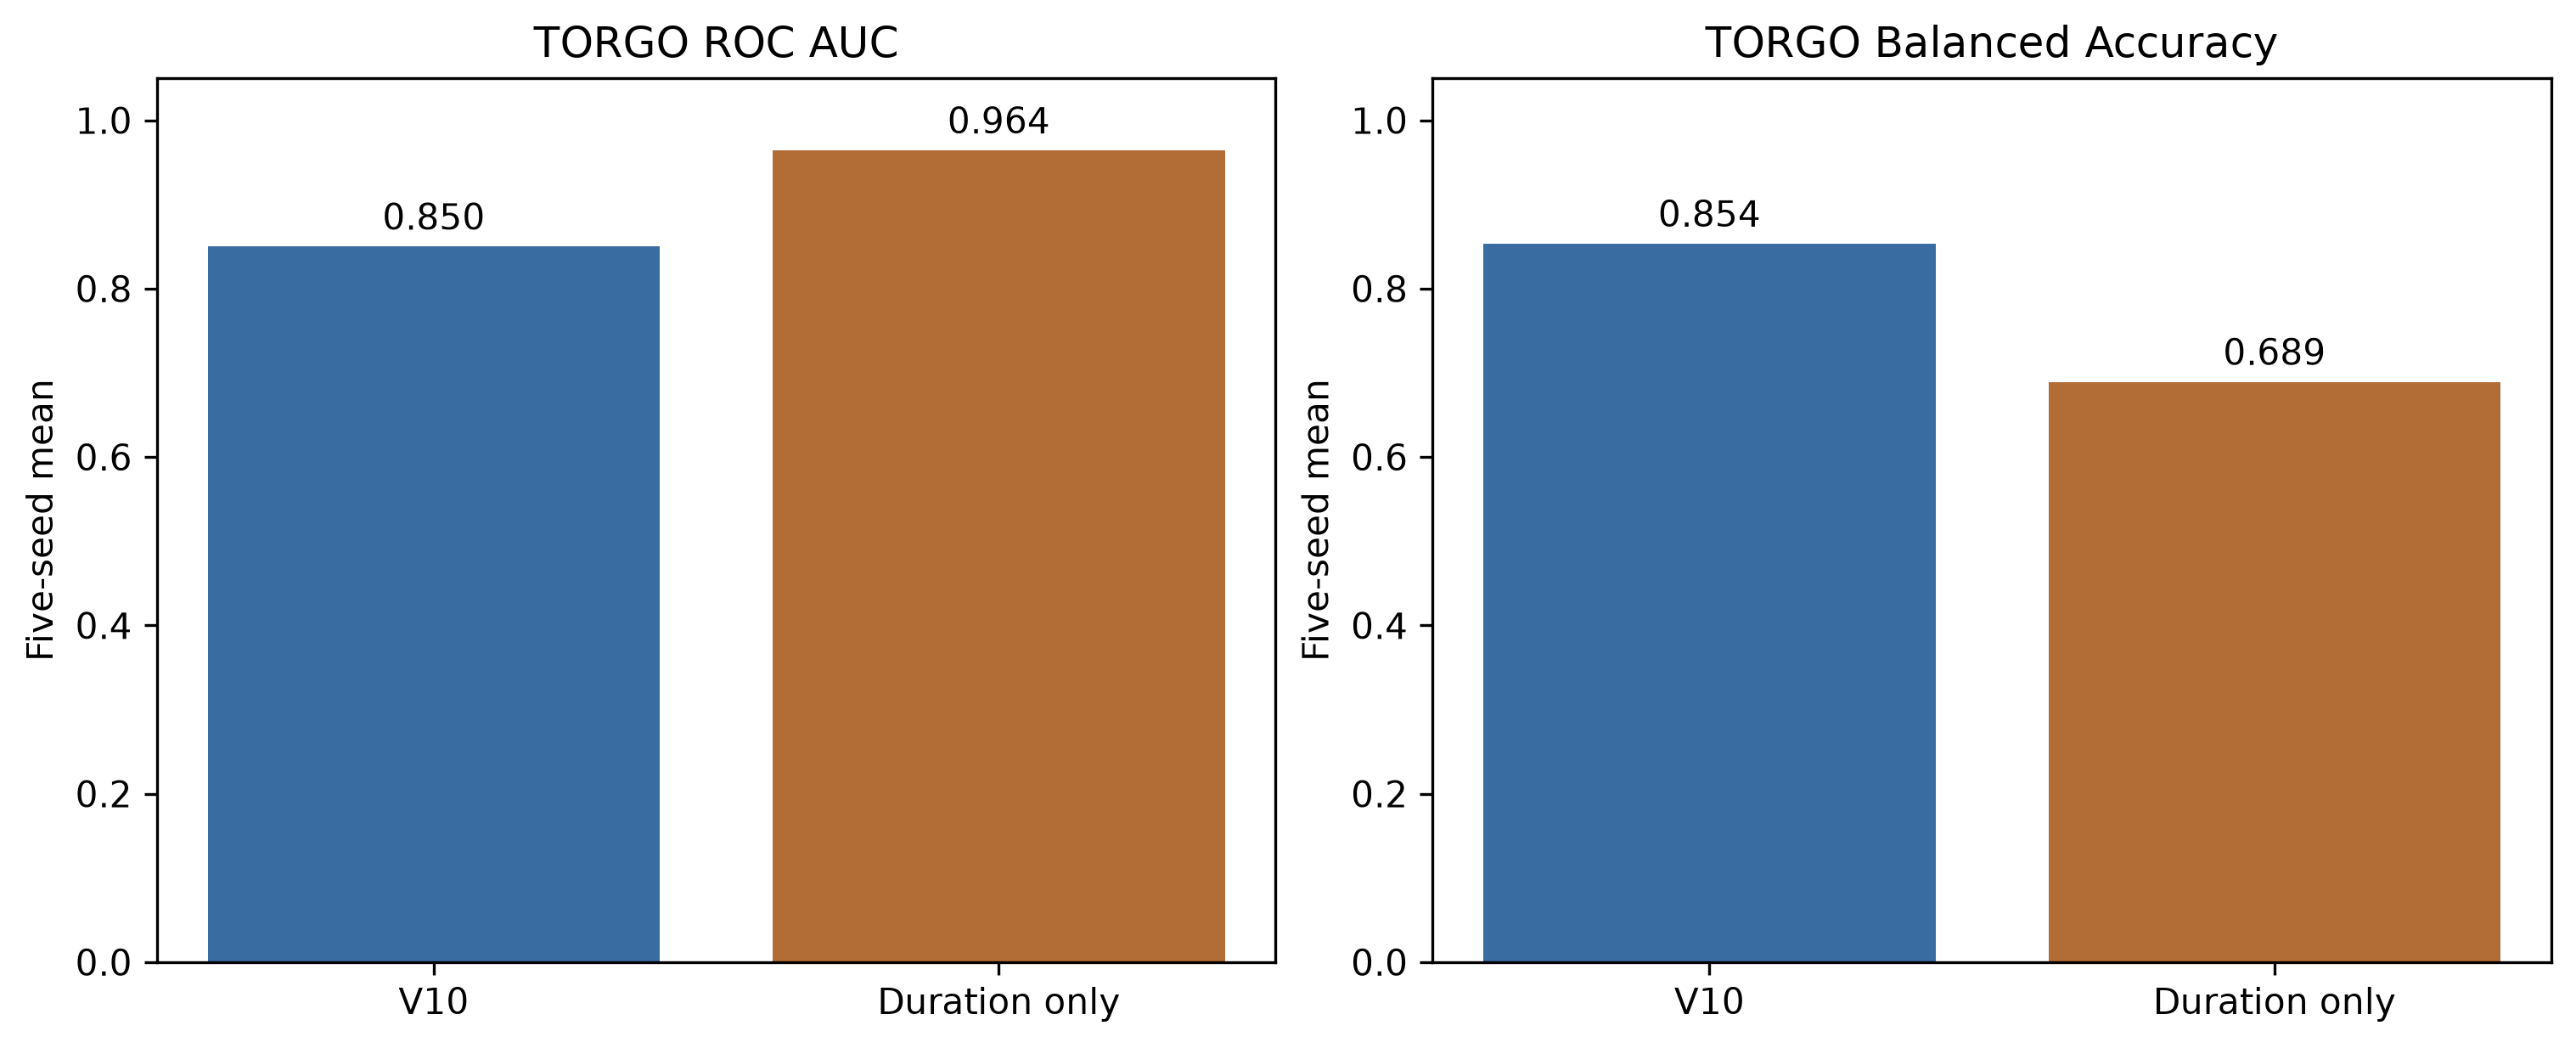

Figure source: paired_metrics and paired_ci displayed above; 15 speakers, five seeds.


In [26]:
duration=pd.read_csv(ROOT/'v8/v8_publication_completion/results/duration/predictions.csv')
duration=duration[duration.corpus.eq('TORGO')]
paired=torgo.merge(duration,on=['physical_speaker_id','seed','outer_fold','label'],
                   suffixes=('_v10','_duration'),validate='one_to_one')
assert len(paired)==75 and set(paired.seed)==set(SEEDS)
rows=[]
for seed,part in paired.groupby('seed'):
    rows.append({'seed':int(seed),'V10_ROC_AUC':roc_auc_score(part.label,part.probability_v10),
                 'duration_ROC_AUC':roc_auc_score(part.label,part.probability_duration),
                 'V10_Balanced_Accuracy':balanced_accuracy_score(part.label,part.predicted_label_v10),
                 'duration_Balanced_Accuracy':balanced_accuracy_score(part.label,part.predicted_label_duration)})
paired_metrics=pd.DataFrame(rows)
for metric in ['ROC_AUC','Balanced_Accuracy']:
    paired_metrics[f'{metric}_difference']=paired_metrics[f'V10_{metric}']-paired_metrics[f'duration_{metric}']
display(paired_metrics)
positive=sorted(paired.loc[paired.label.eq(1),'physical_speaker_id'].unique())
negative=sorted(paired.loc[paired.label.eq(0),'physical_speaker_id'].unique())
rng=np.random.default_rng(20261017)
P=rng.integers(len(positive),size=(10000,len(positive)))
N=rng.integers(len(negative),size=(10000,len(negative)))
auc_draws=[];ba_draws=[]
for seed,part in paired.groupby('seed'):
    g=part.set_index('physical_speaker_id')
    vp=g.loc[positive,'probability_v10'].to_numpy();vn=g.loc[negative,'probability_v10'].to_numpy()
    dp=g.loc[positive,'probability_duration'].to_numpy();dn=g.loc[negative,'probability_duration'].to_numpy()
    vm=(vp[:,None]>vn[None,:]).astype(float)+.5*(vp[:,None]==vn[None,:])
    dm=(dp[:,None]>dn[None,:]).astype(float)+.5*(dp[:,None]==dn[None,:])
    auc_draws.append((vm-dm)[P[:,:,None],N[:,None,:]].mean(axis=(1,2)))
    pos=(g.loc[positive,'predicted_label_v10'].to_numpy()==1).astype(float)-(g.loc[positive,'predicted_label_duration'].to_numpy()==1).astype(float)
    neg=(g.loc[negative,'predicted_label_v10'].to_numpy()==0).astype(float)-(g.loc[negative,'predicted_label_duration'].to_numpy()==0).astype(float)
    ba_draws.append(.5*(pos[P].mean(axis=1)+neg[N].mean(axis=1)))
paired_ci=pd.DataFrame([
    {'metric':'ROC_AUC','V10_minus_duration':paired_metrics.ROC_AUC_difference.mean(),
     'lower_95':np.percentile(np.mean(auc_draws,axis=0),2.5),'upper_95':np.percentile(np.mean(auc_draws,axis=0),97.5)},
    {'metric':'Balanced_Accuracy','V10_minus_duration':paired_metrics.Balanced_Accuracy_difference.mean(),
     'lower_95':np.percentile(np.mean(ba_draws,axis=0),2.5),'upper_95':np.percentile(np.mean(ba_draws,axis=0),97.5)}])
display(paired_ci)
fig,axes=plt.subplots(1,2,figsize=(10,4),layout='constrained')
for ax,metric in zip(axes,['ROC_AUC','Balanced_Accuracy']):
    means=[paired_metrics[f'V10_{metric}'].mean(),paired_metrics[f'duration_{metric}'].mean()]
    ax.bar(['V10','Duration only'],means,color=['#396ca0','#b26d37'])
    ax.set(title=f'TORGO {metric.replace("_"," ")}',ylabel='Five-seed mean',ylim=(0,1.05))
    for j,value in enumerate(means):ax.text(j,value+.02,f'{value:.3f}',ha='center')
paired_figure_source=pd.DataFrame([
    {'metric':metric,'model':model,'five_seed_mean':paired_metrics[f'{model}_{metric}'].mean()}
    for metric in ['ROC_AUC','Balanced_Accuracy'] for model in ['V10','duration']])
show_300dpi(fig,'fig16_paired_duration_v10_2',paired_figure_source)
print('Figure source: paired_metrics and paired_ci displayed above; 15 speakers, five seeds.')

### Exact V8 duration evidence and export

The published V8 duration-only LR consumes a **four-element speaker vector**. A scalar `duration_feature` column would not reproduce its 0.964 TORGO ROC-AUC. The notebook therefore exports all four exact input features and the saved outer-fold predictions used in the paired test. This is an inline replacement for the unavailable CMPB script, not a newly trained comparator.

In [27]:
duration_feature_csv=ROOT/'v8/v8_publication_completion/baselines/features/TORGO/duration_speaker_features.csv'
exact_duration_features=pd.read_csv(duration_feature_csv).sort_values('physical_speaker_id').reset_index(drop=True)
feature_columns=['duration_mean','duration_median','duration_sd','short_fraction']
assert len(exact_duration_features)==15 and exact_duration_features.physical_speaker_id.is_unique
assert all(column in exact_duration_features for column in feature_columns)
raw_meta=pd.read_csv(FROZEN/'features/usable_metadata.csv')
recomputed=[]
for speaker,group in raw_meta.groupby('physical_speaker_id'):
    seconds=group.source_seconds.to_numpy(dtype=float)
    recomputed.append({'physical_speaker_id':speaker,'n_utterances':len(seconds),
                       'duration_mean':seconds.mean(),'duration_median':np.median(seconds),
                       'duration_sd':seconds.std(ddof=0),'short_fraction':float((seconds<.5).mean())})
recomputed=pd.DataFrame(recomputed).set_index('physical_speaker_id')
stored=exact_duration_features.set_index('physical_speaker_id')
assert (stored.n_utterances==recomputed.n_utterances).all()
assert np.allclose(stored[feature_columns],recomputed[feature_columns],rtol=0,atol=1e-12)
assert np.isclose(paired_metrics.duration_ROC_AUC.mean(),.9642857142857143,atol=1e-12)
exact_duration_features.to_csv(V102_DIR/'duration_exact_four_speaker_features.csv',index=False)
paired_export=paired[['physical_speaker_id','seed','outer_fold','label','probability_v10',
                      'predicted_label_v10','probability_duration','predicted_label_duration']].sort_values(['seed','physical_speaker_id'])
paired_export.to_csv(V102_DIR/'duration_v10_paired_oof.csv',index=False)
paired_metrics.to_csv(V102_DIR/'duration_paired_per_seed_metrics.csv',index=False)
paired_ci.to_csv(V102_DIR/'duration_paired_speaker_bootstrap_ci.csv',index=False)
print('Exact V8 duration inputs: four speaker features, 15 speakers; 75 paired OOF rows.')
print('Published duration-only mean ROC-AUC reproduced:',round(paired_metrics.duration_ROC_AUC.mean(),6))
display(exact_duration_features)


Exact V8 duration inputs: four speaker features, 15 speakers; 75 paired OOF rows.
Published duration-only mean ROC-AUC reproduced: 0.964286


,physical_speaker_id,label,n_utterances,duration_mean,duration_median,duration_sd,short_fraction
0,F01,1,266,2.798828,1.800000,2.358816,0.000000
1,F03,1,1425,2.727645,1.925000,5.466809,0.003509
2,F04,1,698,3.399746,2.850000,1.992252,0.000000
3,FC01,0,419,3.768513,3.300000,1.506156,0.000000
4,FC02,0,2261,2.965099,2.400000,1.350733,0.002211
5,FC03,0,1996,2.723447,2.225000,1.489489,0.001503
6,M01,1,772,4.043702,2.855000,6.891919,0.000000
7,M02,1,809,3.777831,2.700000,2.854456,0.006180
8,M03,1,837,3.528237,2.850000,3.708168,0.001195
9,M04,1,718,4.494576,2.739969,4.082466,0.001393


### Paired comparison interpretation

The duration-only comparator has a higher numerical TORGO ROC-AUC (0.964 versus 0.850); V10 has higher balanced accuracy at their respective TORGO-selected thresholds (0.854 versus 0.689). The paired speaker-bootstrap 95% intervals for V10 minus duration-only are **−0.304 to 0.054** for ROC-AUC and **−0.018 to 0.336** for balanced accuracy. Both include zero. This does not establish incremental disease-specific information. The locked V10 probabilities and performance have not changed.

## Duration-overlap subset with frozen models

This secondary diagnostic keeps raw-duration recordings inside the intersection of diagnosis-specific 10th–90th percentile intervals. It preserves all 15 TORGO speakers but **does not match the complete duration distributions**. V10 and the published four-feature duration LR use their frozen outer-fold models and thresholds; neither is refit. Applying the duration LR to truncated speaker feature summaries shifts its test distribution, so interpret its subset score as an intervention diagnostic, not a newly optimized baseline.

Raw-duration overlap: 1.465 to 4.645 seconds; 13418 recordings, 15 speakers
Untrained speaker mean-duration AUC in subset: 0.464


ROC_AUC           Balanced_Accuracy          
                        mean       std              mean       std
model                                                             
Duration LR frozen  0.289286  0.072974          0.457143  0.058685
V10 frozen          0.846429  0.129141          0.842857  0.057031

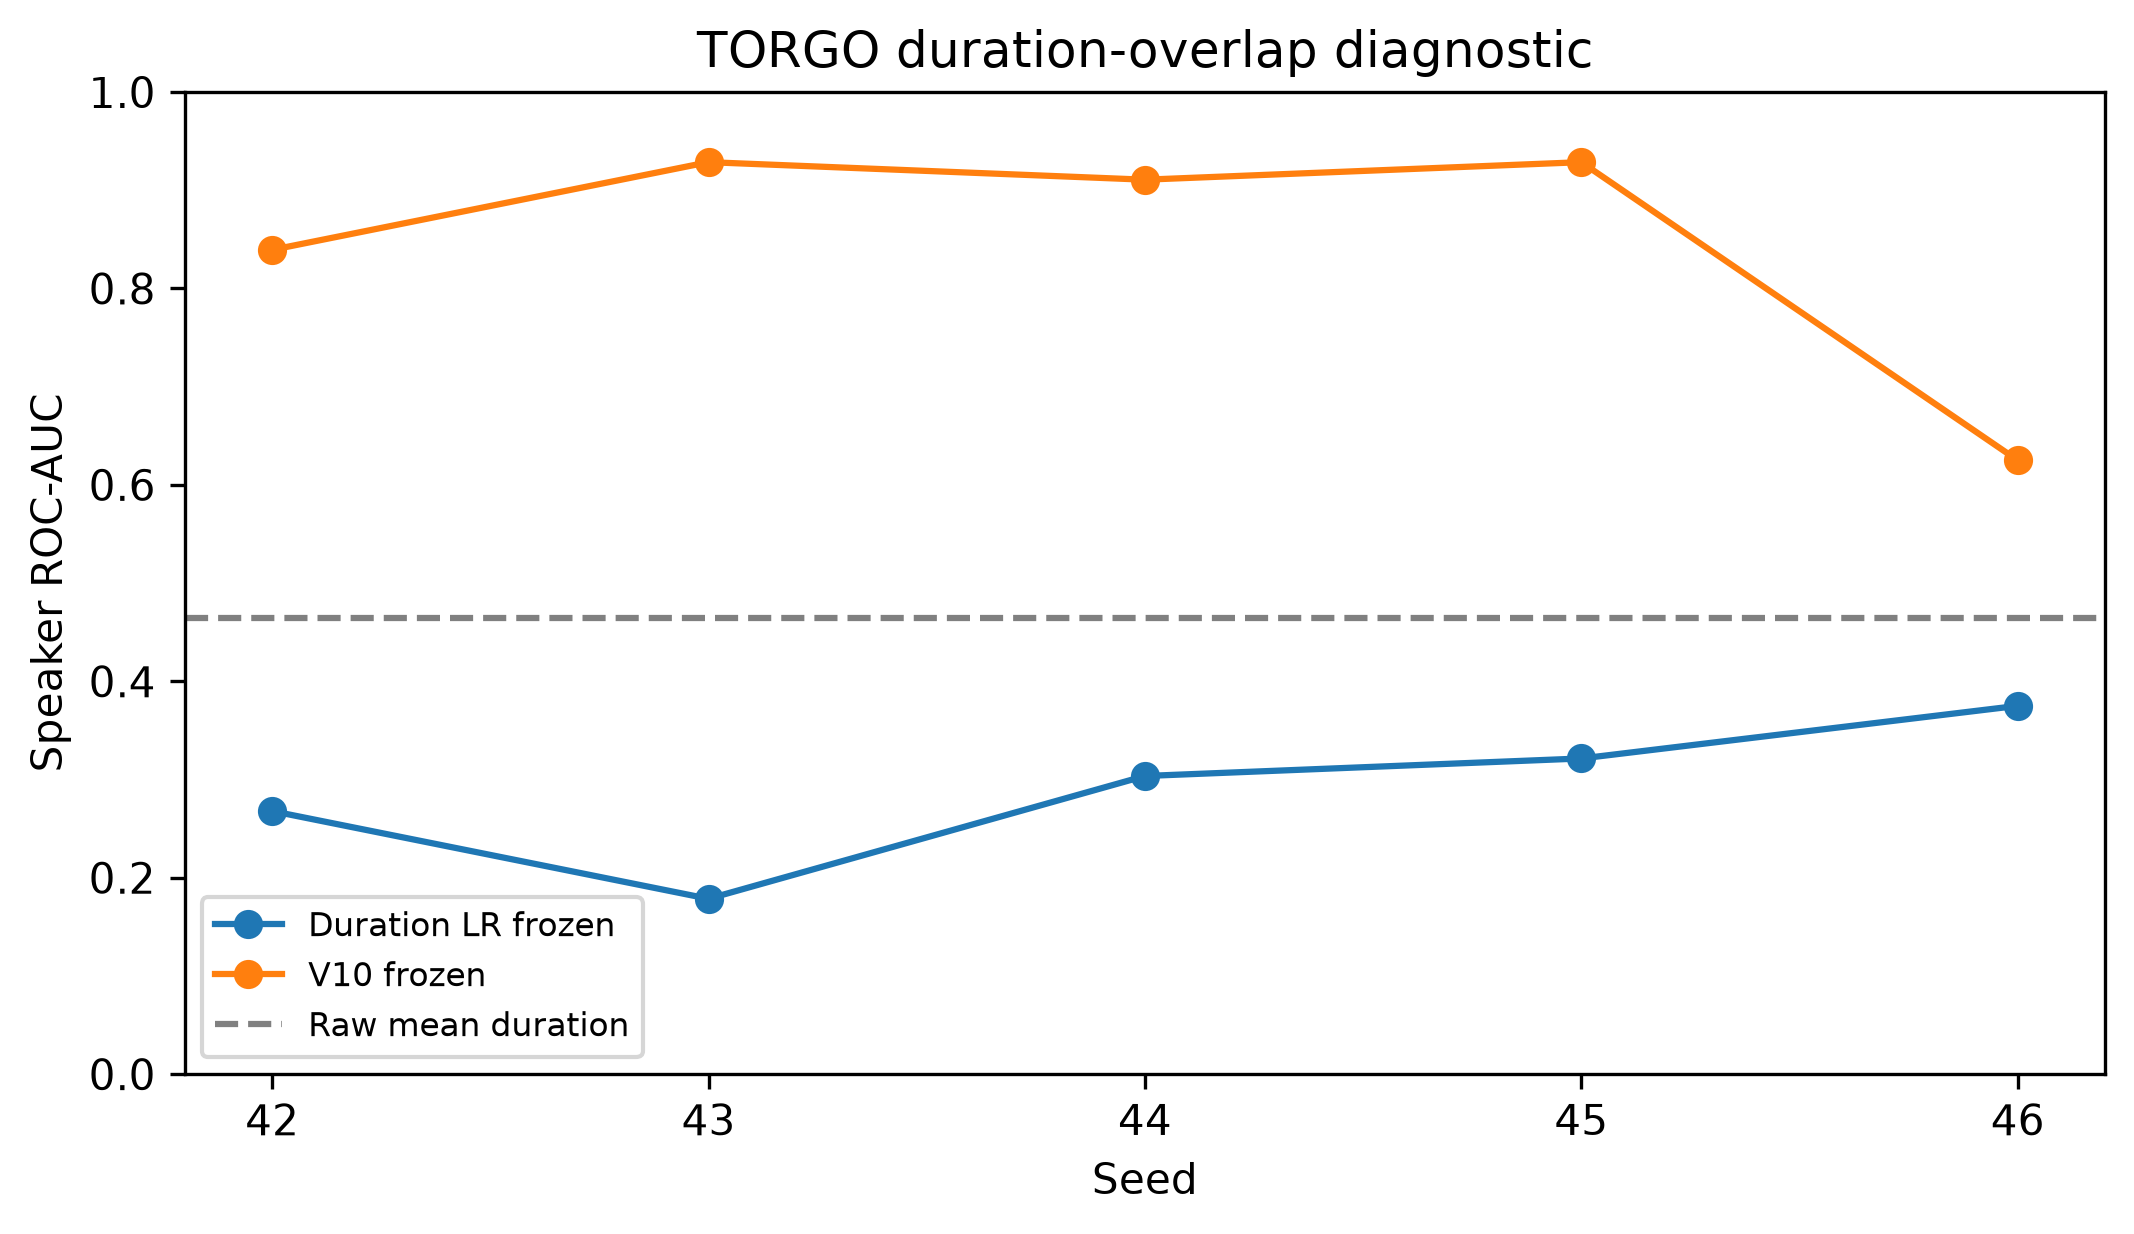

Figure source: subset_metrics and duration_features are available in this notebook.


In [28]:
import joblib
meta=pd.read_csv(FROZEN/'features/usable_metadata.csv')
q=meta.groupby('label').source_seconds.quantile([.1,.9]).unstack()
low,high=float(q[.1].max()),float(q[.9].min())
subset=meta[meta.source_seconds.between(low,high)].copy()
subset_count=json.loads((V10_OUT/'subsets/matched_duration_counts.json').read_text())
assert np.allclose([low,high],subset_count['duration_range_seconds'])
assert len(subset)==subset_count['n_recordings'] and subset.physical_speaker_id.nunique()==15
feature_rows=[]
for speaker,group in subset.groupby('physical_speaker_id'):
    seconds=group.source_seconds.to_numpy(dtype=float)
    feature_rows.append({'physical_speaker_id':speaker,'label':int(group.label.iloc[0]),
                         'duration_mean':seconds.mean(),'duration_median':np.median(seconds),
                         'duration_sd':seconds.std(ddof=0),'short_fraction':float((seconds<.5).mean())})
duration_features=pd.DataFrame(feature_rows).set_index('physical_speaker_id')
feature_names=['duration_mean','duration_median','duration_sd','short_fraction']
subset_rows=[]
for (seed,fold),part in duration.groupby(['seed','outer_fold']):
    checkpoint=ROOT/f'v8/v8_publication_completion/baselines/duration/seed{int(seed)}_outer{int(fold)}/model.joblib'
    frozen_model=joblib.load(checkpoint)
    speakers=part.physical_speaker_id.tolist()
    scores=frozen_model.predict_proba(duration_features.loc[speakers,feature_names].to_numpy())[:,1]
    threshold=float(part.threshold.iloc[0])
    for speaker,score in zip(speakers,scores):
        subset_rows.append({'seed':int(seed),'outer_fold':int(fold),'physical_speaker_id':speaker,
                            'label':int(duration_features.loc[speaker,'label']),
                            'probability':float(score),'predicted_label':int(score>=threshold)})
duration_subset=pd.DataFrame(subset_rows)
v10_subset=pd.read_csv(V10_OUT/'subsets/matched_duration_speaker_predictions.csv')
assert len(duration_subset)==len(v10_subset)==75
assert set(zip(duration_subset.seed,duration_subset.physical_speaker_id))==set(zip(v10_subset.seed,v10_subset.physical_speaker_id))
subset_metrics=[]
for name,frame in [('V10 frozen',v10_subset),('Duration LR frozen',duration_subset)]:
    for seed,group in frame.groupby('seed'):
        subset_metrics.append({'model':name,'seed':int(seed),'ROC_AUC':roc_auc_score(group.label,group.probability),
                               'Balanced_Accuracy':balanced_accuracy_score(group.label,group.predicted_label)})
subset_metrics=pd.DataFrame(subset_metrics)
raw_duration_auc=roc_auc_score(duration_features.label,duration_features.duration_mean)
print('Raw-duration overlap:',round(low,3),'to',round(high,3),'seconds;',len(subset),'recordings, 15 speakers')
print('Untrained speaker mean-duration AUC in subset:',round(raw_duration_auc,3))
display(subset_metrics.groupby('model')[['ROC_AUC','Balanced_Accuracy']].agg(['mean','std']))
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
for name,group in subset_metrics.groupby('model'):
    ax.plot(group.seed,group.ROC_AUC,marker='o',label=name)
ax.axhline(raw_duration_auc,ls='--',color='gray',label='Raw mean duration')
ax.set(xlabel='Seed',ylabel='Speaker ROC-AUC',ylim=(0,1),title='TORGO duration-overlap diagnostic')
ax.set_xticks([42,43,44,45,46])
ax.legend(fontsize=8)
duration_overlap_figure_source=pd.concat([
    subset_metrics[['model','seed','ROC_AUC']],
    pd.DataFrame({'model':['Raw mean duration']*5,'seed':SEEDS,'ROC_AUC':[raw_duration_auc]*5})],ignore_index=True)
show_300dpi(fig,'fig17_duration_overlap_v10_2',duration_overlap_figure_source)
print('Figure source: subset_metrics and duration_features are available in this notebook.')

## Official M3 high-intelligibility analysis with all controls

The saved official intelligibility metadata identify five high-intelligibility dysarthric speakers. This diagnostic compares them with **all 13 M3 controls**, explicitly including CF05 and CM01. The exact control cohort is part of the result; a different control subset yields a different AUC. UASpeech is still evaluation only.

,physical_speaker_id,seed,label,probability,threshold,predicted_label,n_utterances
3,CF05,42,0,0.000611,0.444499,0,765
31,CF05,43,0,0.074249,0.428864,0,765
59,CF05,44,0,0.001133,0.491551,0,765
87,CF05,45,0,0.027360,0.467983,0,765
115,CF05,46,0,0.032256,0.438327,0,765
4,CM01,42,0,0.000826,0.444499,0,765
32,CM01,43,0,0.089116,0.428864,0,765
60,CM01,44,0,0.001481,0.491551,0,765
88,CM01,45,0,0.031968,0.467983,0,765
116,CM01,46,0,0.032546,0.438327,0,765


,seed,n_high_dysarthric,n_controls,ROC_AUC,Balanced_Accuracy
0,42,5,13,0.846154,0.7
1,43,5,13,0.892308,0.8
2,44,5,13,0.892308,0.8
3,45,5,13,0.953846,0.7
4,46,5,13,0.907692,0.8


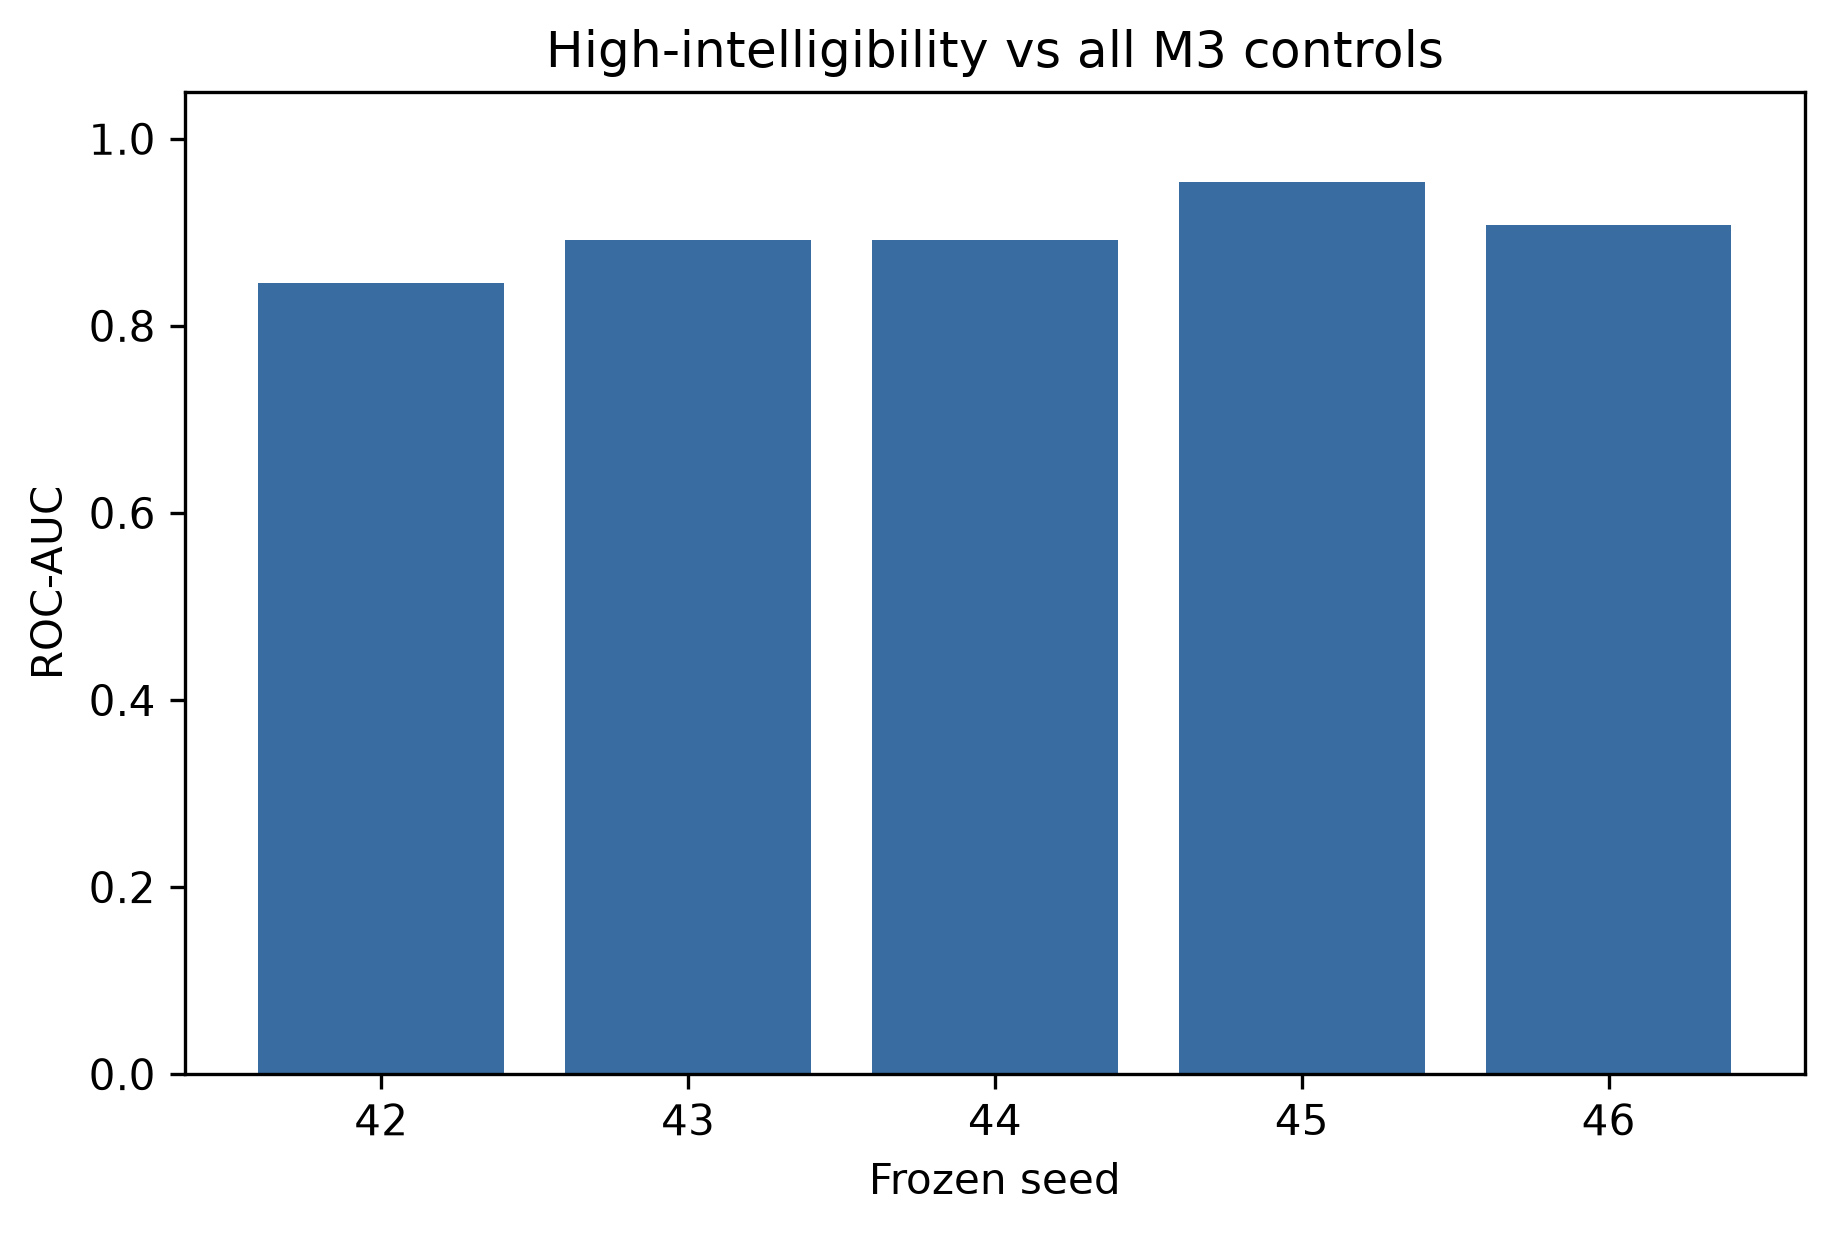

Mean high-group ROC-AUC: 0.898 (all 13 controls).


In [29]:
severity=pd.read_csv(V10_OUT/'diagnostics/uaspeech_m3_intelligibility_speakers.csv')
high_speakers=set(severity.loc[severity.official_intelligibility_group.eq('High'),'speaker_id'])
assert len(high_speakers)==5 and m3[m3.label.eq(0)].physical_speaker_id.nunique()==13
control_precision=m3[m3.physical_speaker_id.isin(['CF05','CM01'])][['physical_speaker_id','seed','label','probability','threshold','predicted_label','n_utterances']].sort_values(['physical_speaker_id','seed'])
assert len(control_precision)==10
display(control_precision)
high_frame=m3[m3.label.eq(0)|m3.physical_speaker_id.isin(high_speakers)]
high_auc=pd.DataFrame([{'seed':int(seed),'n_high_dysarthric':5,'n_controls':13,
                        'ROC_AUC':roc_auc_score(part.label,part.probability),
                        'Balanced_Accuracy':balanced_accuracy_score(part.label,part.predicted_label)}
                       for seed,part in high_frame.groupby('seed')])
display(high_auc)
fig,ax=plt.subplots(figsize=(6,4),layout='constrained')
ax.bar(high_auc.seed.astype(str),high_auc.ROC_AUC,color='#396ca0')
ax.set(xlabel='Frozen seed',ylabel='ROC-AUC',ylim=(0,1.05),title='High-intelligibility vs all M3 controls')
show_300dpi(fig,'fig18_high_intelligibility_v10_2',high_auc)
print('Mean high-group ROC-AUC:',round(high_auc.ROC_AUC.mean(),3),'(all 13 controls).')

### Independent M3 high-intelligibility reconciliation

This checks ROC-AUC by direct dysarthric-control probability pairs, then compares the complete 13-control cohort with the 11-control subset that omits CF05 and CM01. The five-seed mean and per-seed range are reported separately. The supplied checklist's upper bound rounds to the complete-cohort mean; its lower-bound calculation requires the unavailable CMPB script. The complete official M3 cohort is the prespecified V10.2 result.

In [30]:
reconciliation=[]
for cohort,excluded in [('all 13 controls',set()),('11 controls excluding CF05/CM01',{'CF05','CM01'})]:
    frame=m3[(m3.label.eq(0)|m3.physical_speaker_id.isin(high_speakers)) &
             ~m3.physical_speaker_id.isin(excluded)]
    for seed,part in frame.groupby('seed'):
        positive=part.loc[part.label.eq(1),'probability'].to_numpy()
        negative=part.loc[part.label.eq(0),'probability'].to_numpy()
        assert len(positive)==5
        pairwise=((positive[:,None]>negative[None,:]).astype(float)
                  +.5*(positive[:,None]==negative[None,:])).mean()
        sklearn_auc=roc_auc_score(part.label,part.probability)
        assert np.isclose(pairwise,sklearn_auc,atol=1e-15)
        reconciliation.append({'control_cohort':cohort,'seed':int(seed),
                               'n_high_dysarthric':len(positive),'n_controls':len(negative),
                               'concordant_pair_auc':pairwise,'sklearn_roc_auc':sklearn_auc})
severity_reconciliation=pd.DataFrame(reconciliation)
assert np.allclose(severity_reconciliation.query('control_cohort == "all 13 controls"').sklearn_roc_auc,
                   high_auc.ROC_AUC)
severity_reconciliation.to_csv(V102_DIR/'m3_high_intelligibility_auc_reconciliation.csv',index=False)
control_precision.to_csv(V102_DIR/'m3_cf05_cm01_full_precision.csv',index=False)
display(severity_reconciliation)
print('Full-cohort AUC range:',round(high_auc.ROC_AUC.min(),6),'to',round(high_auc.ROC_AUC.max(),6))
full_cohort_mean=float(high_auc.ROC_AUC.mean())
assert round(full_cohort_mean,3)==.898
print('Full-cohort five-seed mean:',round(full_cohort_mean,6),'(rounds to checklist upper bound 0.898).')
print('Checklist lower-bound method remains unverified until its source script is available.')


,control_cohort,seed,n_high_dysarthric,n_controls,concordant_pair_auc,sklearn_roc_auc
0,all 13 controls,42,5,13,0.846154,0.846154
1,all 13 controls,43,5,13,0.892308,0.892308
2,all 13 controls,44,5,13,0.892308,0.892308
3,all 13 controls,45,5,13,0.953846,0.953846
4,all 13 controls,46,5,13,0.907692,0.907692
5,11 controls excluding CF05/CM01,42,5,11,0.836364,0.836364
6,11 controls excluding CF05/CM01,43,5,11,0.872727,0.872727
7,11 controls excluding CF05/CM01,44,5,11,0.872727,0.872727
8,11 controls excluding CF05/CM01,45,5,11,0.945455,0.945455
9,11 controls excluding CF05/CM01,46,5,11,0.890909,0.890909


Full-cohort AUC range: 0.846154 to 0.953846
Full-cohort five-seed mean: 0.898462 (rounds to checklist upper bound 0.898).
Checklist lower-bound method remains unverified until its source script is available.


### Severity calculation scope

The complete official M3 comparison contains five high-intelligibility dysarthric speakers and all 13 controls. Its **per-seed ROC-AUC range is 0.846–0.954** and its **five-seed mean is 0.89846**. The supplied revision checklist's 0.852–0.898 appears to describe bounds on a *mean*, not the per-seed range; the observed mean rounds to its 0.898 upper endpoint. The source CMPB script is still needed to verify how its 0.852 lower bound was derived. The cohort, statistic, and uncertainty procedure must be named together in any paper.

## Speaker-leakage demonstration (single-seed diagnostic)

The same 26 MFCC summary features and balanced logistic regression are evaluated using random utterance folds and physical-speaker-grouped folds. Both reported metrics are **utterance-level** at a fixed 0.5 threshold, so this illustrates speaker overlap rather than replacing the speaker-level V10 benchmark. This diagnostic uses TORGO only and never selects the primary model.

,split,n_utterances,n_speakers,ROC_AUC,Balanced_Accuracy,train_test_speaker_overlap_by_fold
0,Random utterance folds,17630,15,0.837009,0.761876,"[15, 15, 15, 15, 15]"
1,Physical-speaker folds,17630,15,0.577027,0.567255,"[0, 0, 0, 0, 0]"


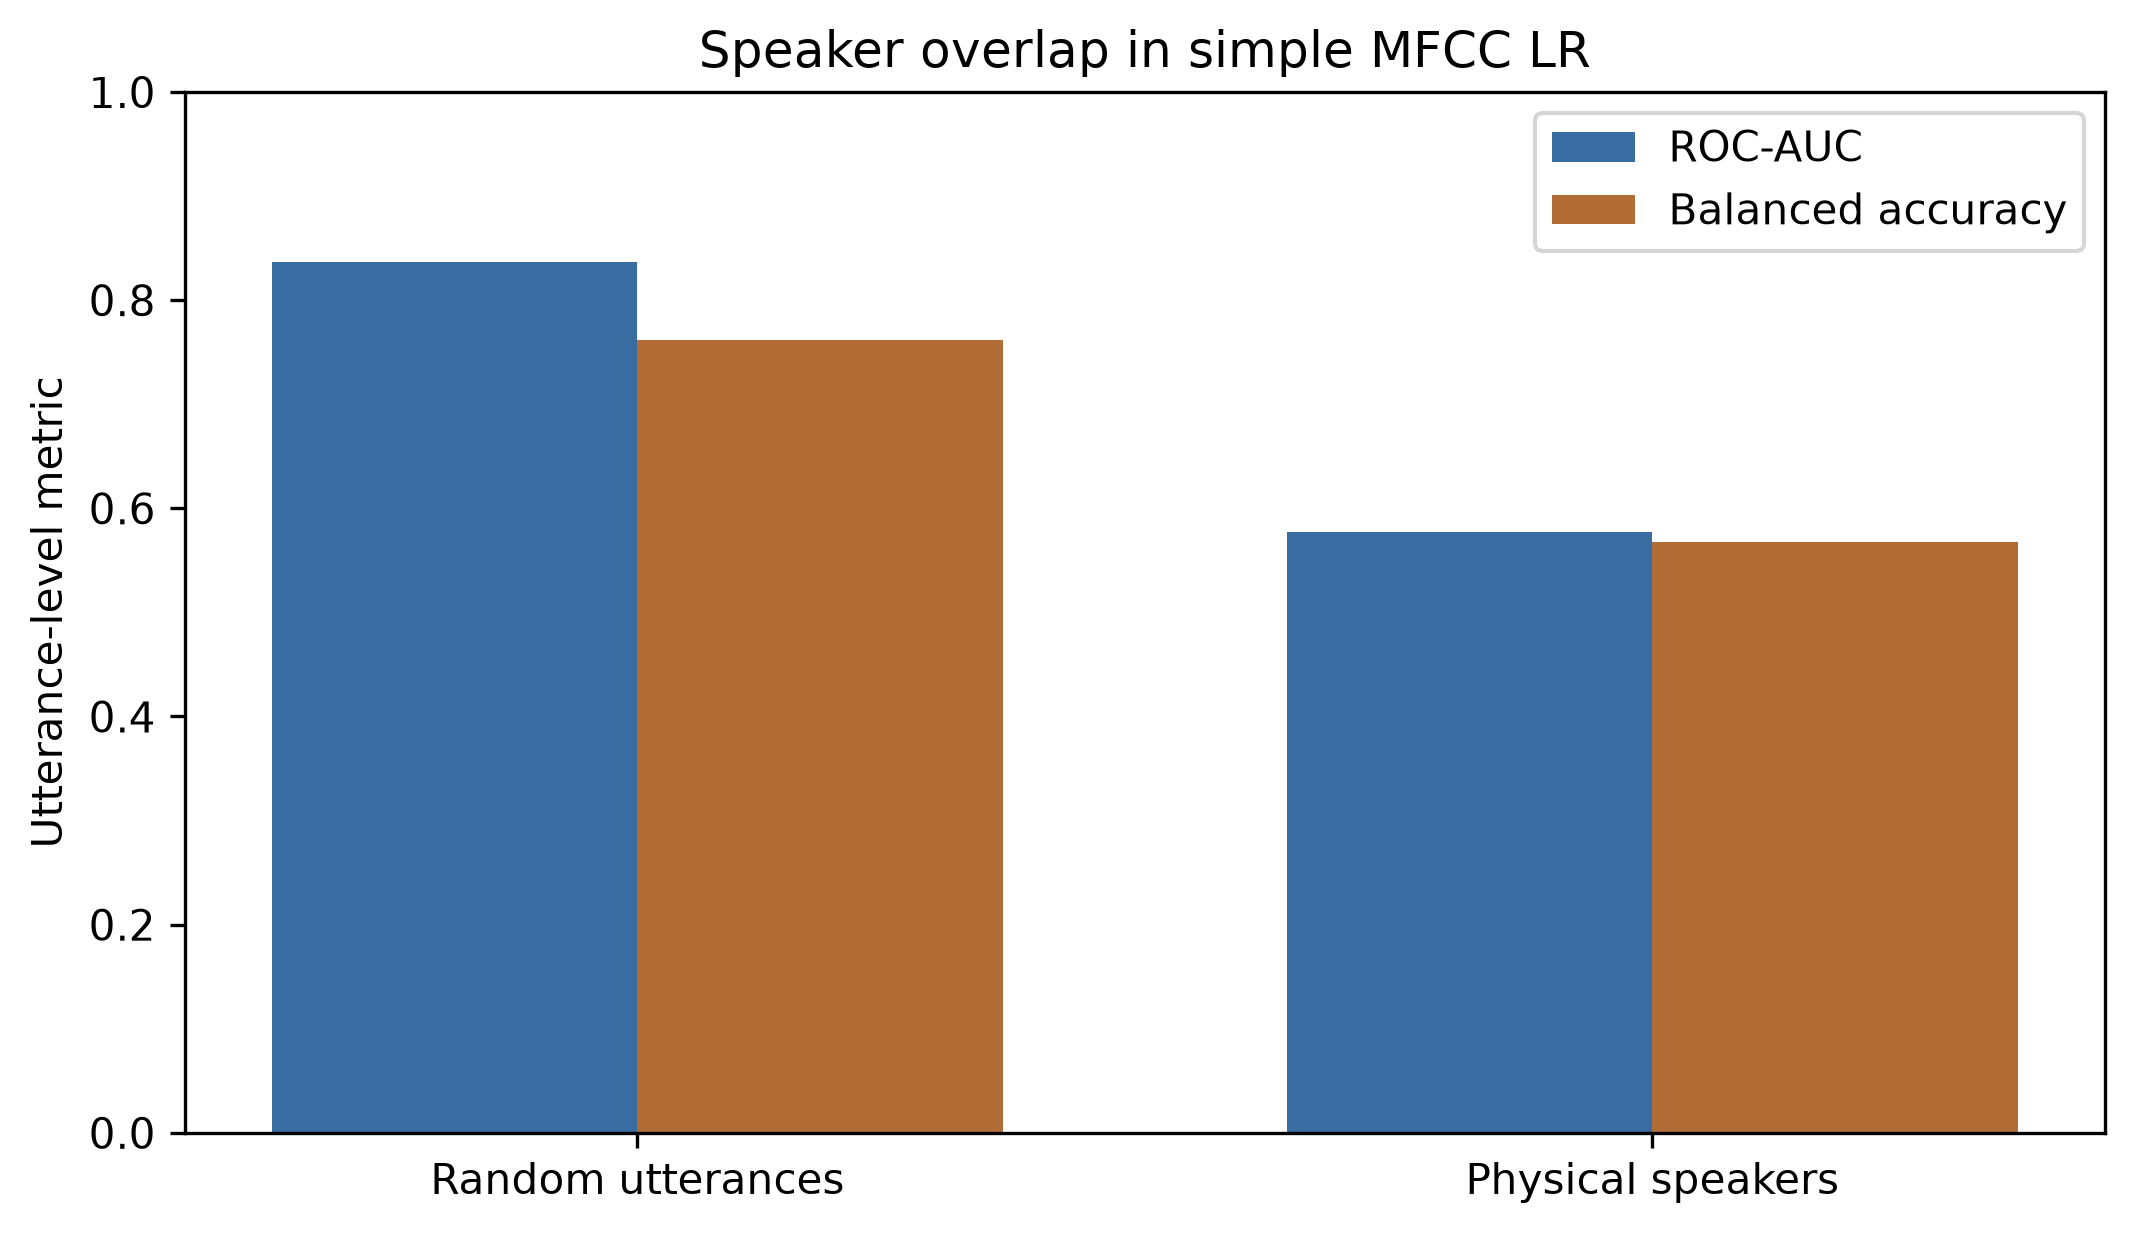

Figure source: leakage_demo displayed above.


In [31]:
from sklearn.model_selection import StratifiedKFold,StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
X=np.load(FROZEN/'features/acoustic_features.npy',mmap_mode='r')[:,:26]
y=meta.label.to_numpy(dtype=int)
speakers=meta.physical_speaker_id.to_numpy()
leakage_rows=[]
for name,cv in [('Random utterance folds',StratifiedKFold(5,shuffle=True,random_state=42)),
                ('Physical-speaker folds',StratifiedGroupKFold(5,shuffle=True,random_state=42))]:
    scores=np.full(len(y),np.nan)
    overlap=[]
    for train,test in cv.split(X,y,speakers if name=='Physical-speaker folds' else None):
        overlap.append(len(set(speakers[train])&set(speakers[test])))
        model=make_pipeline(StandardScaler(),LogisticRegression(C=1,class_weight='balanced',max_iter=2000,random_state=42))
        model.fit(X[train],y[train])
        scores[test]=model.predict_proba(X[test])[:,1]
    assert np.isfinite(scores).all()
    leakage_rows.append({'split':name,'n_utterances':len(y),'n_speakers':len(set(speakers)),
                         'ROC_AUC':roc_auc_score(y,scores),'Balanced_Accuracy':balanced_accuracy_score(y,scores>=.5),
                         'train_test_speaker_overlap_by_fold':overlap})
leakage_demo=pd.DataFrame(leakage_rows)
assert leakage_demo.iloc[0].train_test_speaker_overlap_by_fold==[15]*5
assert leakage_demo.iloc[1].train_test_speaker_overlap_by_fold==[0]*5
display(leakage_demo)
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
positions=np.arange(2)
ax.bar(positions-.18,leakage_demo.ROC_AUC,width=.36,label='ROC-AUC',color='#396ca0')
ax.bar(positions+.18,leakage_demo.Balanced_Accuracy,width=.36,label='Balanced accuracy',color='#b26d37')
ax.set_xticks(positions,['Random utterances','Physical speakers'])
ax.set(ylim=(0,1),ylabel='Utterance-level metric',title='Speaker overlap in simple MFCC LR')
ax.legend()
show_300dpi(fig,'fig19_speaker_leakage_v10_2',leakage_demo)
print('Figure source: leakage_demo displayed above.')

## Reporting definitions, channel coverage and unique layer probes

The V8 B3 artifact-only LR has eight descriptors: four raw-duration statistics plus speaker mean RMS, RMS SD, mean peak amplitude, and mean silence ratio. V10's separate duration, silence, RMS and spectral-proxy confound arms are a different feature set.

The V8 objective-background control extracts the longest contiguous quiet leading or trailing edge using 20 ms frames, −35 dB relative to peak, a 0.1–1.0 s length range and up to 50 eligible recordings per speaker in hash order. It does not use labels for selection.

MFCC baselines use 13 coefficient means and 13 SDs. LR uses `C=1`, balanced classes and `max_iter=2000`. RBF SVM uses `C=1`, `gamma="scale"` and balanced classes. The narrowly filtered SVM deprecation warning changes no predictions.

M2, M4 and M8 have fewer speakers because their official normalized channel inventories lack specific speaker recordings; M3 remains primary. The last-four layer-4 probe and final-layer LR use the identical cached final layer, so the corrected plot displays this representation once.

,control,features
0,V8 B3 artifact-only LR,"duration_mean, duration_median, duration_sd, s..."
1,V10 measured confounds,"Separate duration, silence ratio, RMS energy a..."
2,V8 objective background,20 ms frames; -35 dB; 0.1–1.0 s; up to 50 clip...


,channel,n_speakers,missing_from_M3_roster,reason
0,M2,23,"M01, M04, M11, M12, M16",No official normalized channel recordings
1,M3,28,none,Full M3 roster
2,M4,26,"M01, M04",No official normalized channel recordings
3,M5,28,none,Full M3 roster
4,M6,28,none,Full M3 roster
5,M7,28,none,Full M3 roster
6,M8,27,M01,No official normalized channel recordings


,model_arm,ROC_AUC,Balanced_Accuracy
0,WavLM Last-4 Layer 1 Probe,0.896429,0.737500
1,WavLM Last-4 Layer 2 Probe,0.903571,0.710714
2,WavLM Last-4 Layer 3 Probe,0.914286,0.694643
3,WavLM Final Layer Logistic Regression,0.907143,0.712500


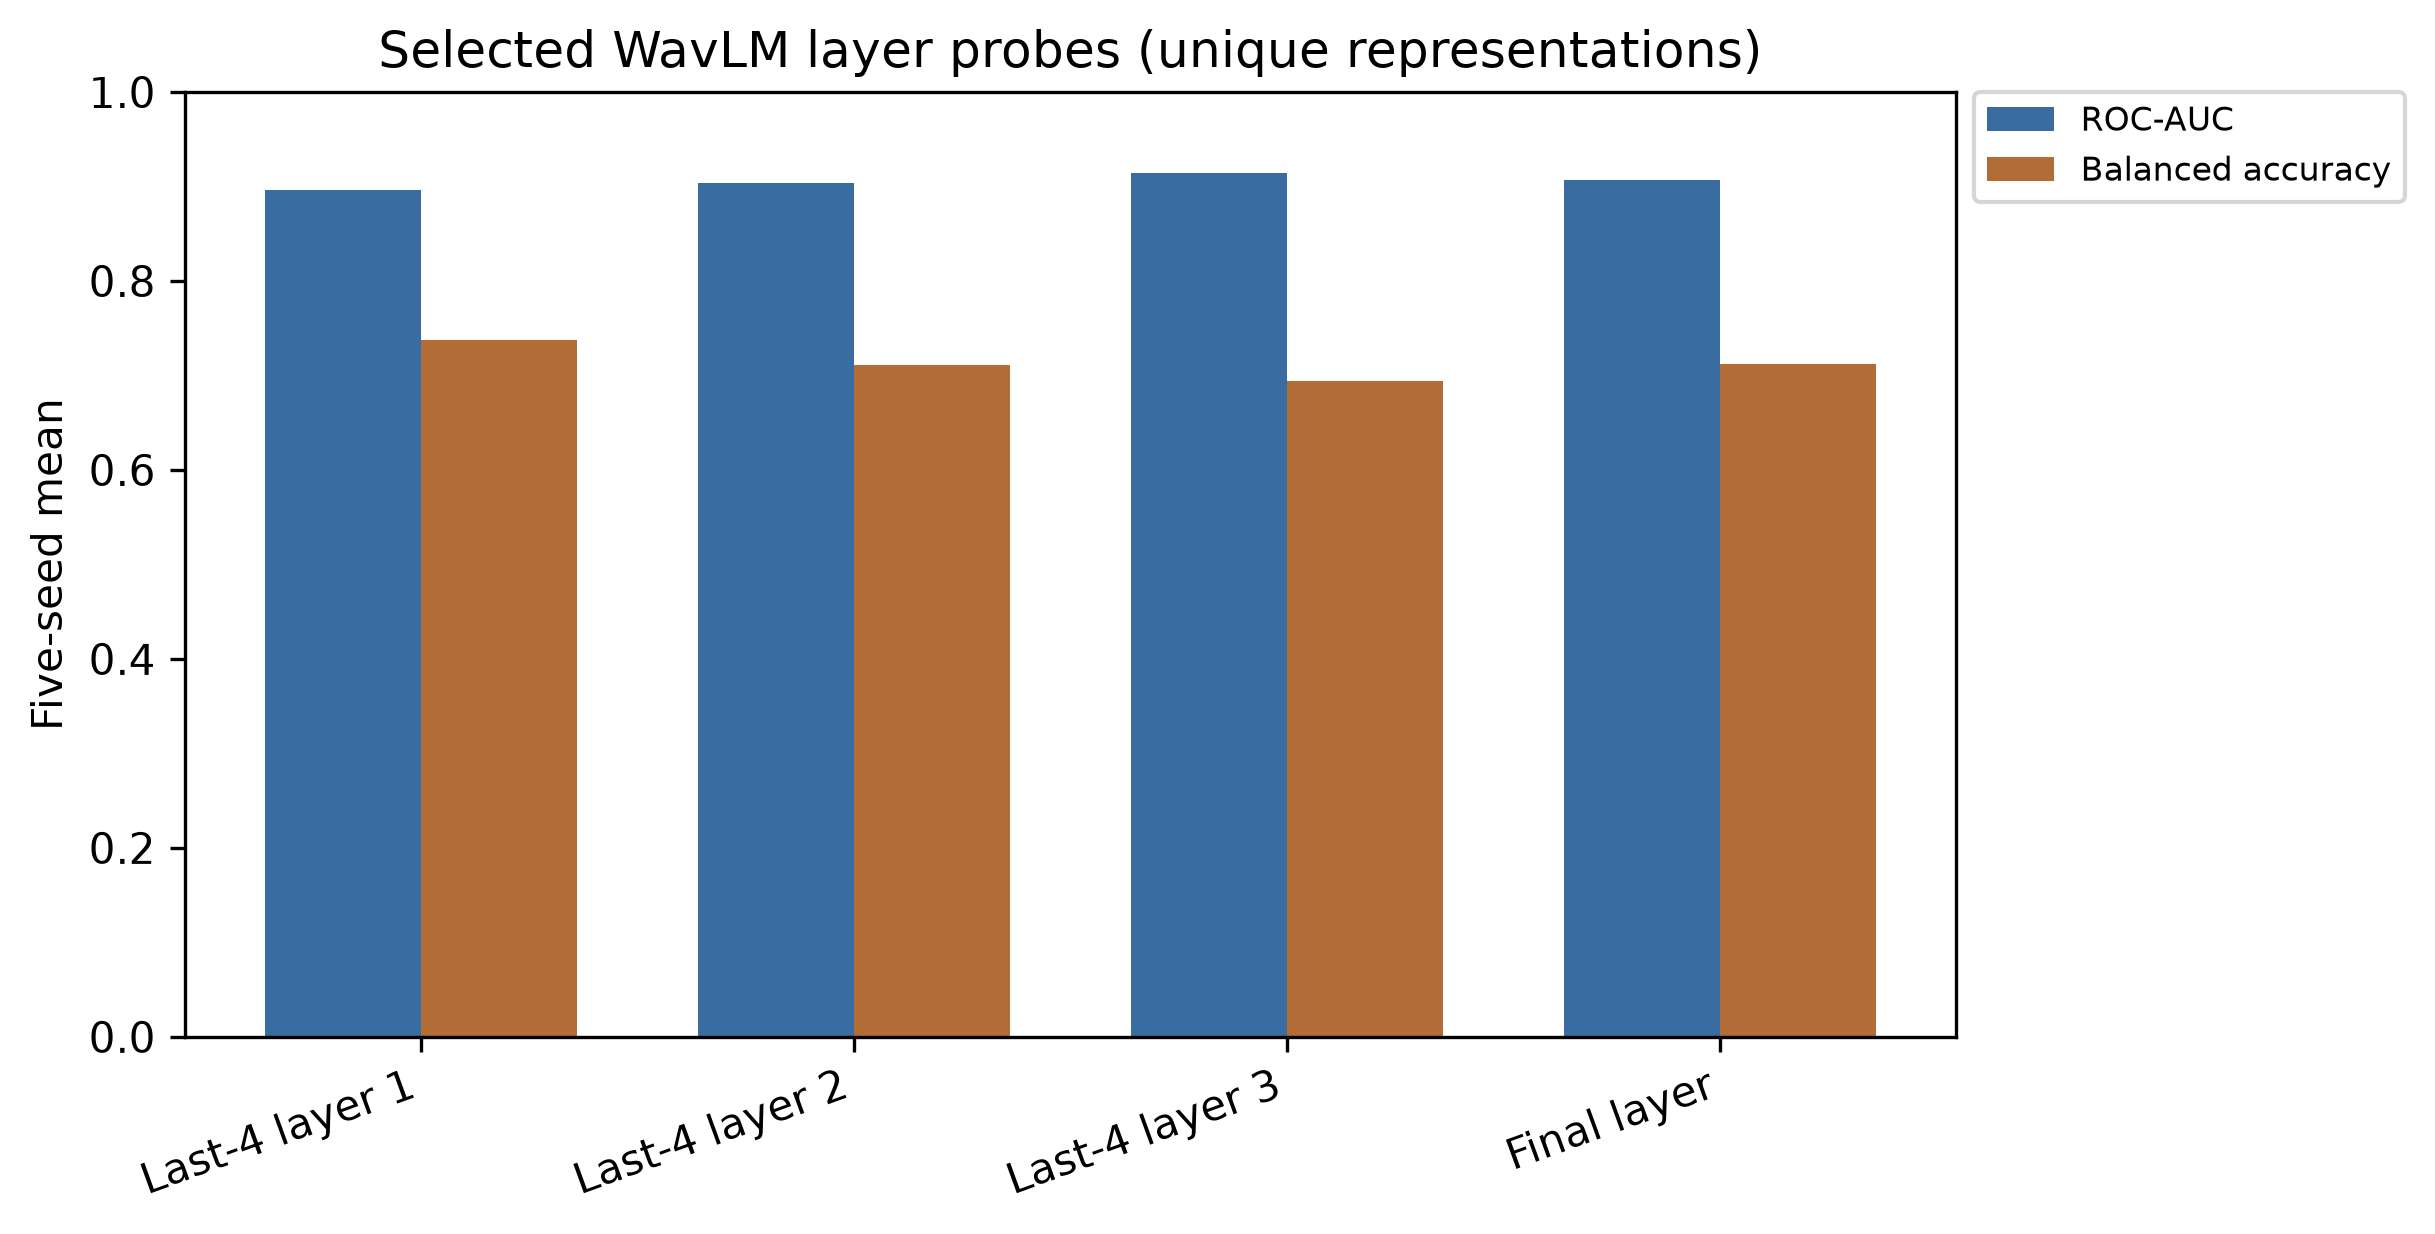

Layer-4 probe and final-layer LR are numerically identical and displayed once.


In [32]:
artifact_policy=json.loads((ROOT/'v8/v8_publication_completion/baselines/artifact/protocol.json').read_text())
silence_policy=json.loads((ROOT/'v8/v8_publication_completion/diagnostics/silence/protocol.json').read_text())
assert len(artifact_policy['feature_names'])==8
assert silence_policy['minimum_seconds']==.1 and silence_policy['eligible_clips_per_speaker']==50
method_table=pd.DataFrame([
    {'control':'V8 B3 artifact-only LR','features':', '.join(artifact_policy['feature_names'])},
    {'control':'V10 measured confounds','features':'Separate duration, silence ratio, RMS energy and spectral proxy arms; combined measured confounds'},
    {'control':'V8 objective background','features':f"{silence_policy['frame_seconds']*1000:.0f} ms frames; {silence_policy['relative_peak_db']:.0f} dB; {silence_policy['minimum_seconds']:.1f}–{silence_policy['maximum_seconds']:.1f} s; up to {silence_policy['eligible_clips_per_speaker']} clips/speaker"}])
display(method_table)
roster=set(m3.physical_speaker_id)
coverage=[]
for channel in ['M2','M3','M4','M5','M6','M7','M8']:
    prediction=pd.read_csv(V10_OUT/f'external/{channel}_speaker_predictions.csv')
    missing=sorted(roster-set(prediction.physical_speaker_id))
    if channel!='M3':
        inventory=pd.read_csv(ROOT/f'v8/v8_publication_completion/external_cache/{channel}/raw_inventory.csv')
        assert all(s not in set(inventory.physical_speaker_id) for s in missing)
    coverage.append({'channel':channel,'n_speakers':prediction.physical_speaker_id.nunique(),
                     'missing_from_M3_roster':', '.join(missing) if missing else 'none',
                     'reason':'No official normalized channel recordings' if missing else 'Full M3 roster'})
channel_coverage=pd.DataFrame(coverage)
display(channel_coverage)
probe=pd.read_csv(V10_OUT/'baselines/per_seed_metrics.csv')
selected=['WavLM Last-4 Layer 1 Probe','WavLM Last-4 Layer 2 Probe','WavLM Last-4 Layer 3 Probe','WavLM Final Layer Logistic Regression']
probe_summary=probe[probe.model_arm.isin(selected)].groupby('model_arm',sort=False)[['ROC_AUC','Balanced_Accuracy']].mean().reindex(selected).reset_index()
display(probe_summary)
probe_oof=pd.read_csv(V10_OUT/'baselines/speaker_oof_predictions.csv')
left=probe_oof[probe_oof.model_arm.eq('WavLM Last-4 Layer 4 Probe')].sort_values(['seed','physical_speaker_id']).probability.to_numpy()
right=probe_oof[probe_oof.model_arm.eq('WavLM Final Layer Logistic Regression')].sort_values(['seed','physical_speaker_id']).probability.to_numpy()
assert np.array_equal(left,right)
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
positions=np.arange(len(probe_summary))
ax.bar(positions-.18,probe_summary.ROC_AUC,width=.36,label='ROC-AUC',color='#396ca0')
ax.bar(positions+.18,probe_summary.Balanced_Accuracy,width=.36,label='Balanced accuracy',color='#b26d37')
ax.set_xticks(positions,['Last-4 layer 1','Last-4 layer 2','Last-4 layer 3','Final layer'],rotation=20,ha='right')
ax.set(ylim=(0,1),ylabel='Five-seed mean',title='Selected WavLM layer probes (unique representations)')
ax.legend(fontsize=8,loc='upper left',bbox_to_anchor=(1.01,1),borderaxespad=0)
show_300dpi(fig,'fig20_unique_wavlm_layers_v10_2',probe_summary)
print('Layer-4 probe and final-layer LR are numerically identical and displayed once.')

## Corrected figure sources, calibration, and share-safe paths

Each new V10.2 chart has a 300-DPI PNG, vector PDF, and source CSV. The calibration figure below is regenerated from the frozen V10 publication source and checked against the unchanged primary Brier values. The V8 working-tree calibration PNG differs bytewise from the frozen V8 snapshot; that historical discrepancy remains disclosed, and no V8 file is overwritten.

A share-safe subset of the four path-bearing V10 sidecars and the matched-word source is written under `v10/release_v10_2`. Its path placeholders identify dependencies without exposing a personal home directory. Historical research artifacts remain intact.

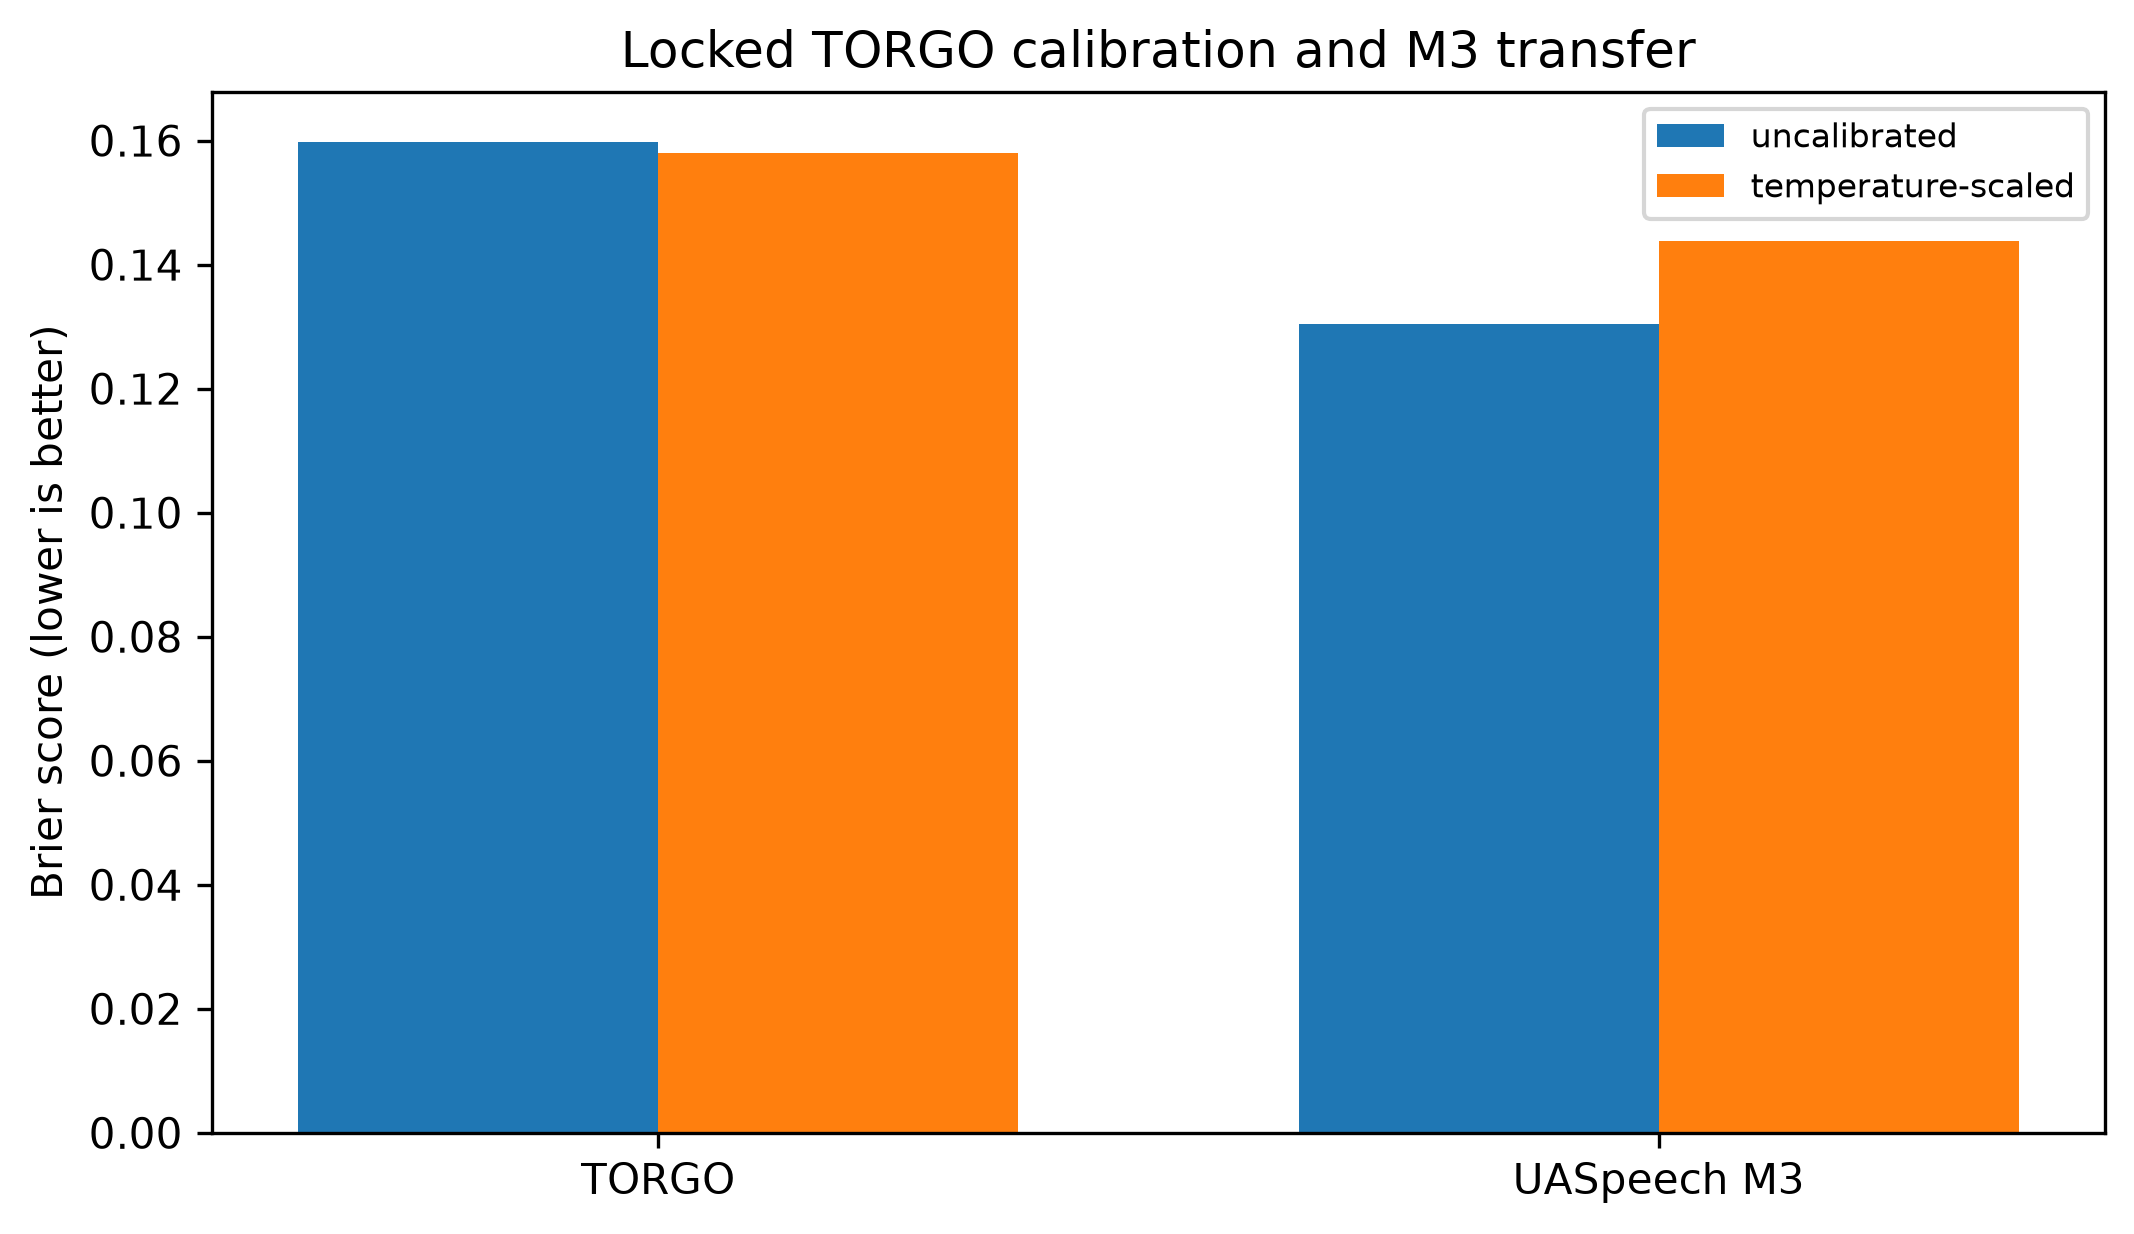

V10.2 calibration source matches frozen primary Brier; V8 snapshot PNG remains authoritative.


,release_file,source_project_relative,sha256
0,confounds_manifest.json,v10/outputs/confounds/manifest.json,f2db9704ea66d91db3725ddc7f8bd2c27622a8bf5774e3...
1,intelligibility_detection_descriptive.json,v10/outputs/diagnostics/intelligibility_detect...,4e50464591973710f0958713858082036eafffd0f43cf4...
2,reference_run_manifest.json,v10/outputs/reference_training/run_manifest.json,c50df02c0636df5c87443d00f0e93177a0e21abc77d629...
3,uaspeech_m3_budget_predictions.csv,v10/outputs/subsets/uaspeech_m3_budget_predict...,1c39a9ae973fb47b00d567ddddc95ecc7c32c41296a8c1...
4,matched_words_paired_seed_scores.csv,v8/v8_research_completion/figures/source_data/...,a8ccd7490a10dcdba5ce1165fa08ff985b4b325dac2aeb...


Release subset path scan: PASS. No source artifact was overwritten.


In [33]:
calibration_source=pd.read_csv(ROOT/'v10/publication/figure_sources/fig14_calibration.csv')
for cohort,label in [('TORGO','TORGO'),('Official UASpeech M3','UASpeech M3')]:
    saved=float(calibration_source.loc[(calibration_source.corpus.eq(label)) &
                                       calibration_source.calibration.eq('uncalibrated'),'Brier'].iloc[0])
    primary=float(primary_v102.loc[(primary_v102.cohort.eq(cohort)) &
                                   primary_v102.metric.eq('Brier'),'five_seed_mean'].iloc[0])
    assert np.isclose(saved,primary,atol=1e-12)
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
cohorts=['TORGO','UASpeech M3']
positions=np.arange(2)
for j,method in enumerate(['uncalibrated','temperature-scaled']):
    values=[float(calibration_source.loc[(calibration_source.corpus.eq(cohort)) &
                                         calibration_source.calibration.eq(method),'Brier'].iloc[0])
            for cohort in cohorts]
    ax.bar(positions+(-.18 if j==0 else .18),values,width=.36,label=method)
ax.set_xticks(positions,cohorts)
ax.set(ylabel='Brier score (lower is better)',title='Locked TORGO calibration and M3 transfer')
ax.legend(fontsize=8)
show_300dpi(fig,'fig21_calibration_verified_v10_2',calibration_source)
frozen_calibration=FROZEN/'figures/v8_speech_only_calibration.png'
working_calibration=ROOT/'v8/outputs/cache/dysarthria_detection_v8/run_2058b417224f6290/figures/v8_speech_only_calibration.png'
assert hashlib.sha256(frozen_calibration.read_bytes()).hexdigest() != hashlib.sha256(working_calibration.read_bytes()).hexdigest()
print('V10.2 calibration source matches frozen primary Brier; V8 snapshot PNG remains authoritative.')

release_dir=ROOT/'v10/release_v10_2'
release_dir.mkdir(parents=True,exist_ok=True)
release_sources={
    'confounds_manifest.json':ROOT/'v10/outputs/confounds/manifest.json',
    'intelligibility_detection_descriptive.json':ROOT/'v10/outputs/diagnostics/intelligibility_detection_descriptive.json',
    'reference_run_manifest.json':ROOT/'v10/outputs/reference_training/run_manifest.json',
    'uaspeech_m3_budget_predictions.csv':ROOT/'v10/outputs/subsets/uaspeech_m3_budget_predictions.csv',
    'matched_words_paired_seed_scores.csv':ROOT/'v8/v8_research_completion/figures/source_data/matched_words_paired_seed_scores.csv',
}
release_rows=[]
for release_name,source_path in release_sources.items():
    raw=source_path.read_text(encoding='utf-8')
    clean=raw.replace(str(ROOT)+'/', '${PROJECT_ROOT}/').replace(str(Path.home())+'/', '${USER_HOME}/')
    assert str(Path.home()) not in clean
    destination=release_dir/release_name
    destination.write_text(clean,encoding='utf-8')
    release_rows.append({'release_file':release_name,'source_project_relative':str(source_path.relative_to(ROOT)),
                         'sha256':hashlib.sha256(destination.read_bytes()).hexdigest()})
release_manifest=pd.DataFrame(release_rows)
release_manifest.to_csv(release_dir/'release_manifest.csv',index=False)
assert all(str(Path.home()) not in item.read_text(encoding='utf-8') for item in release_dir.iterdir() if item.is_file())
display(release_manifest)
print('Release subset path scan: PASS. No source artifact was overwritten.')


## V10.2 final claim and reproducibility audit

The published primary V10 input, weights and TORGO thresholds are unchanged. The paired duration result is a comparison of two saved out-of-fold models; its confidence interval may cross zero even when point estimates differ. The duration-overlap and leakage diagnostics do not replace full-cohort speaker evaluation. No UASpeech labels enter training or selection.

The frozen V8 snapshot remains authoritative. V10.2 regenerates its own verified calibration plot, while a different V8 working-tree calibration PNG is disclosed as a provenance discrepancy and is not silently overwritten. Test-time crops and pitch-preserving time stretch would require new WavLM feature extraction; they are kept out of the primary evaluation and run as the separate, pre-registered V10.3 section below.

In [34]:
original=ROOT/'v10/dysarthria_10.ipynb'
assert hashlib.sha256(original.read_bytes()).hexdigest()=='0069056b94616ab0b16c74da956b2d6de73ab97820b37905d8e96a783625674b'
assert not list((ROOT/'v10').glob('*.py'))
assert len(primary_v102)==24 and len(paired_metrics)==5 and len(paired_ci)==2
assert len(duration_subset)==75 and len(control_precision)==10 and len(high_auc)==5
assert len(leakage_demo)==2 and not confound_clean.duplicated(['model','metric']).any()
assert len(exact_duration_features)==15 and len(paired_export)==75
assert len(severity_reconciliation)==10 and len(release_manifest)==5
assert all((FIG_DIR/f'{stem}.{ext}').exists() for stem in ['fig16_paired_duration_v10_2','fig17_duration_overlap_v10_2','fig18_high_intelligibility_v10_2','fig19_speaker_leakage_v10_2','fig20_unique_wavlm_layers_v10_2','fig21_calibration_verified_v10_2'] for ext in ['png','pdf'])
assert all((SOURCE_DIR/f'{stem}.csv').exists() for stem in ['fig16_paired_duration_v10_2','fig17_duration_overlap_v10_2','fig18_high_intelligibility_v10_2','fig19_speaker_leakage_v10_2','fig20_unique_wavlm_layers_v10_2','fig21_calibration_verified_v10_2'])
assert verified_traceability()
assert all(row['checkpoint_sha256'] for row in lock['models'])
external_reproduction=json.loads((V10_OUT/'external/m3_reproduction_to_v8.json').read_text())
assert external_reproduction['speaker_seed_rows']==140 and external_reproduction['max_absolute_probability_difference']==0.0
print('V10.2 FINAL AUDIT')
print('Original V10 notebook SHA256: UNCHANGED')
print('V8 frozen reference and five model checkpoints: VERIFIED')
print('TORGO and official M3 primary probabilities and point estimates: UNCHANGED')
print('Duration-only exact comparator and paired speaker bootstrap: COMPLETE')
print('Duration-overlap frozen-baseline diagnostic: COMPLETE')
print('M3 high-intelligibility controls, including CF05 and CM01: COMPLETE')
print('Single-seed utterance-versus-speaker leakage diagnostic: COMPLETE')
print('One primary bootstrap source (seed 2026): COMPLETE')
print('Duplicate confound rows and final-layer probe: REMOVED FROM V10.2 DISPLAY')
print('UASpeech used for training, fine-tuning, calibration, threshold or model selection: NO')
print('V8 working-tree calibration PNG discrepancy: DISCLOSED; snapshot remains authoritative')
print('Optional test-time audio counterfactual: NOT IN V10.2 (see V10.3 section)')
print('Incremental disease-specific information beyond confounds: NOT ESTABLISHED')
print('Exact duration four-feature export and paired evidence CSVs: COMPLETE')
print('M3 full-cohort AUC: independently verified; checklist lower bound awaits CMPB source script')
print('V10.2 PNG/PDF/CSV figure trios and clean confound CSV: COMPLETE')
print('Five source files copied with share-safe paths; historical originals: UNCHANGED')


V10.2 FINAL AUDIT
Original V10 notebook SHA256: UNCHANGED
V8 frozen reference and five model checkpoints: VERIFIED
TORGO and official M3 primary probabilities and point estimates: UNCHANGED
Duration-only exact comparator and paired speaker bootstrap: COMPLETE
Duration-overlap frozen-baseline diagnostic: COMPLETE
M3 high-intelligibility controls, including CF05 and CM01: COMPLETE
Single-seed utterance-versus-speaker leakage diagnostic: COMPLETE
One primary bootstrap source (seed 2026): COMPLETE
Duplicate confound rows and final-layer probe: REMOVED FROM V10.2 DISPLAY
UASpeech used for training, fine-tuning, calibration, threshold or model selection: NO
V8 working-tree calibration PNG discrepancy: DISCLOSED; snapshot remains authoritative
Optional test-time audio counterfactual: NOT IN V10.2 (see V10.3 section)
Incremental disease-specific information beyond confounds: NOT ESTABLISHED
Exact duration four-feature export and paired evidence CSVs: COMPLETE
M3 full-cohort AUC: independently 

### Submission steps that require the separate CMPB project or author input

The CMPB manuscript and analysis scripts named in the supplied checklist were not found under this project or elsewhere in the local Documents tree. This notebook therefore does not claim to have edited manuscript markers, highlights, declarations, citation or journal checks, repository licensing, Zenodo deposit, or final co-author approval. The altered-audio time-stretch experiment is not part of the locked primary benchmark; it is run separately in the V10.3 section below.

## V10.3 Test-time speaking-rate intervention on the locked models

**Question.** Does the locked detector *use* speaking rate, or is duration only *sufficient* to reproduce its discrimination? The duration-only comparator (ROC-AUC 0.964) and the duration-overlap subset (detector 0.846) cannot separate these; changing the rate of the same recordings at test time can.

**Design.** No model is retrained. A fixed, label-blind subset of TORGO recordings is re-encoded under seven conditions:

| Condition | Processing |
|---|---|
| `original` | frozen cached features; no reprocessing |
| `identity` | phase-vocoder pass at rate 1.0 (processing control) |
| `roundtrip` | slowed ×0.8, then sped ×1.25: same length, doubled processing (artifact control) |
| `rate_0.80`, `rate_0.90` | slowed (durations ×1.25, ×1.11) |
| `rate_1.11`, `rate_1.25` | sped up (durations ×0.90, ×0.80) |

**Primary estimand.** The within-speaker dose–response of the locked logit to duration, scaled to the observed group difference: *F* = (logit change per doubling of duration) × (dysarthric − control log₂ duration gap) / (dysarthric − control logit gap). *F* ≈ 0 means test-time duration changes barely move the detector; *F* ≈ 1 means duration alone would account for the whole group separation. The AUC rate-swap is secondary: simulation showed it cannot rule out a real duration effect at this sample size.

Pitch is preserved (`librosa.effects.time_stretch`). Each speaker is scored only by the locked **speech-only** outer-fold model for which that speaker was held out, with that fold's frozen threshold. The speech-only head receives no acoustic or duration features; duration can reach it only through the audio.

**Pipeline checks run before the long extraction:** (1) re-extracting unmodified audio for two recordings per speaker reproduces the frozen WavLM embeddings; (2) re-scoring all recordings with the loaded fold models reproduces the published out-of-fold probabilities.

**The analysis plan in the next cell is written and hashed before any audio is processed.** Requirements: the raw TORGO WAVs (original `file_path`, or `TORGO_DATASET_PATH` / the KaggleHub cache, resolved through `relative_path`) and the V10 reference-training fold checkpoints. Expected cost: 6 × 750 WavLM-Base encodings (minutes on a GPU, about an hour on CPU); each condition is cached and resumable.

In [35]:
import hashlib, json, platform, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import librosa
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score
from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT, ROOT, SEEDS

RATE_DIR = ROOT / 'v10/outputs/v10_3_rate'
RATE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = ROOT / 'v10/publication/figures'
SOURCE_DIR = ROOT / 'v10/publication/figure_sources'
FIG_DIR.mkdir(parents=True, exist_ok=True)
SOURCE_DIR.mkdir(parents=True, exist_ok=True)
CONFIG = b.Config()
ARM = 'speech_only'
N_PER_SPEAKER = 50
# librosa: rate > 1 is faster/shorter. Duration factor = 1 / product(rates).
CONDITIONS = {
    'original': None,
    'identity': [1.0],
    'roundtrip': [0.8, 1.25],
    'rate_0.80': [0.8],
    'rate_0.90': [0.9],
    'rate_1.11': [1 / 0.9],
    'rate_1.25': [1.25],
}
DOSE = ['rate_1.25', 'rate_1.11', 'identity', 'rate_0.90', 'rate_0.80']
duration_factor = {c: (1.0 / float(np.prod(r)) if r else 1.0) for c, r in CONDITIONS.items()}

PLAN = {
    'version': 'v10.3-rate-intervention-1',
    'models': f'locked V10-Reference {ARM} outer-fold heads (seed x outer) and frozen fold thresholds; no retraining',
    'subset': f'{N_PER_SPEAKER} recordings per TORGO speaker, chosen by SHA-256 of source_id (label-blind); same subset in every condition',
    'preprocessing': 'frozen V8 preprocess_waveform, then time_stretch, then V8 peak-normalise, array gate and centre 12 s crop',
    'conditions': {c: r for c, r in CONDITIONS.items()},
    'primary_estimand': ('duration-explained fraction F = S x dD / G, where S = speaker-weighted mean within-speaker slope of '
                         'seed-mean logit on log2(duration factor) over the five DOSE conditions (both diagnoses pooled); '
                         'dD = dysarthric minus control mean of speaker-mean log2(source_seconds) in the subset; '
                         'G = dysarthric minus control mean seed-mean identity logit'),
    'secondary_estimands': [
        'dose-response slope per diagnosis',
        'rate-swap delta AUC = AUC(controls rate_0.80, dysarthric rate_1.25) - AUC(identity), five-seed mean',
        'reverse swap delta AUC = AUC(controls rate_1.25, dysarthric rate_0.80) - AUC(identity)',
        'artifact controls: |logit(identity) - logit(original)| and |logit(roundtrip) - logit(identity)|',
    ],
    'uncertainty': 'physical-speaker bootstrap within diagnosis, one draw shared across seeds, 10000 resamples, seed 20261018; draws with G <= 0 give F = NaN and are counted',
    'decision_rules': {
        'rate_reliant': 'F 95% CI lower bound >= 0.25 AND both diagnosis slopes > 0 with CIs excluding 0 AND median roundtrip |delta logit| < 0.5 x median |delta logit| at rate_0.80/rate_1.25',
        'not_shown_rate_reliant': 'F 95% CI upper bound < 0.25 (test-time duration change explains less than a quarter of the group logit gap)',
        'otherwise': 'inconclusive; report estimates and intervals only',
        'note': 'F linearly extrapolates the locked model response from +-25% stretches to the observed group duration difference',
    },
    'pipeline_checks': ['re-extraction of 2 unmodified recordings per speaker reproduces frozen embeddings (relative max diff < 1e-3)',
                        'locked-fold scoring of all recordings reproduces published OOF probabilities (max abs diff < 1e-6)'],
}
plan_bytes = json.dumps(PLAN, indent=2, sort_keys=True).encode()
plan_path = RATE_DIR / 'analysis_plan.json'
if plan_path.is_file():
    assert plan_path.read_bytes() == plan_bytes, 'Analysis plan changed after it was frozen'
else:
    plan_path.write_bytes(plan_bytes)
PLAN_SHA = hashlib.sha256(plan_bytes).hexdigest()
ENVIRONMENT = {'python': platform.python_version(), 'torch': torch.__version__, 'librosa': librosa.__version__,
               'numpy': np.__version__}
print('Analysis plan SHA256:', PLAN_SHA)
print('Environment:', ENVIRONMENT)

Analysis plan SHA256: bfe2921312d2658761d048b5101bd61a81c4e6226cfab49b8631619210fcfe67
Environment: {'python': '3.12.14', 'torch': '2.14.0', 'librosa': '1.0.0', 'numpy': '2.5.3'}


In [36]:
def with_local_audio(frame, resolve_root):
    """Keep recorded paths if they exist here; otherwise rebuild them from relative_path."""
    paths = frame.file_path.map(Path)
    if not paths.map(Path.is_file).all():
        root = resolve_root()
        print('Recorded audio paths not found on this machine; using', root)
        paths = frame.relative_path.map(lambda rel: root / rel)
    missing = int((~paths.map(Path.is_file)).sum())
    assert missing == 0, f'{missing} raw audio files not found; set TORGO_DATASET_PATH / UASPEECH_DATASET_PATH'
    return frame.assign(file_path=paths.map(str))

device = b.choose_device()
lock = json.loads((OUT / 'deployment/v8_torgo_model_lock.json').read_text())
meta = pd.read_csv(FROZEN / 'features/usable_metadata.csv')
speech_frozen = np.load(FROZEN / 'features/speech_embeddings.npy', mmap_mode='r')
acoustic_frozen = np.load(FROZEN / 'features/acoustic_features.npy', mmap_mode='r')
assert len(meta) == len(speech_frozen) == len(acoustic_frozen) == 17630

order = meta.source_id.map(lambda s: hashlib.sha256(f'rate:{s}'.encode()).hexdigest())
chosen = np.sort(meta.assign(_o=order).sort_values('_o')
                 .groupby('physical_speaker_id', sort=True).head(N_PER_SPEAKER).index.to_numpy())
subset = with_local_audio(meta.loc[chosen].reset_index(drop=True), lambda: b.resolve_dataset_root(CONFIG))
assert subset.physical_speaker_id.nunique() == 15
assert subset.groupby('physical_speaker_id').size().eq(N_PER_SPEAKER).all()
subset[['source_id', 'physical_speaker_id', 'label', 'mic_type', 'source_seconds']].to_csv(
    RATE_DIR / 'subset_manifest.csv', index=False)
print('Subset:', len(subset), 'recordings;', subset.groupby('label').size().to_dict(), '| device:', device)

encoder, weight_sha, _ = b.load_pretrained(CONFIG, b.CACHE_ROOT / 'pretrained' / CONFIG.encoder_name, device)
assert weight_sha == lock['pretrained_weight_sha256'], 'Encoder weights differ from the locked model'

Subset: 750 recordings; {0: 350, 1: 400} | device: mps
Downloading: "https://download.pytorch.org/torchaudio/models/wavlm_base.pth" to /Users/Noor/Documents/projects/dysarthia/v10/outputs/cache/dysarthria_detection_v10/pretrained/WAVLM_BASE/wavlm_base.pth


100%|██████████| 360M/360M [01:29<00:00, 4.24MB/s] 


In [37]:
MAX_SAMPLES = int(CONFIG.max_seconds * CONFIG.sample_rate)

def condition_waveform(row, rates):
    """V8 preprocessing, then stretch, then the V8 post-steps again (same order for every condition)."""
    audio = b.preprocess_waveform(Path(row.file_path), row.mic_type, CONFIG)
    for rate in rates:
        audio = librosa.effects.time_stretch(audio, rate=float(rate))
    peak = float(np.max(np.abs(audio)))
    if peak > 0:
        audio = audio / peak
    if row.mic_type == 'array':
        audio = np.where(np.abs(audio) < .01, 0.0, audio)
    cropped = len(audio) > MAX_SAMPLES
    if cropped:
        start = (len(audio) - MAX_SAMPLES) // 2
        audio = audio[start:start + MAX_SAMPLES]
    if len(audio) < 1024:
        audio = np.pad(audio, (0, 1024 - len(audio)))
    audio = np.asarray(audio, dtype=np.float32)
    assert np.isfinite(audio).all()
    return audio, cropped

def extract(name, rates):
    """Resumable per-condition cache of [n, 4, 1536] embeddings and acoustic features."""
    path = RATE_DIR / f'features_{name}.npz'
    if path.is_file():
        with np.load(path, allow_pickle=False) as saved:
            if list(saved['source_id']) == list(subset.source_id):
                return saved['speech'], saved['acoustic'], saved['cropped']
    speech, acoustic, cropped = [], [], []
    t0 = time.time()
    for i, row in enumerate(subset.itertuples()):
        audio, was_cropped = condition_waveform(row, rates)
        speech.append(b._encode_batch(encoder, [audio], CONFIG, device)[0])
        acoustic.append(b.acoustic_features(audio, CONFIG.sample_rate))
        cropped.append(was_cropped)
        if (i + 1) % 150 == 0:
            print(f'{name}: {i + 1}/{len(subset)} ({time.time() - t0:.0f} s)', flush=True)
    speech, acoustic, cropped = np.stack(speech), np.stack(acoustic), np.array(cropped)
    np.savez(path, speech=speech, acoustic=acoustic, cropped=cropped,
             source_id=subset.source_id.to_numpy().astype(str))
    return speech, acoustic, cropped

# Pipeline check 1: re-extracting unmodified audio reproduces the frozen embeddings (2 per speaker).
check_ix = subset.groupby('physical_speaker_id', sort=True).head(2).index.to_numpy()
re_extracted = np.stack([b._encode_batch(encoder, [condition_waveform(subset.loc[i], [])[0]], CONFIG, device)[0]
                         for i in check_ix])
frozen_rows = np.asarray(speech_frozen[chosen[check_ix]])
max_diff = float(np.max(np.abs(re_extracted - frozen_rows)))
rel_diff = max_diff / float(np.max(np.abs(frozen_rows)))
print(f'Re-extraction vs frozen ({len(check_ix)} recordings, 15 speakers): max abs diff {max_diff:.2e} (relative {rel_diff:.2e})')
assert rel_diff < 1e-3, 'Re-extraction does not reproduce the frozen features; stop and investigate'

/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Re-extraction vs frozen (30 recordings, 15 speakers): max abs diff 0.00e+00 (relative 0.00e+00)


In [38]:
def score(store_meta, speech, acoustic):
    rows = []
    for seed in SEEDS:
        for outer in range(5):
            fold = OUT / f'folds/{ARM}/seed{seed}_outer{outer}'
            audit = json.loads((fold / 'fold_audit.json').read_text())
            model = b._new_head(CONFIG, speech, acoustic, ARM == 'fusion', device)
            model.load_state_dict(torch.load(fold / 'final/best.pt', map_location=device, weights_only=True))
            scale = np.load(fold / 'final/acoustic_scaler.npz')
            store = b.BagStore(store_meta, speech, acoustic, (scale['mean'], scale['scale']), device)
            pred = b.predict_speakers(model, store, set(audit['test_physical_speakers']),
                                      CONFIG.max_utterances_per_bag)
            pred['seed'], pred['outer_fold'] = seed, outer
            pred['threshold'] = audit['selected_threshold']
            pred['predicted_label'] = (pred.probability >= pred.threshold).astype(int)
            rows.append(pred)
    result = pd.concat(rows, ignore_index=True)
    assert len(result) == 75 and result.groupby('seed').physical_speaker_id.nunique().eq(15).all()
    return result

# Pipeline check 2: scoring all recordings with the loaded folds reproduces the published OOF probabilities.
full = score(meta, speech_frozen, acoustic_frozen)
published = pd.read_csv(OUT / 'v10_reference_speaker_oof_predictions.csv')
merged = full.merge(published, on=['seed', 'outer_fold', 'physical_speaker_id'], suffixes=('', '_pub'),
                    validate='one_to_one')
repro = float(np.max(np.abs(merged.probability - merged.probability_pub)))
print('Locked-fold scoring vs published OOF: max abs diff', repro)
assert len(merged) == 75 and repro < 1e-6

# Both pipeline checks pass before the long stretched-audio extraction starts.
features = {'original': (np.asarray(speech_frozen[chosen]), np.asarray(acoustic_frozen[chosen]),
                         np.zeros(len(subset), bool))}
for name, rates in CONDITIONS.items():
    if rates is not None:
        features[name] = extract(name, rates)
condition_manifest = pd.DataFrame([{'condition': c, 'duration_factor': duration_factor[c],
                                    'n_cropped_to_12s': int(features[c][2].sum())} for c in CONDITIONS])
condition_manifest.to_csv(RATE_DIR / 'condition_manifest.csv', index=False)
display(condition_manifest)

scores = []
for name in CONDITIONS:
    s, a, _ = features[name]
    pred = score(subset, s, a)
    pred['condition'] = name
    scores.append(pred)
scores = pd.concat(scores, ignore_index=True)
eps = 1e-6
scores['logit'] = np.log(scores.probability.clip(eps, 1 - eps) / (1 - scores.probability.clip(eps, 1 - eps)))
scores.to_csv(RATE_DIR / 'speaker_scores_by_condition.csv', index=False)

Locked-fold scoring vs published OOF: max abs diff 1.1102230246251565e-16


/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed

identity: 150/750 (9 s)
identity: 300/750 (16 s)
identity: 450/750 (23 s)
identity: 600/750 (29 s)


/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/librosa/effects.py:445: UserWarning: n_fft=2048 is too large for input signal of length=1024
  stft = core.stft(y, **kwargs)
/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/librosa/core/spectrum.py:3004: UserWarning: n_fft=2048 is too large for input signal of length=1024
  stft(


identity: 750/750 (38 s)
roundtrip: 150/750 (6 s)
roundtrip: 300/750 (12 s)
roundtrip: 450/750 (17 s)
roundtrip: 600/750 (23 s)


...

/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/librosa/core/spectrum.py:3004: UserWarning: n_fft=2048 is too large for input signal of length=1280
  stft(


rate_0.80: 750/750 (42 s)
rate_0.90: 150/750 (9 s)
rate_0.90: 300/750 (16 s)
rate_0.90: 450/750 (23 s)
rate_0.90: 600/750 (32 s)


/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/librosa/core/spectrum.py:3004: UserWarning: n_fft=2048 is too large for input signal of length=1138
  stft(


rate_0.90: 750/750 (41 s)
rate_1.11: 150/750 (10 s)
rate_1.11: 300/750 (18 s)
rate_1.11: 450/750 (26 s)
rate_1.11: 600/750 (33 s)
rate_1.11: 750/750 (43 s)
rate_1.25: 150/750 (8 s)
rate_1.25: 300/750 (15 s)
rate_1.25: 450/750 (21 s)
rate_1.25: 600/750 (28 s)
rate_1.25: 750/750 (37 s)


,condition,duration_factor,n_cropped_to_12s
0,original,1.000000,0
1,identity,1.000000,0
2,roundtrip,1.000000,0
3,rate_0.80,1.250000,16
4,rate_0.90,1.111111,12
5,rate_1.11,0.900000,0
6,rate_1.25,0.800000,0


In [39]:
P = scores.pivot_table(index=['seed', 'physical_speaker_id', 'label'], columns='condition',
                       values='logit').reset_index()
speakers = P[['physical_speaker_id', 'label']].drop_duplicates().sort_values('physical_speaker_id')
ids = speakers.physical_speaker_id.to_list()
pos_ix = np.flatnonzero(speakers.label.eq(1).to_numpy())
neg_ix = np.flatnonzero(speakers.label.eq(0).to_numpy())
# L[condition] has shape (5 seeds, 15 speakers), speakers in `ids` order.
L = {c: P.pivot(index='seed', columns='physical_speaker_id', values=c)[ids].to_numpy() for c in CONDITIONS}

def auc_from(pos_cond, neg_cond, dp=pos_ix, dn=neg_ix):
    """Five-seed mean AUC with dysarthric scores from pos_cond and control scores from neg_cond."""
    p = L[pos_cond][:, dp][:, :, None]
    n = L[neg_cond][:, dn][:, None, :]
    return float(((p > n) + .5 * (p == n)).mean(axis=(1, 2)).mean())

x = np.log2([duration_factor[c] for c in DOSE])
seed_mean = P.groupby(['physical_speaker_id', 'label'])[DOSE].mean()
speaker_slope = np.polyfit(x, np.stack([L[c].mean(axis=0) for c in DOSE]), 1)[0]  # one slope per speaker
identity_logit = L['identity'].mean(axis=0)
log_seconds = np.log2(subset.source_seconds).groupby(subset.physical_speaker_id).mean()[ids].to_numpy()

def estimates(dp=pos_ix, dn=neg_ix):
    base = auc_from('identity', 'identity', dp, dn)
    slope = float(np.concatenate([speaker_slope[dp], speaker_slope[dn]]).mean())
    gap = float(identity_logit[dp].mean() - identity_logit[dn].mean())
    duration_gap = float(log_seconds[dp].mean() - log_seconds[dn].mean())
    return {'duration_explained_fraction': slope * duration_gap / gap if gap > 0 else np.nan,
            'pooled_slope': slope, 'group_logit_gap': gap, 'group_log2_duration_gap': duration_gap,
            'slope_dysarthric': float(speaker_slope[dp].mean()),
            'slope_control': float(speaker_slope[dn].mean()),
            'rate_swap_delta_auc': auc_from('rate_1.25', 'rate_0.80', dp, dn) - base,
            'reverse_swap_delta_auc': auc_from('rate_0.80', 'rate_1.25', dp, dn) - base}

point = estimates()
rng = np.random.default_rng(20261018)
draws = [estimates(rng.choice(pos_ix, len(pos_ix)), rng.choice(neg_ix, len(neg_ix))) for _ in range(10000)]
ci = {k: (float(np.nanpercentile([d[k] for d in draws], 2.5)), float(np.nanpercentile([d[k] for d in draws], 97.5)))
      for k in point}
n_undefined = int(np.isnan([d['duration_explained_fraction'] for d in draws]).sum())
print(f'Bootstrap draws with non-positive group logit gap (F undefined): {n_undefined} / {len(draws)}')

def median_abs(a, b_):
    return float((P[a] - P[b_]).abs().median())
artifact = {'identity_vs_original': median_abs('identity', 'original'),
            'roundtrip_vs_identity': median_abs('roundtrip', 'identity'),
            'rate_0.80_vs_identity': median_abs('rate_0.80', 'identity'),
            'rate_1.25_vs_identity': median_abs('rate_1.25', 'identity')}
auc_by_condition = {c: auc_from(c, c) for c in CONDITIONS}

stretch_effect = min(artifact['rate_0.80_vs_identity'], artifact['rate_1.25_vs_identity'])
rule = PLAN['decision_rules']
fraction_ci = ci['duration_explained_fraction']
if (fraction_ci[0] >= .25 and ci['slope_dysarthric'][0] > 0 and ci['slope_control'][0] > 0
        and artifact['roundtrip_vs_identity'] < .5 * stretch_effect):
    verdict = 'rate_reliant'
elif fraction_ci[1] < .25:
    verdict = 'not_shown_rate_reliant'
else:
    verdict = 'inconclusive'

summary = {'plan_sha256': PLAN_SHA, 'environment': ENVIRONMENT, 'device': str(device), 'model_arm': ARM,
           'n_speakers': 15, 'n_recordings_per_speaker': N_PER_SPEAKER, 'point': point,
           'ci95': {k: list(v) for k, v in ci.items()}, 'bootstrap_draws_fraction_undefined': n_undefined,
           'artifact_median_abs_delta_logit': artifact,
           'auc_by_condition_five_seed_mean': auc_by_condition,
           'n_cropped_to_12s': dict(zip(condition_manifest.condition, condition_manifest.n_cropped_to_12s)),
           'verdict': verdict, 'verdict_rule': rule.get(verdict, rule['otherwise']),
           'pipeline_checks': {'reextraction_relative_max_diff': rel_diff, 'locked_scoring_max_abs_diff': repro}}
(RATE_DIR / 'rate_intervention_summary.json').write_text(json.dumps(summary, indent=2, default=int))
display(pd.DataFrame({'point': point, 'lower_95': {k: v[0] for k, v in ci.items()},
                      'upper_95': {k: v[1] for k, v in ci.items()}}))
display(pd.Series(auc_by_condition, name='five-seed mean AUC'))
display(pd.Series(artifact, name='median |delta logit|'))
print('Pre-specified verdict:', verdict)

Bootstrap draws with non-positive group logit gap (F undefined): 8 / 10000


,point,lower_95,upper_95
duration_explained_fraction,0.052934,-0.065976,0.262100
pooled_slope,1.151989,0.649648,1.679031
group_logit_gap,3.399466,1.278903,5.320935
group_log2_duration_gap,0.156207,-0.149607,0.464684
slope_dysarthric,0.789459,0.197689,1.461813
slope_control,1.566310,0.752114,2.411028
rate_swap_delta_auc,-0.150000,-0.275000,-0.025000
reverse_swap_delta_auc,-0.003571,-0.089286,0.082143


original     0.860714
identity     0.860714
roundtrip    0.739286
rate_0.80    0.767857
rate_0.90    0.785714
rate_1.11    0.821429
rate_1.25    0.825000
Name: five-seed mean AUC, dtype: float64

identity_vs_original     2.384186e-07
roundtrip_vs_identity    1.099349e+00
rate_0.80_vs_identity    7.670850e-01
rate_1.25_vs_identity    5.358541e-01
Name: median |delta logit|, dtype: float64

Pre-specified verdict: inconclusive


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
ax = axes[0]
curve_rows = []
for label, name, color in [(0, 'Control', '#396ca0'), (1, 'Dysarthric', '#b26d37')]:
    group = seed_mean.xs(label, level='label')[DOSE]
    group_ids = group.index.to_numpy()
    boot = np.array([group.loc[rng.choice(group_ids, len(group_ids))].mean().to_numpy() for _ in range(2000)])
    mean = group.mean().to_numpy()
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    ax.plot(x, mean, marker='o', color=color, label=f'{name} (n={len(group_ids)})')
    ax.fill_between(x, lo, hi, color=color, alpha=.2)
    curve_rows += [{'group': name, 'log2_duration_factor': xi, 'mean_logit': m, 'lower_95': l, 'upper_95': h}
                   for xi, m, l, h in zip(x, mean, lo, hi)]
ax.axvline(0, ls=':', color='grey')
ax.set(xlabel='log2 duration factor (slower →)', ylabel='Seed-mean speaker logit', title='(a) Dose–response')
ax.legend(fontsize=8)
ax = axes[1]
names = ['original', 'identity', 'roundtrip']
vals = [auc_by_condition[c] for c in names] + [auc_from('rate_1.25', 'rate_0.80'), auc_from('rate_0.80', 'rate_1.25')]
labels = ['Original', 'Identity', 'Round-trip', 'Swap: controls\nslowed, dys. sped', 'Reverse swap']
ax.bar(range(len(vals)), vals, color=['#999999'] * 3 + ['#396ca0', '#b26d37'])
for i, v in enumerate(vals):
    ax.text(i, v + .02, f'{v:.3f}', ha='center', fontsize=8)
ax.set_xticks(range(len(vals)), labels, fontsize=8)
ax.set(ylim=(0, 1.08), ylabel='Five-seed mean ROC-AUC', title='(b) Discrimination under rate interventions')
ax.axhline(.5, ls=':', color='grey')
stem = 'fig22_rate_intervention_v10_3'
fig.savefig(FIG_DIR / f'{stem}.png', dpi=300, bbox_inches='tight')
fig.savefig(FIG_DIR / f'{stem}.pdf', bbox_inches='tight')
pd.concat([pd.DataFrame(curve_rows),
           pd.DataFrame({'group': 'AUC', 'condition': labels, 'auc': vals})], ignore_index=True).to_csv(
    SOURCE_DIR / f'{stem}.csv', index=False)
plt.show()

/var/folders/6p/0k1fr55x5y30xfbkh6bxy27r0000gp/T/ipykernel_57522/674286927.py:33: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### Optional: the same intervention on official UASpeech M3 (locked deployment models)
Run only after the TORGO result is recorded. It uses the five locked all-TORGO **speech-only** heads and their thresholds. UASpeech labels enter metrics only. Set `RUN_UASPEECH = True` to run it; raw audio is found through the recorded paths or `UASPEECH_DATASET_PATH`.

In [41]:
RUN_UASPEECH = False
if RUN_UASPEECH:
    from v10.run_external import features as external_features
    ua_meta, _, _ = external_features('M3')
    ua_order = ua_meta.source_id.map(lambda s: hashlib.sha256(f'rate:{s}'.encode()).hexdigest())
    ua_chosen = np.sort(ua_meta.assign(_o=ua_order).sort_values('_o')
                        .groupby('physical_speaker_id', sort=True).head(30).index.to_numpy())
    ua_subset = with_local_audio(ua_meta.loc[ua_chosen].reset_index(drop=True), b.resolve_uaspeech_root)
    assert ua_subset.physical_speaker_id.nunique() == 28
    ua_rows = []
    for name in ['identity', 'rate_0.80', 'rate_1.25']:
        s, a = [], []
        for row in ua_subset.itertuples():
            audio, _ = condition_waveform(row, CONDITIONS[name])
            s.append(b._encode_batch(encoder, [audio], CONFIG, device)[0])
            a.append(b.acoustic_features(audio, CONFIG.sample_rate))
        pred = b.predict_uaspeech_from_lock(CONFIG, OUT, lock, ua_subset, np.stack(s), np.stack(a), device)
        pred = pred[pred.model_arm.eq(ARM)].copy()
        pred['condition'] = name
        ua_rows.append(pred)
    ua_scores = pd.concat(ua_rows, ignore_index=True)
    ua_scores.to_csv(RATE_DIR / 'uaspeech_m3_scores_by_condition.csv', index=False)
    ua_auc = (ua_scores.groupby(['condition', 'seed'])
              .apply(lambda g: roc_auc_score(g.label, g.probability)).unstack('seed'))
    ua_auc['five_seed_mean'] = ua_auc.mean(axis=1)
    display(ua_auc.round(4))

In [42]:
summary_saved = json.loads((RATE_DIR / 'rate_intervention_summary.json').read_text())
assert summary_saved['plan_sha256'] == hashlib.sha256((RATE_DIR / 'analysis_plan.json').read_bytes()).hexdigest()
assert summary_saved['pipeline_checks']['reextraction_relative_max_diff'] < 1e-3
assert summary_saved['pipeline_checks']['locked_scoring_max_abs_diff'] < 1e-6
assert all((FIG_DIR / f'fig22_rate_intervention_v10_3.{ext}').exists() for ext in ('png', 'pdf'))
assert (SOURCE_DIR / 'fig22_rate_intervention_v10_3.csv').exists()
print('V10.3 RATE-INTERVENTION AUDIT')
print('Models retrained or thresholds changed: NO')
print('Analysis plan frozen before audio processing: YES (SHA256', summary_saved['plan_sha256'][:16] + '...)')
print('Frozen-embedding and published-OOF reproduction checks: PASSED')
print('Primary duration-explained fraction of group logit gap: {:.3f} [{:.3f}, {:.3f}]'.format(
    summary_saved['point']['duration_explained_fraction'], *summary_saved['ci95']['duration_explained_fraction']))
print('Secondary rate-swap delta AUC: {:+.3f} [{:+.3f}, {:+.3f}]'.format(
    summary_saved['point']['rate_swap_delta_auc'], *summary_saved['ci95']['rate_swap_delta_auc']))
print('Pre-specified verdict:', summary_saved['verdict'])
print('Send back: v10/outputs/v10_3_rate/rate_intervention_summary.json, speaker_scores_by_condition.csv,')
print('           condition_manifest.csv and v10/publication/figures/fig22_rate_intervention_v10_3.png/.pdf + source CSV')

V10.3 RATE-INTERVENTION AUDIT
Models retrained or thresholds changed: NO
Analysis plan frozen before audio processing: YES (SHA256 bfe2921312d26587...)
Frozen-embedding and published-OOF reproduction checks: PASSED
Primary duration-explained fraction of group logit gap: 0.053 [-0.066, 0.262]
Secondary rate-swap delta AUC: -0.150 [-0.275, -0.025]
Pre-specified verdict: inconclusive
Send back: v10/outputs/v10_3_rate/rate_intervention_summary.json, speaker_scores_by_condition.csv,
           condition_manifest.csv and v10/publication/figures/fig22_rate_intervention_v10_3.png/.pdf + source CSV


### Current CMPB author-guide check (corrected 17 October 2026)

The V10.2 version of this cell quoted the *Computers in Biology and Medicine* guide by mistake. The target journal is **Computer Methods and Programs in Biomedicine** (CMPB). From the official CMPB Guide for Authors (read via search snippets; the page itself returned HTTP 403, so re-confirm in a browser before upload):

- structured abstract of at most **350 words**, which must report sensitivity and specificity (manuscript: 334 words);
- body text that "should not normally exceed **3,500 words**" (manuscript is longer; deferred by author decision);
- at most **50 references** (manuscript: 46);
- **3–5 highlights**, each at most **85 characters** including spaces (satisfied).

These journal rules are submission checks; they do not modify V10 predictions or thresholds.

## Historical V10 research audit (frozen)

~~~text
V10 FINAL RESEARCH AUDIT
========================

V8 reference preserved:
PASS

V8 reproduced:
PASS

Physical-speaker leakage:
PASS

Five TORGO seeds:
COMPLETE

V8-like performance preserved:
YES

MFCC baseline:
YES

WavLM Logistic Regression baseline:
YES

Mean vs Mean+SD:
YES

Final layer vs Last-4:
YES

Mean vs Attention:
YES

HuBERT:
SKIPPED

Epoch stability:
YES

Speaker error analysis:
YES

Layer interpretability:
YES

Attention diagnostic:
YES

Confound analysis:
YES

Incremental analysis performed:
YES

Incremental value beyond confounds:
NO

Official UASpeech M3:
COMPLETE

UASpeech speakers evaluated:
28

UASpeech used for training:
NO

UASpeech used for fine-tuning:
NO

UASpeech used for threshold selection:
NO

UASpeech used for calibration:
NO

UASpeech used for model selection:
NO

Severity/intelligibility:
YES

M2-M8:
YES

Utterance-budget:
YES

Matched-content:
YES

Reverse transfer:
SKIPPED

Third corpus:
NOT AVAILABLE

Publication tables:
PASS

Publication figures:
PASS

Traceability:
PASS

FINAL CLAIM LIMITS
------------------
- M3 is locked zero-shot cross-corpus evaluation on official UASpeech; prior project versions studied this corpus.
- The 15 TORGO and 28 M3 speakers, rather than the five repeated seeds, define participant counts.
- V8-level performance is reproduced by a fresh retraining of the same architecture and input; V10's primary model is intentionally unchanged.
- Duration-only and other measured confound controls can discriminate speakers; the V10 result is not proof of disease-specific acoustic biomarkers.
- The paired V10-minus-confounds ROC-AUC interval crosses zero, and adding confounds to V10 worsens balanced accuracy; incremental disease-specific information is not established.
- Attention weights are descriptive diagnostics, not causal explanations.
- Official intelligibility associations and operating points are descriptive, not validated clinical severity cutoffs.
- M2–M8 vary in cohort coverage; M3 remains primary.
- HuBERT and reverse transfer were skipped to protect the priority of complete external validation.
- No approved third English dysarthria corpus was found locally; local EasyCall is Italian-language.
- The frozen V8 snapshot verifies; one current V8 working-tree calibration PNG differs from that snapshot.

~~~

## Current saved V10-Reference reproduction

```json
{
  "comparison": "fresh V10-Reference retraining versus frozen historical V8",
  "same_splits": true,
  "same_five_seeds": true,
  "same_pretrained_weights": true,
  "max_absolute_probability_difference": 0.0,
  "all_75_predictions_match": true,
  "bitwise_probability_equivalence": true,
  "numerical_tolerance_pass": true
}
```

## Saved V10 figure gallery

Original 300-DPI previews remain embedded. V10.2 redraws the duplicate layer-probe figure above.

### Fig01 Architecture

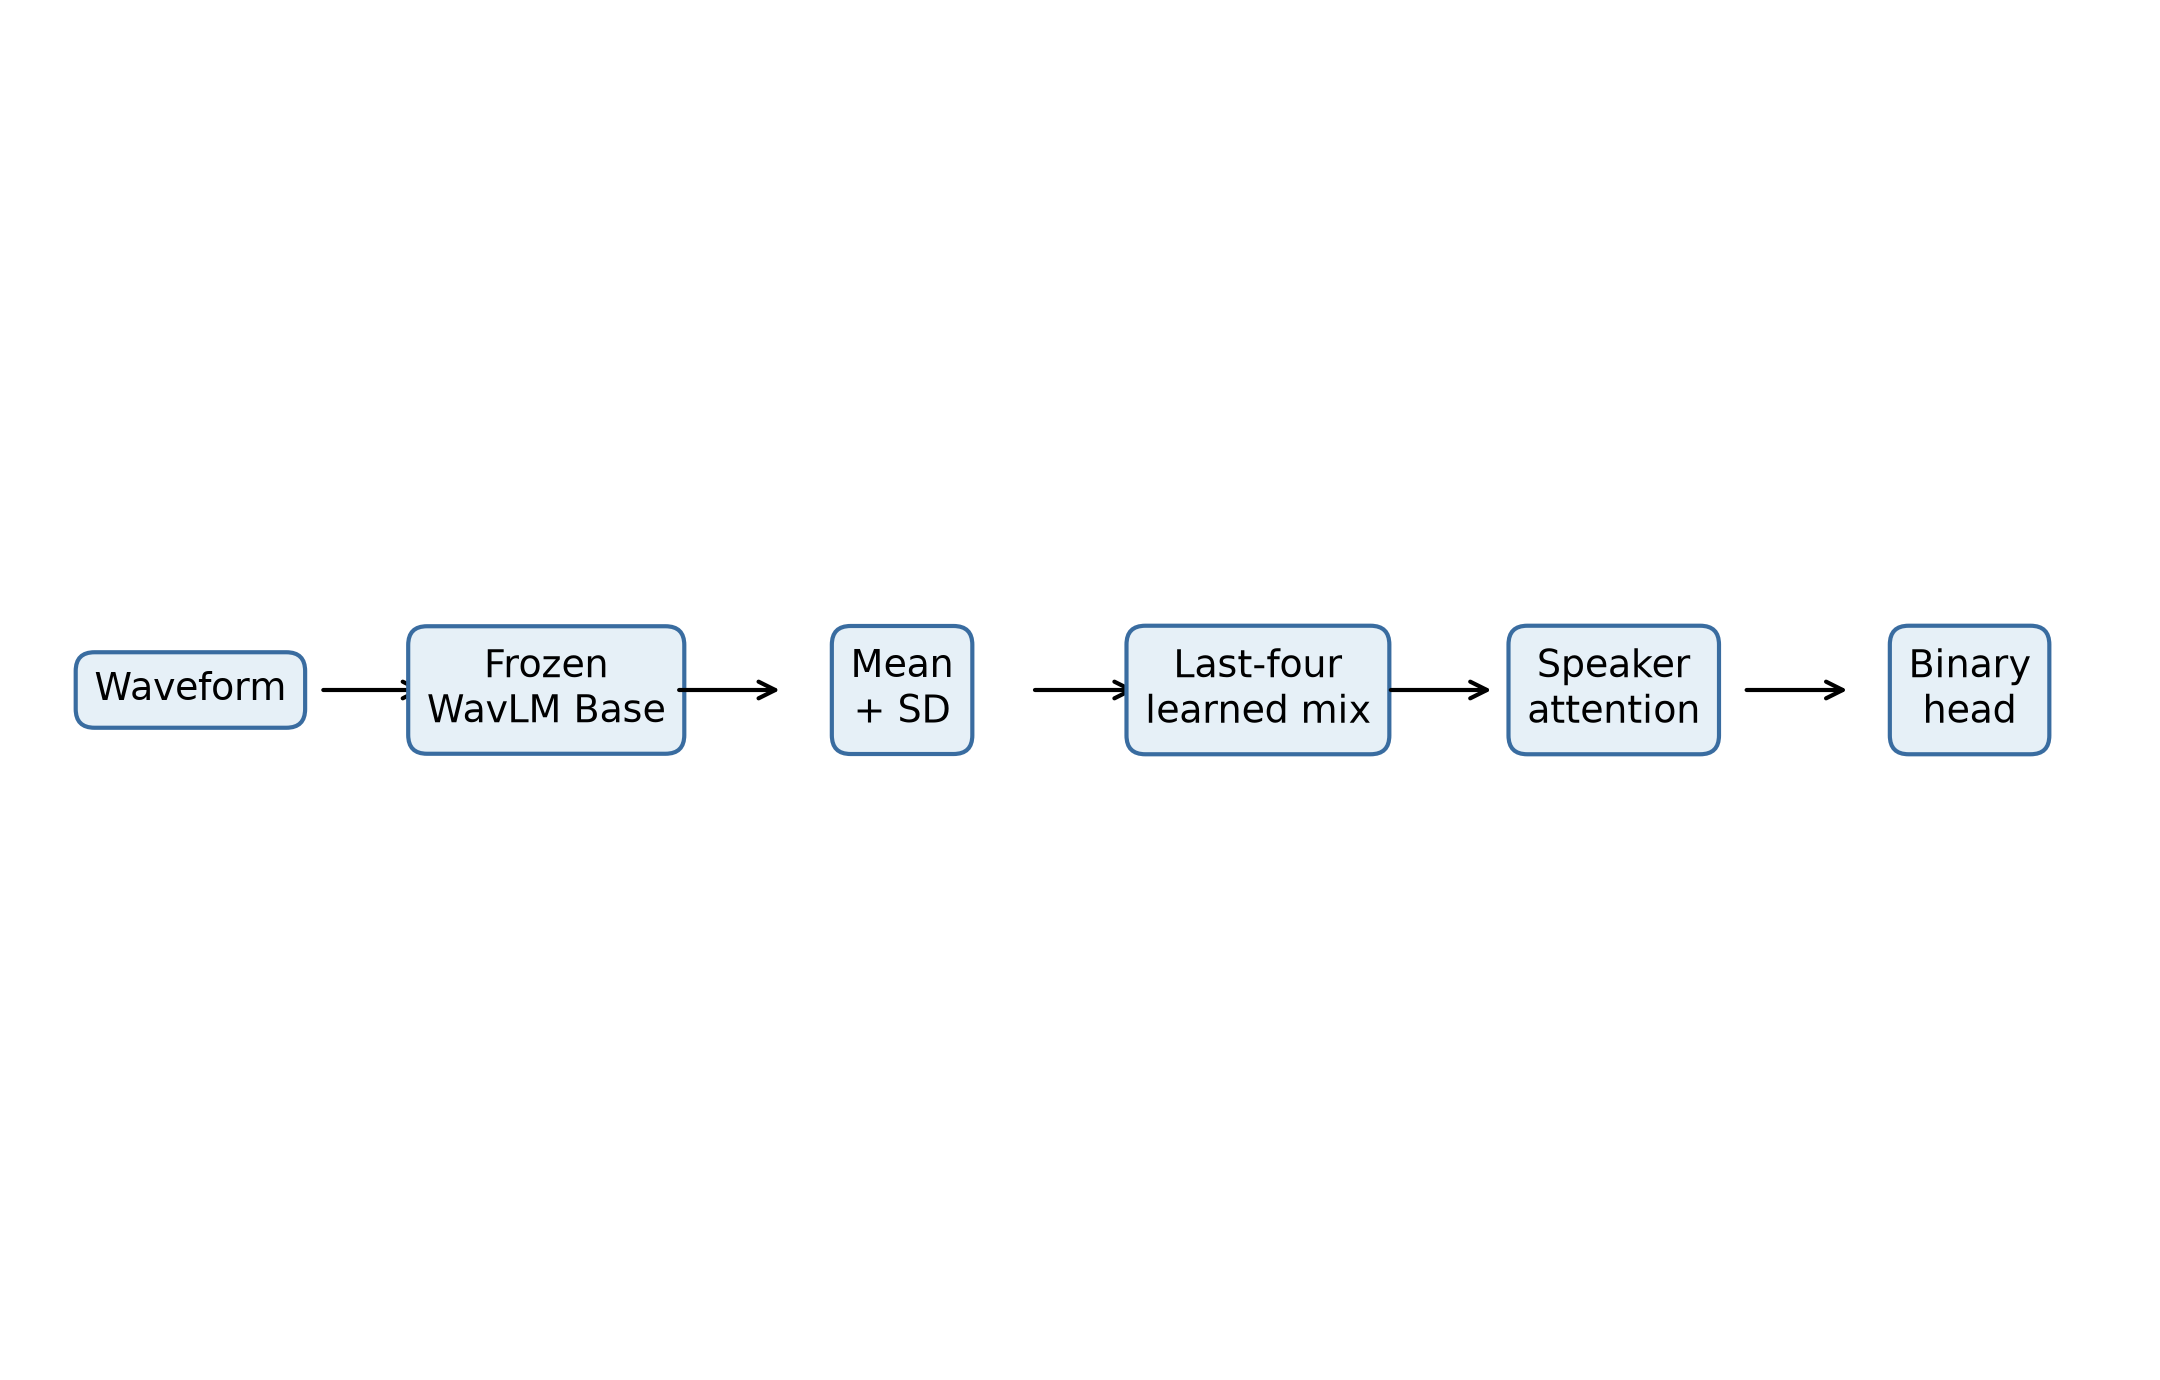

### Fig02 Torgo Roc Pr

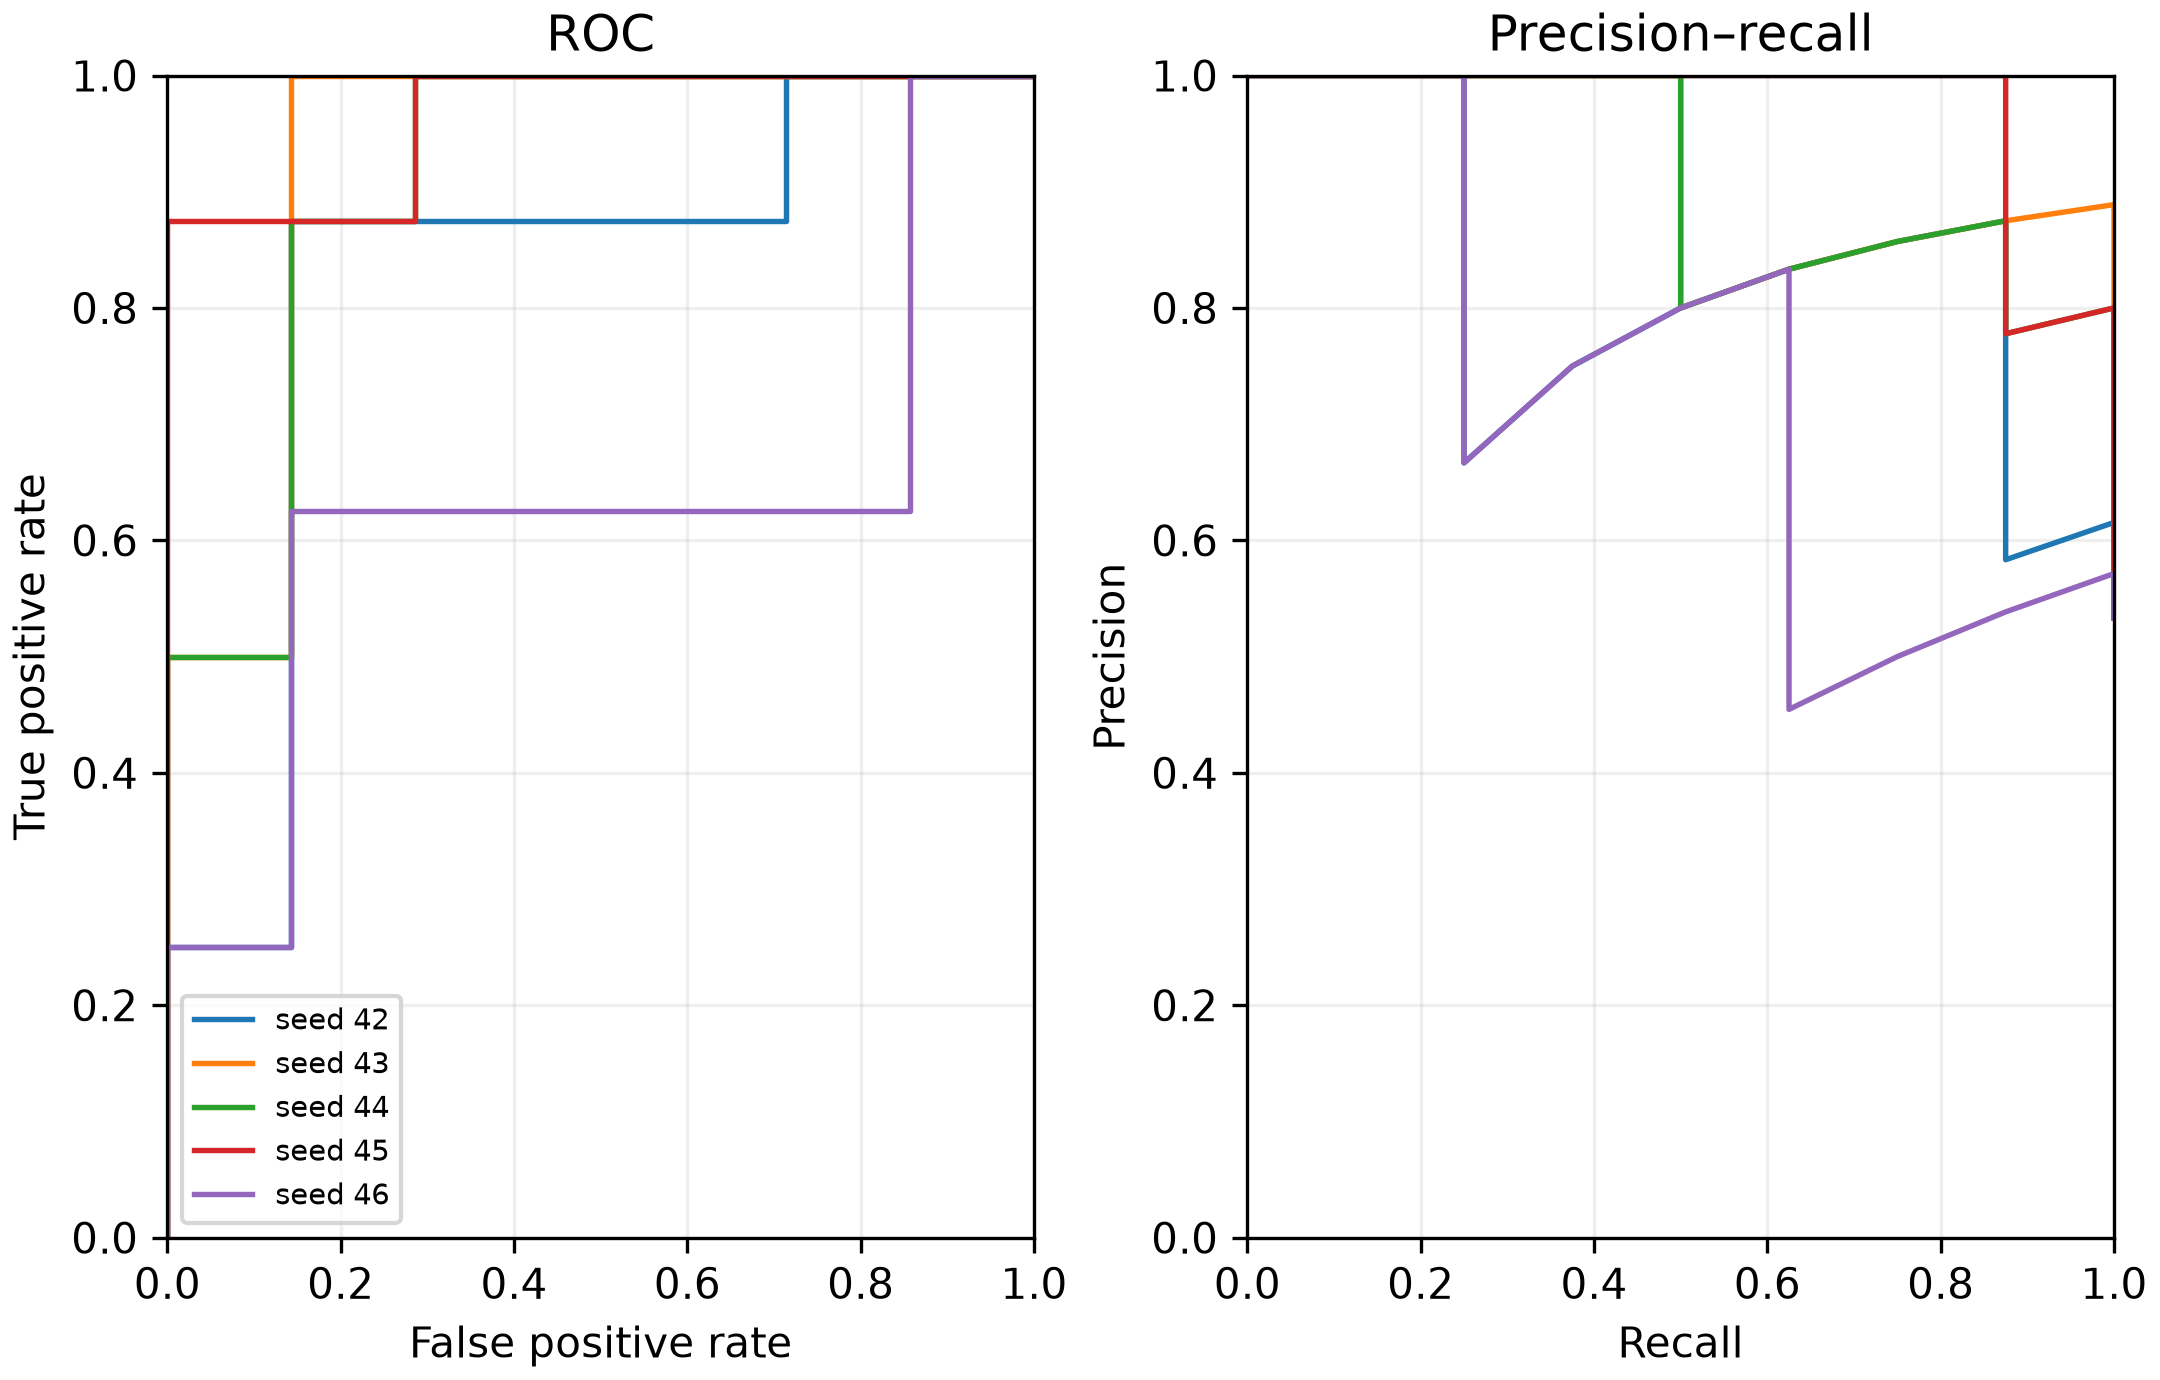

### Fig03 V8 V10

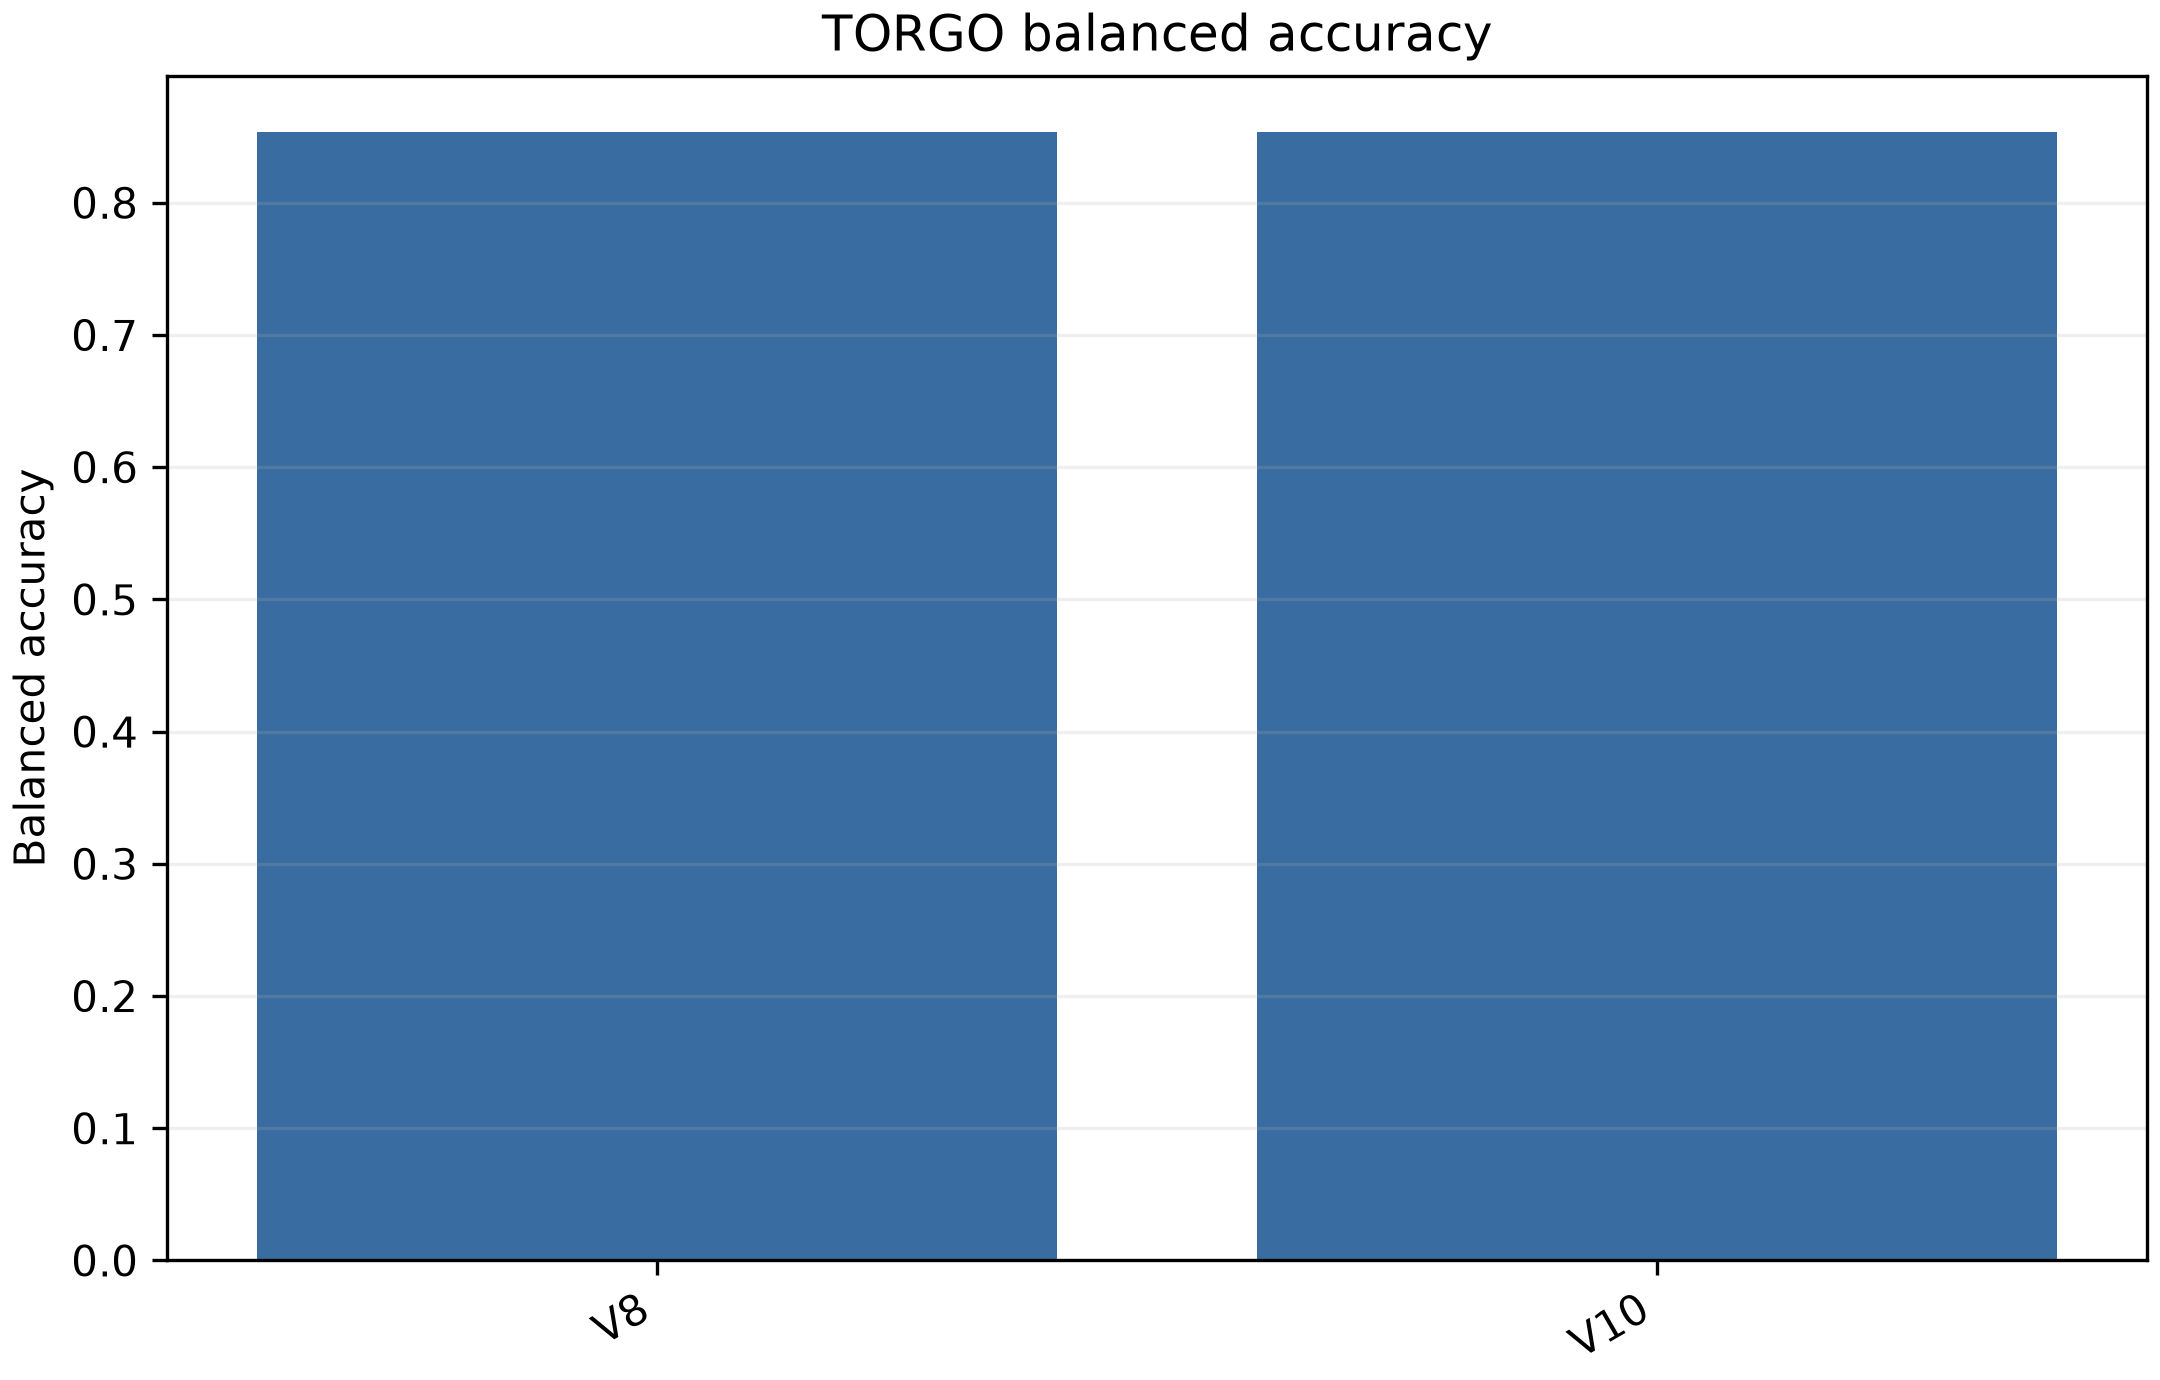

### Fig04 Simple Baselines

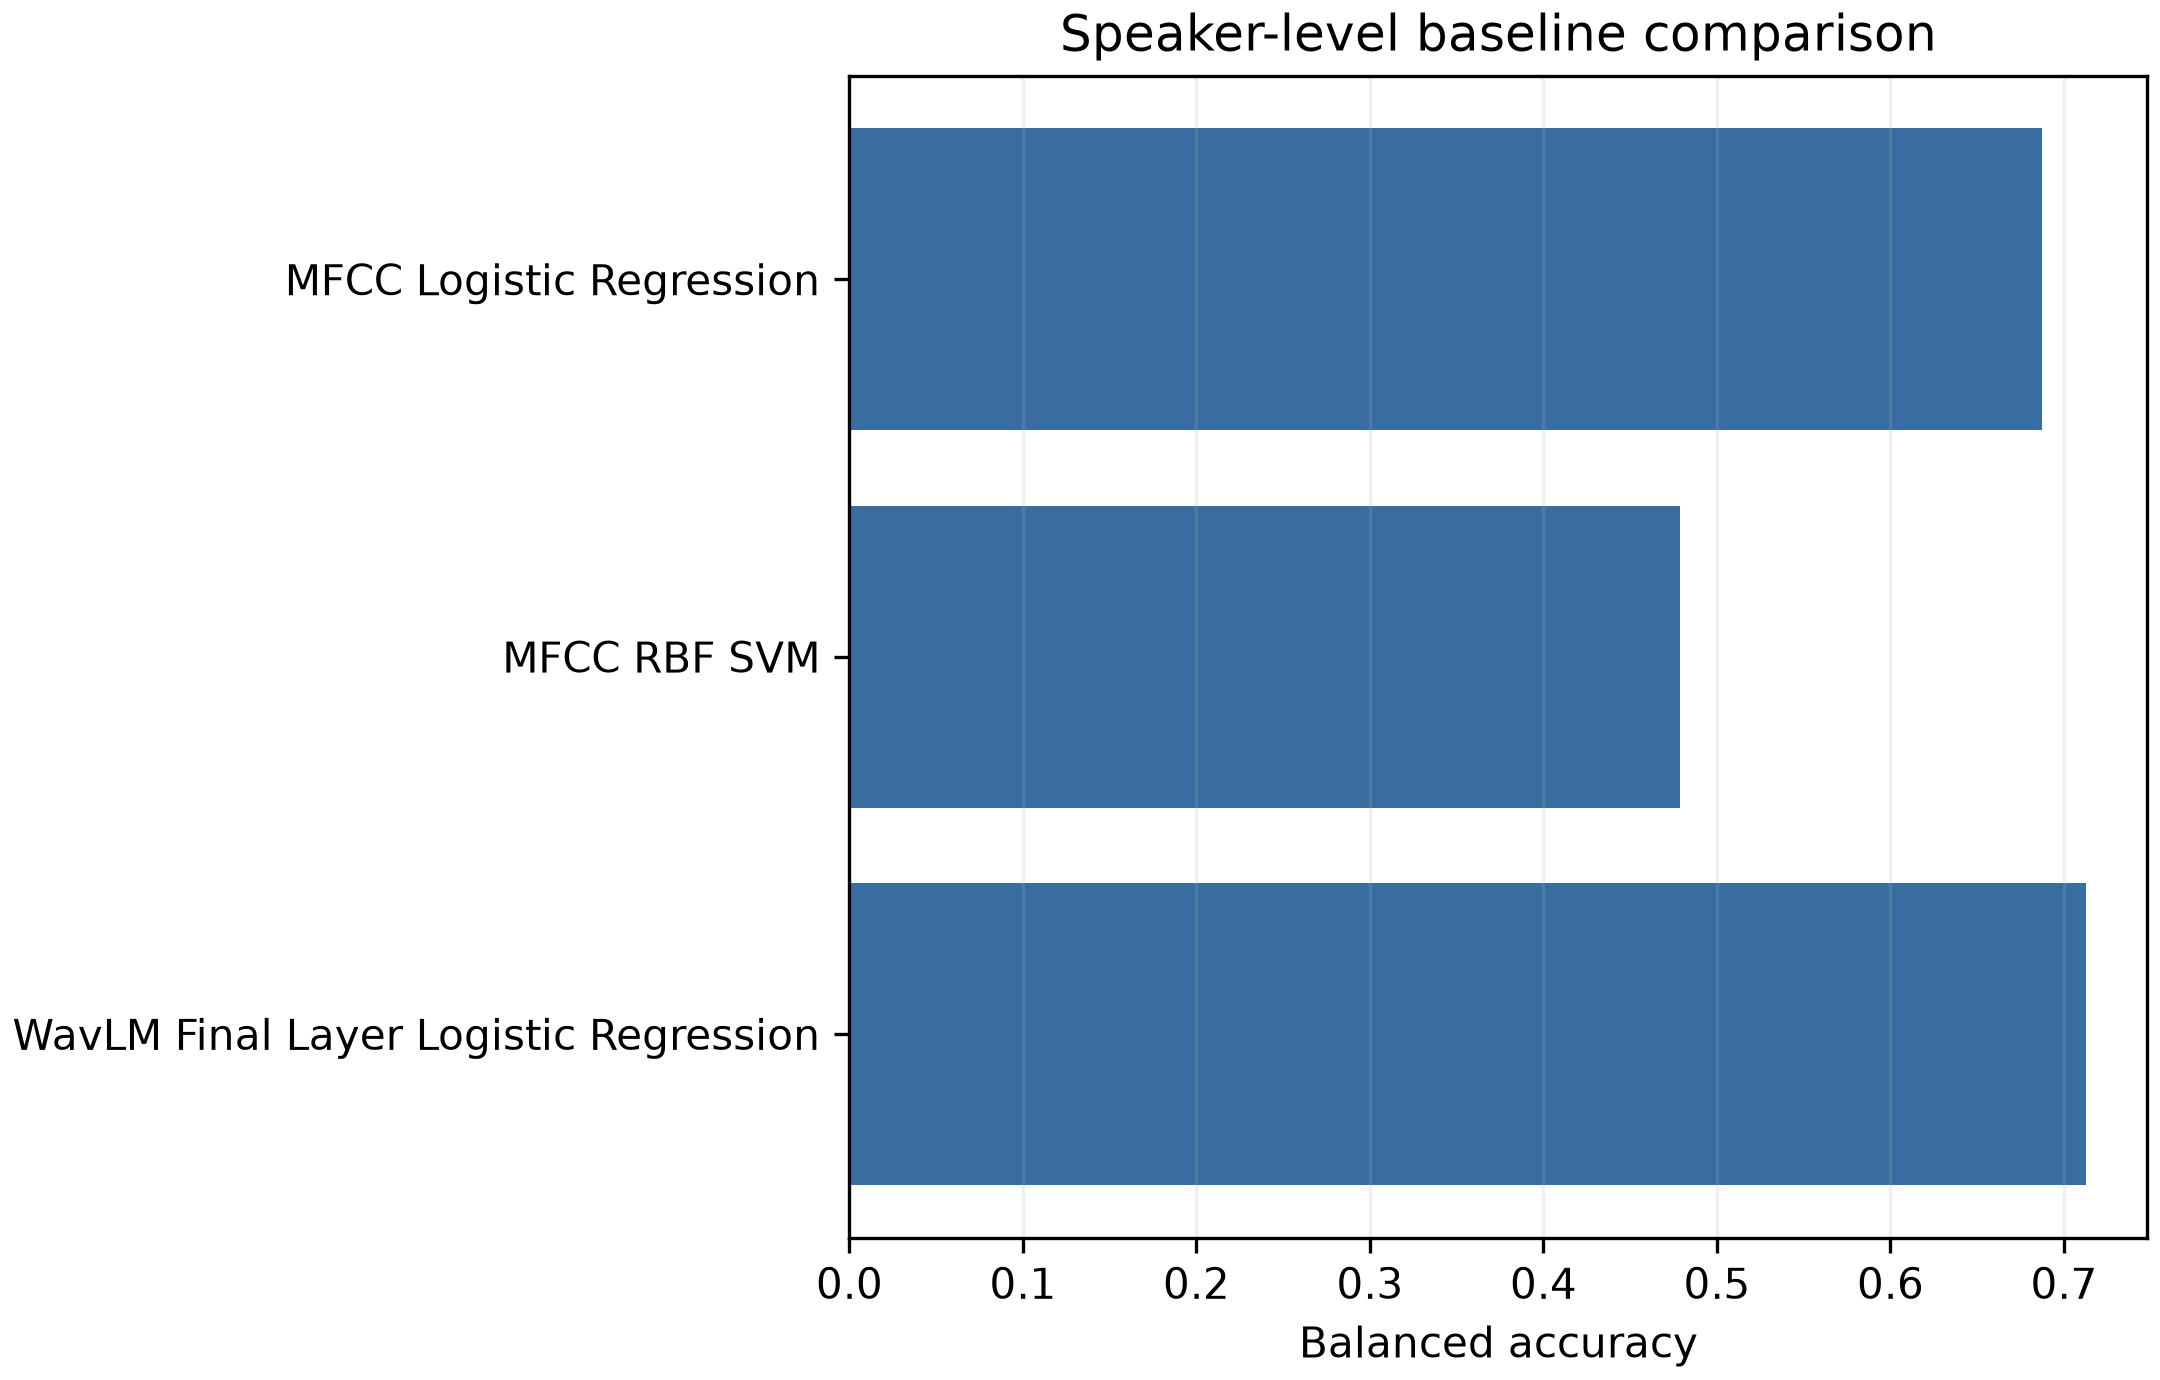

### Fig06 Layer Mixture Weights

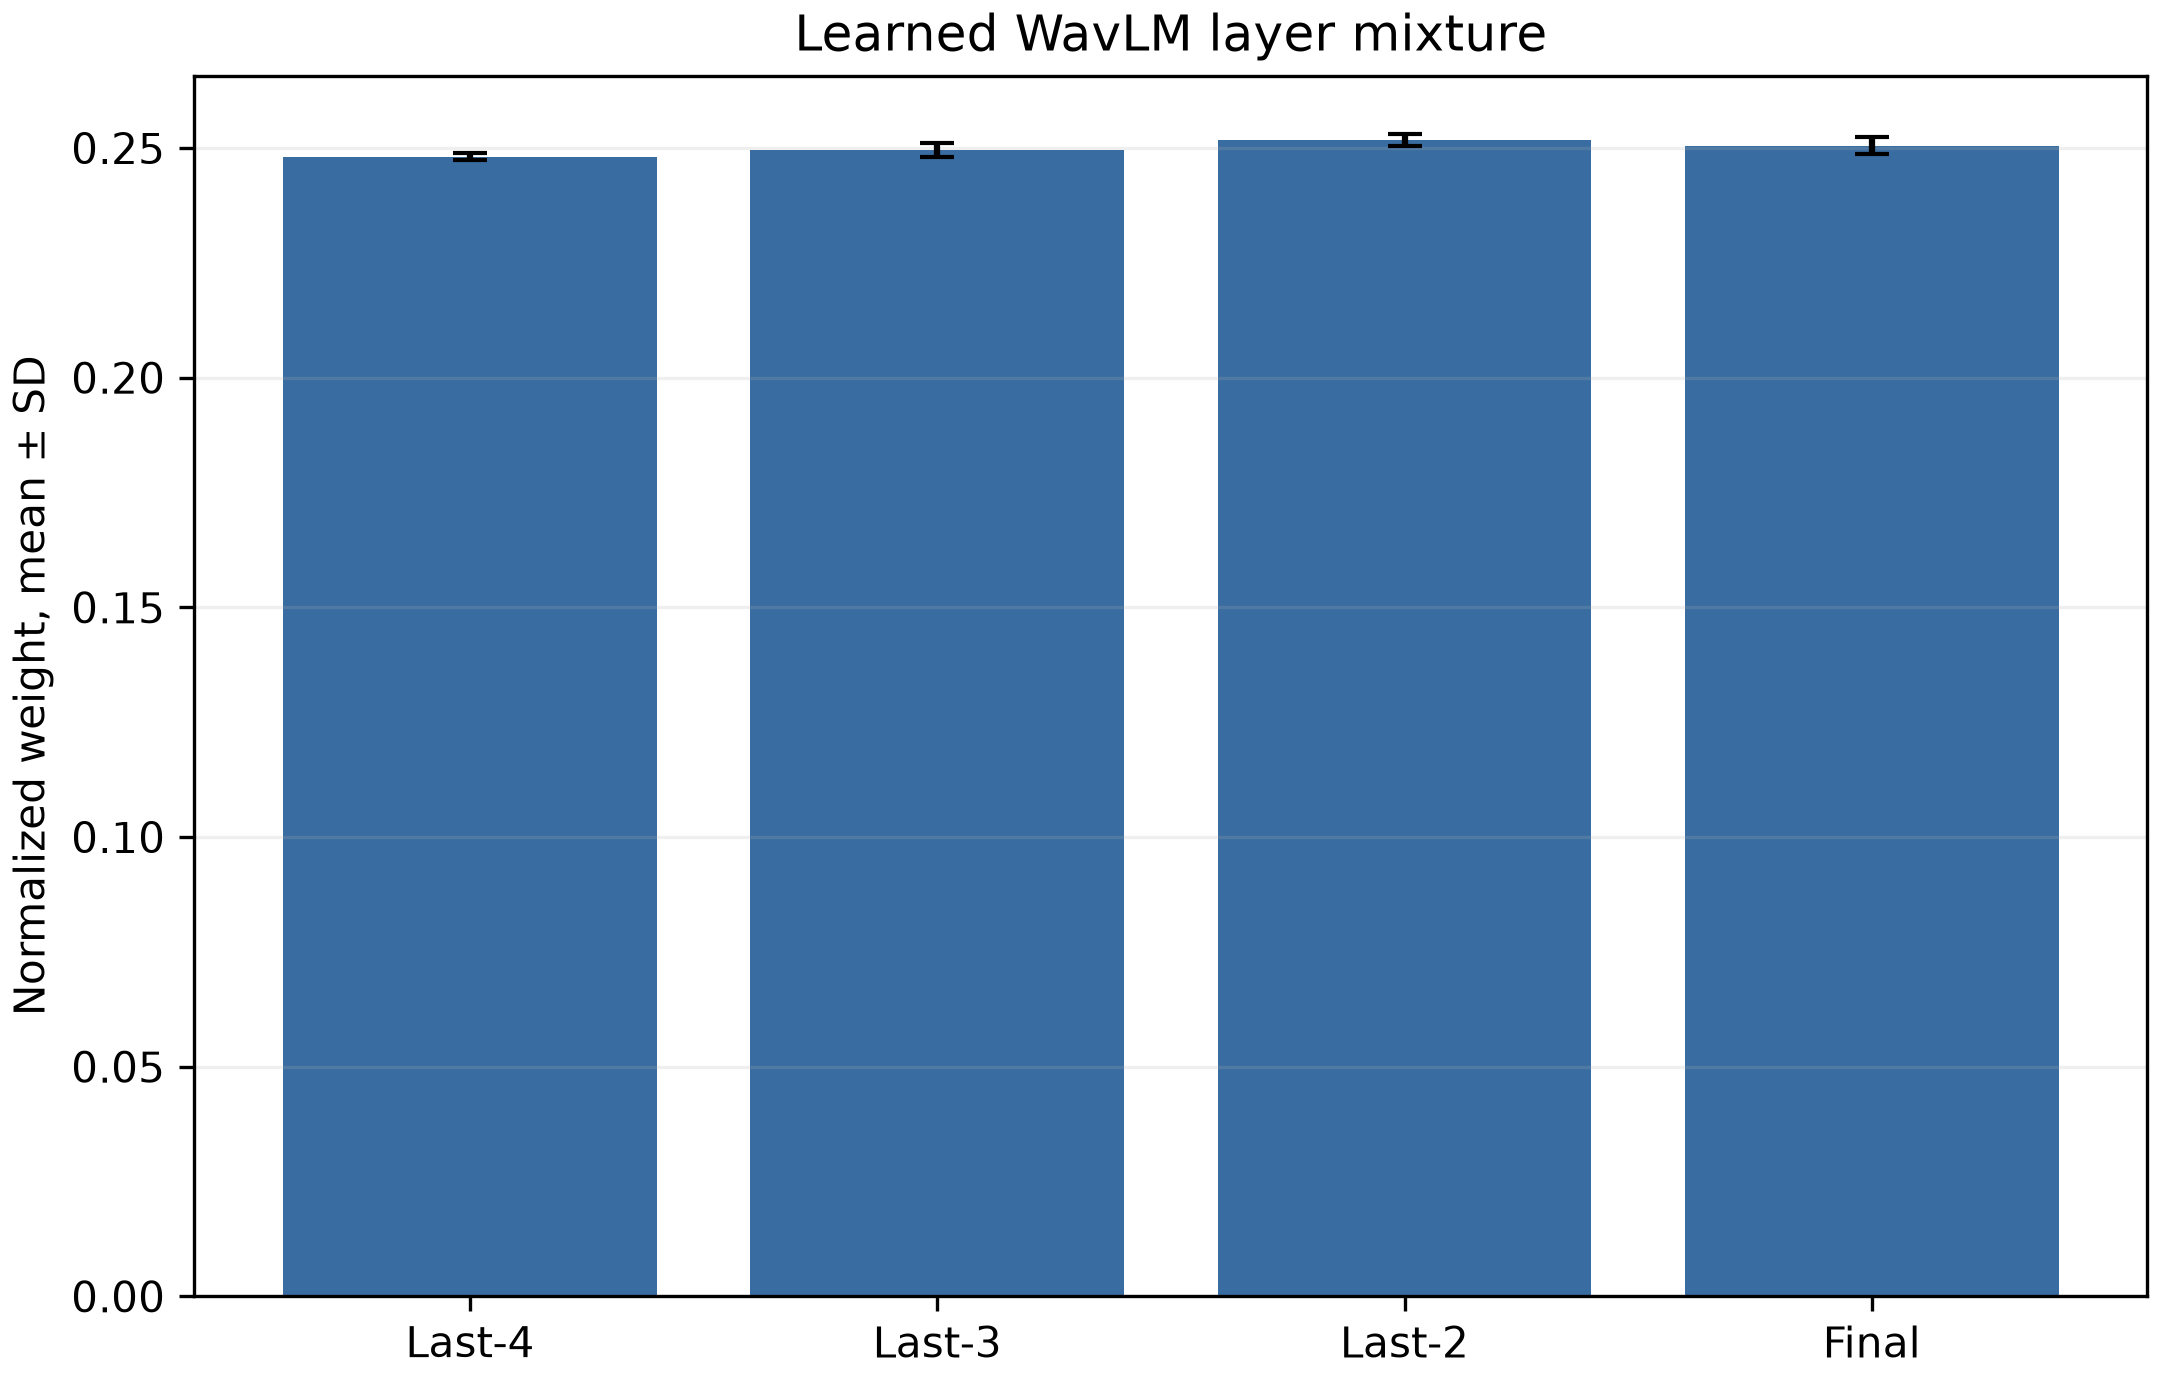

### Fig07 Uaspeech M3 Roc Pr

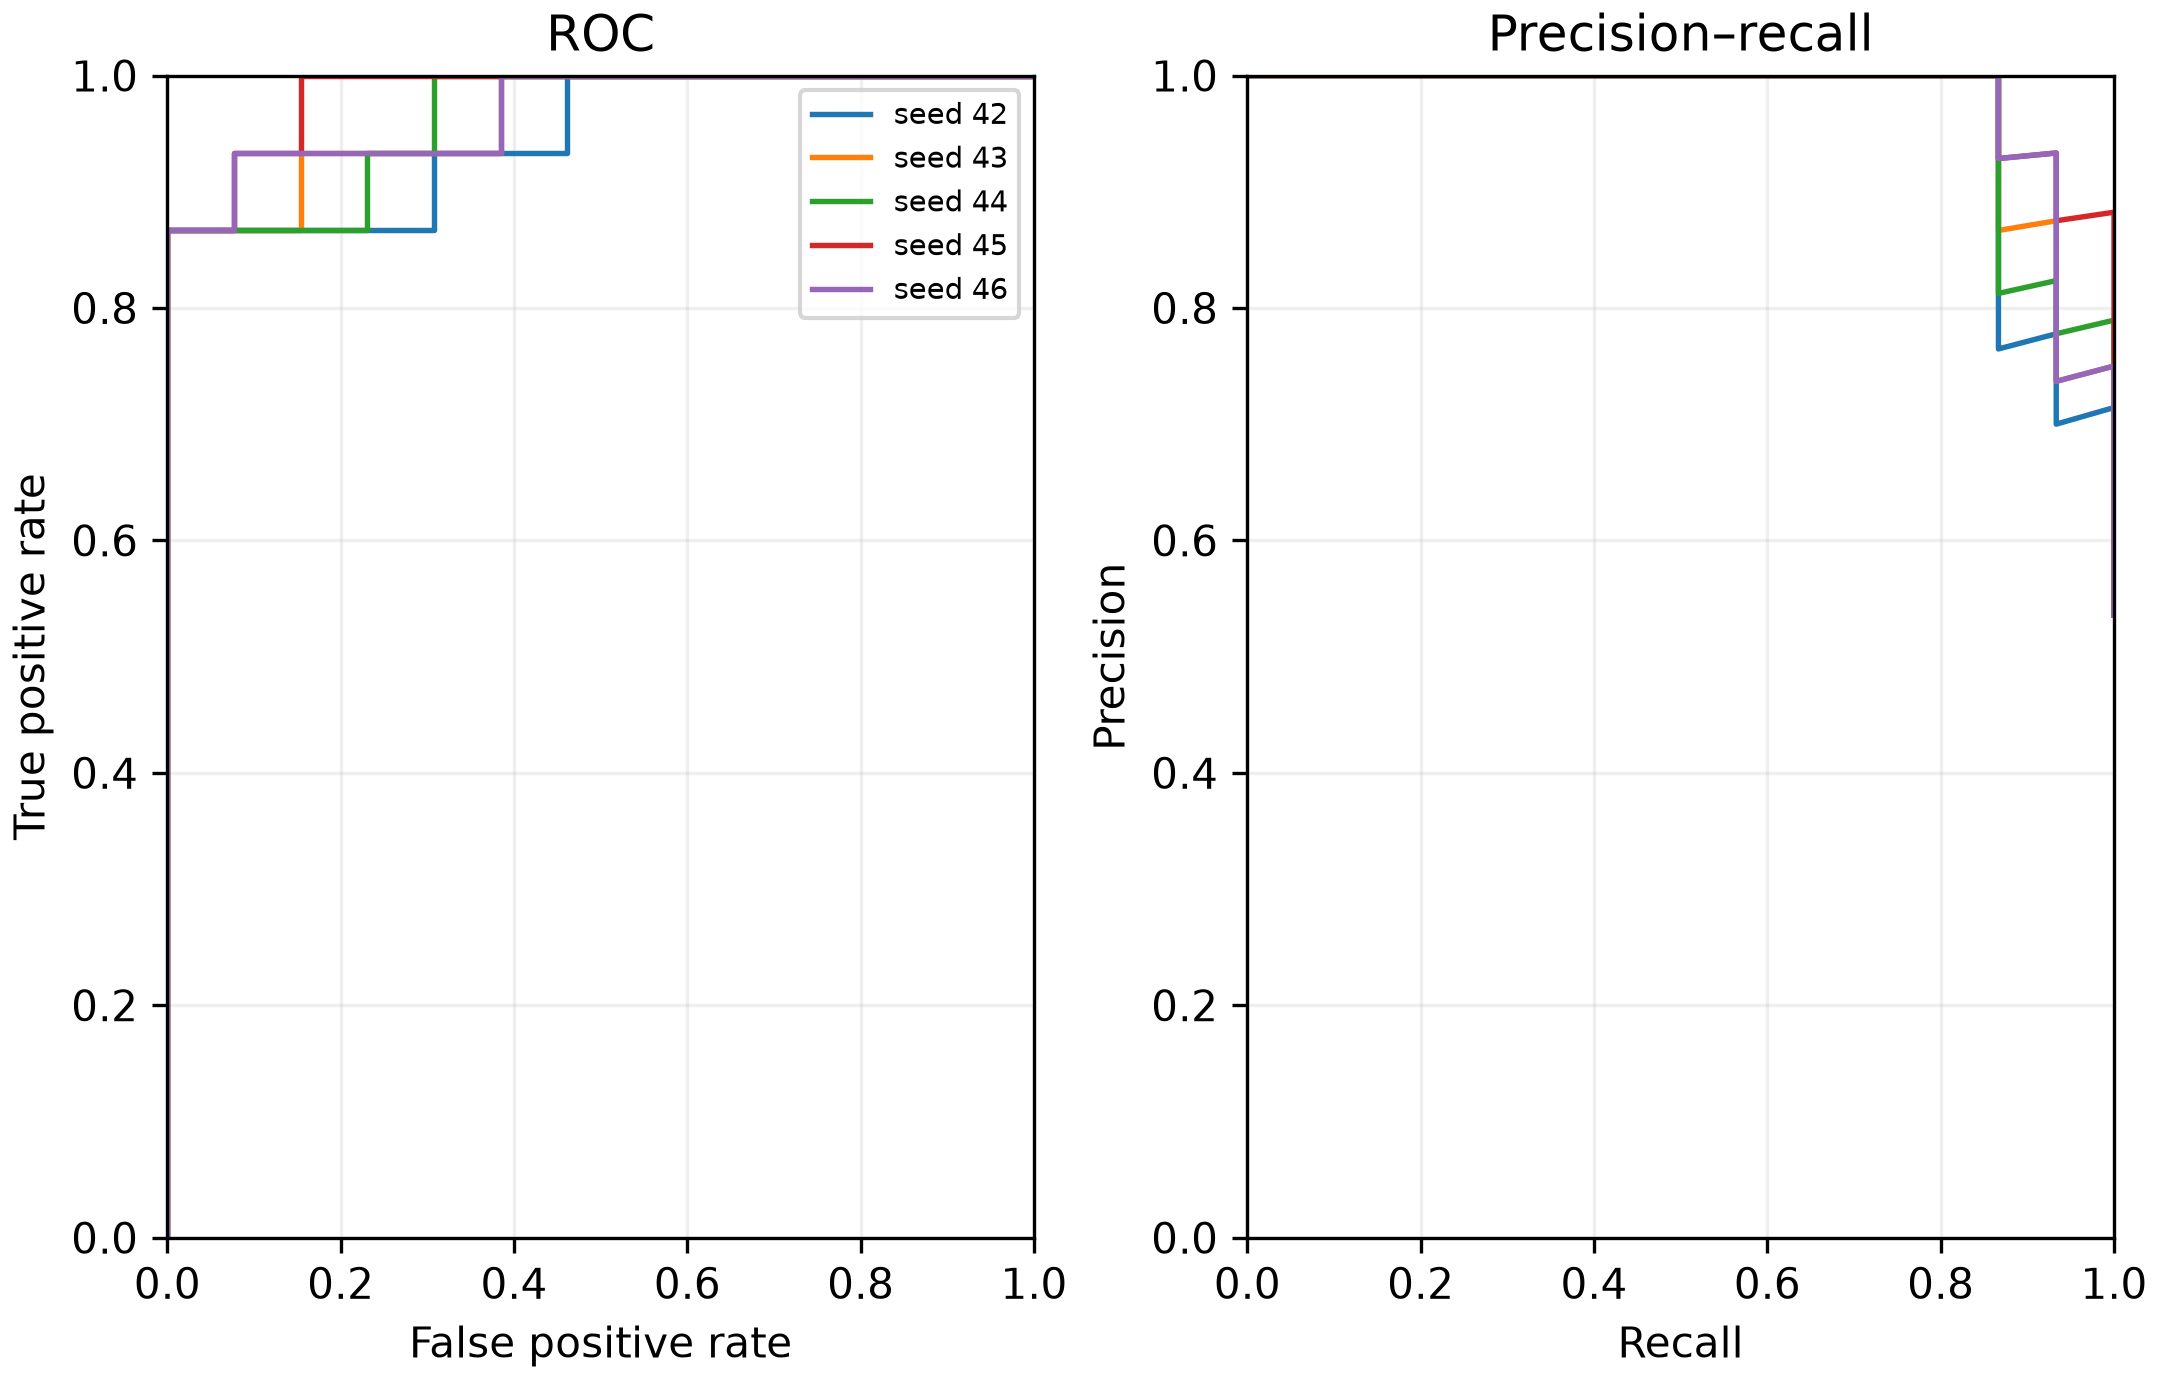

### Fig08 Intelligibility Probability

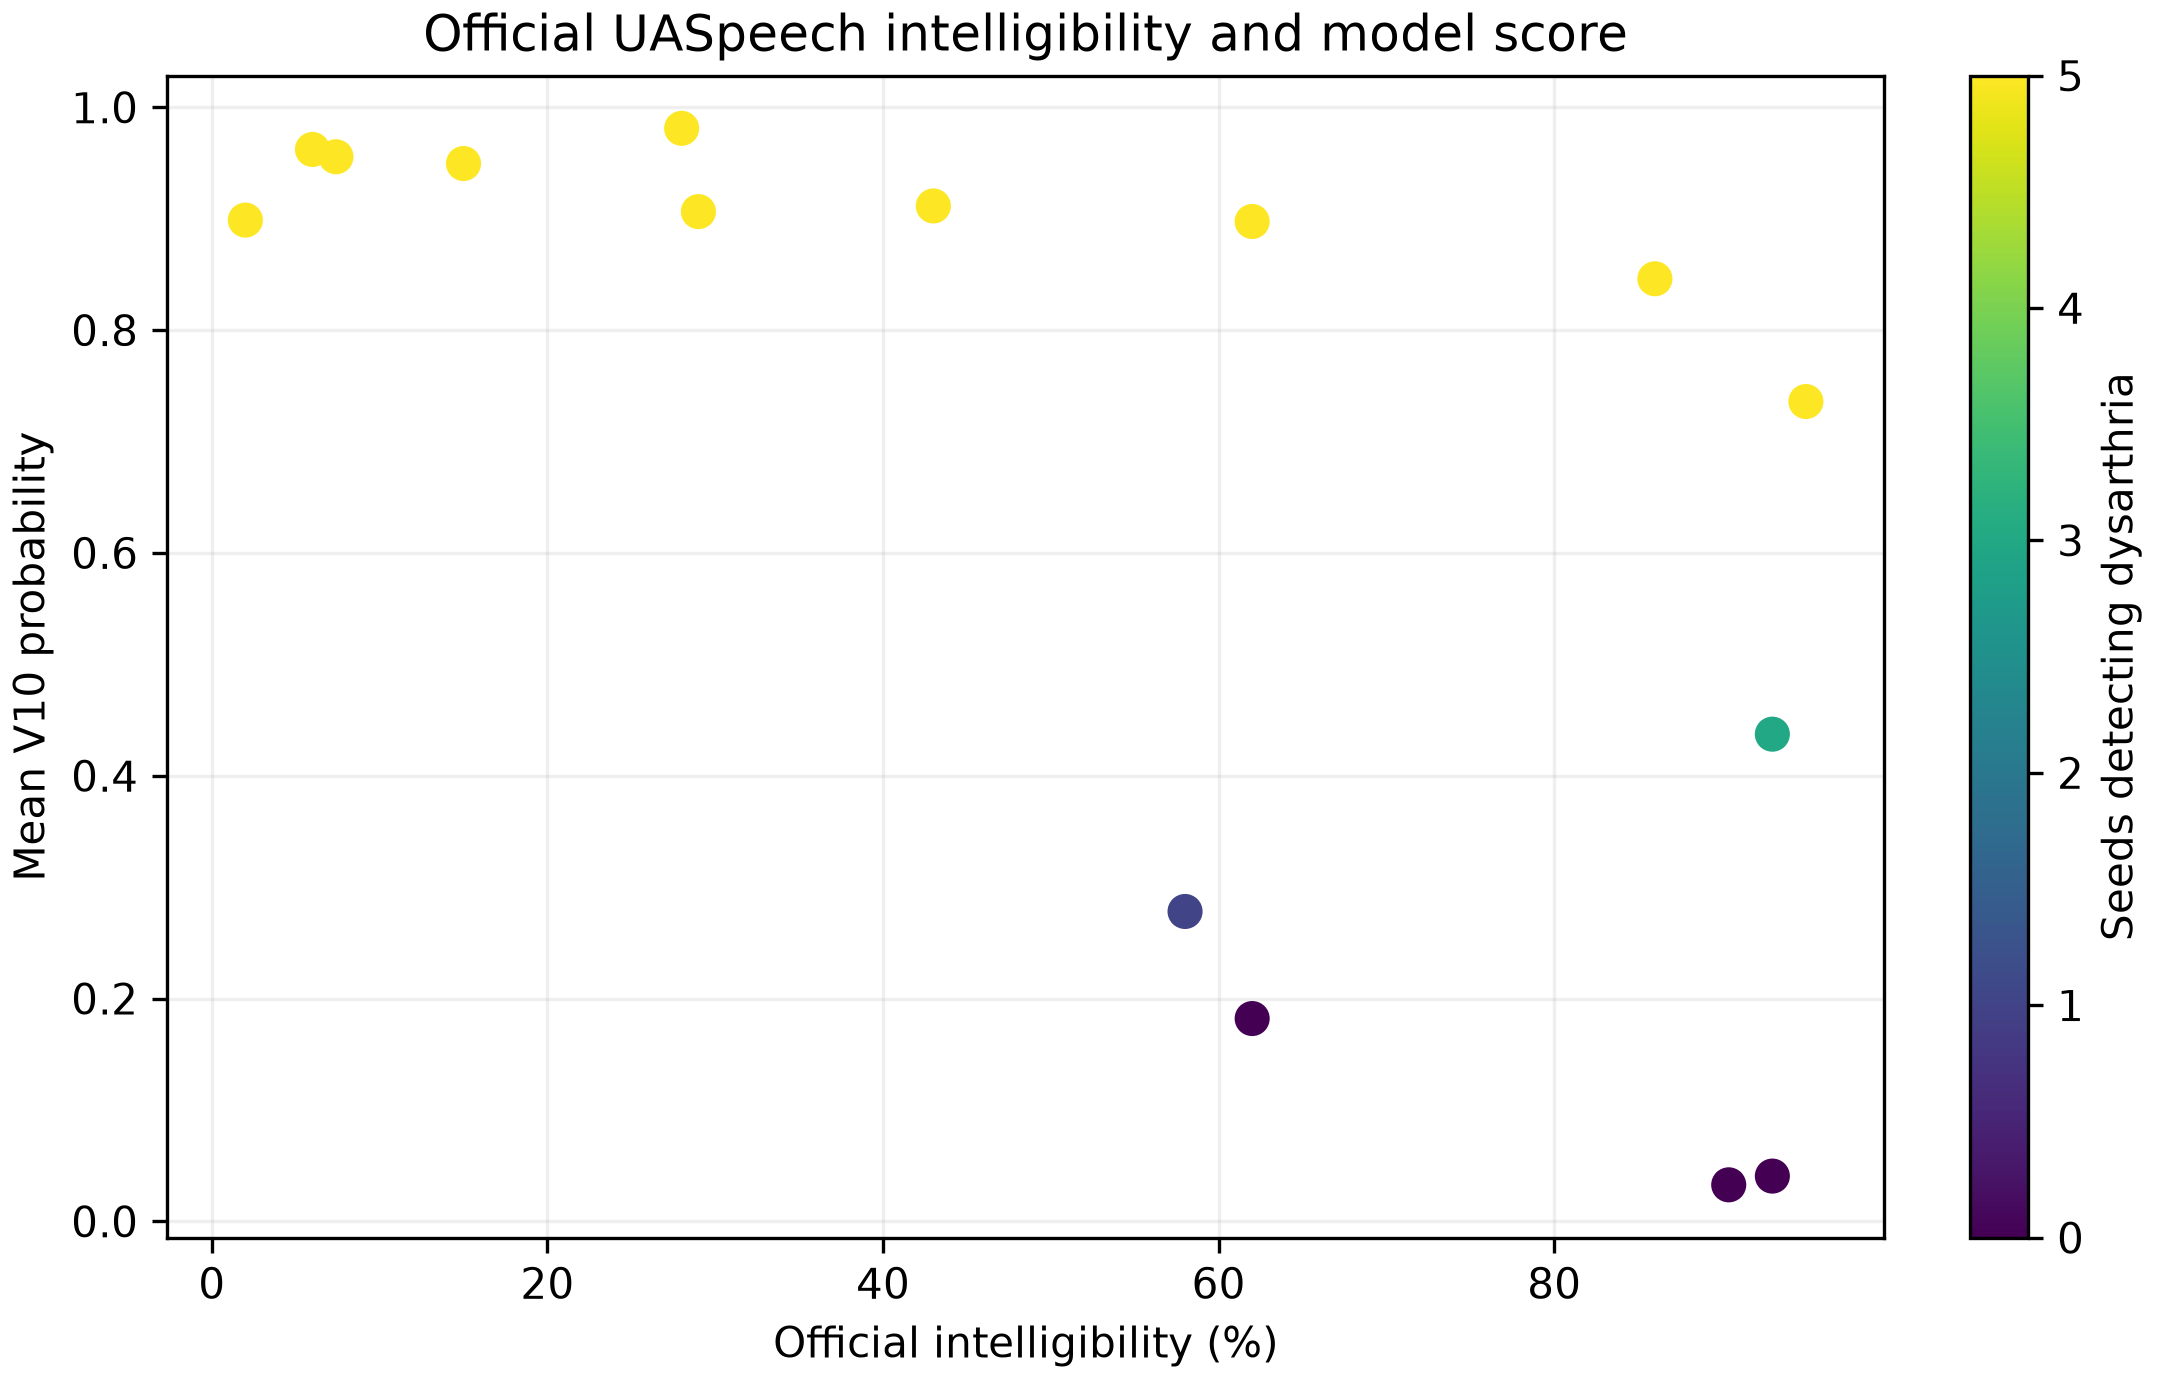

### Fig09 Intelligibility Sensitivity

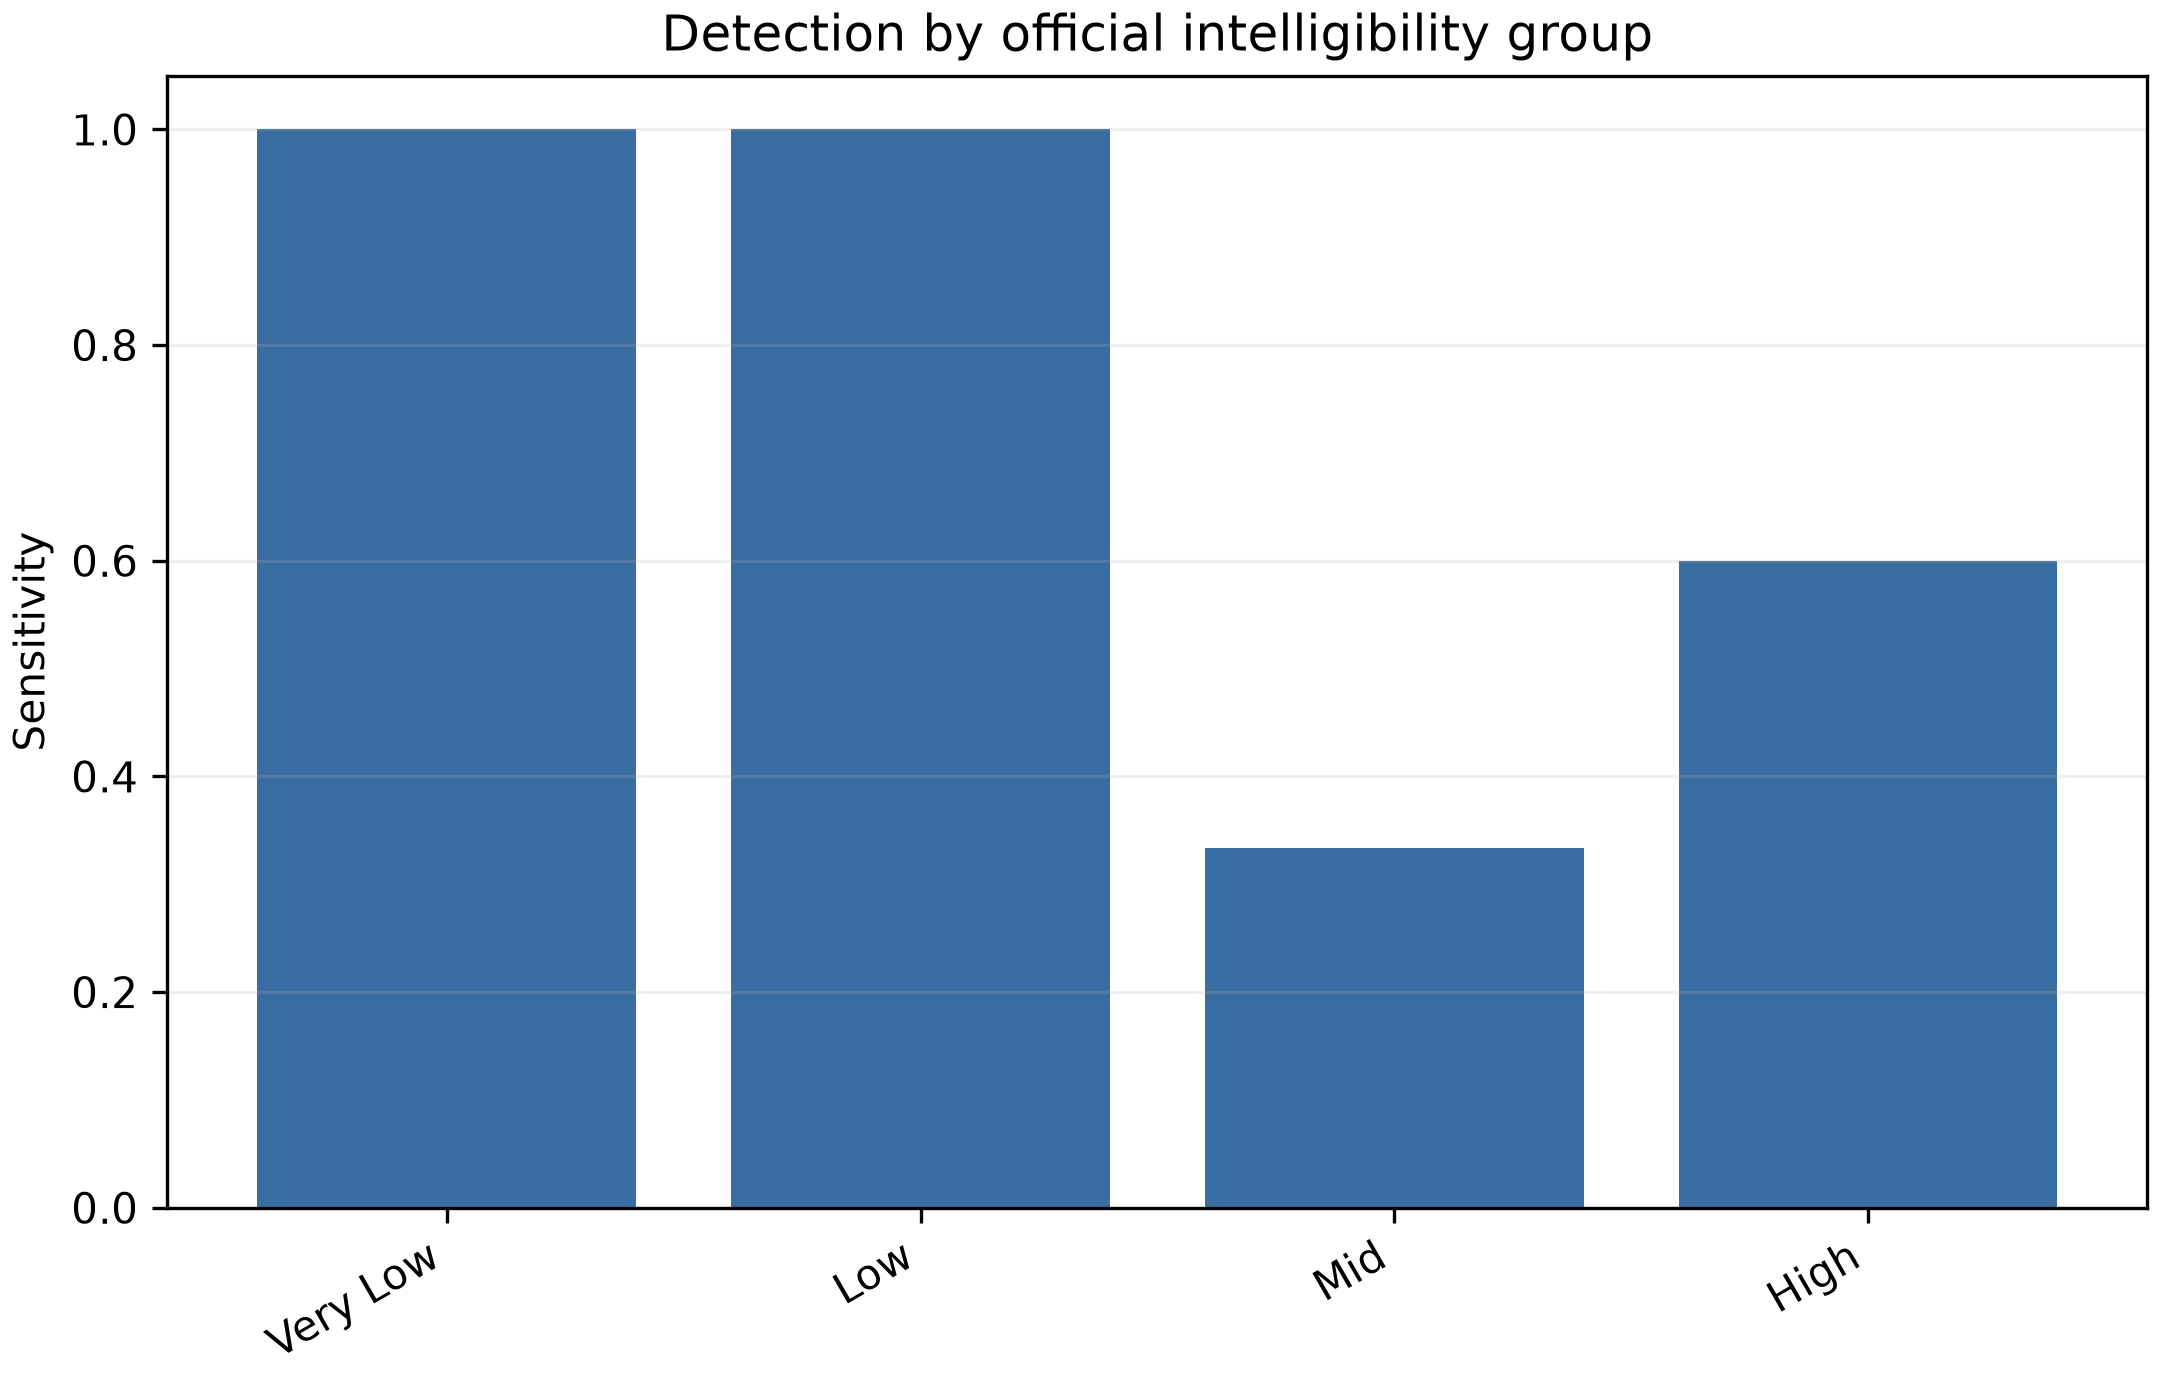

### Fig10 Utterance Budget

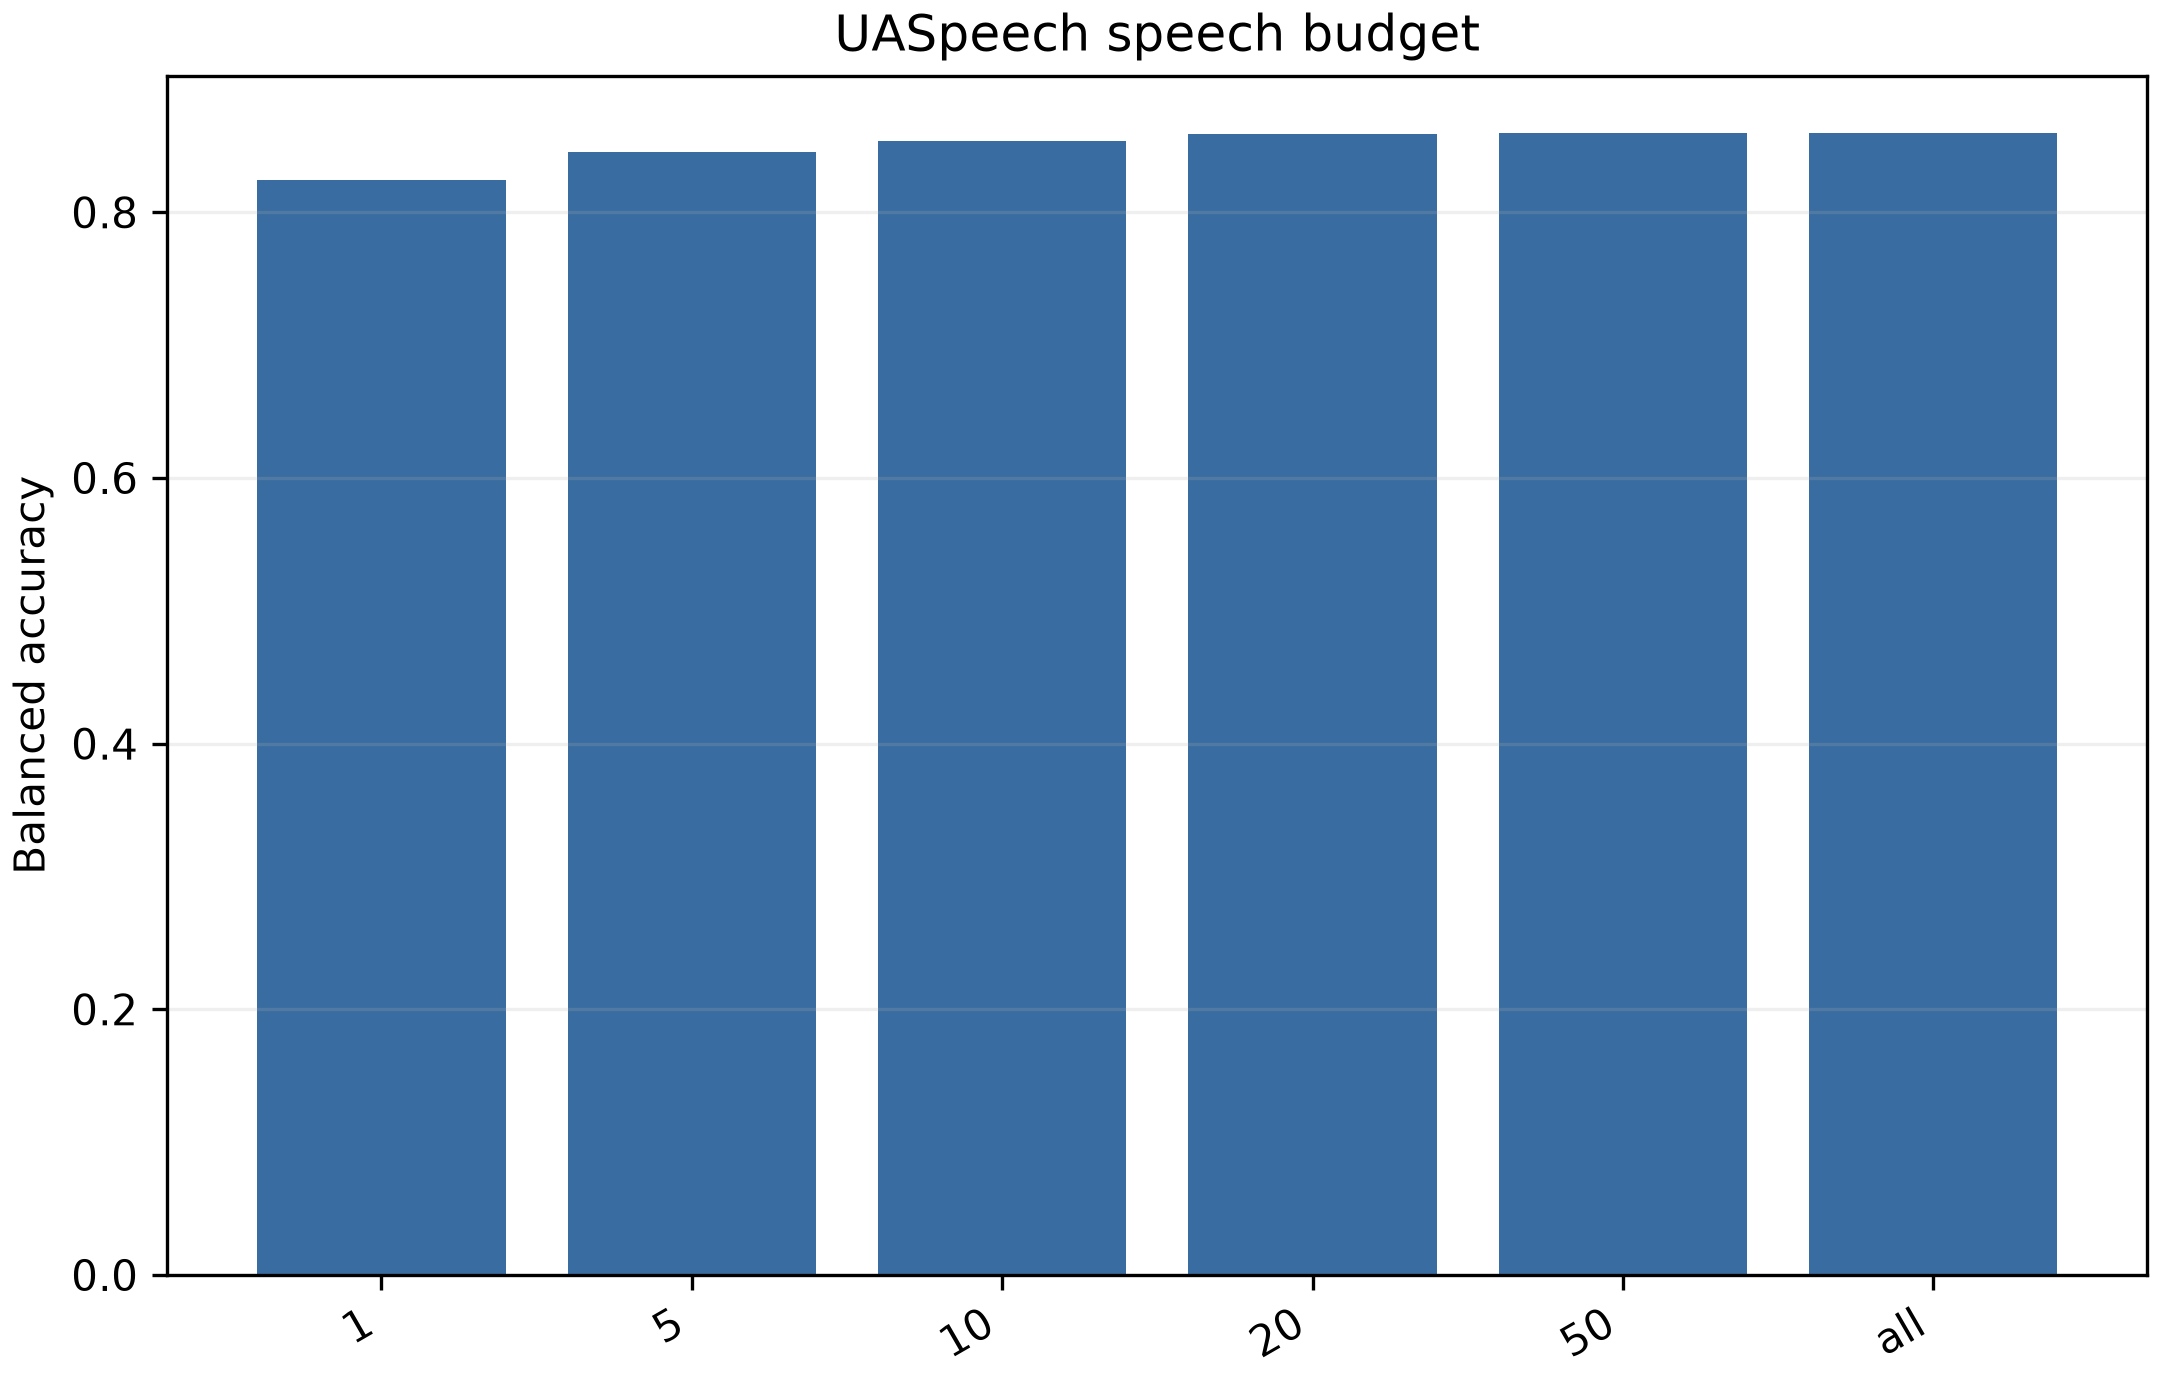

### Fig11 Channel Robustness

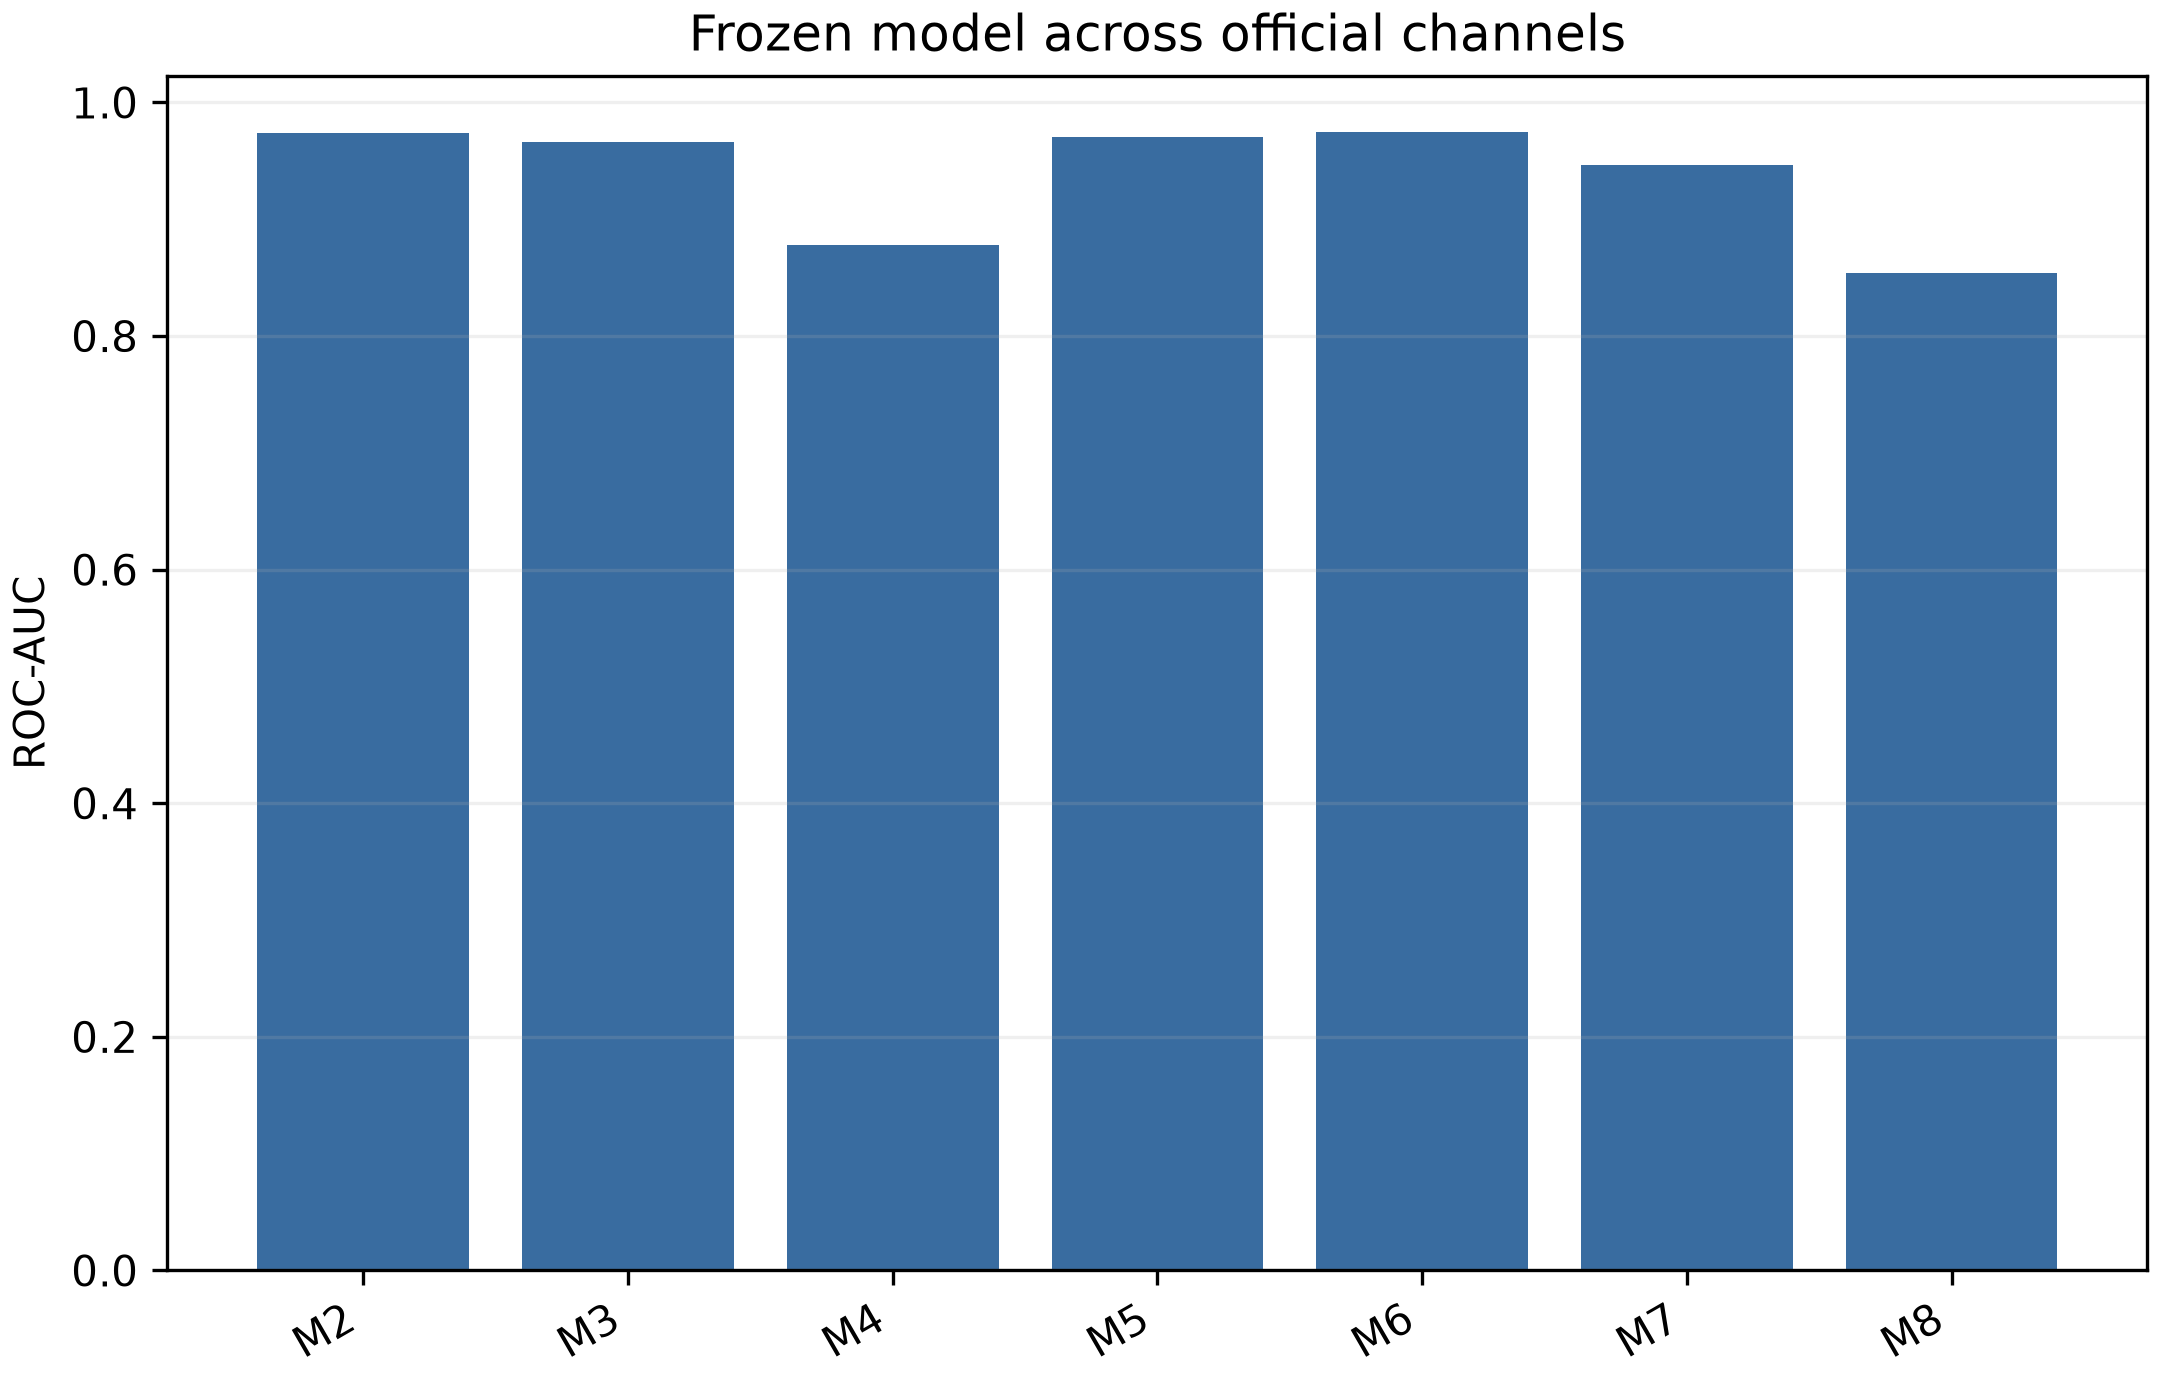

### Fig12 Speaker Error Heatmap

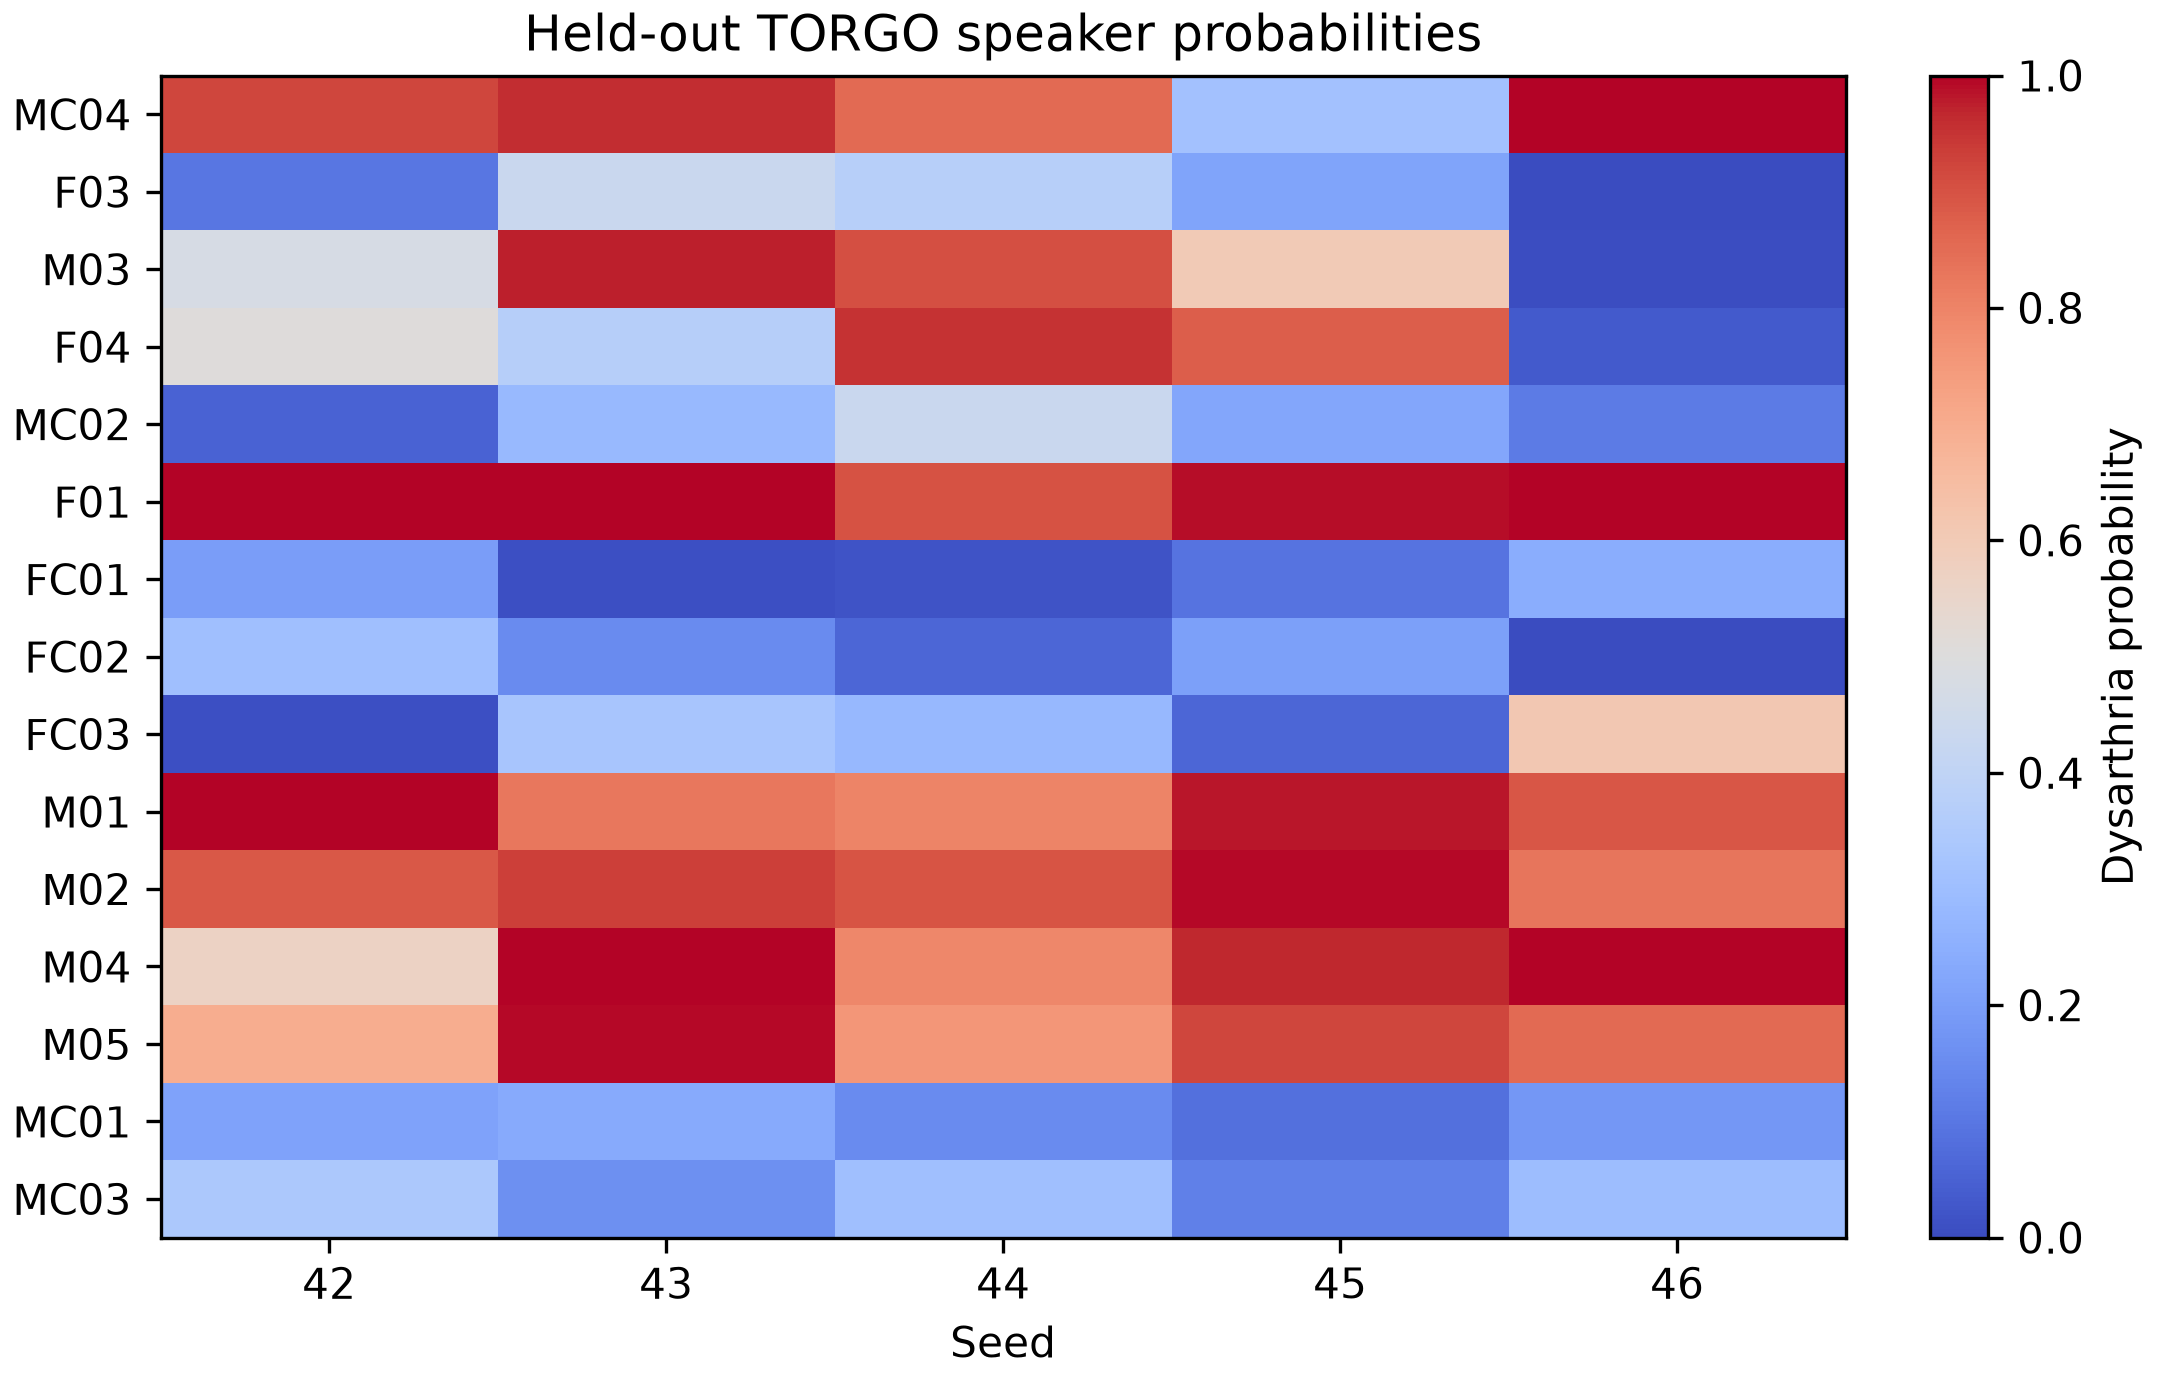

### Fig13 Confound Diagnostics

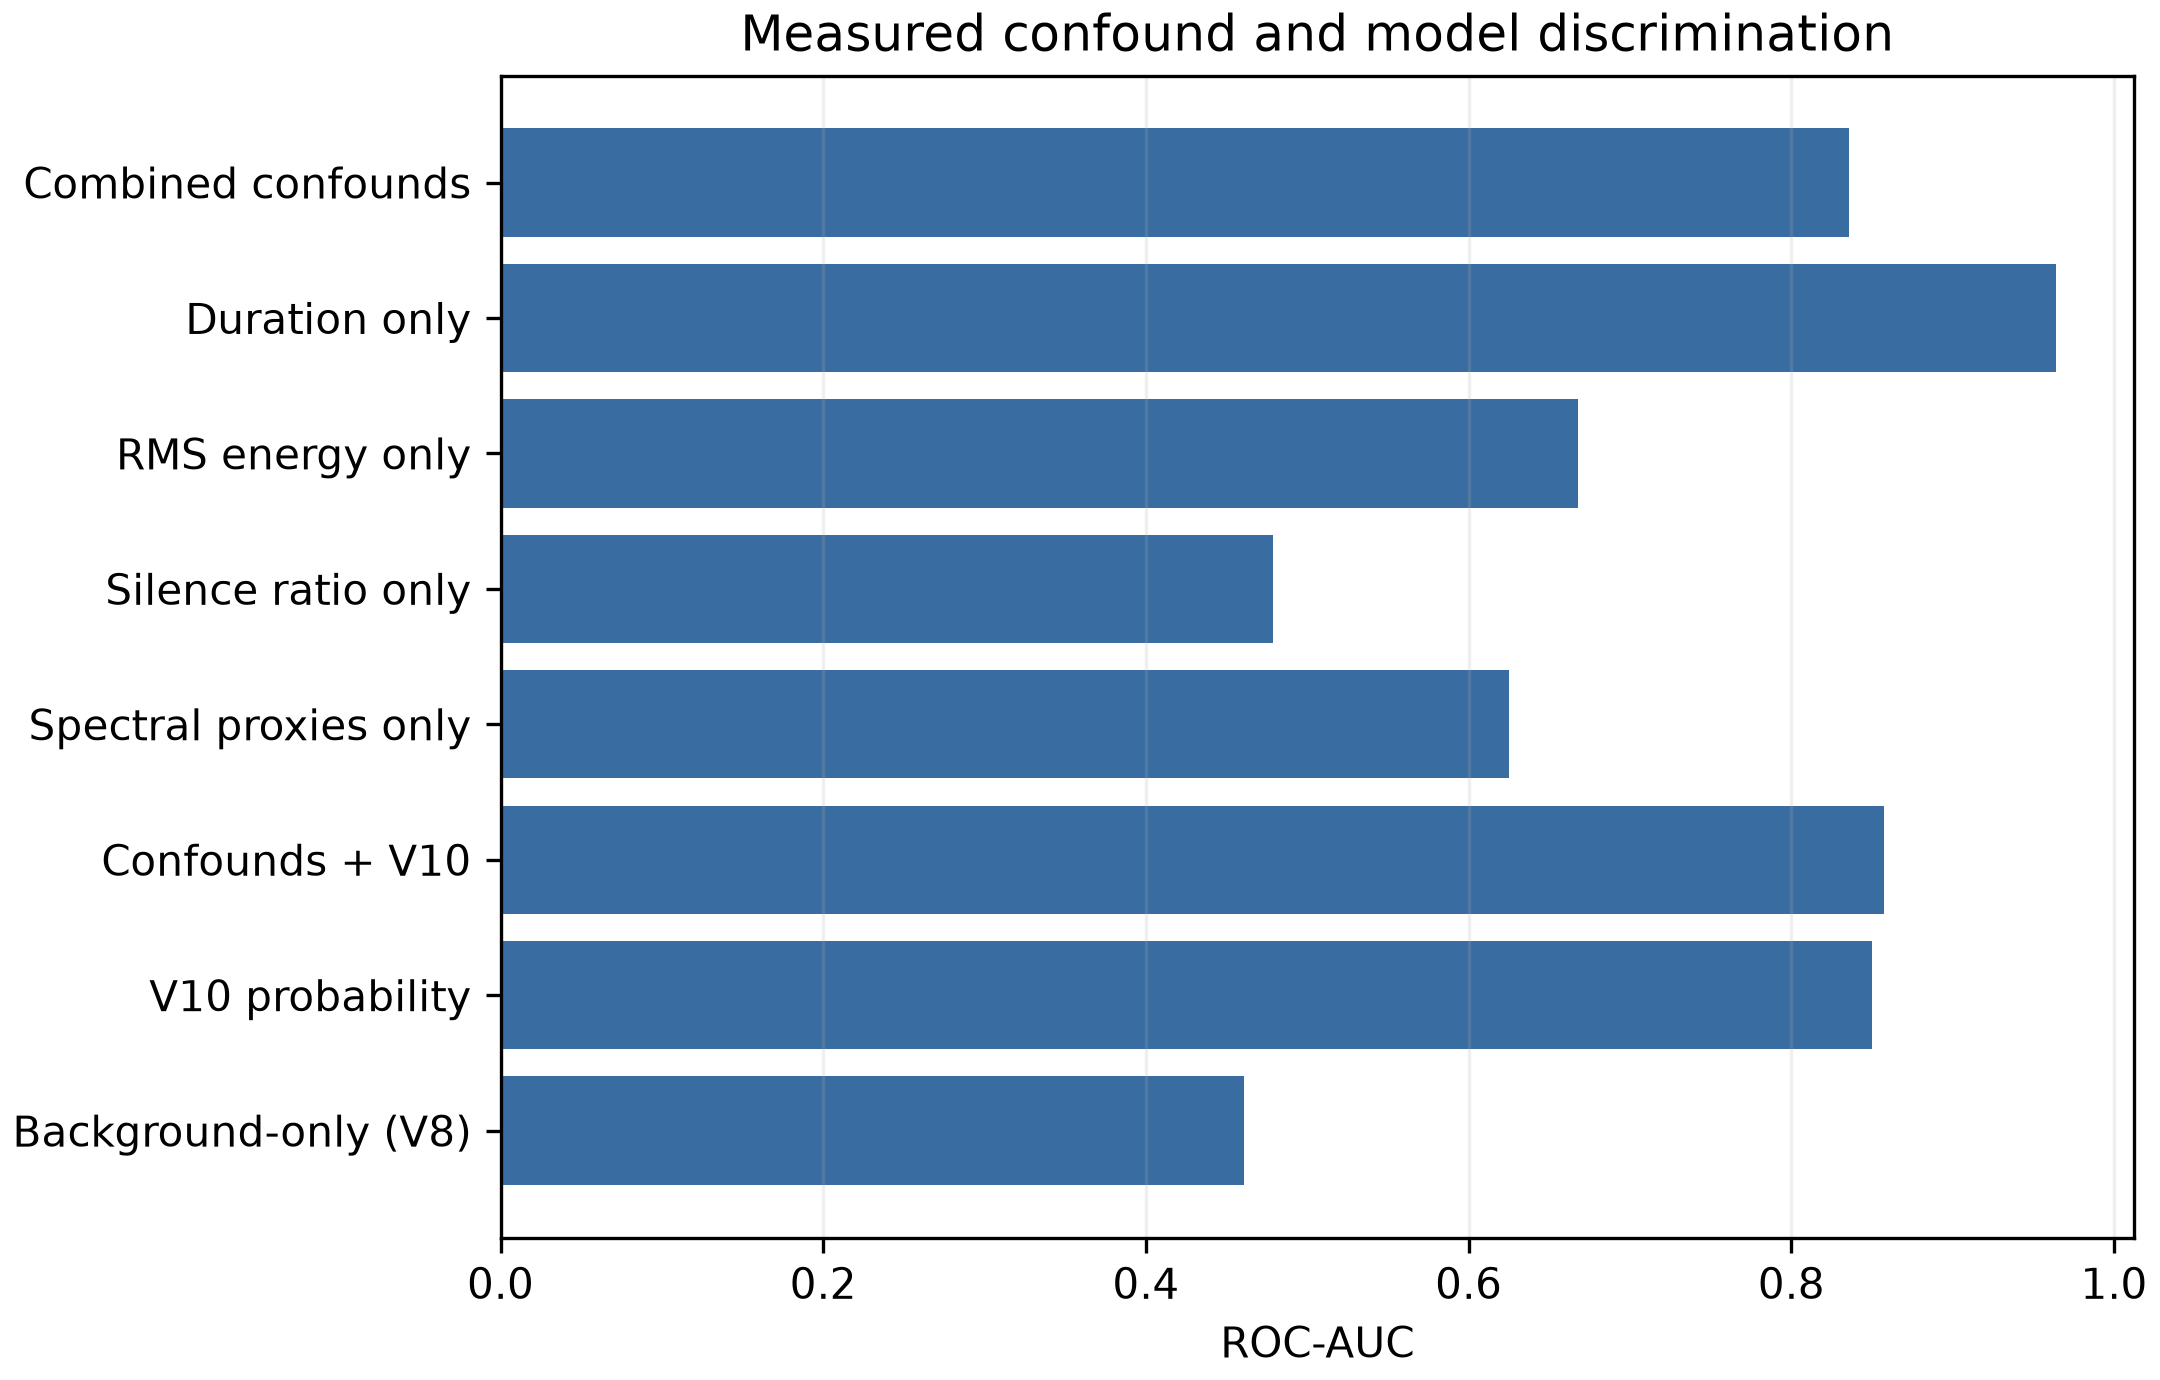

### Fig14 Calibration

The previous gallery preview is superseded by the checked V10.2 calibration figure above. Its PNG, vector PDF, and source CSV are saved by the preceding code cell.

### Fig15 Attention Diagnostics

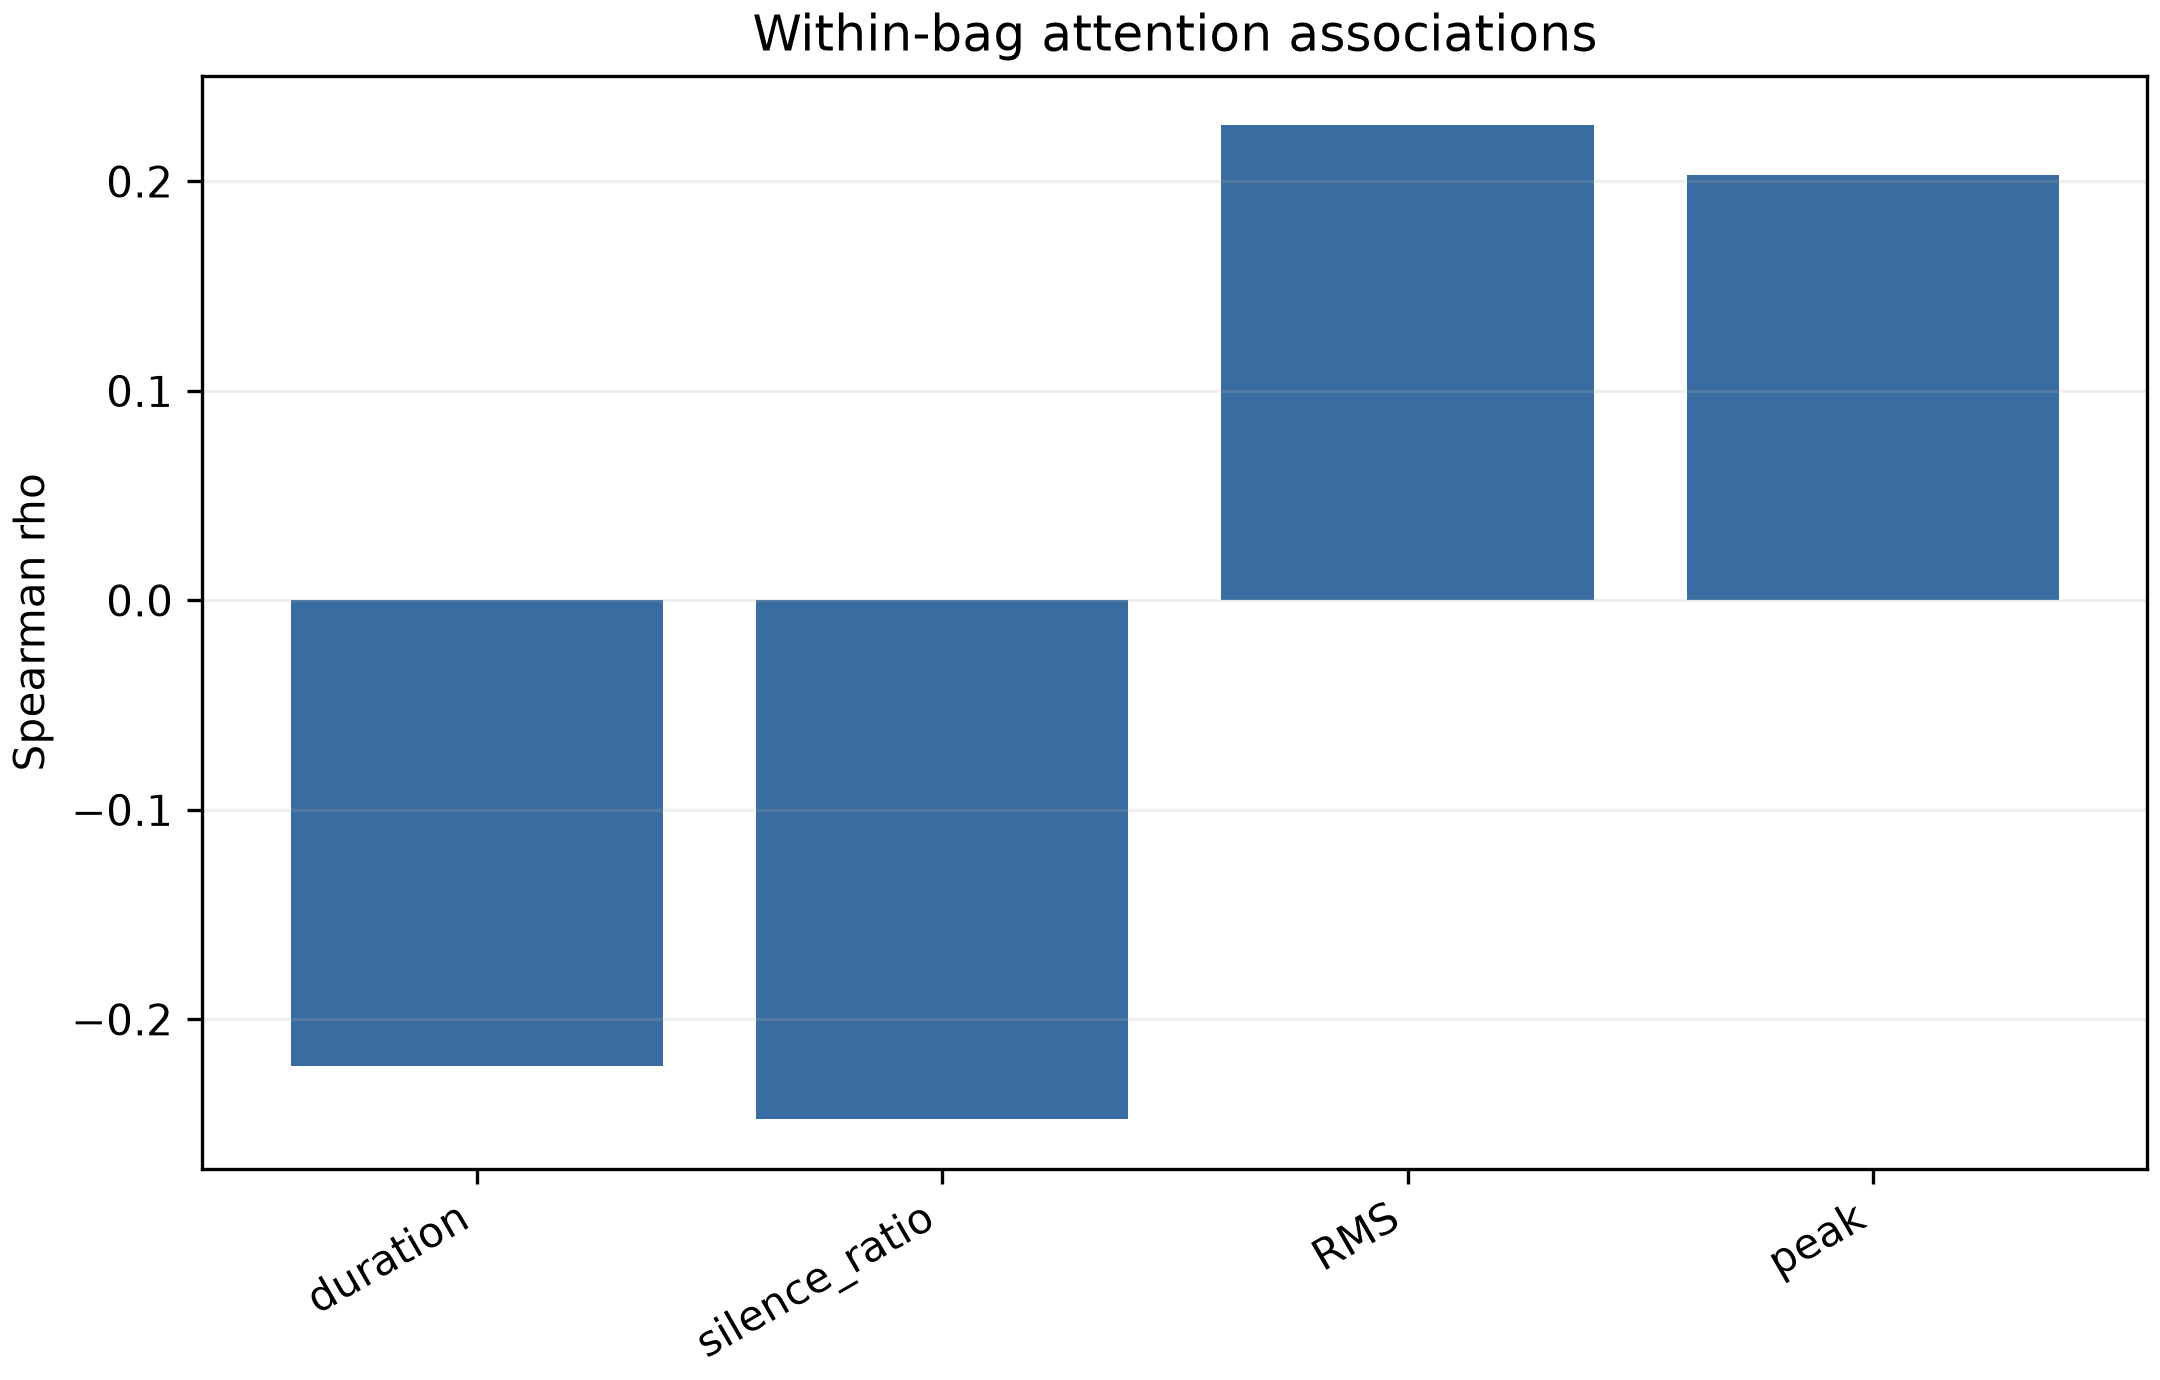

## Saved V10 paper tables

V10.2 recalculates the superseded primary and confound tables above.

### Master V8 V9 V10 Comparison

| Version | Main methodology | Accuracy | Balanced_Accuracy | Sensitivity | Specificity | F1 | ROC_AUC | PR_AUC | External validation status | External ROC-AUC | Main limitation |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| V8 | Variable-length V8 frozen WavLM speaker attention | 0.8533333333333333 | 0.8535714285714286 | 0.85 | 0.8571428571428571 | 0.8543277310924371 | 0.85 | 0.8835981379731381 | locked official UASpeech M3 complete | 0.9661538461538464 | Measured duration/artifact confounds |
| V9 | Fixed 1 s active-speech segments, K=20 deployment | 0.5866666666666667 | 0.5642857142857143 | 0.9 | 0.2285714285714285 | 0.7005339435545385 | 0.725 | 0.8350924075924077 | official M3 non-estimable under K=20 |  | Reduced TORGO performance and excluded external cohort |
| V10 | Fresh V8-reference retraining plus diagnostics and locked validation | 0.8533333333333333 | 0.8535714285714286 | 0.85 | 0.8571428571428571 | 0.8543277310924371 | 0.85 | 0.8835981379731381 | locked official UASpeech M3 complete | 0.9661538461538464 | Small speaker cohorts; confounding remains |


### Table02 V8 Vs V10

| Version | Main methodology | Accuracy | Balanced_Accuracy | Sensitivity | Specificity | F1 | ROC_AUC | PR_AUC | External validation status | External ROC-AUC | Main limitation |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| V8 | Variable-length V8 frozen WavLM speaker attention | 0.8533333333333333 | 0.8535714285714286 | 0.85 | 0.8571428571428571 | 0.8543277310924371 | 0.85 | 0.8835981379731381 | locked official UASpeech M3 complete | 0.9661538461538464 | Measured duration/artifact confounds |
| V10 | Fresh V8-reference retraining plus diagnostics and locked validation | 0.8533333333333333 | 0.8535714285714286 | 0.85 | 0.8571428571428571 | 0.8543277310924371 | 0.85 | 0.8835981379731381 | locked official UASpeech M3 complete | 0.9661538461538464 | Small speaker cohorts; confounding remains |


### Table03 Simple Baselines

| model | metric | mean | sd_across_repeated_seeds | speaker_bootstrap_lower_95 | speaker_bootstrap_upper_95 | n_speakers | n_seeds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| MFCC Logistic Regression | Accuracy | 0.6933333333333332 | 0.059628479399994376 | 0.5066666666666666 | 0.8666666666666666 | 15 | 5 |
| MFCC Logistic Regression | Balanced_Accuracy | 0.6875000000000001 | 0.060556517706475625 | 0.4963392857142857 | 0.8571875000000001 | 15 | 5 |
| MFCC Logistic Regression | Sensitivity | 0.775 | 0.13693063937629152 | 0.55 | 0.975 | 15 | 5 |
| MFCC Logistic Regression | Specificity | 0.6 | 0.15649215928719035 | 0.28500000000000003 | 0.8571428571428571 | 15 | 5 |
| MFCC Logistic Regression | Precision | 0.6961904761904762 | 0.06372328927771921 | 0.5213359418359418 | 0.9008547008547009 | 15 | 5 |
| MFCC Logistic Regression | NPV | 0.7307142857142858 | 0.15915112827954772 | 0.5065 | 0.9714285714285713 | 15 | 5 |
| MFCC Logistic Regression | F1 | 0.7266666666666667 | 0.058452259722500635 | 0.539572192513369 | 0.8816553209002899 | 15 | 5 |
| MFCC Logistic Regression | Macro_F1 | 0.6828571428571428 | 0.06188529913826961 | 0.4762918660287081 | 0.8562191051982073 | 15 | 5 |
| MFCC Logistic Regression | ROC_AUC | 0.8571428571428571 | 0.0455269599427927 | 0.6678571428571428 | 0.9857142857142858 | 15 | 5 |
| MFCC Logistic Regression | PR_AUC | 0.8963528138528138 | 0.026302338706077212 | 0.7763663628038627 | 0.990407986111111 | 15 | 5 |
| MFCC Logistic Regression | Brier | 0.17753131501521152 | 0.03654893473436876 | 0.06454579620894307 | 0.2916440997262467 | 15 | 5 |
| MFCC Logistic Regression | ECE | 0.2069044431657412 | 0.05227564295320652 | 0.11641478880635961 | 0.3708449607947354 | 15 | 5 |
| MFCC RBF SVM | Accuracy | 0.5066666666666666 | 0.036514837167011066 | 0.44000000000000006 | 0.5599999999999999 | 15 | 5 |
| MFCC RBF SVM | Balanced_Accuracy | 0.47857142857142854 | 0.033763697144980426 | 0.41607142857142854 | 0.5321428571428571 | 15 | 5 |
| MFCC RBF SVM | Sensitivity | 0.9 | 0.10458250331675945 | 0.8 | 0.975 | 15 | 5 |
| MFCC RBF SVM | Specificity | 0.05714285714285714 | 0.07824607964359516 | 0.0 | 0.14285714285714285 | 15 | 5 |
| MFCC RBF SVM | Precision | 0.521025641025641 | 0.01930753907386327 | 0.47836829836829836 | 0.5556497668997669 | 15 | 5 |
| MFCC RBF SVM | NPV | 0.16666666666666666 | 0.23570226039551587 | 0.0 | 0.4 | 15 | 5 |
| MFCC RBF SVM | F1 | 0.658866930171278 | 0.0410452734905703 | 0.5945790427154843 | 0.7046706192358366 | 15 | 5 |
| MFCC RBF SVM | Macro_F1 | 0.3716556873078612 | 0.050241311718038695 | 0.3156542542126066 | 0.4273941907634699 | 15 | 5 |
| MFCC RBF SVM | ROC_AUC | 0.5321428571428573 | 0.22353548318980132 | 0.3820982142857143 | 0.6786160714285714 | 15 | 5 |
| MFCC RBF SVM | PR_AUC | 0.6583982683982683 | 0.14665582549706419 | 0.5804130019286269 | 0.7899123636779888 | 15 | 5 |
| MFCC RBF SVM | Brier | 0.27893231518368317 | 0.09643029391454135 | 0.2409596687931646 | 0.323020045675245 | 15 | 5 |
| MFCC RBF SVM | ECE | 0.23806321270637767 | 0.15574286043481894 | 0.2313846997818097 | 0.38765356722806504 | 15 | 5 |
| WavLM Final Layer Logistic Regression | Accuracy | 0.72 | 0.0730296743340222 | 0.5333333333333333 | 0.8933333333333333 | 15 | 5 |
| WavLM Final Layer Logistic Regression | Balanced_Accuracy | 0.7125 | 0.0750743678913497 | 0.5195535714285715 | 0.8875000000000002 | 15 | 5 |
| WavLM Final Layer Logistic Regression | Sensitivity | 0.825 | 0.06846531968814576 | 0.575 | 0.975 | 15 | 5 |
| WavLM Final Layer Logistic Regression | Specificity | 0.6 | 0.11952286093343939 | 0.2571428571428571 | 0.8857142857142858 | 15 | 5 |
| WavLM Final Layer Logistic Regression | Precision | 0.705050505050505 | 0.06753339252705771 | 0.5501136363636364 | 0.9055555555555556 | 15 | 5 |
| WavLM Final Layer Logistic Regression | NPV | 0.75 | 0.08333333333333337 | 0.46575649350649345 | 0.9667857142857142 | 15 | 5 |
| WavLM Final Layer Logistic Regression | F1 | 0.7591331269349846 | 0.060128908415158916 | 0.5926353936311367 | 0.9038624871001031 | 15 | 5 |
| WavLM Final Layer Logistic Regression | Macro_F1 | 0.7110350949360239 | 0.07831401827553351 | 0.49729930887825624 | 0.8894281028568954 | 15 | 5 |
| WavLM Final Layer Logistic Regression | ROC_AUC | 0.9071428571428571 | 0.05841224012070046 | 0.7571428571428571 | 1.0 | 15 | 5 |
| WavLM Final Layer Logistic Regression | PR_AUC | 0.9273457792207793 | 0.04370629098401037 | 0.8334023268398268 | 1.0 | 15 | 5 |
| WavLM Final Layer Logistic Regression | Brier | 0.1703940847769855 | 0.07278126750949641 | 0.041682445990827766 | 0.318411366224404 | 15 | 5 |
| WavLM Final Layer Logistic Regression | ECE | 0.18650489203076906 | 0.0716893254035697 | 0.07136471009150437 | 0.348225339653086 | 15 | 5 |


### Table04 Controlled Ablations

| model | metric | mean | sd | lower_95 | upper_95 |
| --- | --- | --- | --- | --- | --- |
| WavLM Last Layer + Mean Pooling | Accuracy | 0.8266666666666668 | 0.1011050059206873 | 0.6796666666666666 | 0.9466666666666668 |
| WavLM Last Layer + Mean Pooling | Balanced_Accuracy | 0.8285714285714285 | 0.1006990869990834 | 0.6839285714285716 | 0.9446428571428572 |
| WavLM Last Layer + Mean Pooling | Sensitivity | 0.8 | 0.1118033988749894 | 0.55 | 1.0 |
| WavLM Last Layer + Mean Pooling | Specificity | 0.8571428571428571 | 0.101015254455221 | 0.7142857142857142 | 1.0 |
| WavLM Last Layer + Mean Pooling | F1_dysarthric | 0.8300000000000001 | 0.1028415717931658 | 0.6428571428571429 | 0.9482352941176472 |
| WavLM Last Layer + Mean Pooling | ROC_AUC | 0.85 | 0.1090602248900176 | 0.6641964285714286 | 1.0 |
| WavLM Last Layer + Mean Pooling | PR_AUC | 0.9144711538461536 | 0.0553364929505443 | 0.8084333409645911 | 1.0 |
| WavLM Last Layer + Mean Pooling | Brier | 0.1577356778382823 | 0.0931612610907551 | 0.0492135795876642 | 0.2911834409486485 |
| WavLM Last Layer + Mean Pooling | ECE | 0.2165347897899695 | 0.0738315247741701 | 0.1038192867293435 | 0.3710754110296177 |
| WavLM Last Layer + Attention | Accuracy | 0.8266666666666668 | 0.0596284793999944 | 0.6533333333333334 | 0.96 |
| WavLM Last Layer + Attention | Balanced_Accuracy | 0.825 | 0.0556157553657051 | 0.6517857142857143 | 0.9571428571428572 |
| WavLM Last Layer + Attention | Sensitivity | 0.85 | 0.1369306393762915 | 0.65 | 1.0 |
| WavLM Last Layer + Attention | Specificity | 0.8 | 0.0782460796435951 | 0.5142857142857142 | 1.0 |
| WavLM Last Layer + Attention | F1_dysarthric | 0.8353408029878618 | 0.0721230628548701 | 0.6670886591478697 | 0.9556582633053216 |
| WavLM Last Layer + Attention | ROC_AUC | 0.8214285714285715 | 0.1191220005725565 | 0.6107142857142857 | 0.9785714285714286 |
| WavLM Last Layer + Attention | PR_AUC | 0.855113775113775 | 0.0807635708117845 | 0.7078009334415584 | 0.9892857142857142 |
| WavLM Last Layer + Attention | Brier | 0.181296122786071 | 0.0745080425265261 | 0.066900899681285 | 0.3290902014847786 |
| WavLM Last Layer + Attention | ECE | 0.2818666163727646 | 0.0680583416207596 | 0.1833832308322802 | 0.432448524831459 |
| WavLM Last-4 Mix + Mean Pooling | Accuracy | 0.8266666666666668 | 0.1011050059206873 | 0.6533333333333333 | 0.96 |
| WavLM Last-4 Mix + Mean Pooling | Balanced_Accuracy | 0.8267857142857142 | 0.1013304354222221 | 0.6589285714285714 | 0.9589285714285716 |
| WavLM Last-4 Mix + Mean Pooling | Sensitivity | 0.825 | 0.1118033988749894 | 0.575 | 1.0 |
| WavLM Last-4 Mix + Mean Pooling | Specificity | 0.8285714285714286 | 0.1195228609334393 | 0.5999999999999999 | 1.0 |
| WavLM Last-4 Mix + Mean Pooling | F1_dysarthric | 0.8347058823529412 | 0.1016571411953775 | 0.6521318681318681 | 0.96 |
| WavLM Last-4 Mix + Mean Pooling | ROC_AUC | 0.8892857142857142 | 0.0293422798663481 | 0.6927678571428572 | 1.0 |
| WavLM Last-4 Mix + Mean Pooling | PR_AUC | 0.9366891441891442 | 0.0280558956924575 | 0.8350108225108225 | 1.0 |
| WavLM Last-4 Mix + Mean Pooling | Brier | 0.1401020159856355 | 0.0881176421419551 | 0.0434882249756568 | 0.2713538676943522 |
| WavLM Last-4 Mix + Mean Pooling | ECE | 0.1971470856260199 | 0.0859509778409809 | 0.0961267478737131 | 0.348279990031207 |
| WavLM Last-4 Mix + Attention (V8 Reference) | Accuracy | 0.8533333333333333 | 0.0869226987360353 | 0.7066666666666668 | 0.9600000000000002 |
| WavLM Last-4 Mix + Attention (V8 Reference) | Balanced_Accuracy | 0.8535714285714286 | 0.0814900300650331 | 0.7142410714285713 | 0.9625 |
| WavLM Last-4 Mix + Attention (V8 Reference) | Sensitivity | 0.85 | 0.1629800601300662 | 0.699375 | 1.0 |
| WavLM Last-4 Mix + Attention (V8 Reference) | Specificity | 0.8571428571428571 | 0.0 | 0.6285714285714284 | 1.0 |
| WavLM Last-4 Mix + Attention (V8 Reference) | F1_dysarthric | 0.8543277310924371 | 0.0975653865911871 | 0.7071738539238539 | 0.9596638655462184 |
| WavLM Last-4 Mix + Attention (V8 Reference) | ROC_AUC | 0.85 | 0.1363472083487219 | 0.6785714285714286 | 0.975 |
| WavLM Last-4 Mix + Attention (V8 Reference) | PR_AUC | 0.8835981379731379 | 0.0893203167445013 | 0.7670923520923522 | 0.9883333333333332 |
| WavLM Last-4 Mix + Attention (V8 Reference) | Brier | 0.1598426402835892 | 0.090497561855737 | 0.0633621779786447 | 0.2846073522837334 |
| WavLM Last-4 Mix + Attention (V8 Reference) | ECE | 0.2300014902094673 | 0.1159135439527779 | 0.15877378295849 | 0.3783267716919026 |
| V10 mean only | Accuracy | 0.8266666666666668 | 0.07601169500660922 | 0.7066666666666667 | 0.9466666666666667 |
| V10 mean only | Balanced_Accuracy | 0.8267857142857142 | 0.0743273406723836 | 0.7035714285714285 | 0.9428571428571428 |
| V10 mean only | Sensitivity | 0.825 | 0.14252192813739223 | 0.6 | 0.975 |
| V10 mean only | Specificity | 0.8285714285714285 | 0.11952286093343935 | 0.6571428571428571 | 0.9428571428571428 |
| V10 mean only | Precision | 0.8536507936507937 | 0.0872900425267019 | 0.753292735042735 | 0.9555555555555555 |
| V10 mean only | NPV | 0.825 | 0.1263812574008592 | 0.6876190476190476 | 0.975 |
| V10 mean only | F1 | 0.8320074696545285 | 0.08434630070541695 | 0.6719240481740482 | 0.9428571428571428 |
| V10 mean only | Macro_F1 | 0.8245934784170078 | 0.07600303506655581 | 0.6888065681738282 | 0.9444444444444444 |
| V10 mean only | ROC_AUC | 0.8821428571428571 | 0.15546999185484942 | 0.7677678571428572 | 0.9785714285714286 |
| V10 mean only | PR_AUC | 0.9210187728937729 | 0.10482651821969426 | 0.8526885822510822 | 0.9883333333333333 |
| V10 mean only | Brier | 0.14257240329914894 | 0.0951753530175131 | 0.05337410386652918 | 0.23832465828394833 |
| V10 mean only | ECE | 0.22668410332963793 | 0.10780130908080308 | 0.15737804832821928 | 0.33992322758819377 |


### Table06 Severity Speakers

| speaker_id | official_intelligibility_score | official_intelligibility_group | official_rating_verbatim | mean_probability | number_of_seeds_detected | locked_prediction | probability_seed42 | probability_seed43 | probability_seed44 | probability_seed45 | probability_seed46 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| M01 | 15.0 | Very Low | Very low (15%) | 0.9495025158262648 | 5 | 1 | 0.998377327694783 | 0.8901188817759729 | 0.9970402508809136 | 0.9339168326641276 | 0.9280592861155278 |
| M04 | 2.0 | Very Low | Very low (2%) | 0.8987297613490371 | 5 | 1 | 0.9976487818819632 | 0.8360697637794067 | 0.9964714156947166 | 0.7973116023313576 | 0.8661472430577418 |
| M05 | 58.0 | Mid | Mid (58%) | 0.2781270323325892 | 1 | 0 | 0.1617004106730601 | 0.4820014700003082 | 0.1735360395428651 | 0.1687868104109218 | 0.4046104310357906 |
| M07 | 28.0 | Low | Low (28%) | 0.9811097698083866 | 5 | 1 | 0.9991023560701248 | 0.9590624763397192 | 0.9988711422928022 | 0.9775454100989904 | 0.9709674642402966 |
| M08 | 93.0 | High | high (93%) | 0.0405981560993253 | 0 | 0 | 0.0009376757940742 | 0.1057876329818014 | 0.00209766309669 | 0.0398682098829692 | 0.0542995987410917 |
| M09 | 86.0 | High | High (86%) | 0.8460712954793005 | 5 | 1 | 0.9854623908274748 | 0.7612049389658996 | 0.9922898444348336 | 0.7147968255071727 | 0.7766024776611218 |
| M10 | 93.0 | High | high (93%) | 0.437284432048722 | 3 | 1 | 0.1532804450135491 | 0.5830934498928069 | 0.6145382532318323 | 0.3693711802200451 | 0.4661388318853768 |
| F02 | 29.0 | Low | Low (29%) | 0.906345936768766 | 5 | 1 | 0.9953119076544956 | 0.853173637959468 | 0.9935609210400153 | 0.8113750885025361 | 0.878308128687315 |
| F03 | 6.0 | Very Low | Very low (6%) | 0.9621390508142562 | 5 | 1 | 0.9986280084122712 | 0.9178057440472548 | 0.9982487324761796 | 0.9458148016220496 | 0.950197967513526 |
| F04 | 62.0 | Mid | mid (62%) | 0.1820174550717243 | 0 | 0 | 0.0932395079778587 | 0.2804380559212746 | 0.1543415806840211 | 0.1279245061599025 | 0.254143624615565 |
| F05 | 95.0 | High | high (95%) | 0.7358605917154414 | 5 | 1 | 0.9211487176067514 | 0.6651734577870309 | 0.926309754787696 | 0.5314839328145925 | 0.6351870955811362 |
| M11 | 62.0 | Mid | mid (62%) | 0.8974827246725724 | 5 | 1 | 0.9969417139304207 | 0.8146164862238258 | 0.9962636840921366 | 0.7904064781242987 | 0.8891852609921801 |
| M12 | 7.4 | Very Low | very low (7.4%) | 0.9555905596162808 | 5 | 1 | 0.9986606270392874 | 0.9157722169385568 | 0.9972375230814862 | 0.938100294061549 | 0.9281821369605242 |
| M14 | 90.4 | High | High (90.4%) | 0.032757081989555 | 0 | 0 | 0.0007676793653327 | 0.0896399759964297 | 0.0015514700884437 | 0.0351898112508718 | 0.0366364732466972 |
| M16 | 43.0 | Low | low (43%) | 0.911444274620676 | 5 | 1 | 0.9984920869888502 | 0.8478634489061531 | 0.9974357648089068 | 0.8118067425926059 | 0.9016233298068635 |


### Table07 Severity Groups

| official_intelligibility_group | n_speakers | mean_probability | median_probability | sensitivity | mean_seeds_detected | intelligibility_min | intelligibility_max | detection_rate_across_seed_speaker_pairs | number_missed |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Very Low | 4 | 0.9414904719014596 | 0.9525465377212728 | 1.0 | 5.0 | 2.0 | 15.0 | 1.0 | 0 |
| Low | 3 | 0.932966660399276 | 0.911444274620676 | 1.0 | 5.0 | 28.0 | 43.0 | 1.0 | 0 |
| Mid | 3 | 0.4525424040256287 | 0.2781270323325892 | 0.3333333333333333 | 2.0 | 58.0 | 62.0 | 0.4 | 2 |
| High | 5 | 0.4185143114664688 | 0.437284432048722 | 0.6 | 2.6 | 86.0 | 95.0 | 0.52 | 2 |


### Table08 Channels

| model | metric | mean | sd_across_repeated_seeds | speaker_bootstrap_lower_95 | speaker_bootstrap_upper_95 | n_speakers | n_seeds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| M2 | Accuracy | 0.8260869565217392 | 0.05324977701702562 | 0.7130434782608696 | 0.9219565217391302 | 23 | 5 |
| M2 | Balanced_Accuracy | 0.8 | 0.061237243569579464 | 0.6699999999999999 | 0.9102499999999997 | 23 | 5 |
| M2 | Sensitivity | 0.6 | 0.12247448713915887 | 0.34 | 0.8204999999999996 | 23 | 5 |
| M2 | Specificity | 1.0 | 0.0 | 1.0 | 1.0 | 23 | 5 |
| M2 | Precision | 1.0 | 0.0 | 1.0 | 1.0 | 23 | 5 |
| M2 | NPV | 0.7677244582043343 | 0.05244639812707957 | 0.6643358395989976 | 0.8959760338345862 | 23 | 5 |
| M2 | F1 | 0.7436974789915964 | 0.10308042374241257 | 0.4798534798534798 | 0.8992432060543515 | 23 | 5 |
| M2 | Macro_F1 | 0.8057424176567178 | 0.06865760563700542 | 0.6365479681608713 | 0.9177102126522146 | 23 | 5 |
| M2 | ROC_AUC | 0.9738461538461538 | 0.0042132504423474165 | 0.9061538461538461 | 1.0 | 23 | 5 |
| M2 | PR_AUC | 0.9688888888888888 | 0.0060858061945018235 | 0.9025331293706292 | 1.0 | 23 | 5 |
| M2 | Brier | 0.15125080360847581 | 0.024261574127935427 | 0.07154944567421398 | 0.24628495446597173 | 23 | 5 |
| M2 | ECE | 0.20118474036616538 | 0.022894416299000495 | 0.13112710344947387 | 0.29270472439067174 | 23 | 5 |
| M3 | Accuracy | 0.85 | 0.02988071523335987 | 0.7285714285714286 | 0.95 | 28 | 5 |
| M3 | Balanced_Accuracy | 0.8600000000000001 | 0.0278886675511359 | 0.7466666666666667 | 0.9533333333333334 | 28 | 5 |
| M3 | Sensitivity | 0.72 | 0.05577733510227173 | 0.49333333333333335 | 0.9066666666666666 | 28 | 5 |
| M3 | Specificity | 1.0 | 0.0 | 1.0 | 1.0 | 28 | 5 |
| M3 | Precision | 1.0 | 0.0 | 1.0 | 1.0 | 28 | 5 |
| M3 | NPV | 0.7572712418300653 | 0.03747542874786038 | 0.6332057416267942 | 0.9038095238095238 | 28 | 5 |
| M3 | F1 | 0.8362393162393161 | 0.03740036560657253 | 0.6590344438170523 | 0.9507389162561577 | 28 | 5 |
| M3 | Macro_F1 | 0.8488500993506556 | 0.03073616691535041 | 0.7166778074866309 | 0.9499726327312535 | 28 | 5 |
| M3 | ROC_AUC | 0.9661538461538463 | 0.012871692715908893 | 0.8984615384615384 | 1.0 | 28 | 5 |
| M3 | PR_AUC | 0.9763878159450915 | 0.007846675635658126 | 0.9352028044596778 | 1.0 | 28 | 5 |
| M3 | Brier | 0.13048092857058174 | 0.01957547107265941 | 0.04736922348434017 | 0.22776041443396083 | 28 | 5 |
| M3 | ECE | 0.16300726594988174 | 0.023597991037232157 | 0.09523624459281145 | 0.26395193019702407 | 28 | 5 |
| M4 | Accuracy | 0.7923076923076924 | 0.021066252211737146 | 0.6692307692307692 | 0.9076923076923077 | 26 | 5 |
| M4 | Balanced_Accuracy | 0.7923076923076924 | 0.021066252211737205 | 0.6692307692307692 | 0.9076923076923077 | 26 | 5 |
| M4 | Sensitivity | 0.5846153846153845 | 0.04213250442347435 | 0.3384615384615385 | 0.8153846153846154 | 26 | 5 |
| M4 | Specificity | 1.0 | 0.0 | 1.0 | 1.0 | 26 | 5 |
| M4 | Precision | 1.0 | 0.0 | 1.0 | 1.0 | 26 | 5 |
| M4 | NPV | 0.7070175438596491 | 0.020819863296979983 | 0.6021645021645021 | 0.845 | 26 | 5 |
| M4 | F1 | 0.7371428571428572 | 0.033906634512224566 | 0.5027863777089784 | 0.8978260869565217 | 26 | 5 |
| M4 | Macro_F1 | 0.7826843317972351 | 0.02413113302986954 | 0.6273239247852251 | 0.9067948168772757 | 26 | 5 |
| M4 | ROC_AUC | 0.8781065088757396 | 0.012963847514915198 | 0.7005325443786983 | 1.0 | 26 | 5 |
| M4 | PR_AUC | 0.9307093196658414 | 0.004052450826893321 | 0.8245856630688151 | 1.0 | 26 | 5 |
| M4 | Brier | 0.1727948796697256 | 0.02090053307586079 | 0.07806437942573917 | 0.27719882838321 | 26 | 5 |
| M4 | ECE | 0.21049093420295373 | 0.020170238179853316 | 0.11641268883744622 | 0.3149220317015825 | 26 | 5 |
| M5 | Accuracy | 0.9285714285714286 | 0.0 | 0.8214285714285714 | 1.0 | 28 | 5 |
| M5 | Balanced_Accuracy | 0.9333333333333333 | 0.0 | 0.8333333333333333 | 1.0 | 28 | 5 |
| M5 | Sensitivity | 0.8666666666666668 | 1.2412670766236366e-16 | 0.6666666666666666 | 1.0 | 28 | 5 |
| M5 | Specificity | 1.0 | 0.0 | 1.0 | 1.0 | 28 | 5 |
| M5 | Precision | 1.0 | 0.0 | 1.0 | 1.0 | 28 | 5 |
| M5 | NPV | 0.8666666666666668 | 1.2412670766236366e-16 | 0.7222222222222222 | 1.0 | 28 | 5 |
| M5 | F1 | 0.9285714285714286 | 0.0 | 0.8 | 1.0 | 28 | 5 |
| M5 | Macro_F1 | 0.9285714285714286 | 0.0 | 0.8193548387096774 | 1.0 | 28 | 5 |
| M5 | ROC_AUC | 0.9702564102564104 | 0.012243421934680386 | 0.8984358974358974 | 1.0 | 28 | 5 |
| M5 | PR_AUC | 0.9808886346300534 | 0.007030569445481279 | 0.9383952356758422 | 1.0 | 28 | 5 |
| M5 | Brier | 0.0744395782857584 | 0.0063230156668370625 | 0.00788820602783487 | 0.17015974257096925 | 28 | 5 |
| M5 | ECE | 0.09013762434618386 | 0.021008383140666168 | 0.051353028334478266 | 0.18360624585801733 | 28 | 5 |
| M6 | Accuracy | 0.8642857142857142 | 0.01597191412499854 | 0.7428571428571429 | 0.9642857142857142 | 28 | 5 |
| M6 | Balanced_Accuracy | 0.8702564102564103 | 0.01677479716286781 | 0.7538461538461538 | 0.9666666666666666 | 28 | 5 |
| M6 | Sensitivity | 0.7866666666666667 | 0.02981423969999724 | 0.5866666666666667 | 0.9339999999999994 | 28 | 5 |
| M6 | Specificity | 0.9538461538461538 | 0.04213250442347429 | 0.8615384615384617 | 1.0 | 28 | 5 |
| M6 | Precision | 0.9538461538461538 | 0.04213250442347429 | 0.8714285714285716 | 1.0 | 28 | 5 |
| M6 | NPV | 0.7954411764705883 | 0.01801395556660753 | 0.6606516290726817 | 0.9294196428571421 | 28 | 5 |
| M6 | F1 | 0.8612942612942612 | 0.016143095366093672 | 0.715323088455772 | 0.9655172413793103 | 28 | 5 |
| M6 | Macro_F1 | 0.8641118268704474 | 0.01599577219320232 | 0.7407804128725411 | 0.9642401021711366 | 28 | 5 |
| M6 | ROC_AUC | 0.9743589743589745 | 0.0062807429302133 | 0.918948717948718 | 1.0 | 28 | 5 |
| M6 | PR_AUC | 0.9792551098712089 | 0.004192893443024251 | 0.9409732951854434 | 1.0 | 28 | 5 |
| M6 | Brier | 0.11172840979569292 | 0.014064250909745932 | 0.03285427997418665 | 0.20958078961065213 | 28 | 5 |
| M6 | ECE | 0.14376009551150876 | 0.018771635750177335 | 0.06556169366835933 | 0.24847060016453557 | 28 | 5 |
| M7 | Accuracy | 0.8571428571428571 | 0.025253813613805295 | 0.7428571428571429 | 0.9571428571428571 | 28 | 5 |
| M7 | Balanced_Accuracy | 0.8666666666666668 | 0.02357022603955162 | 0.76 | 0.96 | 28 | 5 |
| M7 | Sensitivity | 0.7333333333333333 | 0.0471404520791032 | 0.52 | 0.9199999999999999 | 28 | 5 |
| M7 | Specificity | 1.0 | 0.0 | 1.0 | 1.0 | 28 | 5 |
| M7 | Precision | 1.0 | 0.0 | 1.0 | 1.0 | 28 | 5 |
| M7 | NPV | 0.7657679738562091 | 0.03195113013633778 | 0.645023923444976 | 0.9161904761904761 | 28 | 5 |
| M7 | F1 | 0.8454700854700855 | 0.03144091183869965 | 0.683794466403162 | 0.958128078817734 | 28 | 5 |
| M7 | Macro_F1 | 0.8562611828907712 | 0.025939413085528967 | 0.7335193365883902 | 0.957106367451195 | 28 | 5 |
| M7 | ROC_AUC | 0.9466666666666667 | 0.007777308147745153 | 0.8502564102564103 | 1.0 | 28 | 5 |
| M7 | PR_AUC | 0.9656232355411248 | 0.003574330146951788 | 0.909376873595288 | 1.0 | 28 | 5 |
| M7 | Brier | 0.12658677161645063 | 0.014244345672183936 | 0.042324028236413444 | 0.22163995621414748 | 28 | 5 |
| M7 | ECE | 0.15230332984408534 | 0.021869238126867804 | 0.08077982013906418 | 0.25209123953035506 | 28 | 5 |
| M8 | Accuracy | 0.8148148148148149 | 0.037037037037037035 | 0.6888888888888889 | 0.9333333333333333 | 27 | 5 |
| M8 | Balanced_Accuracy | 0.8192307692307693 | 0.03848115669207284 | 0.6967032967032967 | 0.9346153846153846 | 27 | 5 |
| M8 | Sensitivity | 0.7 | 0.03194382824999698 | 0.48571428571428577 | 0.9285714285714286 | 27 | 5 |
| M8 | Specificity | 0.9384615384615385 | 0.08426500884694865 | 0.8461538461538461 | 1.0 | 27 | 5 |
| M8 | Precision | 0.9333333333333333 | 0.09128709291752767 | 0.8666666666666666 | 1.0 | 27 | 5 |
| M8 | NPV | 0.7436601307189543 | 0.019740293392453125 | 0.6191036414565827 | 0.9140714285714284 | 27 | 5 |
| M8 | F1 | 0.7975473801560758 | 0.03312134543201422 | 0.62 | 0.9326137566137567 | 27 | 5 |
| M8 | Macro_F1 | 0.8131208482961639 | 0.03628983671257546 | 0.677379679144385 | 0.9331700279286486 | 27 | 5 |
| M8 | ROC_AUC | 0.8538461538461538 | 0.015829516803173543 | 0.6857142857142857 | 0.9857417582417582 | 27 | 5 |
| M8 | PR_AUC | 0.9072365734951546 | 0.009508067646890744 | 0.8062404375946689 | 0.9888208450046685 | 27 | 5 |
| M8 | Brier | 0.15731627868725753 | 0.014217643977372981 | 0.05977074747462822 | 0.26415904920126804 | 27 | 5 |
| M8 | ECE | 0.1769205636013126 | 0.025259226933323053 | 0.09958477063282734 | 0.2946537623271267 | 27 | 5 |


### Table09 Utterance Budget

| budget | Accuracy_mean | Accuracy_std | Balanced_Accuracy_mean | Balanced_Accuracy_std | Sensitivity_mean | Sensitivity_std | Specificity_mean | Specificity_std | ROC_AUC_mean | ROC_AUC_std | PR_AUC_mean | PR_AUC_std | Brier_mean | Brier_std | ECE_mean | ECE_std |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.8184285714285714 | 0.06518818142881416 | 0.824225641025641 | 0.06378180351119357 | 0.7430666666666667 | 0.10459673278153908 | 0.9053846153846155 | 0.08079877163906252 | 0.8805538461538461 | 0.056595110790589015 | 0.9189508285629374 | 0.04041371260954991 | 0.15435512615726493 | 0.05341701443250538 | 0.1738358558162238 | 0.05326675901200123 |
| 5 | 0.8352142857142857 | 0.05102378112444799 | 0.8454717948717948 | 0.04802399285597716 | 0.7018666666666666 | 0.09326498117421593 | 0.9890769230769231 | 0.026876901096446568 | 0.9360820512820512 | 0.03341355680510597 | 0.9598791456413512 | 0.019617076902482062 | 0.14119221110306748 | 0.03650784504242629 | 0.16907567473923282 | 0.0407975636348392 |
| 10 | 0.8432857142857142 | 0.04668710638299487 | 0.8535076923076923 | 0.043677355528397396 | 0.7104 | 0.08705232521743828 | 0.9966153846153847 | 0.015792346396068243 | 0.9473333333333334 | 0.02828331162626032 | 0.9671670558577905 | 0.015668441050923455 | 0.13616008581793687 | 0.03217938966454712 | 0.1657904379354461 | 0.03610595808717249 |
| 20 | 0.8487142857142856 | 0.04163467887238171 | 0.8587282051282051 | 0.03891082530040213 | 0.7185333333333334 | 0.07750036093608717 | 0.9989230769230769 | 0.009046776315139723 | 0.9543179487179487 | 0.022832426947402416 | 0.9707802575737927 | 0.012341940276347411 | 0.131917152767974 | 0.02662356850648432 | 0.1632311556239188 | 0.030995377257092074 |
| 50 | 0.8493571428571429 | 0.036919196558935 | 0.8593999999999999 | 0.03445791678833936 | 0.7188 | 0.0689158335766787 | 1.0 | 0.0 | 0.9603897435897436 | 0.017228324608015037 | 0.9736797256753307 | 0.009376815477970878 | 0.13042412395885597 | 0.022220142761356573 | 0.1629947116810238 | 0.026370472197832413 |
| all | 0.85 | 0.02988071523335987 | 0.86 | 0.027888667551135893 | 0.72 | 0.05577733510227172 | 1.0 | 0.0 | 0.9661538461538461 | 0.01287169271590892 | 0.9763878159450915 | 0.007846675635658149 | 0.1304809285705817 | 0.019575471072659414 | 0.1630072659498817 | 0.023597991037232167 |


### Table11 Speaker Errors

| speaker_id | diagnosis | label | wrong_seeds | mean_duration | silence_ratio | RMS | microphone_distribution | artifact_score | V10_probability | probability_seed42 | probability_seed43 | probability_seed44 | probability_seed45 | probability_seed46 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| MC04 | control | 0 | 4 | 2.146455111940299 | 0.4918811722034625 | 0.0909953188666387 | {"array": 1021, "head": 654} | 0.5197788887593283 | 0.80843308163617 | 0.9205264317140064 | 0.9592730208165636 | 0.8516895093490869 | 0.3132225290028678 | 0.9974539172983248 |
| F03 | dysarthric | 1 | 3 | 2.7276445175438595 | 0.392946004522329 | 0.0364418556046123 | {"array": 848, "head": 577} | 0.3285303591008772 | 0.2254562875616072 | 0.0993846856949879 | 0.4332159401398532 | 0.3749741710348757 | 0.2171037233980839 | 0.0026029175402355 |
| M03 | dysarthric | 1 | 2 | 3.528236708482676 | 0.6956759202655677 | 0.0801908495994573 | {"array": 416, "head": 421} | 0.7015821668836806 | 0.5918252707129126 | 0.4740888371784696 | 0.9750135110190996 | 0.905104488243488 | 0.6006081224021991 | 0.0043113947213065 |
| F04 | dysarthric | 1 | 1 | 3.39974606017192 | 0.5655452908024741 | 0.1038214069926 | {"array": 448, "head": 250} | 0.6409755149338512 | 0.5474475901473512 | 0.5048354517912853 | 0.3694696529870823 | 0.9517964271733136 | 0.8787109449292042 | 0.0324254738558703 |
| MC02 | control | 0 | 1 | 3.675715433563417 | 0.5843354448388041 | 0.0626258959860265 | {"array": 695, "head": 464} | 0.6114762629590433 | 0.220520569838533 | 0.0528513405851065 | 0.2850475511858298 | 0.4303727910653142 | 0.2242281798373772 | 0.1101029865190378 |
| F01 | dysarthric | 1 | 0 | 2.798827537593985 | 0.5178203144150614 | 0.056631593240557 | {"array": 134, "head": 132} | 0.3578051803703594 | 0.9770161676415734 | 0.9975770280245724 | 0.9981892946059728 | 0.8986045652769966 | 0.991747762648284 | 0.9989621876520408 |
| FC01 | control | 0 | 0 | 3.768512529832936 | 0.3483568680000884 | 0.0332574485514345 | {"array": 255, "head": 164} | 0.3246364547984412 | 0.1121335383100143 | 0.1962309972555503 | 0.011683713720571 | 0.0156882304667408 | 0.092388903844549 | 0.2446758462626607 |
| FC02 | control | 0 | 0 | 2.9650985459973462 | 0.5578224633545668 | 0.0634953632472764 | {"array": 1261, "head": 1000} | 0.5961567314785701 | 0.1448058340392244 | 0.3068458314095567 | 0.1516738473496251 | 0.0612152436328222 | 0.203453669422032 | 0.0008405783820865 |
| FC03 | control | 0 | 0 | 2.723447206913828 | 0.4447397921563166 | 0.0679827365805508 | {"array": 994, "head": 1002} | 0.5745549326191446 | 0.2589700334189394 | 0.0092059004997294 | 0.3314257269366282 | 0.2799989691329659 | 0.0621634574477747 | 0.612056113077599 |
| M01 | dysarthric | 1 | 0 | 4.043702477331607 | 0.5513102560158948 | 0.1315162746480231 | {"array": 386, "head": 386} | 0.5807214845647466 | 0.8991886887052674 | 0.9977546331552436 | 0.8243256219105483 | 0.8002873877839984 | 0.982334260940826 | 0.8912415397357211 |
| M02 | dysarthric | 1 | 0 | 3.777830732385661 | 0.5533969610352336 | 0.1193995255675706 | {"array": 400, "head": 409} | 0.5780477818511472 | 0.908402915904038 | 0.8898804826269955 | 0.9319363070980312 | 0.8958509268119618 | 0.9952783904298276 | 0.829068472553373 |
| M04 | dysarthric | 1 | 0 | 4.494575818245126 | 0.3820304120406625 | 0.1139830418607089 | {"array": 420, "head": 298} | 0.7076620032860376 | 0.863790115539129 | 0.5640630504828424 | 0.99784709494381 | 0.7920725606144113 | 0.9655544664192572 | 0.9994134052353236 |
| M05 | dysarthric | 1 | 0 | 4.556397273425499 | 0.3396758134467144 | 0.1421029983737179 | {"array": 128, "head": 523} | 0.6792142665880616 | 0.8437498771268916 | 0.696947168571858 | 0.993126344952679 | 0.7575182625585389 | 0.9188218674158772 | 0.8523357421355049 |
| MC01 | control | 0 | 0 | 3.130381571525271 | 0.4116751395285329 | 0.0349147716160306 | {"array": 1108, "head": 1108} | 0.3378275929805604 | 0.1735240427001538 | 0.2110502071797537 | 0.2380472557441645 | 0.1497444323971287 | 0.0852361404814588 | 0.1835421776982637 |
| MC03 | control | 0 | 0 | 2.195657986111111 | 0.4101650663358472 | 0.0621054489623318 | {"array": 900, "head": 828} | 0.5077025448834455 | 0.246415122403092 | 0.3437025438459248 | 0.1622561392970513 | 0.3073146805601381 | 0.1214070545353868 | 0.297395193776959 |


### Table12 Epoch Policy

| seed | outer_fold | median_inner_best_epoch | pooled_one_se_epoch |
| --- | --- | --- | --- |
| 42 | 0 | 6 | 4 |
| 42 | 1 | 21 | 6 |
| 42 | 2 | 6 | 3 |
| 42 | 3 | 5 | 1 |
| 42 | 4 | 35 | 6 |
| 43 | 0 | 8 | 5 |
| 43 | 1 | 6 | 2 |
| 43 | 2 | 26 | 12 |
| 43 | 3 | 26 | 12 |
| 43 | 4 | 8 | 1 |
| 44 | 0 | 7 | 3 |
| 44 | 1 | 16 | 16 |
| 44 | 2 | 6 | 2 |
| 44 | 3 | 8 | 4 |
| 44 | 4 | 15 | 3 |
| 45 | 0 | 17 | 13 |
| 45 | 1 | 16 | 4 |
| 45 | 2 | 18 | 5 |
| 45 | 3 | 12 | 6 |
| 45 | 4 | 10 | 1 |
| 46 | 0 | 8 | 1 |
| 46 | 1 | 32 | 13 |
| 46 | 2 | 38 | 19 |
| 46 | 3 | 39 | 20 |
| 46 | 4 | 6 | 2 |


### Table13 Matched Content

| model_arm | seed | n_speakers | Accuracy | Balanced_Accuracy | Sensitivity | Specificity | F1_dysarthric | ROC_AUC | PR_AUC | Brier | ECE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| speech_only | 42 | 25 | 0.84 | 0.8571428571428572 | 0.7142857142857143 | 1.0 | 0.8333333333333334 | 0.9675324675324676 | 0.9778711484593836 | 0.1394766005399284 | 0.1510808625346676 |
| speech_only | 43 | 25 | 0.92 | 0.9285714285714286 | 0.8571428571428571 | 1.0 | 0.9230769230769232 | 0.9870129870129868 | 0.9910714285714284 | 0.105408184594097 | 0.2067883097683465 |
| speech_only | 44 | 25 | 0.84 | 0.8571428571428572 | 0.7142857142857143 | 1.0 | 0.8333333333333334 | 0.9805194805194806 | 0.9873949579831932 | 0.1217057804961663 | 0.1402026509445723 |
| speech_only | 45 | 25 | 0.8 | 0.8214285714285714 | 0.6428571428571429 | 1.0 | 0.782608695652174 | 0.9805194805194803 | 0.985969387755102 | 0.1555850101939419 | 0.2200023869195144 |
| speech_only | 46 | 25 | 0.88 | 0.8928571428571428 | 0.7857142857142857 | 1.0 | 0.88 | 0.9935064935064934 | 0.9952380952380953 | 0.1131898478732605 | 0.1681117122958977 |


### Table14 Matched Duration

| model_arm | seed | n_speakers | Accuracy | Balanced_Accuracy | Sensitivity | Specificity | F1_dysarthric | ROC_AUC | PR_AUC | Brier | ECE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| V10 frozen duration-overlap subset | 42 | 15 | 0.8666666666666667 | 0.8660714285714286 | 0.875 | 0.8571428571428571 | 0.875 | 0.8392857142857143 | 0.8726076007326008 | 0.1976491075599925 | 0.3092183572822213 |
| V10 frozen duration-overlap subset | 43 | 15 | 0.8666666666666667 | 0.8660714285714286 | 0.875 | 0.8571428571428571 | 0.875 | 0.9285714285714286 | 0.9317956349206348 | 0.1351142207644279 | 0.2254737658666325 |
| V10 frozen duration-overlap subset | 44 | 15 | 0.8666666666666667 | 0.8660714285714286 | 0.875 | 0.8571428571428571 | 0.875 | 0.9107142857142856 | 0.9206845238095238 | 0.1115025325295286 | 0.0765507335398065 |
| V10 frozen duration-overlap subset | 45 | 15 | 0.8666666666666667 | 0.875 | 0.75 | 1.0 | 0.8571428571428571 | 0.9285714285714286 | 0.9583333333333331 | 0.0778761154650453 | 0.1097974354302017 |
| V10 frozen duration-overlap subset | 46 | 15 | 0.7333333333333333 | 0.7410714285714286 | 0.625 | 0.8571428571428571 | 0.7142857142857143 | 0.625 | 0.7491529304029304 | 0.2824786900590345 | 0.3480072697089685 |


### Table15 Incremental Paired Bootstrap

| comparison | metric | lower_95 | upper_95 | mean_bootstrap_difference | resampling_unit | n_resamples |
| --- | --- | --- | --- | --- | --- | --- |
| V10 minus confounds | Balanced_Accuracy | 0.1607142857142857 | 0.3589285714285714 | 0.2612339285714286 | physical_speaker | 1000 |
| V10 minus confounds | ROC_AUC | -0.1215178571428571 | 0.1643749999999999 | 0.0156714285714285 | physical_speaker | 1000 |
| V10 minus confounds | PR_AUC | -0.1094148733211232 | 0.1069483016983016 | 0.0014044373681873 | physical_speaker | 1000 |
| V10 minus confounds | Brier | -0.1077978081846698 | 0.0571833371850418 | -0.0235046552094795 | physical_speaker | 1000 |
| confounds + V10 minus V10 | Balanced_Accuracy | -0.3125 | -0.1196428571428571 | -0.2162821428571428 | physical_speaker | 1000 |
| confounds + V10 minus V10 | ROC_AUC | -0.1071428571428571 | 0.1108035714285713 | 0.0061571428571428 | physical_speaker | 1000 |
| confounds + V10 minus V10 | PR_AUC | -0.0778423399517149 | 0.1039484543234543 | 0.0096224279886779 | physical_speaker | 1000 |
| confounds + V10 minus V10 | Brier | -0.0502853108119293 | 0.0720882617496844 | 0.0105406816304323 | physical_speaker | 1000 |


### Table16 Attention Associations

| feature | spearman_rho | naive_utterance_pvalue_not_for_inference | n_utterance_seed_rows |
| --- | --- | --- | --- |
| duration | -0.2220475490418599 | 0.0 | 88150 |
| silence_ratio | -0.2477055487206911 | 0.0 | 88150 |
| RMS | 0.2268597643391729 | 0.0 | 88150 |
| peak | 0.202856475220701 | 0.0 | 88150 |


### Table17 Layer Weights

| seed | outer_fold | layer | layer_position | normalized_weight |
| --- | --- | --- | --- | --- |
| 42 | 0 | last-3 | 0 | 0.2483664155006408 |
| 42 | 0 | last-2 | 1 | 0.2492778301239013 |
| 42 | 0 | last-1 | 2 | 0.25150066614151 |
| 42 | 0 | final | 3 | 0.250855028629303 |
| 42 | 1 | last-3 | 0 | 0.249486967921257 |
| 42 | 1 | last-2 | 1 | 0.2526668608188629 |
| 42 | 1 | last-1 | 2 | 0.2497509568929672 |
| 42 | 1 | final | 3 | 0.2480952143669128 |
| 42 | 2 | last-3 | 0 | 0.2495170980691909 |
| 42 | 2 | last-2 | 1 | 0.2507930397987366 |
| 42 | 2 | last-1 | 2 | 0.2507939636707306 |
| 42 | 2 | final | 3 | 0.248895913362503 |
| 42 | 3 | last-3 | 0 | 0.2487601637840271 |
| 42 | 3 | last-2 | 1 | 0.2498632818460464 |
| 42 | 3 | last-1 | 2 | 0.2509350180625915 |
| 42 | 3 | final | 3 | 0.2504415512084961 |
| 42 | 4 | last-3 | 0 | 0.2467070966958999 |
| 42 | 4 | last-2 | 1 | 0.2458761781454086 |
| 42 | 4 | last-1 | 2 | 0.2526383101940155 |
| 42 | 4 | final | 3 | 0.2547784149646759 |
| 43 | 0 | last-3 | 0 | 0.2484925091266632 |
| 43 | 0 | last-2 | 1 | 0.2500130236148834 |
| 43 | 0 | last-1 | 2 | 0.2494617253541946 |
| 43 | 0 | final | 3 | 0.2520327866077423 |
| 43 | 1 | last-3 | 0 | 0.2486843764781952 |
| 43 | 1 | last-2 | 1 | 0.2502445578575134 |
| 43 | 1 | last-1 | 2 | 0.2508705258369446 |
| 43 | 1 | final | 3 | 0.2502004504203796 |
| 43 | 2 | last-3 | 0 | 0.2473151683807373 |
| 43 | 2 | last-2 | 1 | 0.2484017312526703 |
| 43 | 2 | last-1 | 2 | 0.2535821497440338 |
| 43 | 2 | final | 3 | 0.2507008910179138 |
| 43 | 3 | last-3 | 0 | 0.2486278861761093 |
| 43 | 3 | last-2 | 1 | 0.2508932650089264 |
| 43 | 3 | last-1 | 2 | 0.2517297565937042 |
| 43 | 3 | final | 3 | 0.2487491220235824 |
| 43 | 4 | last-3 | 0 | 0.2482094913721084 |
| 43 | 4 | last-2 | 1 | 0.2498463988304138 |
| 43 | 4 | last-1 | 2 | 0.2517832219600677 |
| 43 | 4 | final | 3 | 0.2501609027385711 |
| 44 | 0 | last-3 | 0 | 0.2489321529865265 |
| 44 | 0 | last-2 | 1 | 0.2499563843011856 |
| 44 | 0 | last-1 | 2 | 0.2506828308105469 |
| 44 | 0 | final | 3 | 0.250428557395935 |
| 44 | 1 | last-3 | 0 | 0.2470694482326507 |
| 44 | 1 | last-2 | 1 | 0.2489292621612548 |
| 44 | 1 | last-1 | 2 | 0.2537908256053924 |
| 44 | 1 | final | 3 | 0.2502105236053467 |
| 44 | 2 | last-3 | 0 | 0.2482177019119262 |
| 44 | 2 | last-2 | 1 | 0.2491780072450637 |
| 44 | 2 | last-1 | 2 | 0.2513836026191711 |
| 44 | 2 | final | 3 | 0.2512206733226776 |
| 44 | 3 | last-3 | 0 | 0.2487010061740875 |
| 44 | 3 | last-2 | 1 | 0.24893319606781 |
| 44 | 3 | last-1 | 2 | 0.2514181435108185 |
| 44 | 3 | final | 3 | 0.2509475946426391 |
| 44 | 4 | last-3 | 0 | 0.2476534843444824 |
| 44 | 4 | last-2 | 1 | 0.2502338290214538 |
| 44 | 4 | last-1 | 2 | 0.2529503107070923 |
| 44 | 4 | final | 3 | 0.249162420630455 |
| 45 | 0 | last-3 | 0 | 0.2472274154424667 |
| 45 | 0 | last-2 | 1 | 0.2519393563270569 |
| 45 | 0 | last-1 | 2 | 0.2525500357151031 |
| 45 | 0 | final | 3 | 0.2482831329107284 |
| 45 | 1 | last-3 | 0 | 0.248130053281784 |
| 45 | 1 | last-2 | 1 | 0.2473617047071457 |
| 45 | 1 | last-1 | 2 | 0.2500619888305664 |
| 45 | 1 | final | 3 | 0.2544462382793426 |
| 45 | 2 | last-3 | 0 | 0.2472241669893264 |
| 45 | 2 | last-2 | 1 | 0.2492454797029495 |
| 45 | 2 | last-1 | 2 | 0.253384917974472 |
| 45 | 2 | final | 3 | 0.2501454055309295 |
| 45 | 3 | last-3 | 0 | 0.2484116107225418 |
| 45 | 3 | last-2 | 1 | 0.2510371506214142 |
| 45 | 3 | last-1 | 2 | 0.2516259849071502 |
| 45 | 3 | final | 3 | 0.2489252686500549 |
| 45 | 4 | last-3 | 0 | 0.2479550540447235 |
| 45 | 4 | last-2 | 1 | 0.248744711279869 |
| 45 | 4 | last-1 | 2 | 0.2524587213993072 |
| 45 | 4 | final | 3 | 0.2508414983749389 |
| 46 | 0 | last-3 | 0 | 0.2480236589908599 |
| 46 | 0 | last-2 | 1 | 0.2485998272895813 |
| 46 | 0 | last-1 | 2 | 0.2512126863002777 |
| 46 | 0 | final | 3 | 0.2521637976169586 |
| 46 | 1 | last-3 | 0 | 0.2490278929471969 |
| 46 | 1 | last-2 | 1 | 0.250758945941925 |
| 46 | 1 | last-1 | 2 | 0.2518287301063537 |
| 46 | 1 | final | 3 | 0.248384490609169 |
| 46 | 2 | last-3 | 0 | 0.2476719915866851 |
| 46 | 2 | last-2 | 1 | 0.2488198727369308 |
| 46 | 2 | last-1 | 2 | 0.2552958726882934 |
| 46 | 2 | final | 3 | 0.2482122778892517 |
| 46 | 3 | last-3 | 0 | 0.2462651878595352 |
| 46 | 3 | last-2 | 1 | 0.2476383745670318 |
| 46 | 3 | last-1 | 2 | 0.2520559728145599 |
| 46 | 3 | final | 3 | 0.2540405094623565 |
| 46 | 4 | last-3 | 0 | 0.2479948103427887 |
| 46 | 4 | last-2 | 1 | 0.2498275637626648 |
| 46 | 4 | last-1 | 2 | 0.251043289899826 |
| 46 | 4 | final | 3 | 0.251134306192398 |
